# Reliability-Aware Selective Prediction for LLM Text Classification
## Reproducible multi-model experiments: AG News + Emotion

This notebook rebuilds the experimental pipeline for the paper. It evaluates multiple instruction-tuned models on identical subsets, saves raw generations and per-example predictions, and exports metric tables and figures.

**Recommended workflow**
1. Run setup and the smoke test with `QUICK_RUN = True`.
2. Confirm model downloads and output parsing.
3. Set `QUICK_RUN = False` for the paper run (1,000 examples per dataset, five generations per example).
4. Keep Google Drive mounted so checkpoints survive Colab disconnects.

**Important scientific safeguards**
- Results from a reconstructed run may differ from previously reported values because decoding is stochastic and the original predictions/code are missing.
- The quick run is only a pipeline check and must not be reported as the final evaluation.
- Calibration is evaluated using out-of-fold predictions. Since this is a small benchmark subset, also report bootstrap intervals and do not interpret tiny differences as conclusive.
- Llama model access may require accepting Meta's license on Hugging Face. If access fails, the notebook records the failure and continues with the other models.

In [ ]:
# Install dependencies (run once per fresh Colab session)
!pip -q install -U "transformers>=4.45" "datasets>=3.0" accelerate bitsandbytes sentencepiece scikit-learn pandas numpy matplotlib seaborn huggingface_hub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 65.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 31.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 91.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 56.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 62.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 88.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 44.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 10.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the 

In [ ]:
%pip install --no-cache-dir --force-reinstall numpy==2.2.6
%pip install --no-cache-dir --force-reinstall \
    transformers datasets accelerate bitsandbytes \
    sentencepiece scikit-learn pandas matplotlib seaborn huggingface_hub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 195.2 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
      Successfully uninstalled numpy-2.5.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 2.2.0 which is incompatible.


^C


In [ ]:
import os, re, json, time, math, gc, random, warnings, platform
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import torch
import transformers, datasets, sklearn
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.metrics import (
    accuracy_score, f1_score, precision_recall_fscore_support,
    confusion_matrix, roc_auc_score, average_precision_score,
    brier_score_loss
)
from sklearn.model_selection import StratifiedKFold
from sklearn.isotonic import IsotonicRegression
import matplotlib.pyplot as plt
import seaborn as sns

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__, "| Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory/1024**3, 2))

Python: 3.13.15
PyTorch: 2.11.0+cu130 | Transformers: 5.20.2
CUDA available: True
GPU: Tesla T4
VRAM (GB): 14.56


In [ ]:
# ------------------ EXPERIMENT CONFIGURATION ------------------
SEED = 123
QUICK_RUN = True                 # True = 100 examples/dataset; False = 1,000 examples/dataset
N_EXAMPLES = 100 if QUICK_RUN else 1000
K_GENERATIONS = 3 if QUICK_RUN else 5
TEMPERATURE = 0.7
TOP_P = 0.9
MAX_NEW_TOKENS = 10
MAX_INPUT_TOKENS = 512
BATCH_SIZE = 4                   # lower to 2 if CUDA out-of-memory; increase only after testing
USE_4BIT = True                  # recommended for T4; uses bitsandbytes
SAVE_TO_DRIVE = True             # mount Google Drive for durable checkpoints
RUN_MODELS = [
    "Qwen/Qwen2.5-1.5B-Instruct",
    "Qwen/Qwen2.5-3B-Instruct",
    "HuggingFaceTB/SmolLM2-1.7B-Instruct",
    "meta-llama/Llama-3.2-3B-Instruct",
]
# All four are attempted. If a model cannot be accessed/downloaded, it is logged and skipped.

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        ROOT = Path('/content/drive/MyDrive/LLM_Reliability_Experiments')
    except Exception as e:
        print("Google Drive mount unavailable; saving to local runtime:", repr(e))
        ROOT = Path('/content/LLM_Reliability_Experiments')
else:
    ROOT = Path('/content/LLM_Reliability_Experiments')
ROOT.mkdir(parents=True, exist_ok=True)
(Root_config_path := ROOT / "experiment_config.json").write_text(json.dumps({
    "seed": SEED, "quick_run": QUICK_RUN, "n_examples_per_dataset": N_EXAMPLES,
    "k_generations": K_GENERATIONS, "temperature": TEMPERATURE, "top_p": TOP_P,
    "max_new_tokens": MAX_NEW_TOKENS, "max_input_tokens": MAX_INPUT_TOKENS,
    "batch_size": BATCH_SIZE, "models": RUN_MODELS
}, indent=2))
print("Outputs:", ROOT)
print("Run mode:", "QUICK PIPELINE CHECK" if QUICK_RUN else "FULL PAPER RUN")

Mounted at /content/drive
Outputs: /content/drive/MyDrive/LLM_Reliability_Experiments
Run mode: QUICK PIPELINE CHECK


## 1. Load and freeze the evaluation subsets

AG News uses `fancyzhx/ag_news`; Emotion uses `dair-ai/emotion`. We shuffle each official test split with the same fixed seed and select the first `N_EXAMPLES`. The exact text, label, and selected index are saved so every model is evaluated on the same examples.

In [ ]:
DATASET_SPECS = {
    "ag_news": {
        "hf_id": "fancyzhx/ag_news", "split": "test",
        "text_col": "text", "label_col": "label",
        "labels": ["World", "Sports", "Business", "Sci/Tech"],
        "prompt_task": "news topic classification"
    },
    "emotion": {
        "hf_id": "dair-ai/emotion", "split": "test",
        "text_col": "text", "label_col": "label",
        "labels": ["sadness", "joy", "love", "anger", "fear", "surprise"],
        "prompt_task": "emotion classification"
    }
}

dataset_frames = {}
for ds_name, spec in DATASET_SPECS.items():
    print("Loading", ds_name, "...")
    raw = load_dataset(spec["hf_id"])
    split = raw[spec["split"]]
    if N_EXAMPLES > len(split):
        raise ValueError(f"N_EXAMPLES={N_EXAMPLES} exceeds {ds_name} test size {len(split)}")
    chosen = split.shuffle(seed=SEED).select(range(N_EXAMPLES))
    frame = pd.DataFrame({
        "example_id": np.arange(len(chosen)),
        "text": [str(x) for x in chosen[spec["text_col"]]],
        "true_id": [int(x) for x in chosen[spec["label_col"]]],
    })
    frame["true_label"] = frame["true_id"].map(lambda i: spec["labels"][i])
    frame.to_csv(ROOT / f"{ds_name}_evaluation_subset.csv", index=False)
    dataset_frames[ds_name] = frame
    print(ds_name, frame.shape, frame["true_label"].value_counts().to_dict())

Loading ag_news ...


README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

...

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

emotion (100, 4) {'joy': 33, 'sadness': 33, 'fear': 10, 'anger': 10, 'love': 9, 'surprise': 5}


## 2. Prompting, output parsing, and model loading

The parser accepts a label only when it can be mapped unambiguously to the predefined class list. Invalid generations are preserved as `INVALID`, not silently changed to a class. The model is loaded in 4-bit mode on supported CUDA runtimes to reduce memory use. If 4-bit loading fails, the loader falls back to automatic precision.

In [ ]:
def build_prompt(text, labels, task):
    label_text = ", ".join(labels)
    return (
        f"You are a text classification system performing {task}.\\n"
        f"Choose exactly one label from this list: {label_text}.\\n"
        "Return only the label text. Do not explain your answer.\\n\\n"
        f"Text: {text}\\n"
        "Label:"
    )

def parse_label(output, labels):
    s = str(output).strip()
    # Exact match first
    for lab in labels:
        if s.casefold() == lab.casefold():
            return lab
    # Match a label as a standalone phrase, preferring longer labels
    matches = []
    for lab in sorted(labels, key=len, reverse=True):
        pat = r"(?<![A-Za-z])" + re.escape(lab) + r"(?![A-Za-z])"
        if re.search(pat, s, flags=re.IGNORECASE):
            matches.append(lab)
    # Only accept if exactly one distinct known label appears
    matches = list(dict.fromkeys(matches))
    return matches[0] if len(matches) == 1 else "INVALID"

def load_model_bundle(model_id):
    tok = AutoTokenizer.from_pretrained(model_id, use_fast=True)
    tok.padding_side = "left"  # decoder-only generation with padded batches
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    kwargs = {"device_map": "auto", "low_cpu_mem_usage": True}
    if torch.cuda.is_available() and USE_4BIT:
        try:
            from transformers import BitsAndBytesConfig
            kwargs["quantization_config"] = BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_quant_type="nf4",
                bnb_4bit_compute_dtype=torch.float16,
                bnb_4bit_use_double_quant=True
            )
            model = AutoModelForCausalLM.from_pretrained(model_id, **kwargs)
        except Exception as e:
            print("4-bit load failed; trying automatic dtype:", repr(e)[:250])
            kwargs.pop("quantization_config", None)
            kwargs["torch_dtype"] = "auto"
            model = AutoModelForCausalLM.from_pretrained(model_id, **kwargs)
    else:
        kwargs["torch_dtype"] = "auto"
        model = AutoModelForCausalLM.from_pretrained(model_id, **kwargs)
    model.eval()
    return tok, model

def model_device(model):
    try:
        return model.get_input_embeddings().weight.device
    except Exception:
        return next(model.parameters()).device

## 3. Batched stochastic inference with resumable checkpoints

To reduce runtime, the notebook batches multiple input examples and generates `K` independent samples per input by repeating each prompt `K` times in the same batch. This is faster than issuing one generation call per sample, although GPU memory limits batch size. Each completed batch is written to disk. If the runtime disconnects, rerunning the cell skips already completed example IDs for that model and dataset.

For publication runs, verify that `K_GENERATIONS=5` and `N_EXAMPLES=1000`.

In [ ]:
def result_path(model_id, ds_name):
    safe_model = model_id.replace("/", "__")
    return ROOT / f"predictions__{safe_model}__{ds_name}.csv"

def run_dataset_for_model(model_id, ds_name, tok, model):
    spec = DATASET_SPECS[ds_name]
    frame = dataset_frames[ds_name]
    path = result_path(model_id, ds_name)
    existing = pd.read_csv(path) if path.exists() else pd.DataFrame()
    done_ids = set(existing["example_id"].astype(int)) if len(existing) else set()
    todo = frame[~frame["example_id"].isin(done_ids)].copy()
    if len(todo) == 0:
        print(f"Already complete: {model_id} / {ds_name}")
        return existing

    records = existing.to_dict("records") if len(existing) else []
    dev = model_device(model)
    print(f"Running {model_id} on {ds_name}: {len(todo)} examples remaining; K={K_GENERATIONS}")
    started_all = time.time()

    for start in range(0, len(todo), BATCH_SIZE):
        batch = todo.iloc[start:start+BATCH_SIZE]
        prompts = [
            build_prompt(row.text, spec["labels"], spec["prompt_task"])
            for row in batch.itertuples()
        ]
        # Expand each prompt K times so each example receives independent sampled generations.
        repeated_prompts = [p for p in prompts for _ in range(K_GENERATIONS)]
        chat_texts = []
        for p in repeated_prompts:
            messages = [{"role": "user", "content": p}]
            try:
                chat_texts.append(tok.apply_chat_template(
                    messages, tokenize=False, add_generation_prompt=True
                ))
            except Exception:
                chat_texts.append(p)

        enc = tok(
            chat_texts, return_tensors="pt", padding=True, truncation=True,
            max_length=MAX_INPUT_TOKENS
        )
        enc = {k: v.to(dev) for k, v in enc.items()}
        input_len = enc["input_ids"].shape[1]
        t0 = time.time()
        with torch.inference_mode():
            generated = model.generate(
                **enc,
                do_sample=True,
                temperature=TEMPERATURE,
                top_p=TOP_P,
                max_new_tokens=MAX_NEW_TOKENS,
                pad_token_id=tok.pad_token_id,
                eos_token_id=tok.eos_token_id,
                use_cache=True
            )
        new_tokens = generated[:, input_len:]
        decoded = tok.batch_decode(new_tokens, skip_special_tokens=True)
        batch_elapsed = time.time() - t0

        for j, row in enumerate(batch.itertuples()):
            raw_outputs = decoded[j*K_GENERATIONS:(j+1)*K_GENERATIONS]
            parsed = [parse_label(x, spec["labels"]) for x in raw_outputs]
            valid = [x for x in parsed if x != "INVALID"]
            counts = Counter(valid)
            if counts:
                max_count = max(counts.values())
                winners = sorted([lab for lab, n in counts.items() if n == max_count])
                # Deterministic tie-break, documented and consistent across models
                final_pred = winners[0]
                agreement = max_count / K_GENERATIONS
            else:
                final_pred, agreement = "INVALID", 0.0
            rec = {
                "model": model_id, "dataset": ds_name, "example_id": int(row.example_id),
                "text": row.text, "true_id": int(row.true_id), "true_label": row.true_label,
                "raw_generations": json.dumps(raw_outputs, ensure_ascii=False),
                "parsed_generations": json.dumps(parsed, ensure_ascii=False),
                "valid_generations": len(valid), "invalid_generations": K_GENERATIONS-len(valid),
                "final_prediction": final_pred, "agreement": float(agreement),
                "uncertainty": float(1-agreement),
                "correct": bool(final_pred == row.true_label),
                "valid_prediction": bool(final_pred != "INVALID"),
                "batch_inference_seconds": batch_elapsed,
                "seconds_per_example_in_batch": batch_elapsed/max(1, len(batch))
            }
            records.append(rec)

        # Persist after every batch so completed work survives disconnections.
        pd.DataFrame(records).drop_duplicates(["example_id"]).sort_values("example_id").to_csv(path, index=False)
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        print(f"  {min(start+BATCH_SIZE, len(todo))}/{len(todo)} processed; batch {batch_elapsed:.1f}s")

    final_df = pd.read_csv(path)
    print(f"Completed {model_id} / {ds_name} in {(time.time()-started_all)/60:.1f} min")
    return final_df

## 4. Run all models and both datasets

The loop records failures without stopping the entire experiment. If a gated model cannot be downloaded, authenticate with a Hugging Face token that has accepted the model license, then rerun. Completed model/dataset CSVs are reused automatically.

In [ ]:
run_log = []
for model_id in RUN_MODELS:
    print("\\n" + "="*90 + "\\nMODEL:", model_id)
    try:
        tokenizer, model = load_model_bundle(model_id)
        for ds_name in DATASET_SPECS:
            try:
                out_df = run_dataset_for_model(model_id, ds_name, tokenizer, model)
                run_log.append({"model": model_id, "dataset": ds_name, "status": "complete", "rows": len(out_df), "error": ""})
            except Exception as e:
                run_log.append({"model": model_id, "dataset": ds_name, "status": "failed", "rows": 0, "error": repr(e)})
                print("Dataset run failed:", ds_name, repr(e))
        del model, tokenizer
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except Exception as e:
        print("MODEL LOAD FAILED:", repr(e))
        for ds_name in DATASET_SPECS:
            run_log.append({"model": model_id, "dataset": ds_name, "status": "model_load_failed", "rows": 0, "error": repr(e)})
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

run_log_df = pd.DataFrame(run_log)
run_log_df.to_csv(ROOT / "run_log.csv", index=False)
display(run_log_df)

\n==========================================================================================\nMODEL: Qwen/Qwen2.5-1.5B-Instruct


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Running HuggingFaceTB/SmolLM2-1.7B-Instruct on ag_news: 100 examples remaining; K=3
  4/100 processed; batch 0.8s
  8/100 processed; batch 0.5s
  12/100 processed; batch 0.6s
  16/100 processed; batch 0.6s
  20/100 processed; batch 0.7s
  24/100 processed; batch 0.6s
  28/100 processed; batch 0.6s
  32/100 processed; batch 0.8s
  36/100 processed; batch 0.6s
  40/100 processed; batch 0.6s
  44/100 processed; batch 0.7s
  48/100 processed; batch 0.7s
  52/100 processed; batch 0.6s
  56/100 processed; batch 0.6s
  60/100 processed; batch 0.6s
  64/100 processed; batch 0.6s
  68/100 processed; batch 0.8s
  72/100 processed; batch 0.7s
  76/100 processed; batch 0.6s
  80/100 processed; batch 0.6s
  84/100 processed; batch 0.6s
  88/100 processed; batch 0.6s
  92/100 processed; batch 0.7s
  96/100 processed; batch 0.7s
  100/100 processed; batch 0.6s
Completed HuggingFaceTB/SmolLM2-1.7B-Instruct / ag_news in 0.3 min
Running HuggingFaceTB/SmolLM2-1.7B-Instruct on emotion: 100 examples remain

,model,dataset,status,rows,error
0,Qwen/Qwen2.5-1.5B-Instruct,ag_news,complete,100,
1,Qwen/Qwen2.5-1.5B-Instruct,emotion,complete,100,
2,Qwen/Qwen2.5-3B-Instruct,ag_news,complete,100,
3,Qwen/Qwen2.5-3B-Instruct,emotion,complete,100,
4,HuggingFaceTB/SmolLM2-1.7B-Instruct,ag_news,complete,100,
5,HuggingFaceTB/SmolLM2-1.7B-Instruct,emotion,complete,100,
6,meta-llama/Llama-3.2-3B-Instruct,ag_news,model_load_failed,0,OSError('You are trying to access a gated repo...
7,meta-llama/Llama-3.2-3B-Instruct,emotion,model_load_failed,0,OSError('You are trying to access a gated repo...


## 5. Metrics and calibration

Metrics are computed on valid final predictions for the conditional classification view. Valid-output rate is reported separately; additionally, end-to-end accuracy counts invalid outputs as failures. Confidence is majority agreement. Calibration maps are fitted out-of-fold so each example is evaluated by a calibrator that did not train on that example. Because isotonic calibration can overfit small samples, interpret ECE together with Brier score and discrimination/selective metrics.

In [ ]:
def ece_score(conf, correct, n_bins=10):
    conf = np.asarray(conf, dtype=float)
    correct = np.asarray(correct, dtype=float)
    if len(conf) == 0:
        return np.nan
    edges = np.linspace(0.0, 1.0, n_bins+1)
    ece = 0.0
    for i in range(n_bins):
        # left-closed/right-open except last bin
        mask = (conf >= edges[i]) & ((conf < edges[i+1]) if i < n_bins-1 else (conf <= edges[i+1]))
        if mask.any():
            ece += mask.mean() * abs(conf[mask].mean() - correct[mask].mean())
    return float(ece)

def aurc_score(confidence, correct):
    confidence = np.asarray(confidence, dtype=float)
    correct = np.asarray(correct, dtype=bool)
    if len(confidence) == 0:
        return np.nan
    order = np.argsort(-confidence, kind="mergesort")
    errors = (~correct)[order].astype(float)
    risks = np.cumsum(errors) / np.arange(1, len(errors)+1)
    coverage = np.arange(1, len(errors)+1) / len(errors)
    return float(np.mean(risks))  # discrete average risk over all coverages

def risk_at_coverage(confidence, correct, coverages=(0.5,0.6,0.7,0.8,0.9,1.0)):
    confidence = np.asarray(confidence, dtype=float)
    correct = np.asarray(correct, dtype=bool)
    order = np.argsort(-confidence, kind="mergesort")
    rows = []
    n = len(order)
    for cov in coverages:
        k = max(1, int(np.ceil(cov*n)))
        accepted_correct = correct[order[:k]]
        rows.append({"coverage": cov, "n_accepted": k, "risk": float(1-accepted_correct.mean())})
    return rows

def bootstrap_ci(values, stat_fn=np.mean, n_boot=2000, seed=123):
    arr = np.asarray(values)
    if len(arr) == 0:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    stats = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(arr), size=len(arr))
        stats.append(stat_fn(arr[idx]))
    return tuple(np.quantile(stats, [0.025, 0.975]).tolist())

def oof_isotonic(conf, correct, pred_labels=None, n_splits=5, seed=123):
    conf = np.asarray(conf, dtype=float)
    correct = np.asarray(correct, dtype=int)
    pred_labels = np.asarray(pred_labels if pred_labels is not None else ["ALL"]*len(conf))
    # Stratify on correctness when both classes have enough observations.
    counts = np.bincount(correct, minlength=2)
    n_splits_eff = min(n_splits, int(counts.min())) if counts.min() else 0
    if n_splits_eff < 2:
        return np.full(len(conf), np.nan)
    skf = StratifiedKFold(n_splits=n_splits_eff, shuffle=True, random_state=seed)
    out = np.full(len(conf), np.nan, dtype=float)
    for tr, te in skf.split(conf.reshape(-1,1), correct):
        iso = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds="clip")
        iso.fit(conf[tr], correct[tr])
        out[te] = iso.predict(conf[te])
    return out

def calculate_metrics(df, labels):
    attempted = len(df)
    valid_df = df[df["valid_prediction"]].copy()
    valid_rate = float(df["valid_prediction"].mean()) if attempted else np.nan
    y_true = valid_df["true_label"].to_numpy()
    y_pred = valid_df["final_prediction"].to_numpy()
    conf = valid_df["agreement"].to_numpy(dtype=float)
    correct = (y_true == y_pred)
    row = {
        "model": df["model"].iloc[0] if attempted else "",
        "dataset": df["dataset"].iloc[0] if attempted else "",
        "n_attempted": attempted,
        "n_valid": len(valid_df),
        "n_invalid": attempted-len(valid_df),
        "valid_output_rate": valid_rate,
        "end_to_end_accuracy": float((df["final_prediction"] == df["true_label"]).mean()) if attempted else np.nan,
        "accuracy_valid_only": float(accuracy_score(y_true, y_pred)) if len(valid_df) else np.nan,
        "macro_f1": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)) if len(valid_df) else np.nan,
        "weighted_f1": float(f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0)) if len(valid_df) else np.nan,
        "ece_raw": ece_score(conf, correct) if len(valid_df) else np.nan,
        "brier_raw": float(np.mean((conf-correct.astype(float))**2)) if len(valid_df) else np.nan,
        "auroc_error_raw": float(roc_auc_score((~correct).astype(int), 1-conf)) if len(valid_df) and len(np.unique(~correct)) == 2 else np.nan,
        "auprc_error_raw": float(average_precision_score((~correct).astype(int), 1-conf)) if len(valid_df) and len(np.unique(~correct)) == 2 else np.nan,
        "aurc_raw": aurc_score(conf, correct) if len(valid_df) else np.nan,
        "mean_agreement": float(np.mean(conf)) if len(valid_df) else np.nan,
        "mean_valid_generations": float(df["valid_generations"].mean()) if attempted else np.nan,
        "mean_seconds_per_example_batch": float(df["seconds_per_example_in_batch"].mean()) if attempted else np.nan,
    }
    if len(valid_df) and len(np.unique(correct)) > 1:
        cal = oof_isotonic(conf, correct.astype(int), pred_labels=y_pred)
        valid_df["calibrated_confidence_oof"] = cal
        row["ece_isotonic_oof"] = ece_score(cal, correct)
        row["brier_isotonic_oof"] = float(np.mean((cal-correct.astype(float))**2))
        row["auroc_error_isotonic_oof"] = float(roc_auc_score((~correct).astype(int), 1-cal)) if len(np.unique(~correct)) == 2 else np.nan
        row["aurc_isotonic_oof"] = aurc_score(cal, correct)
    else:
        valid_df["calibrated_confidence_oof"] = np.nan
        row.update({"ece_isotonic_oof":np.nan,"brier_isotonic_oof":np.nan,"auroc_error_isotonic_oof":np.nan,"aurc_isotonic_oof":np.nan})
    return row, valid_df

## 6. Build publication tables, class-wise metrics, risk–coverage results, and plots

In [ ]:
all_predictions = []
summary_rows, class_rows, coverage_rows = [], [], []
for model_id in RUN_MODELS:
    for ds_name, spec in DATASET_SPECS.items():
        p = result_path(model_id, ds_name)
        if not p.exists():
            continue
        df = pd.read_csv(p)
        if len(df) == 0:
            continue
        # Restore booleans robustly after CSV round-trip
        for c in ["valid_prediction", "correct"]:
            if df[c].dtype != bool:
                df[c] = df[c].astype(str).str.lower().map({"true":True,"false":False}).fillna(False).astype(bool)
        df = df.sort_values("example_id").drop_duplicates("example_id")
        summary, valid_df = calculate_metrics(df, spec["labels"])
        summary_rows.append(summary)
        if len(valid_df):
            y_true = valid_df["true_label"]
            y_pred = valid_df["final_prediction"]
            pr, rc, f1, sup = precision_recall_fscore_support(
                y_true, y_pred, labels=spec["labels"], zero_division=0
            )
            for lab, pval, rval, fval, n in zip(spec["labels"], pr, rc, f1, sup):
                subset = valid_df[valid_df["true_label"] == lab]
                class_rows.append({
                    "model": model_id, "dataset": ds_name, "class": lab, "support": int(n),
                    "precision": float(pval), "recall": float(rval), "f1": float(fval),
                    "mean_agreement": float(subset["agreement"].mean()) if len(subset) else np.nan,
                    "class_accuracy": float((subset["final_prediction"] == subset["true_label"]).mean()) if len(subset) else np.nan
                })
            for method, conf_col in [("raw","agreement"),("isotonic_oof","calibrated_confidence_oof")]:
                conf = valid_df[conf_col].to_numpy(dtype=float)
                if np.isfinite(conf).all():
                    for item in risk_at_coverage(conf, (valid_df["final_prediction"].to_numpy()==valid_df["true_label"].to_numpy())):
                        coverage_rows.append({"model":model_id,"dataset":ds_name,"method":method,**item})
        all_predictions.append(df)

summary_df = pd.DataFrame(summary_rows)
class_df = pd.DataFrame(class_rows)
coverage_df = pd.DataFrame(coverage_rows)
predictions_df = pd.concat(all_predictions, ignore_index=True) if all_predictions else pd.DataFrame()

summary_df.to_csv(ROOT/"model_dataset_summary.csv", index=False)
class_df.to_csv(ROOT/"classwise_metrics.csv", index=False)
coverage_df.to_csv(ROOT/"risk_at_coverage.csv", index=False)
predictions_df.to_csv(ROOT/"all_model_predictions.csv", index=False)

print("Model/dataset summary")
display(summary_df.round(4))
print("Class-wise metrics")
display(class_df.round(4))
print("Risk at fixed coverage")
display(coverage_df.round(4))

Model/dataset summary


,model,dataset,n_attempted,n_valid,n_invalid,valid_output_rate,end_to_end_accuracy,accuracy_valid_only,macro_f1,weighted_f1,...,auroc_error_raw,auprc_error_raw,aurc_raw,mean_agreement,mean_valid_generations,mean_seconds_per_example_batch,ece_isotonic_oof,brier_isotonic_oof,auroc_error_isotonic_oof,aurc_isotonic_oof
0,Qwen/Qwen2.5-1.5B-Instruct,ag_news,100,100,0,1.00,0.49,0.4900,0.4834,0.4742,...,0.4818,0.5034,0.4805,0.9233,2.98,0.1492,0.0201,0.2510,0.4360,0.5390
1,Qwen/Qwen2.5-1.5B-Instruct,emotion,100,99,1,0.99,0.49,0.4949,0.3118,0.4533,...,0.5414,0.5439,0.4828,0.9327,2.95,0.1053,0.0432,0.2502,0.4824,0.5255
2,Qwen/Qwen2.5-3B-Instruct,ag_news,100,98,2,0.98,0.75,0.7653,0.6699,0.7331,...,0.5742,0.3243,0.2272,0.9762,2.90,0.2098,0.0538,0.1736,0.5226,0.2412
3,Qwen/Qwen2.5-3B-Instruct,emotion,100,98,2,0.98,0.57,0.5816,0.4845,0.5518,...,0.5090,0.4243,0.4474,0.9728,2.90,0.1842,0.0123,0.2452,0.4816,0.4307
4,HuggingFaceTB/SmolLM2-1.7B-Instruct,ag_news,100,100,0,1.00,0.27,0.2700,0.1671,0.1572,...,0.5566,0.7537,0.6340,0.8367,3.00,0.1636,0.0929,0.2058,0.4521,0.7760
5,HuggingFaceTB/SmolLM2-1.7B-Instruct,emotion,100,100,0,1.00,0.41,0.4100,0.1522,0.3014,...,0.5256,0.6082,0.6288,0.8900,2.97,0.1339,0.0454,0.2460,0.4475,0.6487


Class-wise metrics


,model,dataset,class,support,precision,recall,f1,mean_agreement,class_accuracy
0,Qwen/Qwen2.5-1.5B-Instruct,ag_news,World,27,0.3571,0.9259,0.5155,0.9753,0.9259
1,Qwen/Qwen2.5-1.5B-Instruct,ag_news,Sports,32,1.0000,0.2500,0.4000,0.8958,0.2500
2,Qwen/Qwen2.5-1.5B-Instruct,ag_news,Business,24,0.8889,0.3333,0.4848,0.8889,0.3333
3,Qwen/Qwen2.5-1.5B-Instruct,ag_news,Sci/Tech,17,0.6154,0.4706,0.5333,0.9412,0.4706
4,Qwen/Qwen2.5-1.5B-Instruct,emotion,sadness,33,0.5957,0.8485,0.7000,0.9596,0.8485
5,Qwen/Qwen2.5-1.5B-Instruct,emotion,joy,33,0.6000,0.3636,0.4528,0.9091,0.3636
6,Qwen/Qwen2.5-1.5B-Instruct,emotion,love,9,0.2857,0.4444,0.3478,0.8519,0.4444
7,Qwen/Qwen2.5-1.5B-Instruct,emotion,anger,10,0.2941,0.5000,0.3704,0.9667,0.5000
8,Qwen/Qwen2.5-1.5B-Instruct,emotion,fear,10,0.0000,0.0000,0.0000,0.9667,0.0000
9,Qwen/Qwen2.5-1.5B-Instruct,emotion,surprise,4,0.0000,0.0000,0.0000,0.9167,0.0000


Risk at fixed coverage


,model,dataset,method,coverage,n_accepted,risk
0,Qwen/Qwen2.5-1.5B-Instruct,ag_news,raw,0.5,50,0.5200
1,Qwen/Qwen2.5-1.5B-Instruct,ag_news,raw,0.6,60,0.5167
2,Qwen/Qwen2.5-1.5B-Instruct,ag_news,raw,0.7,70,0.5286
3,Qwen/Qwen2.5-1.5B-Instruct,ag_news,raw,0.8,80,0.5250
4,Qwen/Qwen2.5-1.5B-Instruct,ag_news,raw,0.9,90,0.5444
...,...,...,...,...,...,...
67,HuggingFaceTB/SmolLM2-1.7B-Instruct,emotion,isotonic_oof,0.6,60,0.6167
68,HuggingFaceTB/SmolLM2-1.7B-Instruct,emotion,isotonic_oof,0.7,70,0.6143
69,HuggingFaceTB/SmolLM2-1.7B-Instruct,emotion,isotonic_oof,0.8,80,0.6000
70,HuggingFaceTB/SmolLM2-1.7B-Instruct,emotion,isotonic_oof,0.9,90,0.6000


In [ ]:
# Confusion matrices and risk-coverage curves
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

for model_id in RUN_MODELS:
    for ds_name, spec in DATASET_SPECS.items():
        p = result_path(model_id, ds_name)
        if not p.exists():
            continue
        df = pd.read_csv(p)
        df = df[df["valid_prediction"].astype(str).str.lower().eq("true")]
        if df.empty:
            continue
        safe = model_id.replace("/", "__")
        cm = confusion_matrix(df["true_label"], df["final_prediction"], labels=spec["labels"])
        plt.figure(figsize=(7,6))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=spec["labels"], yticklabels=spec["labels"])
        plt.xlabel("Predicted label"); plt.ylabel("True label")
        plt.title(f"Confusion matrix: {model_id} / {ds_name}")
        plt.tight_layout()
        plt.savefig(FIG_DIR/f"confusion__{safe}__{ds_name}.png", dpi=300)
        plt.close()

        ytrue = (df["final_prediction"].to_numpy() == df["true_label"].to_numpy())
        conf = df["agreement"].to_numpy(dtype=float)
        order = np.argsort(-conf, kind="mergesort")
        risks = np.cumsum(~ytrue[order]) / np.arange(1, len(order)+1)
        coverages = np.arange(1, len(order)+1)/len(order)
        plt.figure(figsize=(6,4.5))
        plt.plot(coverages, risks, label="Raw agreement")
        plt.xlabel("Coverage"); plt.ylabel("Selective risk")
        plt.title(f"Risk–coverage: {model_id} / {ds_name}")
        plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
        plt.savefig(FIG_DIR/f"risk_coverage__{safe}__{ds_name}.png", dpi=300)
        plt.close()

# Cross-model summary plots
if len(summary_df):
    for ds_name in DATASET_SPECS:
        sub = summary_df[summary_df["dataset"] == ds_name]
        if sub.empty: continue
        for metric in ["accuracy_valid_only","macro_f1","ece_raw","auroc_error_raw","aurc_raw"]:
            plt.figure(figsize=(9,4.5))
            sns.barplot(data=sub, x="model", y=metric)
            plt.xticks(rotation=25, ha="right")
            plt.title(f"{metric} — {ds_name}")
            plt.tight_layout()
            plt.savefig(FIG_DIR/f"models__{metric}__{ds_name}.png", dpi=300)
            plt.close()

print("Figures saved to:", FIG_DIR)

Figures saved to: /content/drive/MyDrive/LLM_Reliability_Experiments/figures


## 7. Export a compact LaTeX table and experiment manifest

The exported LaTeX table is based only on completed runs. Missing model/dataset runs remain missing; they are never filled with fabricated values.

In [ ]:
if len(summary_df):
    latex_cols = [
        "model","dataset","n_valid","n_invalid","valid_output_rate",
        "accuracy_valid_only","macro_f1","weighted_f1",
        "ece_raw","brier_raw","auroc_error_raw","auprc_error_raw","aurc_raw",
        "ece_isotonic_oof","brier_isotonic_oof","aurc_isotonic_oof"
    ]
    latex_table = summary_df[[c for c in latex_cols if c in summary_df.columns]].to_latex(
        index=False, float_format=lambda x: f"{x:.4f}", escape=True,
        caption="Classification and reliability metrics across models and datasets.",
        label="tab:multimodel_reliability"
    )
    (ROOT/"model_dataset_summary.tex").write_text(latex_table)
    print(latex_table)

manifest = {
    "created_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    "config": json.loads((ROOT/"experiment_config.json").read_text()),
    "models_attempted": RUN_MODELS,
    "dataset_names": list(DATASET_SPECS.keys()),
    "outputs": sorted([p.name for p in ROOT.glob("*") if p.is_file()])
}
(ROOT/"experiment_manifest.json").write_text(json.dumps(manifest, indent=2))
print("All outputs saved in:", ROOT)

\begin{table}
\caption{Classification and reliability metrics across models and datasets.}
\label{tab:multimodel_reliability}
\begin{tabular}{llrrrrrrrrrrrrrr}
\toprule
model & dataset & n\_valid & n\_invalid & valid\_output\_rate & accuracy\_valid\_only & macro\_f1 & weighted\_f1 & ece\_raw & brier\_raw & auroc\_error\_raw & auprc\_error\_raw & aurc\_raw & ece\_isotonic\_oof & brier\_isotonic\_oof & aurc\_isotonic\_oof \\
\midrule
Qwen/Qwen2.5-1.5B-Instruct & ag\_news & 100 & 0 & 1.0000 & 0.4900 & 0.4834 & 0.4742 & 0.4600 & 0.4733 & 0.4818 & 0.5034 & 0.4805 & 0.0201 & 0.2510 & 0.5390 \\
Qwen/Qwen2.5-1.5B-Instruct & emotion & 99 & 1 & 0.9900 & 0.4949 & 0.3118 & 0.4533 & 0.4377 & 0.4444 & 0.5414 & 0.5439 & 0.4828 & 0.0432 & 0.2502 & 0.5255 \\
Qwen/Qwen2.5-3B-Instruct & ag\_news & 98 & 2 & 0.9800 & 0.7653 & 0.6699 & 0.7331 & 0.2109 & 0.2109 & 0.5742 & 0.3243 & 0.2272 & 0.0538 & 0.1736 & 0.2412 \\
Qwen/Qwen2.5-3B-Instruct & emotion & 98 & 2 & 0.9800 & 0.5816 & 0.4845 & 0.5518 & 0.4184 & 0

In [ ]:
# ============================================================
# DOWNLOAD ALL FIGURES, TABLES, AND EXPERIMENT RESULTS
# ============================================================

import os
import shutil
from pathlib import Path
from google.colab import files

# Your experiment output directory
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments"
)

# Create a temporary collection directory
EXPORT_DIR = Path("/content/LLM_Reliability_Complete_Export")
ZIP_PATH = Path("/content/LLM_Reliability_Complete_Export.zip")

# Remove an earlier export, if present
if EXPORT_DIR.exists():
    shutil.rmtree(EXPORT_DIR)

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# File types to collect
ALLOWED_EXTENSIONS = {
    ".png", ".jpg", ".jpeg", ".pdf", ".svg",
    ".csv", ".tsv", ".xlsx", ".tex", ".txt",
    ".json", ".pkl", ".pickle"
}

# Collect all relevant files recursively
copied_files = []

if not OUTPUT_DIR.exists():
    raise FileNotFoundError(
        f"Output directory not found: {OUTPUT_DIR}\n"
        "Check that Google Drive is mounted and your results were saved."
    )

for source in OUTPUT_DIR.rglob("*"):
    if not source.is_file():
        continue

    # Skip temporary and hidden files
    if source.name.startswith(".") or source.name.endswith(".tmp"):
        continue

    if source.suffix.lower() in ALLOWED_EXTENSIONS:
        relative_path = source.relative_to(OUTPUT_DIR)
        destination = EXPORT_DIR / relative_path
        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(source, destination)
        copied_files.append(relative_path.as_posix())

if not copied_files:
    raise RuntimeError(
        "No figures, tables, or results files were found. "
        "Check where your notebook saves its outputs."
    )

# Create ZIP while preserving folder structure
shutil.make_archive(
    str(ZIP_PATH.with_suffix("")),
    "zip",
    root_dir=EXPORT_DIR
)

print(f"Files collected: {len(copied_files)}")
print("\nIncluded files:")
for name in copied_files:
    print(" -", name)

print(f"\nZIP size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")

# Download to your computer
files.download(str(ZIP_PATH))

Files collected: 38

Included files:
 - experiment_config.json
 - ag_news_evaluation_subset.csv
 - emotion_evaluation_subset.csv
 - predictions__Qwen__Qwen2.5-1.5B-Instruct__ag_news.csv
 - predictions__Qwen__Qwen2.5-1.5B-Instruct__emotion.csv
 - predictions__Qwen__Qwen2.5-3B-Instruct__ag_news.csv
 - predictions__Qwen__Qwen2.5-3B-Instruct__emotion.csv
 - predictions__HuggingFaceTB__SmolLM2-1.7B-Instruct__ag_news.csv
 - predictions__HuggingFaceTB__SmolLM2-1.7B-Instruct__emotion.csv
 - run_log.csv
 - model_dataset_summary.csv
 - classwise_metrics.csv
 - risk_at_coverage.csv
 - all_model_predictions.csv
 - model_dataset_summary.tex
 - experiment_manifest.json
 - figures/confusion__Qwen__Qwen2.5-1.5B-Instruct__ag_news.png
 - figures/risk_coverage__Qwen__Qwen2.5-1.5B-Instruct__ag_news.png
 - figures/confusion__Qwen__Qwen2.5-1.5B-Instruct__emotion.png
 - figures/risk_coverage__Qwen__Qwen2.5-1.5B-Instruct__emotion.png
 - figures/confusion__Qwen__Qwen2.5-3B-Instruct__ag_news.png
 - figures/risk

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# DISPLAY ALL EXPERIMENT TABLES NEATLY IN GOOGLE COLAB
# ============================================================

from pathlib import Path
import pandas as pd
from IPython.display import display, HTML, Markdown

# Experiment results directory
RESULTS_DIR = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments"
)

# If Drive is not mounted, uncomment:
# from google.colab import drive
# drive.mount('/content/drive')

if not RESULTS_DIR.exists():
    raise FileNotFoundError(
        f"Directory not found: {RESULTS_DIR}\n"
        "Mount Google Drive or update RESULTS_DIR."
    )

# Find table files recursively
table_files = []
for pattern in ["*.csv", "*.tsv", "*.xlsx"]:
    table_files.extend(RESULTS_DIR.rglob(pattern))

table_files = sorted(set(table_files))

if not table_files:
    print("No CSV, TSV, or Excel tables found.")
    print("Check where your notebook saves its tables.")
else:
    display(HTML("""
    <h2 style="margin-bottom:4px;">Experiment Results Dashboard</h2>
    <p style="color:gray;margin-top:0;">
    Browse the generated tables. Large tables are limited to a preview.
    </p>
    """))

    for file_path in table_files:
        try:
            if file_path.suffix.lower() == ".csv":
                df = pd.read_csv(file_path)
            elif file_path.suffix.lower() == ".tsv":
                df = pd.read_csv(file_path, sep="\t")
            else:
                # Display every worksheet in Excel files
                sheets = pd.read_excel(file_path, sheet_name=None)
                display(Markdown(f"## 📊 {file_path.name}"))

                for sheet_name, df in sheets.items():
                    display(Markdown(f"### Sheet: {sheet_name}"))
                    display(Markdown(
                        f"Rows: **{len(df):,}** | "
                        f"Columns: **{len(df.columns)}**"
                    ))
                    display(
                        df.head(100).style
                        .format(precision=4, na_rep="—")
                        .set_properties(**{
                            "text-align": "center",
                            "white-space": "normal"
                        })
                        .set_table_styles([
                            {
                                "selector": "th",
                                "props": [
                                    ("background-color", "#26364a"),
                                    ("color", "white"),
                                    ("text-align", "center"),
                                    ("padding", "8px")
                                ]
                            },
                            {
                                "selector": "td",
                                "props": [("padding", "6px")]
                            }
                        ])
                    )
                    if len(df) > 100:
                        print("Showing first 100 rows.")
                continue

            display(Markdown(f"## 📊 {file_path.name}"))
            display(Markdown(
                f"Rows: **{len(df):,}** | "
                f"Columns: **{len(df.columns)}**"
            ))

            # Nicely formatted table
            styled = (
                df.head(100).style
                .format(precision=4, na_rep="—")
                .set_properties(**{
                    "text-align": "center",
                    "white-space": "normal"
                })
                .set_table_styles([
                    {
                        "selector": "th",
                        "props": [
                            ("background-color", "#26364a"),
                            ("color", "white"),
                            ("text-align", "center"),
                            ("padding", "8px")
                        ]
                    },
                    {
                        "selector": "td",
                        "props": [("padding", "6px")]
                    }
                ])
            )
            display(styled)

            if len(df) > 100:
                print("Showing first 100 rows.")

        except Exception as e:
            print(f"Could not read {file_path.name}: {e}")

    print(f"\nTotal table files found: {len(table_files)}")

## 📊 ag_news_evaluation_subset.csv

Rows: **100** | Columns: **4**

,example_id,text,true_id,true_label
0,0,"Milosevic #39;s Lawyers to Appeal Own Appointment THE HAGUE, Netherlands -- The two lawyers representing Slobodan Milosevic filed papers Thursday (9 September), asking for permission to appeal their appointment by the UN tribunal.",0,World
1,1,"India will never become an international liability: Manmohan Singh <b>...</b> India News gt; The Hague: The Indian Prime Minister, Dr Manmohan Singh, has said that despite three changes in government in the past 14 years since the economic reforms were introduced in the country, there has been no roll back in the reforms programme.",0,World
2,2,"From Digital Camera to Print, No Computer Required The big news in digital photography is the explosion of printers designed exclusively for 4-by-6 photos. A comparison of seven printers vying for your business.",3,Sci/Tech
3,3,"Blast kills seven US Marines in Iraq A massive car bomb exploded on the outskirts of the Iraqi city of Fallujah, killing seven United States Marines and wounding several others, a US military official said.",0,World
4,4,Japan narrowly escapes recession New figures show Japan's economy is barely staying out of recession with annual growth of just 0.2 in the third quarter.,2,Business
5,5,"Abducted Turkish engineer killed in Afghanistan The kidnapped Turkish engineer was found dead in Kunar province in east Afghanistan on Wednesday, one day after he was abducted by unknown gunmen, the Afghan Interior Ministry said.",0,World
6,6,Aisin finishes deal for Michigan land HANDY TOWNSHIP -- A Japanese auto supplier said Thursday it completed the purchase of about 750 acres of Michigan land for a proving ground.,2,Business
7,7,Is Google the new devil? Looks like Microsoft may have been biding its time to get back at search giant Google. Missing Links,3,Sci/Tech
8,8,"Iran given nuclear deadline the (International Atomic Energy Agency) board of governors, quot; he said. quot;A proposal will be put to them. quot;. produce fuel for nuclear weapons -- but Tehran rejected the demand as illegal.",0,World
9,9,Mayor sure of ballpark support DC Mayor Anthony A. Williams said yesterday he is quot;very confident quot; that he has the seven necessary votes from the DC Council for his plan to build a ballpark near South Capitol Street Southeast.,1,Sports


## 📊 all_model_predictions.csv

Rows: **600** | Columns: **17**

...

,model,dataset,method,coverage,n_accepted,risk
0,Qwen/Qwen2.5-1.5B-Instruct,ag_news,raw,0.5000,50,0.5200
1,Qwen/Qwen2.5-1.5B-Instruct,ag_news,raw,0.6000,60,0.5167
2,Qwen/Qwen2.5-1.5B-Instruct,ag_news,raw,0.7000,70,0.5286
3,Qwen/Qwen2.5-1.5B-Instruct,ag_news,raw,0.8000,80,0.5250
4,Qwen/Qwen2.5-1.5B-Instruct,ag_news,raw,0.9000,90,0.5444
5,Qwen/Qwen2.5-1.5B-Instruct,ag_news,raw,1.0000,100,0.5100
6,Qwen/Qwen2.5-1.5B-Instruct,ag_news,isotonic_oof,0.5000,50,0.5600
7,Qwen/Qwen2.5-1.5B-Instruct,ag_news,isotonic_oof,0.6000,60,0.5333
8,Qwen/Qwen2.5-1.5B-Instruct,ag_news,isotonic_oof,0.7000,70,0.5286
9,Qwen/Qwen2.5-1.5B-Instruct,ag_news,isotonic_oof,0.8000,80,0.5375


## 📊 run_log.csv

Rows: **8** | Columns: **5**

,model,dataset,status,rows,error
0,Qwen/Qwen2.5-1.5B-Instruct,ag_news,complete,100,—
1,Qwen/Qwen2.5-1.5B-Instruct,emotion,complete,100,—
2,Qwen/Qwen2.5-3B-Instruct,ag_news,complete,100,—
3,Qwen/Qwen2.5-3B-Instruct,emotion,complete,100,—
4,HuggingFaceTB/SmolLM2-1.7B-Instruct,ag_news,complete,100,—
5,HuggingFaceTB/SmolLM2-1.7B-Instruct,emotion,complete,100,—
6,meta-llama/Llama-3.2-3B-Instruct,ag_news,model_load_failed,0,OSError('You are trying to access a gated repo.\nMake sure to have access to it at https://huggingface.co/meta-llama/Llama-3.2-3B-Instruct.\n401 Client Error. (Request ID: Root=1-6ad9e6f0-624709f677fd017a119f3fa4;6f12f6b8-25e7-4944-aeaa-59d0fc3b76c7)\n\nCannot access gated repo for url https://huggingface.co/meta-llama/Llama-3.2-3B-Instruct/resolve/0cb88a4f764b7a12671c53f0838cd831a0843b95/config.json.\nAccess to model meta-llama/Llama-3.2-3B-Instruct is restricted. You must have access to it and be authenticated to access it. Please log in.')
7,meta-llama/Llama-3.2-3B-Instruct,emotion,model_load_failed,0,OSError('You are trying to access a gated repo.\nMake sure to have access to it at https://huggingface.co/meta-llama/Llama-3.2-3B-Instruct.\n401 Client Error. (Request ID: Root=1-6ad9e6f0-624709f677fd017a119f3fa4;6f12f6b8-25e7-4944-aeaa-59d0fc3b76c7)\n\nCannot access gated repo for url https://huggingface.co/meta-llama/Llama-3.2-3B-Instruct/resolve/0cb88a4f764b7a12671c53f0838cd831a0843b95/config.json.\nAccess to model meta-llama/Llama-3.2-3B-Instruct is restricted. You must have access to it and be authenticated to access it. Please log in.')



Total table files found: 13


## 8. Final-run checklist

Before using results in the paper:
- Set `QUICK_RUN = False`, `N_EXAMPLES = 1000`, and `K_GENERATIONS = 5`.
- Ensure all four models have status `complete` in `run_log.csv`.
- Verify the saved subset CSVs and compare the label distributions.
- Report conditional metrics on valid predictions alongside valid-output rate and end-to-end accuracy.
- Inspect confusion matrices and raw generations for parsing errors.
- Confirm the calibration implementation and use identical evaluation examples for all models.
- Report inference settings, hardware, package versions, and failed runs transparently.
- Do not claim the reconstructed run exactly reproduces old numbers unless the per-example predictions match.

In [ ]:
# ============================================================
# BASELINE REPRODUCTION: QWEN2.5-1.5B-INSTRUCT
# ============================================================

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

DATASETS = ["ag_news", "emotion"]

N_EXAMPLES = 1000
K = 5

TEMPERATURE = 0.7
TOP_P = 0.9
MAX_NEW_TOKENS = 10
MAX_INPUT_LENGTH = 512

RANDOM_SEED = 123
USE_4BIT = True
BATCH_SIZE = 4

QUICK_RUN = False

OUTPUT_DIR = (
    "/content/drive/MyDrive/LLM_Reliability_Experiments/"
    "Qwen2.5-1.5B-Baseline"
)

import os
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Baseline configuration")
print("----------------------")
print("Model:", MODEL_NAME)
print("Datasets:", DATASETS)
print("Examples per dataset:", N_EXAMPLES)
print("Generations per example:", K)
print("Temperature:", TEMPERATURE)
print("Top-p:", TOP_P)
print("Output directory:", OUTPUT_DIR)

Baseline configuration
----------------------
Model: Qwen/Qwen2.5-1.5B-Instruct
Datasets: ['ag_news', 'emotion']
Examples per dataset: 1000
Generations per example: 5
Temperature: 0.7
Top-p: 0.9
Output directory: /content/drive/MyDrive/LLM_Reliability_Experiments/Qwen2.5-1.5B-Baseline


In [ ]:

# ================================================================
# QWEN2.5-1.5B BASELINE REPRODUCTION
# AG News + Emotion | 1000 examples/dataset | K=5 generations
# Saves predictions, metrics, calibration, plots and tables to Drive
# ================================================================

# Run this cell in Google Colab with a GPU runtime.
# First-time package installation may require a runtime restart.
%pip -q install -U "numpy<2.3" "transformers>=4.45" "datasets>=3.0" accelerate bitsandbytes sentencepiece scikit-learn pandas matplotlib seaborn huggingface_hub

import os, re, gc, json, random, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, roc_auc_score, average_precision_score,
    brier_score_loss
)
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import KFold
from IPython.display import display, Markdown
from google.colab import drive, files

# ---------------- CONFIGURATION ----------------
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
N_EXAMPLES = 1000
K = 5
SEED = 123
TEMPERATURE = 0.7
TOP_P = 0.9
MAX_NEW_TOKENS = 10
MAX_INPUT_LENGTH = 512
BATCH_SIZE = 4
USE_4BIT = True

OUT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments/Qwen2.5-1.5B-Baseline")
OUT.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if not torch.cuda.is_available():
    raise RuntimeError("GPU not detected. In Colab, select Runtime > Change runtime type > T4 GPU.")

print("GPU:", torch.cuda.get_device_name(0))
print("Output:", OUT)

# Mount Drive if needed
drive.mount("/content/drive", force_remount=False)

# ---------------- DATASET DEFINITIONS ----------------
DATASETS = {
    "AG News": {
        "loader": ("fancyzhx/ag_news", None),
        "split": "test",
        "text_col": "text",
        "label_col": "label",
        "labels": ["World", "Sports", "Business", "Sci/Tech"],
    },
    "Emotion": {
        "loader": ("dair-ai/emotion", "split"),
        "split": "test",
        "text_col": "text",
        "label_col": "label",
        "labels": ["sadness", "joy", "love", "anger", "fear", "surprise"],
    },
}

# ---------------- LOAD MODEL ONCE ----------------
print("\nLoading model:", MODEL_NAME)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"

model_kwargs = {"device_map": "auto"}
if USE_4BIT:
    model_kwargs["quantization_config"] = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
    )
else:
    model_kwargs["torch_dtype"] = torch.float16

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **model_kwargs)
model.eval()

# ---------------- HELPERS ----------------
def make_prompt(text, labels):
    label_list = ", ".join(labels)
    return (
        "Classify the news or text into exactly one of the following categories: "
        f"{label_list}.\n"
        "Return only the category name, with no explanation.\n"
        f"Text: {text}\n"
        "Category:"
    )

def parse_label(generated_text, labels):
    cleaned = generated_text.strip().lower()
    cleaned = re.sub(r"^[\s\"'`*#:\-]+|[\s\"'`*#.,:;!?\-]+$", "", cleaned)

    # Exact or leading label match first
    for label in sorted(labels, key=len, reverse=True):
        lab = label.lower()
        if cleaned == lab or cleaned.startswith(lab + "\n") or cleaned.startswith(lab + " "):
            return label

    # Search for a label as a whole phrase
    for label in sorted(labels, key=len, reverse=True):
        if re.search(r"(?<!\w)" + re.escape(label.lower()) + r"(?!\w)", cleaned):
            return label

    return None

def aurc_score(confidence, correct):
    confidence = np.asarray(confidence, dtype=float)
    correct = np.asarray(correct, dtype=int)
    if len(correct) == 0:
        return np.nan
    order = np.argsort(-confidence, kind="stable")
    risks = 1 - correct[order]
    return float(np.mean(np.cumsum(risks) / np.arange(1, len(risks) + 1)))

def ece_score(confidence, correct, bins=10):
    confidence = np.asarray(confidence, dtype=float)
    correct = np.asarray(correct, dtype=float)
    if len(correct) == 0:
        return np.nan
    edges = np.linspace(0, 1, bins + 1)
    result = 0.0
    for i in range(bins):
        mask = ((confidence >= edges[i]) &
                (confidence <= edges[i+1] if i == bins-1 else confidence < edges[i+1]))
        if mask.any():
            result += mask.mean() * abs(confidence[mask].mean() - correct[mask].mean())
    return float(result)

def brier_correctness(confidence, correct):
    # Brier score for probability that the final prediction is correct
    return float(np.mean((np.asarray(confidence) - np.asarray(correct)) ** 2))

def error_auroc(confidence, correct):
    # Higher score should mean more likely to be wrong
    error = 1 - np.asarray(correct, dtype=int)
    if len(np.unique(error)) < 2:
        return np.nan
    return float(roc_auc_score(error, -np.asarray(confidence, dtype=float)))

def oof_isotonic(confidence, correct, folds=5):
    # Cross-validated calibration predictions. This is descriptive, not
    # a substitute for a separate calibration set in a final deployment.
    confidence = np.asarray(confidence, dtype=float)
    correct = np.asarray(correct, dtype=float)
    n = len(correct)
    if n < folds * 2:
        return np.full(n, np.nan)

    out = np.full(n, np.nan)
    kf = KFold(n_splits=folds, shuffle=True, random_state=SEED)
    for train_idx, test_idx in kf.split(confidence):
        iso = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip")
        iso.fit(confidence[train_idx], correct[train_idx])
        out[test_idx] = iso.predict(confidence[test_idx])
    return out

# ---------------- EVALUATION ----------------
all_summaries = []
all_predictions = []
all_calibration = []

for dataset_name, cfg in DATASETS.items():
    print(f"\n{'='*70}\nDataset: {dataset_name}\n{'='*70}")

    path, config = cfg["loader"]
    if config is None:
        ds = load_dataset(path, split=cfg["split"])
    else:
        ds = load_dataset(path, config, split=cfg["split"])

    # Fixed subset protocol: shuffle with seed 123, then select first 1000.
    ds = ds.shuffle(seed=SEED).select(range(min(N_EXAMPLES, len(ds))))

    labels = cfg["labels"]
    texts = list(ds[cfg["text_col"]])
    true_ids = np.asarray(ds[cfg["label_col"]], dtype=int)
    true_labels = [labels[i] for i in true_ids]

    pred_rows = []
    for start in range(0, len(texts), BATCH_SIZE):
        batch_texts = texts[start:start+BATCH_SIZE]
        prompts = [make_prompt(t, labels) for t in batch_texts]

        # Repeat each input K times for stochastic generations.
        repeated_prompts = [p for p in prompts for _ in range(K)]
        inputs = tokenizer(
            repeated_prompts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_INPUT_LENGTH
        )
        inputs = {k: v.to(model.device) for k, v in inputs.items()}
        prompt_len = inputs["input_ids"].shape[1]

        with torch.inference_mode():
            outputs = model.generate(
                **inputs,
                do_sample=True,
                temperature=TEMPERATURE,
                top_p=TOP_P,
                max_new_tokens=MAX_NEW_TOKENS,
                pad_token_id=tokenizer.pad_token_id,
            )

        # Decode only newly generated tokens.
        new_tokens = outputs[:, prompt_len:]
        generated = tokenizer.batch_decode(new_tokens, skip_special_tokens=True)

        for j, text in enumerate(batch_texts):
            gens = generated[j*K:(j+1)*K]
            parsed = [parse_label(g, labels) for g in gens]
            valid = [p for p in parsed if p is not None]

            if valid:
                counts = Counter(valid)
                # Deterministic tie break using the declared label order
                max_count = max(counts.values())
                winner = next(lab for lab in labels if counts.get(lab, 0) == max_count)
                confidence = max_count / K
            else:
                winner, confidence = None, 0.0

            idx = start + j
            pred_rows.append({
                "dataset": dataset_name,
                "model": MODEL_NAME,
                "index": idx,
                "text": text,
                "true_label": true_labels[idx],
                "true_id": int(true_ids[idx]),
                "prediction": winner,
                "prediction_id": labels.index(winner) if winner in labels else -1,
                "confidence": confidence,
                "valid_generations": len(valid),
                "invalid_generations": K - len(valid),
                "valid_prediction": winner is not None,
                "generations": json.dumps(gens, ensure_ascii=False),
                "parsed_generations": json.dumps(parsed, ensure_ascii=False),
            })

        # Checkpoint after each batch so results survive interruptions.
        partial = pd.DataFrame(pred_rows)
        partial.to_csv(OUT / f"{dataset_name.lower().replace(' ','_')}_predictions_checkpoint.csv", index=False)
        print(f"Processed {min(start+BATCH_SIZE, len(texts))}/{len(texts)}")

        del inputs, outputs, new_tokens
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    df = pd.DataFrame(pred_rows)
    stem = dataset_name.lower().replace(" ", "_")
    df.to_csv(OUT / f"{stem}_predictions.csv", index=False)
    all_predictions.append(df)

    valid_df = df[df["valid_prediction"]].copy()
    y_true = valid_df["true_label"].tolist()
    y_pred = valid_df["prediction"].tolist()
    y_true_ids = valid_df["true_id"].to_numpy()
    y_pred_ids = valid_df["prediction_id"].to_numpy()
    conf = valid_df["confidence"].to_numpy(dtype=float)
    correct = (y_true_ids == y_pred_ids).astype(int)

    raw_ece = ece_score(conf, correct)
    raw_brier = brier_correctness(conf, correct)
    raw_auc = error_auroc(conf, correct)
    raw_aurc = aurc_score(conf, correct)

    # Cross-validated isotonic calibration
    calibrated = oof_isotonic(conf, correct)
    ok = np.isfinite(calibrated)
    if ok.any():
        cal_ece = ece_score(calibrated[ok], correct[ok])
        cal_brier = brier_correctness(calibrated[ok], correct[ok])
        cal_auc = error_auroc(calibrated[ok], correct[ok])
        cal_aurc = aurc_score(calibrated[ok], correct[ok])
    else:
        cal_ece = cal_brier = cal_auc = cal_aurc = np.nan

    summary = {
        "dataset": dataset_name,
        "model": MODEL_NAME,
        "attempted": len(df),
        "valid_predictions": len(valid_df),
        "invalid_predictions": int((~df["valid_prediction"]).sum()),
        "valid_rate": len(valid_df) / len(df),
        "accuracy_valid_only": accuracy_score(y_true, y_pred) if len(valid_df) else np.nan,
        "accuracy_all_attempts": accuracy_score(
            df["true_label"], [
                p if p is not None else "__INVALID__"
                for p in df["prediction"]
            ]
        ),
        "macro_f1": f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0) if len(valid_df) else np.nan,
        "weighted_f1": f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0) if len(valid_df) else np.nan,
        "raw_ece": raw_ece,
        "raw_brier_correctness": raw_brier,
        "raw_error_auroc": raw_auc,
        "raw_aurc": raw_aurc,
        "oof_isotonic_ece": cal_ece,
        "oof_isotonic_brier": cal_brier,
        "oof_isotonic_error_auroc": cal_auc,
        "oof_isotonic_aurc": cal_aurc,
    }
    all_summaries.append(summary)

    valid_df = valid_df.copy()
    valid_df["correct"] = correct
    valid_df["oof_isotonic_confidence"] = calibrated
    valid_df.to_csv(OUT / f"{stem}_calibration_predictions.csv", index=False)

    report = classification_report(
        y_true, y_pred, labels=labels, output_dict=True, zero_division=0
    )
    pd.DataFrame(report).T.to_csv(OUT / f"{stem}_classification_report.csv")

    # Per-class confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.title(f"{dataset_name}: Qwen2.5-1.5B Confusion Matrix")
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.tight_layout()
    plt.savefig(OUT / f"{stem}_confusion_matrix.png", dpi=300)
    plt.close()

    # Risk-coverage curves
    plt.figure(figsize=(7, 5))
    for name, scores in [
        ("Raw agreement", conf),
        ("OOF isotonic", calibrated)
    ]:
        mask = np.isfinite(scores)
        s = np.asarray(scores)[mask]
        c = correct[mask]
        order = np.argsort(-s, kind="stable")
        risk = 1 - c[order]
        coverage = np.arange(1, len(risk)+1) / len(risk)
        cumulative_risk = np.cumsum(risk) / np.arange(1, len(risk)+1)
        plt.plot(coverage, cumulative_risk, label=name)
    plt.xlabel("Coverage")
    plt.ylabel("Selective risk (error rate)")
    plt.title(f"{dataset_name}: Risk–Coverage")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUT / f"{stem}_risk_coverage.png", dpi=300)
    plt.close()

    # Reliability diagram
    plt.figure(figsize=(6, 5))
    for name, scores in [
        ("Raw agreement", conf),
        ("OOF isotonic", calibrated)
    ]:
        mask = np.isfinite(scores)
        s, c = np.asarray(scores)[mask], correct[mask]
        edges = np.linspace(0, 1, 11)
        xs, ys = [], []
        for b in range(10):
            m = (s >= edges[b]) & (s < edges[b+1] if b < 9 else s <= edges[b+1])
            if m.any():
                xs.append(s[m].mean())
                ys.append(c[m].mean())
        plt.plot(xs, ys, marker="o", label=name)
    plt.plot([0,1], [0,1], "--", label="Perfect calibration")
    plt.xlabel("Mean confidence")
    plt.ylabel("Observed accuracy")
    plt.title(f"{dataset_name}: Reliability Diagram")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUT / f"{stem}_reliability.png", dpi=300)
    plt.close()

    print(f"\n{dataset_name} summary")
    display(pd.DataFrame([summary]).T.rename(columns={0: "Value"}).round(4))

# ---------------- SAVE COMBINED TABLES ----------------
summary_df = pd.DataFrame(all_summaries)
predictions_df = pd.concat(all_predictions, ignore_index=True)

summary_df.to_csv(OUT / "model_dataset_summary.csv", index=False)
predictions_df.to_csv(OUT / "all_predictions.csv", index=False)

# Compact LaTeX table for paper editing
latex_table = summary_df.to_latex(
    index=False, float_format=lambda x: f"{x:.4f}",
    caption="Qwen2.5-1.5B-Instruct baseline results on AG News and Emotion.",
    label="tab:qwen_baseline"
)
(OUT / "baseline_summary_table.tex").write_text(latex_table, encoding="utf-8")

# Display final summary in Colab
display(Markdown("# Baseline experiment complete"))
display(summary_df.style.format(precision=4, na_rep="—"))

print("\nFiles saved in:", OUT)
print("Important files:")
for p in sorted(OUT.iterdir()):
    if p.is_file():
        print(f"  {p.name} ({p.stat().st_size/1024:.1f} KB)")

# Package all outputs for download
zip_path = "/content/Qwen2.5-1.5B-Baseline.zip"
import shutil
shutil.make_archive(zip_path[:-4], "zip", root_dir=OUT)
print("\nDownloading results archive...")
files.download(zip_path)


GPU: Tesla T4
Output: /content/drive/MyDrive/LLM_Reliability_Experiments/Qwen2.5-1.5B-Baseline
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Loading model: Qwen/Qwen2.5-1.5B-Instruct


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]


Dataset: AG News
Processed 4/1000
Processed 8/1000
Processed 12/1000
Processed 16/1000
Processed 20/1000
Processed 24/1000
Processed 28/1000
Processed 32/1000
Processed 36/1000
Processed 40/1000
Processed 44/1000
Processed 48/1000
Processed 52/1000
Processed 56/1000
Processed 60/1000
Processed 64/1000
Processed 68/1000
Processed 72/1000
Processed 76/1000
Processed 80/1000
Processed 84/1000
Processed 88/1000
Processed 92/1000
Processed 96/1000
Processed 100/1000
Processed 104/1000
Processed 108/1000
Processed 112/1000
Processed 116/1000
Processed 120/1000
Processed 124/1000
Processed 128/1000
Processed 132/1000
Processed 136/1000
Processed 140/1000
Processed 144/1000
Processed 148/1000
Processed 152/1000
Processed 156/1000
Processed 160/1000
Processed 164/1000
Processed 168/1000
Processed 172/1000
Processed 176/1000
Processed 180/1000
Processed 184/1000
Processed 188/1000
Processed 192/1000
Processed 196/1000
Processed 200/1000
Processed 204/1000
Processed 208/1000
Processed 212/1000
P

,Value
dataset,AG News
model,Qwen/Qwen2.5-1.5B-Instruct
attempted,1000
valid_predictions,980
invalid_predictions,20
valid_rate,0.98
accuracy_valid_only,0.763265
accuracy_all_attempts,0.748
macro_f1,0.754597
weighted_f1,0.761049



Dataset: Emotion
Processed 4/1000
Processed 8/1000
Processed 12/1000
Processed 16/1000
Processed 20/1000
Processed 24/1000
Processed 28/1000
Processed 32/1000
Processed 36/1000
Processed 40/1000
Processed 44/1000
Processed 48/1000
Processed 52/1000
Processed 56/1000
Processed 60/1000
Processed 64/1000
Processed 68/1000
Processed 72/1000
Processed 76/1000
Processed 80/1000
Processed 84/1000
Processed 88/1000
Processed 92/1000
Processed 96/1000
Processed 100/1000
Processed 104/1000
Processed 108/1000
Processed 112/1000
Processed 116/1000
Processed 120/1000
Processed 124/1000
Processed 128/1000
Processed 132/1000
Processed 136/1000
Processed 140/1000
Processed 144/1000
Processed 148/1000
Processed 152/1000
Processed 156/1000
Processed 160/1000
Processed 164/1000
Processed 168/1000
Processed 172/1000
Processed 176/1000
Processed 180/1000
Processed 184/1000
Processed 188/1000
Processed 192/1000
Processed 196/1000
Processed 200/1000
Processed 204/1000
Processed 208/1000
Processed 212/1000
P

...

# Baseline experiment complete

,dataset,model,attempted,valid_predictions,invalid_predictions,valid_rate,accuracy_valid_only,accuracy_all_attempts,macro_f1,weighted_f1,raw_ece,raw_brier_correctness,raw_error_auroc,raw_aurc,oof_isotonic_ece,oof_isotonic_brier,oof_isotonic_error_auroc,oof_isotonic_aurc
0,AG News,Qwen/Qwen2.5-1.5B-Instruct,1000,980,20,0.9800,0.7633,0.7480,0.7546,0.7610,0.1306,0.1824,0.6833,0.1620,0.0189,0.1641,0.6659,0.1759
1,Emotion,Qwen/Qwen2.5-1.5B-Instruct,1000,966,34,0.9660,0.4783,0.4620,0.3852,0.4844,0.3665,0.4002,0.5750,0.4928,0.0239,0.2443,0.5637,0.4809



Files saved in: /content/drive/MyDrive/LLM_Reliability_Experiments/Qwen2.5-1.5B-Baseline
Important files:
  ag_news_calibration_predictions.csv (632.1 KB)
  ag_news_classification_report.csv (0.5 KB)
  ag_news_confusion_matrix.png (112.7 KB)
  ag_news_predictions.csv (626.7 KB)
  ag_news_predictions_checkpoint.csv (626.7 KB)
  ag_news_reliability.png (147.4 KB)
  ag_news_risk_coverage.png (149.2 KB)
  all_predictions.csv (1095.8 KB)
  baseline_summary_table.tex (0.8 KB)
  emotion_calibration_predictions.csv (472.0 KB)
  emotion_classification_report.csv (0.7 KB)
  emotion_confusion_matrix.png (141.2 KB)
  emotion_predictions.csv (469.2 KB)
  emotion_predictions_checkpoint.csv (469.2 KB)
  emotion_reliability.png (141.7 KB)
  emotion_risk_coverage.png (148.8 KB)
  model_dataset_summary.csv (0.8 KB)



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ================================================================
# BACKUP TODAY'S QWEN2.5-1.5B BASELINE FOR TOMORROW
# Run after today's baseline has completed.
# ================================================================

from pathlib import Path
import shutil
import json
import hashlib
from datetime import datetime
from google.colab import drive, files
from IPython.display import display, Markdown

drive.mount("/content/drive", force_remount=False)

# Today's completed baseline output directory
SOURCE = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments/"
    "Qwen2.5-1.5B-Baseline"
)

# Permanent baseline archive on Drive
BACKUP = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments/"
    "Baseline_Archive_Qwen2.5-1.5B"
)
BACKUP.mkdir(parents=True, exist_ok=True)

if not SOURCE.exists():
    raise FileNotFoundError(
        f"Baseline folder not found: {SOURCE}\n"
        "Check where today's experiment outputs were saved."
    )

# Copy all current output files, preserving relative paths.
# Existing files with the same name are updated.
copied = []
for src in SOURCE.rglob("*"):
    if src.is_file():
        rel = src.relative_to(SOURCE)
        dst = BACKUP / rel
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(src, dst)
        copied.append(dst)

if not copied:
    raise RuntimeError("No files found in the baseline folder.")

# Create a manifest with file sizes and SHA-256 checksums
manifest = []
for path in sorted(p for p in BACKUP.rglob("*") if p.is_file()):
    if path.name == "backup_manifest.json":
        continue
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    manifest.append({
        "file": str(path.relative_to(BACKUP)),
        "bytes": path.stat().st_size,
        "sha256": digest,
    })

metadata = {
    "backup_created": datetime.now().isoformat(timespec="seconds"),
    "model": "Qwen/Qwen2.5-1.5B-Instruct",
    "datasets": ["AG News", "Emotion"],
    "examples_per_dataset": 1000,
    "generations_per_example": 5,
    "seed": 123,
    "note": (
        "Preserved baseline outputs. Do not rerun this model merely "
        "to combine its results with additional models."
    ),
    "files": manifest,
}

(BACKUP / "backup_manifest.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)

# Create a downloadable ZIP in the Colab runtime
ZIP_PATH = Path("/content/Baseline_Archive_Qwen2.5-1.5B.zip")
if ZIP_PATH.exists():
    ZIP_PATH.unlink()

shutil.make_archive(
    str(ZIP_PATH.with_suffix("")),
    "zip",
    root_dir=BACKUP.parent,
    base_dir=BACKUP.name
)

print("BACKUP COMPLETE")
print("Drive folder:", BACKUP)
print("Files backed up:", len(manifest))
print("ZIP size (MB):", round(ZIP_PATH.stat().st_size / (1024**2), 2))

display(Markdown("### Archived files"))
for entry in manifest:
    print(f"{entry['file']} ({entry['bytes'] / 1024:.1f} KB)")

print("\nDownloading a local copy of today's baseline...")
files.download(str(ZIP_PATH))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BACKUP COMPLETE
Drive folder: /content/drive/MyDrive/LLM_Reliability_Experiments/Baseline_Archive_Qwen2.5-1.5B
Files backed up: 17
ZIP size (MB): 1.75


### Archived files

ag_news_calibration_predictions.csv (632.1 KB)
ag_news_classification_report.csv (0.5 KB)
ag_news_confusion_matrix.png (112.7 KB)
ag_news_predictions.csv (626.7 KB)
ag_news_predictions_checkpoint.csv (626.7 KB)
ag_news_reliability.png (147.4 KB)
ag_news_risk_coverage.png (149.2 KB)
all_predictions.csv (1095.8 KB)
baseline_summary_table.tex (0.8 KB)
emotion_calibration_predictions.csv (472.0 KB)
emotion_classification_report.csv (0.7 KB)
emotion_confusion_matrix.png (141.2 KB)
emotion_predictions.csv (469.2 KB)
emotion_predictions_checkpoint.csv (469.2 KB)
emotion_reliability.png (141.7 KB)
emotion_risk_coverage.png (148.8 KB)
model_dataset_summary.csv (0.8 KB)



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import drive
from pathlib import Path
import pandas as pd

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")
BACKUP = ROOT / "Baseline_Archive_Qwen2.5-1.5B"
ORIGINAL = ROOT / "Qwen2.5-1.5B-Baseline"

# Prefer the permanent archive; fall back to yesterday's output folder.
BASELINE = BACKUP if BACKUP.exists() else ORIGINAL

print("Baseline folder:", BASELINE)
print("Folder exists:", BASELINE.exists())

if not BASELINE.exists():
    print("\nBaseline not found in the expected Drive folders.")
    print("Check whether yesterday's ZIP was downloaded or saved to Drive.")
else:
    print("\nSaved files:")
    for f in sorted(BASELINE.rglob("*")):
        if f.is_file():
            print(" -", f.relative_to(BASELINE))

    summary_path = BASELINE / "model_dataset_summary.csv"
    if summary_path.exists():
        print("\nYesterday's baseline results:")
        display(pd.read_csv(summary_path).round(4))
    else:
        print("\nSummary CSV not found at the expected path.")
        print("We will locate it before starting the next models.")


Mounted at /content/drive
Baseline folder: /content/drive/MyDrive/LLM_Reliability_Experiments/Baseline_Archive_Qwen2.5-1.5B
Folder exists: True

Saved files:
 - ag_news_calibration_predictions.csv
 - ag_news_classification_report.csv
 - ag_news_confusion_matrix.png
 - ag_news_predictions.csv
 - ag_news_predictions_checkpoint.csv
 - ag_news_reliability.png
 - ag_news_risk_coverage.png
 - all_predictions.csv
 - backup_manifest.json
 - baseline_summary_table.tex
 - emotion_calibration_predictions.csv
 - emotion_classification_report.csv
 - emotion_confusion_matrix.png
 - emotion_predictions.csv
 - emotion_predictions_checkpoint.csv
 - emotion_reliability.png
 - emotion_risk_coverage.png
 - model_dataset_summary.csv

Yesterday's baseline results:


,dataset,model,attempted,valid_predictions,invalid_predictions,valid_rate,accuracy_valid_only,accuracy_all_attempts,macro_f1,weighted_f1,raw_ece,raw_brier_correctness,raw_error_auroc,raw_aurc,oof_isotonic_ece,oof_isotonic_brier,oof_isotonic_error_auroc,oof_isotonic_aurc
0,AG News,Qwen/Qwen2.5-1.5B-Instruct,1000,980,20,0.980,0.7633,0.748,0.7546,0.7610,0.1306,0.1824,0.6833,0.1620,0.0189,0.1641,0.6659,0.1759
1,Emotion,Qwen/Qwen2.5-1.5B-Instruct,1000,966,34,0.966,0.4783,0.462,0.3852,0.4844,0.3665,0.4002,0.5750,0.4928,0.0239,0.2443,0.5637,0.4809


In [ ]:

# Repair Colab's pandas / pyarrow / datasets compatibility
%pip install --no-cache-dir --force-reinstall \
    "numpy==2.2.6" \
    "pandas==2.2.3" \
    "pyarrow==23.0.1" \
    "datasets==3.6.0" \
    "scikit-learn==1.6.1" \
    "transformers==4.51.3" \
    "accelerate==1.6.0" \
    "sentencepiece" \
    "bitsandbytes==0.45.5"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 7.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 26.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 156.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 189.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 152.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 168.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.6/111.6 kB 235.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 128.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 101.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 MB 119.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 230.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.2/13.2 MB 112.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:

# Repair the torchvision import conflict in Google Colab
# Do not reinstall torch itself in this cell.

%pip uninstall -y torchvision
%pip install --no-cache-dir --force-reinstall "pandas==2.2.3" "pyarrow==23.0.1" "requests==2.32.4" "huggingface-hub<2.0" "python-dateutil<3"


Found existing installation: torchvision 0.26.0+cu130
Uninstalling torchvision-0.26.0+cu130:
  Successfully uninstalled torchvision-0.26.0+cu130
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 9.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 183.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 291.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 86.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 MB 207.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.8/64.8 kB 219.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 178.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 229.9/229.9 kB 229.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 70.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 254.7/254.7 kB 225.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.3/1

In [ ]:

# ================================================================
# RUN REMAINING MODELS — Qwen2.5-3B and SmolLM2-1.7B
# Baseline Qwen2.5-1.5B is preserved; this cell does not rerun it.
# ================================================================

%pip -q install -U "numpy<2.3" "transformers>=4.45" "datasets>=3.0" accelerate bitsandbytes sentencepiece scikit-learn pandas matplotlib seaborn

import os, re, gc, json, random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from sklearn.metrics import accuracy_score, f1_score, classification_report
from google.colab import drive
from IPython.display import display, Markdown

drive.mount("/content/drive", force_remount=False)

ROOT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")
BASELINE_DIR = ROOT / "Baseline_Archive_Qwen2.5-1.5B"
if not BASELINE_DIR.exists():
    BASELINE_DIR = ROOT / "Qwen2.5-1.5B-Baseline"

if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime in Colab before running.")

N_EXAMPLES, K, SEED = 1000, 5, 123
BATCH_SIZE = 4
TEMPERATURE, TOP_P = 0.7, 0.9
MAX_NEW_TOKENS, MAX_INPUT_LENGTH = 10, 512

DATASETS = {
    "AG News": {
        "path": "fancyzhx/ag_news", "config": None,
        "split": "test", "text": "text", "label": "label",
        "labels": ["World", "Sports", "Business", "Sci/Tech"]
    },
    "Emotion": {
        "path": "dair-ai/emotion", "config": "split",
        "split": "test", "text": "text", "label": "label",
        "labels": ["sadness", "joy", "love", "anger", "fear", "surprise"]
    }
}

MODELS = [
    "Qwen/Qwen2.5-3B-Instruct",
    "HuggingFaceTB/SmolLM2-1.7B-Instruct"
]

def make_prompt(text, labels):
    return (
        "Classify the text into exactly one category from: "
        + ", ".join(labels)
        + ". Return only the category name, with no explanation.\n"
        + f"Text: {text}\nCategory:"
    )

def parse_label(generated, labels):
    s = generated.strip().lower()
    s = re.sub(r"^[\s\"'`*#:\-]+|[\s\"'`*#.,:;!?\-]+$", "", s)
    for lab in sorted(labels, key=len, reverse=True):
        l = lab.lower()
        if s == l or s.startswith(l + "\n") or s.startswith(l + " "):
            return lab
    for lab in sorted(labels, key=len, reverse=True):
        if re.search(r"(?<!\w)" + re.escape(lab.lower()) + r"(?!\w)", s):
            return lab
    return None

def score_model(model_name):
    print(f"\n{'='*70}\nMODEL: {model_name}\n{'='*70}")
    short_name = model_name.split("/")[-1]
    out_dir = ROOT / short_name
    out_dir.mkdir(parents=True, exist_ok=True)

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "left"

    model_kwargs = {
        "device_map": "auto",
        "quantization_config": BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.float16,
            bnb_4bit_use_double_quant=True
        )
    }
    model = AutoModelForCausalLM.from_pretrained(model_name, **model_kwargs)
    model.eval()

    summaries = []

    for ds_name, cfg in DATASETS.items():
        print(f"\nEvaluating {ds_name}")
        if cfg["config"] is None:
            ds = load_dataset(cfg["path"], split=cfg["split"])
        else:
            ds = load_dataset(cfg["path"], cfg["config"], split=cfg["split"])

        # Same deterministic subset protocol for every model
        ds = ds.shuffle(seed=SEED).select(range(min(N_EXAMPLES, len(ds))))
        labels = cfg["labels"]
        texts = list(ds[cfg["text"]])
        true_ids = np.asarray(ds[cfg["label"]], dtype=int)
        true_labels = [labels[i] for i in true_ids]

        rows = []
        for start in range(0, len(texts), BATCH_SIZE):
            batch_texts = texts[start:start+BATCH_SIZE]
            prompts = [make_prompt(t, labels) for t in batch_texts]
            repeated = [p for p in prompts for _ in range(K)]

            inputs = tokenizer(
                repeated, return_tensors="pt", padding=True,
                truncation=True, max_length=MAX_INPUT_LENGTH
            )
            inputs = {k: v.to(model.device) for k, v in inputs.items()}
            prompt_len = inputs["input_ids"].shape[1]

            with torch.inference_mode():
                outputs = model.generate(
                    **inputs, do_sample=True,
                    temperature=TEMPERATURE, top_p=TOP_P,
                    max_new_tokens=MAX_NEW_TOKENS,
                    pad_token_id=tokenizer.pad_token_id
                )

            generated = tokenizer.batch_decode(
                outputs[:, prompt_len:], skip_special_tokens=True
            )

            for j, txt in enumerate(batch_texts):
                gens = generated[j*K:(j+1)*K]
                parsed = [parse_label(g, labels) for g in gens]
                valid = [p for p in parsed if p is not None]

                if valid:
                    counts = Counter(valid)
                    top_n = max(counts.values())
                    winner = next(x for x in labels if counts.get(x, 0) == top_n)
                    confidence = top_n / K
                else:
                    winner, confidence = None, 0.0

                idx = start + j
                rows.append({
                    "dataset": ds_name, "model": model_name, "index": idx,
                    "text": txt, "true_label": true_labels[idx],
                    "true_id": int(true_ids[idx]), "prediction": winner,
                    "prediction_id": labels.index(winner) if winner else -1,
                    "confidence": confidence,
                    "valid_generations": len(valid),
                    "invalid_generations": K-len(valid),
                    "valid_prediction": winner is not None,
                    "generations": json.dumps(gens, ensure_ascii=False),
                    "parsed_generations": json.dumps(parsed, ensure_ascii=False)
                })

            # Checkpoint each batch for recovery if Colab disconnects
            stem = ds_name.lower().replace(" ", "_")
            pd.DataFrame(rows).to_csv(
                out_dir / f"{stem}_predictions_checkpoint.csv", index=False
            )
            print(f"  {min(start+BATCH_SIZE, len(texts))}/{len(texts)}")
            del inputs, outputs
            torch.cuda.empty_cache()

        df = pd.DataFrame(rows)
        stem = ds_name.lower().replace(" ", "_")
        df.to_csv(out_dir / f"{stem}_predictions.csv", index=False)

        valid = df[df["valid_prediction"]].copy()
        y_true, y_pred = valid["true_label"], valid["prediction"]
        correct = (valid["true_id"].to_numpy() == valid["prediction_id"].to_numpy()).astype(int)

        summary = {
            "dataset": ds_name, "model": model_name,
            "attempted": len(df),
            "valid_predictions": len(valid),
            "invalid_predictions": int((~df["valid_prediction"]).sum()),
            "valid_rate": len(valid)/len(df),
            "accuracy_valid_only": accuracy_score(y_true, y_pred) if len(valid) else np.nan,
            "accuracy_all_attempts": float(
                (df["prediction_id"].to_numpy() == df["true_id"].to_numpy()).sum()/len(df)
            ),
            "macro_f1": f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0) if len(valid) else np.nan,
            "weighted_f1": f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0) if len(valid) else np.nan
        }
        summaries.append(summary)

        report = classification_report(
            y_true, y_pred, labels=labels, output_dict=True, zero_division=0
        )
        pd.DataFrame(report).T.to_csv(out_dir / f"{stem}_classification_report.csv")

        print("Summary:")
        display(pd.DataFrame([summary]).round(4))

    pd.DataFrame(summaries).to_csv(out_dir / "model_dataset_summary.csv", index=False)

    del model, tokenizer
    gc.collect()
    torch.cuda.empty_cache()
    print("Saved model outputs to:", out_dir)
    return summaries

all_new_summaries = []
for model_name in MODELS:
    all_new_summaries.extend(score_model(model_name))

new_df = pd.DataFrame(all_new_summaries)
new_df.to_csv(ROOT / "remaining_models_summary.csv", index=False)

# Combine with the archived baseline summary without rerunning it.
baseline_summary = None
for folder in [BASELINE_DIR, ROOT / "Qwen2.5-1.5B-Baseline"]:
    p = folder / "model_dataset_summary.csv"
    if p.exists():
        baseline_summary = pd.read_csv(p)
        break

if baseline_summary is not None:
    combined = pd.concat([baseline_summary, new_df], ignore_index=True)
    combined.to_csv(ROOT / "all_models_summary.csv", index=False)
    display(Markdown("## Combined results: saved baseline + new models"))
    display(combined.style.format(precision=4, na_rep="—"))
else:
    print("Baseline summary CSV not found; new-model results were saved separately.")
    display(new_df.style.format(precision=4, na_rep="—"))

print("\nFinished. Outputs saved under:", ROOT)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.6/206.6 kB 2.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
timm 1.0.30 requires torchvision, which is not installed.
fastai 2.8.12 requires torchvision>=0.11, which is not installed.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.7.0 which is incompatible.


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

MODEL: Qwen/Qwen2.5-3B-Instruct


model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

...

,dataset,model,attempted,valid_predictions,invalid_predictions,valid_rate,accuracy_valid_only,accuracy_all_attempts,macro_f1,weighted_f1
0,Emotion,HuggingFaceTB/SmolLM2-1.7B-Instruct,1000,717,283,0.717,0.5314,0.381,0.3399,0.4918


Saved model outputs to: /content/drive/MyDrive/LLM_Reliability_Experiments/SmolLM2-1.7B-Instruct


## Combined results: saved baseline + new models

,dataset,model,attempted,valid_predictions,invalid_predictions,valid_rate,accuracy_valid_only,accuracy_all_attempts,macro_f1,weighted_f1,raw_ece,raw_brier_correctness,raw_error_auroc,raw_aurc,oof_isotonic_ece,oof_isotonic_brier,oof_isotonic_error_auroc,oof_isotonic_aurc
0,AG News,Qwen/Qwen2.5-1.5B-Instruct,1000,980,20,0.9800,0.7633,0.7480,0.7546,0.7610,0.1306,0.1824,0.6833,0.1620,0.0189,0.1641,0.6659,0.1759
1,Emotion,Qwen/Qwen2.5-1.5B-Instruct,1000,966,34,0.9660,0.4783,0.4620,0.3852,0.4844,0.3665,0.4002,0.5750,0.4928,0.0239,0.2443,0.5637,0.4809
2,AG News,Qwen/Qwen2.5-3B-Instruct,1000,990,10,0.9900,0.7354,0.7280,0.6942,0.7045,—,—,—,—,—,—,—,—
3,Emotion,Qwen/Qwen2.5-3B-Instruct,1000,988,12,0.9880,0.5810,0.5740,0.4502,0.5685,—,—,—,—,—,—,—,—
4,AG News,HuggingFaceTB/SmolLM2-1.7B-Instruct,1000,810,190,0.8100,0.3210,0.2600,0.1825,0.1977,—,—,—,—,—,—,—,—
5,Emotion,HuggingFaceTB/SmolLM2-1.7B-Instruct,1000,717,283,0.7170,0.5314,0.3810,0.3399,0.4918,—,—,—,—,—,—,—,—



Finished. Outputs saved under: /content/drive/MyDrive/LLM_Reliability_Experiments


In [ ]:

# STAGE 1: Audit saved experiment files
# Read-only: does not modify or rerun any experiment.

from pathlib import Path
import pandas as pd
import json

ROOT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")

if not ROOT.exists():
    raise FileNotFoundError(
        f"Experiment directory not found: {ROOT}\n"
        "Mount Google Drive and verify the path."
    )

print(f"Experiment root: {ROOT}\n")

csv_files = sorted(ROOT.rglob("*.csv"))
json_files = sorted(ROOT.rglob("*.json"))

print(f"CSV files found: {len(csv_files)}")
print(f"JSON files found: {len(json_files)}")

for path in csv_files:
    print("\n" + "=" * 90)
    print("FILE:", path.relative_to(ROOT))

    try:
        df = pd.read_csv(path, nrows=5)
        print("Columns:", df.columns.tolist())
        print("Sample rows:")
        print(df.head(3).to_string(index=False))
    except Exception as e:
        print("READ ERROR:", repr(e))

for path in json_files:
    print("\n" + "-" * 90)
    print("JSON:", path.relative_to(ROOT))
    try:
        with open(path, "r", encoding="utf-8") as f:
            obj = json.load(f)
        if isinstance(obj, dict):
            print("Keys:", list(obj.keys()))
            print(json.dumps(obj, indent=2, ensure_ascii=False)[:1500])
        else:
            print("JSON type:", type(obj).__name__)
    except Exception as e:
        print("READ ERROR:", repr(e))


Experiment root: /content/drive/MyDrive/LLM_Reliability_Experiments

CSV files found: 49
JSON files found: 3

FILE: Baseline_Archive_Qwen2.5-1.5B/ag_news_calibration_predictions.csv
Columns: ['dataset', 'model', 'index', 'text', 'true_label', 'true_id', 'prediction', 'prediction_id', 'confidence', 'valid_generations', 'invalid_generations', 'valid_prediction', 'generations', 'parsed_generations', 'correct', 'oof_isotonic_confidence']
Sample rows:
dataset                      model  index                                                                                                                                                                                                                                                                                                                                                       text true_label  true_id prediction  prediction_id  confidence  valid_generations  invalid_generations  valid_prediction                                             

In [ ]:

from pathlib import Path
import json
import numpy as np
import pandas as pd

from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

ROOT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")
OUT = ROOT / "reliability_metrics_completed.csv"
N_SPLITS = 5
EXPECTED_K = 5
SEED = 123

MODEL_DIRS = {
    "Qwen/Qwen2.5-3B-Instruct": ROOT / "Qwen2.5-3B-Instruct",
    "HuggingFaceTB/SmolLM2-1.7B-Instruct": ROOT / "SmolLM2-1.7B-Instruct",
}

def ece_binary(y, p, n_bins=10):
    """Expected calibration error for probability of correctness."""
    y = np.asarray(y, dtype=int)
    p = np.clip(np.asarray(p, dtype=float), 0, 1)
    edges = np.linspace(0, 1, n_bins + 1)
    result = 0.0

    for b in range(n_bins):
        if b == n_bins - 1:
            mask = (p >= edges[b]) & (p <= edges[b + 1])
        else:
            mask = (p >= edges[b]) & (p < edges[b + 1])

        if mask.any():
            result += mask.mean() * abs(y[mask].mean() - p[mask].mean())

    return float(result)

def aurc_from_confidence(y, confidence):
    """Area under risk-coverage curve; higher confidence is accepted first."""
    y = np.asarray(y, dtype=int)
    confidence = np.asarray(confidence, dtype=float)

    # Stable ordering; descending confidence.
    order = np.argsort(-confidence, kind="mergesort")
    errors = 1 - y[order]
    risks = np.cumsum(errors) / np.arange(1, len(errors) + 1)

    # Mean risk across discrete coverage levels.
    return float(np.mean(risks))

def reliability_metrics(y, confidence):
    y = np.asarray(y, dtype=int)
    confidence = np.clip(np.asarray(confidence, dtype=float), 0, 1)
    error_score = 1 - confidence

    if len(np.unique(1 - y)) == 2:
        error_auroc = roc_auc_score(1 - y, error_score)
    else:
        error_auroc = np.nan

    return {
        "n_valid": int(len(y)),
        "raw_ece": ece_binary(y, confidence),
        "raw_brier_correctness": float(np.mean((confidence - y) ** 2)),
        "raw_error_auroc": float(error_auroc),
        "raw_aurc": aurc_from_confidence(y, confidence),
    }

def oof_isotonic_metrics(y, confidence):
    """Five-fold OOF isotonic calibration; each row is predicted out of fold."""
    y = np.asarray(y, dtype=int)
    confidence = np.asarray(confidence, dtype=float)

    if len(np.unique(y)) < 2 or np.bincount(y, minlength=2).min() < N_SPLITS:
        raise ValueError("Too few correct/incorrect examples for five-fold stratification.")

    cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    oof = np.full(len(y), np.nan)

    for train_idx, test_idx in cv.split(confidence.reshape(-1, 1), y):
        calibrator = IsotonicRegression(out_of_bounds="clip")
        calibrator.fit(confidence[train_idx], y[train_idx])
        oof[test_idx] = calibrator.predict(confidence[test_idx])

    if np.isnan(oof).any():
        raise RuntimeError("Some examples did not receive an OOF calibrated score.")

    error_score = 1 - oof
    auroc = (
        roc_auc_score(1 - y, error_score)
        if len(np.unique(1 - y)) == 2 else np.nan
    )

    return {
        "oof_isotonic_ece": ece_binary(y, oof),
        "oof_isotonic_brier": float(np.mean((oof - y) ** 2)),
        "oof_isotonic_error_auroc": float(auroc),
        "oof_isotonic_aurc": aurc_from_confidence(y, oof),
    }, oof

all_results = []
audit_rows = []

for model_id, folder in MODEL_DIRS.items():
    for dataset in ["ag_news", "emotion"]:
        path = folder / f"{dataset}_predictions.csv"

        if not path.exists():
            audit_rows.append({
                "model": model_id,
                "dataset": dataset,
                "status": "MISSING_FILE",
                "details": str(path),
            })
            continue

        df = pd.read_csv(path)

        required = {
            "model", "dataset", "index", "true_label", "prediction",
            "confidence", "valid_prediction",
            "valid_generations", "invalid_generations",
        }
        missing = required - set(df.columns)

        if missing:
            audit_rows.append({
                "model": model_id,
                "dataset": dataset,
                "status": "MISSING_COLUMNS",
                "details": ", ".join(sorted(missing)),
            })
            continue

        # Consistency checks
        df["confidence"] = pd.to_numeric(df["confidence"], errors="coerce")
        df["valid_generations"] = pd.to_numeric(
            df["valid_generations"], errors="coerce"
        )
        df["invalid_generations"] = pd.to_numeric(
            df["invalid_generations"], errors="coerce"
        )
        df["valid_prediction"] = (
            df["valid_prediction"].astype(str).str.lower().isin(["true", "1"])
        )

        duplicate_indices = int(df["index"].duplicated().sum())
        bad_confidence = int(
            ((df["confidence"] < 0) | (df["confidence"] > 1)
             | df["confidence"].isna()).sum()
        )
        bad_generation_counts = int(
            (df["valid_generations"] + df["invalid_generations"] != EXPECTED_K).sum()
        )

        # Recompute correctness from labels, rather than trusting a stored flag.
        valid = df[df["valid_prediction"]].copy()
        valid = valid.dropna(subset=["true_label", "prediction", "confidence"])
        valid = valid[
            (valid["confidence"] >= 0) & (valid["confidence"] <= 1)
        ].copy()

        y = (
            valid["prediction"].astype(str).str.strip().str.casefold()
            == valid["true_label"].astype(str).str.strip().str.casefold()
        ).astype(int).to_numpy()

        confidence = valid["confidence"].to_numpy(dtype=float)

        audit_rows.append({
            "model": model_id,
            "dataset": dataset,
            "status": "READ",
            "rows": len(df),
            "unique_indices": df["index"].nunique(),
            "duplicate_indices": duplicate_indices,
            "valid_rows": len(valid),
            "invalid_rows": int((~df["valid_prediction"]).sum()),
            "confidence_out_of_range_or_missing": bad_confidence,
            "generation_count_mismatches_vs_K5": bad_generation_counts,
        })

        if len(valid) == 0:
            continue

        raw = reliability_metrics(y, confidence)
        calibrated, oof = oof_isotonic_metrics(y, confidence)

        result = {
            "model": model_id,
            "dataset": dataset,
            "attempted": len(df),
            "valid_predictions_used": len(valid),
            "invalid_predictions": int((~df["valid_prediction"]).sum()),
            "valid_rate": float(df["valid_prediction"].mean()),
            "accuracy_valid_only": float(y.mean()),
            **raw,
            **calibrated,
        }
        all_results.append(result)

        # Save per-example OOF scores separately for reproducibility.
        valid["correct_recomputed"] = y
        valid["oof_isotonic_confidence"] = oof
        valid.to_csv(
            folder / f"{dataset}_calibration_predictions_oof.csv",
            index=False,
        )

results_df = pd.DataFrame(all_results)
audit_df = pd.DataFrame(audit_rows)

print("=== CONSISTENCY AUDIT ===")
display(audit_df)

print("\n=== RELIABILITY METRICS ===")
display(results_df)

if not results_df.empty:
    results_df.to_csv(OUT, index=False)
    print(f"\nSaved metrics to: {OUT}")

audit_path = ROOT / "reliability_consistency_audit.csv"
audit_df.to_csv(audit_path, index=False)
print(f"Saved audit to: {audit_path}")


=== CONSISTENCY AUDIT ===


,model,dataset,status,rows,unique_indices,duplicate_indices,valid_rows,invalid_rows,confidence_out_of_range_or_missing,generation_count_mismatches_vs_K5
0,Qwen/Qwen2.5-3B-Instruct,ag_news,READ,1000,1000,0,990,10,0,0
1,Qwen/Qwen2.5-3B-Instruct,emotion,READ,1000,1000,0,988,12,0,0
2,HuggingFaceTB/SmolLM2-1.7B-Instruct,ag_news,READ,1000,1000,0,810,190,0,0
3,HuggingFaceTB/SmolLM2-1.7B-Instruct,emotion,READ,1000,1000,0,717,283,0,0



=== RELIABILITY METRICS ===


,model,dataset,attempted,valid_predictions_used,invalid_predictions,valid_rate,accuracy_valid_only,n_valid,raw_ece,raw_brier_correctness,raw_error_auroc,raw_aurc,oof_isotonic_ece,oof_isotonic_brier,oof_isotonic_error_auroc,oof_isotonic_aurc
0,Qwen/Qwen2.5-3B-Instruct,ag_news,1000,990,10,0.990,0.735354,990,0.240000,0.248646,0.546315,0.235762,0.002247,0.190474,0.532603,0.258868
1,Qwen/Qwen2.5-3B-Instruct,emotion,1000,988,12,0.988,0.580972,988,0.363158,0.370607,0.567336,0.386128,0.006539,0.236765,0.558224,0.392248
2,HuggingFaceTB/SmolLM2-1.7B-Instruct,ag_news,1000,810,190,0.810,0.320988,810,0.411358,0.401877,0.655948,0.574057,0.013386,0.203003,0.638154,0.592747
3,HuggingFaceTB/SmolLM2-1.7B-Instruct,emotion,1000,717,283,0.717,0.531381,717,0.148675,0.269400,0.606245,0.406721,0.000638,0.239277,0.596062,0.415993



Saved metrics to: /content/drive/MyDrive/LLM_Reliability_Experiments/reliability_metrics_completed.csv
Saved audit to: /content/drive/MyDrive/LLM_Reliability_Experiments/reliability_consistency_audit.csv


In [ ]:

from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")

# Inspect configuration files
for name in ["experiment_config.json", "run_log.csv"]:
    matches = list(ROOT.rglob(name))
    for path in matches:
        print(f"\n{'='*80}\nFILE: {path}")
        if path.suffix == ".json":
            try:
                print(json.dumps(json.loads(path.read_text()), indent=2)[:12000])
            except Exception as e:
                print("Could not parse:", e)
        else:
            try:
                df = pd.read_csv(path)
                print("Columns:", df.columns.tolist())
                print(df.to_string(index=False)[:12000])
            except Exception as e:
                print("Could not read:", e)

# Confirm the evaluation subsets available for the full runs
for name in ["ag_news_evaluation_subset.csv",
             "emotion_evaluation_subset.csv"]:
    path = ROOT / name
    print(f"\nSUBSET: {path} | exists={path.exists()}")
    if path.exists():
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(2).to_string(index=False))



FILE: /content/drive/MyDrive/LLM_Reliability_Experiments/experiment_config.json
{
  "seed": 123,
  "quick_run": true,
  "n_examples_per_dataset": 100,
  "k_generations": 3,
  "temperature": 0.7,
  "top_p": 0.9,
  "max_new_tokens": 10,
  "max_input_tokens": 512,
  "batch_size": 4,
  "models": [
    "Qwen/Qwen2.5-1.5B-Instruct",
    "Qwen/Qwen2.5-3B-Instruct",
    "HuggingFaceTB/SmolLM2-1.7B-Instruct",
    "meta-llama/Llama-3.2-3B-Instruct"
  ]
}

FILE: /content/drive/MyDrive/LLM_Reliability_Experiments/run_log.csv
Columns: ['model', 'dataset', 'status', 'rows', 'error']
                              model dataset            status  rows                                                                                                                                                                                                                                                                                                                                                                    

In [ ]:

from pathlib import Path
import torch
import pandas as pd
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM

ROOT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")

required_files = [
    ROOT / "ag_news_evaluation_subset.csv",
    ROOT / "emotion_evaluation_subset.csv",
]

for path in required_files:
    if not path.exists():
        raise FileNotFoundError(f"Missing evaluation subset: {path}")
    df = pd.read_csv(path)
    print(f"{path.name}: {len(df)} examples; columns={df.columns.tolist()}")

print("\nPyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GiB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

print("\nPreflight complete. No model was loaded and no predictions were generated.")



ag_news_evaluation_subset.csv: 100 examples; columns=['example_id', 'text', 'true_id', 'true_label']
emotion_evaluation_subset.csv: 100 examples; columns=['example_id', 'text', 'true_id', 'true_label']

PyTorch: 2.14.1+cu130
Transformers: 5.20.2
CUDA available: True
GPU: Tesla T4
GPU memory (GiB): 14.56

Preflight complete. No model was loaded and no predictions were generated.


In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")

models = {
    "Qwen-1.5B": ROOT / "Qwen2.5-1.5B-Baseline",
    "Qwen-3B": ROOT / "Qwen2.5-3B-Instruct",
    "SmolLM2": ROOT / "SmolLM2-1.7B-Instruct",
}

for dataset in ["ag_news", "emotion"]:
    print(f"\n{'='*70}\nDATASET: {dataset}")
    reference = None

    for model_name, folder in models.items():
        path = folder / f"{dataset}_predictions.csv"

        if not path.exists():
            print(f"{model_name}: MISSING {path.name}")
            continue

        df = pd.read_csv(path)
        required = {"index", "text", "true_label", "true_id"}
        if not required.issubset(df.columns):
            print(f"{model_name}: missing columns {required - set(df.columns)}")
            continue

        df = df.sort_values("index").reset_index(drop=True)
        print(f"{model_name}: {len(df)} rows; "
              f"{df['index'].nunique()} unique indices")

        if reference is None:
            reference = df[["index", "text", "true_label", "true_id"]].copy()
            print("  Set as reference.")
        else:
            same_length = len(df) == len(reference)
            same_indices = (
                same_length and df["index"].equals(reference["index"])
            )
            same_text = (
                same_length and df["text"].fillna("").equals(
                    reference["text"].fillna("")
                )
            )
            same_labels = (
                same_length
                and df["true_label"].fillna("").equals(
                    reference["true_label"].fillna("")
                )
                and df["true_id"].equals(reference["true_id"])
            )
            print(f"  Same indices: {same_indices}")
            print(f"  Same text:    {same_text}")
            print(f"  Same labels:  {same_labels}")

print("\nCheck complete. No files modified.")



DATASET: ag_news
Qwen-1.5B: 1000 rows; 1000 unique indices
  Set as reference.
Qwen-3B: 1000 rows; 1000 unique indices
  Same indices: True
  Same text:    True
  Same labels:  True
SmolLM2: 1000 rows; 1000 unique indices
  Same indices: True
  Same text:    True
  Same labels:  True

DATASET: emotion
Qwen-1.5B: 1000 rows; 1000 unique indices
  Set as reference.
Qwen-3B: 1000 rows; 1000 unique indices
  Same indices: True
  Same text:    True
  Same labels:  True
SmolLM2: 1000 rows; 1000 unique indices
  Same indices: True
  Same text:    True
  Same labels:  True

Check complete. No files modified.


In [ ]:

# ============================================================
# PHI-3.5 MINI INSTRUCT — FULL EVALUATION
# 1,000 examples per dataset; K=5; resumable checkpoints
# ============================================================

%pip install -q bitsandbytes accelerate scikit-learn

import os
import gc
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

# ---------------- Configuration ----------------
ROOT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")
MODEL_ID = "microsoft/Phi-3.5-mini-instruct"
MODEL_NAME = "Phi-3.5-mini-instruct"

OUTDIR = ROOT / "Phi-3.5-mini-instruct"
OUTDIR.mkdir(parents=True, exist_ok=True)

N_EXPECTED = 1000
K = 5
SEED = 123
TEMPERATURE = 0.7
TOP_P = 0.9
MAX_NEW_TOKENS = 10
MAX_INPUT_TOKENS = 512

DATASETS = {
    "ag_news": ROOT / "Qwen2.5-3B-Instruct" / "ag_news_predictions.csv",
    "emotion": ROOT / "Qwen2.5-3B-Instruct" / "emotion_predictions.csv",
}

LABELS = {
    "ag_news": ["World", "Sports", "Business", "Sci/Tech"],
    "emotion": ["sadness", "joy", "love", "anger", "fear", "surprise"],
}

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is not available. Select a GPU runtime.")

print("GPU:", torch.cuda.get_device_name(0))
print("Output directory:", OUTDIR)

# ---------------- Label parser ----------------
def parse_label(text, labels):
    """Parse a category only when it appears as a standalone label."""
    if not isinstance(text, str):
        return None

    s = text.strip().lower()
    normalized = {label.lower(): label for label in labels}

    # Inspect the first non-empty line first.
    for line in s.splitlines():
        line = line.strip().strip(" .,:;*#-'\"")
        if line.lower() in normalized:
            return normalized[line.lower()]

    # Then accept an exact label at the beginning of the response.
    first = s.splitlines()[0].strip() if s.splitlines() else ""
    first = first.strip(" .,:;*#-'\"")
    if first.lower() in normalized:
        return normalized[first.lower()]

    return None

def make_prompt(dataset, text):
    if dataset == "ag_news":
        categories = "World, Sports, Business, Sci/Tech"
    else:
        categories = "sadness, joy, love, anger, fear, surprise"

    return (
        f"Classify the text into exactly one of these categories: {categories}.\n"
        f"Return only the category name.\n"
        f"Text: {text}\n"
        f"Category:"
    )

# ---------------- Load 4-bit model ----------------
print("\nLoading tokenizer and model:", MODEL_ID)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
)

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quant_config,
    device_map="auto",
    torch_dtype=torch.float16,
    trust_remote_code=True,
)
model.eval()

print("Model loaded successfully.")

# ---------------- Generation ----------------
def generate_one(prompt):
    messages = [{"role": "user", "content": prompt}]

    # Use the model's native chat template when available.
    if getattr(tokenizer, "chat_template", None):
        formatted = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )
    else:
        formatted = prompt

    inputs = tokenizer(
        formatted,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_INPUT_TOKENS,
    )
    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            do_sample=True,
            temperature=TEMPERATURE,
            top_p=TOP_P,
            max_new_tokens=MAX_NEW_TOKENS,
            num_return_sequences=1,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

# ---------------- Run datasets with resume ----------------
for dataset, source_path in DATASETS.items():
    if not source_path.exists():
        raise FileNotFoundError(f"Missing reference file: {source_path}")

    source = pd.read_csv(source_path)
    required = {"index", "text", "true_label", "true_id"}
    missing = required - set(source.columns)
    if missing:
        raise ValueError(f"{source_path.name} is missing columns: {missing}")

    source = source.sort_values("index").reset_index(drop=True)

    if len(source) != N_EXPECTED or source["index"].nunique() != N_EXPECTED:
        raise ValueError(
            f"{dataset}: expected {N_EXPECTED} unique examples, "
            f"found {len(source)} rows and {source['index'].nunique()} indices."
        )

    if not set(source["true_label"].astype(str)).issubset(set(LABELS[dataset])):
        raise ValueError(f"Unexpected ground-truth labels in {dataset}.")

    checkpoint = OUTDIR / f"{dataset}_predictions_checkpoint.csv"
    final_path = OUTDIR / f"{dataset}_predictions.csv"

    if checkpoint.exists():
        old = pd.read_csv(checkpoint)
        if "index" in old.columns:
            old = old.drop_duplicates(subset=["index"], keep="last")
            completed = set(old["index"].astype(int))
            rows = old.to_dict("records")
            print(f"\n{dataset}: resuming {len(completed)} completed examples.")
        else:
            completed, rows = set(), []
    else:
        completed, rows = set(), []

    for position, item in source.iterrows():
        idx = int(item["index"])
        if idx in completed:
            continue

        text = str(item["text"])
        true_label = str(item["true_label"])
        raw_generations = []
        parsed_generations = []
        start = time.time()

        for generation_id in range(K):
            try:
                raw = generate_one(make_prompt(dataset, text))
            except Exception as exc:
                # Do not silently count a generation error as a model output.
                raise RuntimeError(
                    f"Generation failed: dataset={dataset}, index={idx}, "
                    f"generation={generation_id + 1}/{K}"
                ) from exc

            raw_generations.append(raw)
            parsed_generations.append(parse_label(raw, LABELS[dataset]))

        valid_labels = [x for x in parsed_generations if x is not None]
        invalid_generations = K - len(valid_labels)

        # Majority vote over parseable generations only.
        if valid_labels:
            counts = pd.Series(valid_labels).value_counts()
            max_count = int(counts.max())
            # Deterministic tie-break: first label encountered among tied winners.
            tied = set(counts[counts == max_count].index)
            prediction = next(x for x in valid_labels if x in tied)
            confidence = max_count / K
            valid_prediction = True
            correct = int(prediction == true_label)
        else:
            prediction = None
            confidence = 0.0
            valid_prediction = False
            correct = 0

        row = {
            "dataset": dataset,
            "model": MODEL_ID,
            "index": idx,
            "text": text,
            "true_label": true_label,
            "true_id": int(item["true_id"]),
            "prediction": prediction,
            "confidence": float(confidence),
            "valid_generations": len(valid_labels),
            "invalid_generations": invalid_generations,
            "valid_prediction": valid_prediction,
            "correct": correct,
            "generations": json.dumps(raw_generations, ensure_ascii=False),
            "parsed_generations": json.dumps(
                parsed_generations, ensure_ascii=False
            ),
            "seconds": time.time() - start,
        }

        rows.append(row)
        completed.add(idx)

        # Save after every example, so interrupted runs can resume.
        pd.DataFrame(rows).to_csv(checkpoint, index=False)

        if len(completed) % 25 == 0 or len(completed) == N_EXPECTED:
            print(
                f"{dataset}: {len(completed)}/{N_EXPECTED} complete; "
                f"latest prediction={prediction!r}; "
                f"valid generations={len(valid_labels)}/{K}"
            )

    result = pd.DataFrame(rows).sort_values("index").reset_index(drop=True)
    result.to_csv(final_path, index=False)

    print(f"\nSaved: {final_path}")
    print("Attempted:", len(result))
    print("Valid predictions:", int(result["valid_prediction"].sum()))
    print("Invalid predictions:", int((~result["valid_prediction"]).sum()))
    print("Valid rate:", round(result["valid_prediction"].mean(), 4))
    print(
        "Accuracy valid only:",
        round(result.loc[result["valid_prediction"], "correct"].mean(), 4)
    )
    print("Accuracy all attempts:", round(result["correct"].mean(), 4))

# ---------------- Cleanup ----------------
del model
del tokenizer
gc.collect()
torch.cuda.empty_cache()

print("\nPhi-3.5 evaluation finished. Checkpoints and predictions are saved.")


GPU: Tesla T4
Output directory: /content/drive/MyDrive/LLM_Reliability_Experiments/Phi-3.5-mini-instruct

Loading tokenizer and model: microsoft/Phi-3.5-mini-instruct


config.json:   0%|          | 0.00/3.45k [00:00<?, ?B/s]

configuration_phi3.py:   0%|          | 0.00/11.2k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/microsoft/Phi-3.5-mini-instruct:
- configuration_phi3.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
[transformers] This model config has set a `rope_parameters['original_max_position_embeddings']` field, to be used together with `max_position_embeddings` to determine a scaling factor. Please set the `factor` field of `rope_parameters`with this ratio instead -- we recommend the use of this field over `original_max_position_embeddings`, as it is compatible with most model architectures.


tokenizer_config.json:   0%|          | 0.00/3.98k [00:00<?, ?B/s]

...

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/195 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/195 [00:00<?, ?B/s]

Model loaded successfully.


RuntimeError: Generation failed: dataset=ag_news, index=0, generation=1/5

In [ ]:

import inspect
import transformers
from transformers import DynamicCache

print("Transformers:", transformers.__version__)
print("DynamicCache class:", DynamicCache)
print("Has seen_tokens:", hasattr(DynamicCache(), "seen_tokens"))
print("Has get_seq_length:", hasattr(DynamicCache(), "get_seq_length"))
print("Has get_max_cache_shape:", hasattr(DynamicCache(), "get_max_cache_shape"))
print("Has get_max_length:", hasattr(DynamicCache(), "get_max_length"))

print("\nCache methods:")
print([x for x in dir(DynamicCache) if "length" in x or "token" in x or "max" in x])


Transformers: 5.20.2
DynamicCache class: <class 'transformers.cache_utils.DynamicCache'>
Has seen_tokens: False
Has get_seq_length: True
Has get_max_cache_shape: False
Has get_max_length: True

Cache methods:
['get_max_length', 'get_seq_length']


In [ ]:
from transformers import DynamicCache

# Compatibility patch for Phi-3.5 remote model code
if not hasattr(DynamicCache, "seen_tokens"):
    DynamicCache.seen_tokens = property(
        lambda self: self.get_seq_length()
    )

print("Patch installed.")
print("Test value:", DynamicCache().seen_tokens)

Patch installed.
Test value: 0


In [ ]:
test_text = str(
    pd.read_csv(DATASETS["ag_news"]).iloc[0]["text"]
)

test_prompt = make_prompt("ag_news", test_text)

try:
    result = generate_one(test_prompt)
    print("Generation successful:")
    print(result)
except Exception as e:
    import traceback
    traceback.print_exc()

Traceback (most recent call last):
  File "/tmp/ipykernel_5646/2499641057.py", line 8, in <cell line: 0>
    result = generate_one(test_prompt)
  File "/tmp/ipykernel_5646/3936496916.py", line 149, in generate_one
    output = model.generate(
        **inputs,
    ...<6 lines>...
        eos_token_id=tokenizer.eos_token_id,
    )
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/_contextlib.py", line 124, in decorate_context
    return func(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py", line 2989, in generate
    result = decoding_method(
        self,
    ...<5 lines>...
        **model_kwargs,
    )
  File "/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py", line 3189, in _sample
    outputs = self._prefill(
        input_ids,
    ...<2 lines>...
        is_first_iteration=not generation_config.is_assistant,
    )
  File "/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py", lin

In [ ]:
import transformers, torch, sys

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
Transformers: 5.20.2
CUDA available: True


In [ ]:
%pip install -q -U accelerate bitsandbytes

import torch
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

MODEL_ID = "Qwen/Qwen3-1.7B"

print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

tokenizer_test = AutoTokenizer.from_pretrained(MODEL_ID)

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

model_test = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quant_config,
    device_map="auto",
    torch_dtype=torch.float16,
)

messages = [
    {
        "role": "user",
        "content": (
            "Classify this news into exactly one category: "
            "World, Sports, Business, Sci/Tech.\n"
            "Return only the category name.\n"
            "Text: NASA announced a new telescope to study distant planets."
        ),
    }
]

prompt = tokenizer_test.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
    enable_thinking=False,
)

inputs = tokenizer_test(
    prompt,
    return_tensors="pt",
    truncation=True,
    max_length=512,
).to(model_test.device)

with torch.no_grad():
    output = model_test.generate(
        **inputs,
        do_sample=True,
        temperature=0.7,
        top_p=0.9,
        max_new_tokens=10,
        pad_token_id=tokenizer_test.eos_token_id,
    )

new_tokens = output[0][inputs["input_ids"].shape[1]:]
print("TEST OUTPUT:", tokenizer_test.decode(new_tokens, skip_special_tokens=True))

CUDA: True
GPU: Tesla T4


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

TEST OUTPUT: World


In [ ]:
ADDITIONAL_MODELS = [
    {
        "name": "Qwen3-1.7B",
        "model_id": "Qwen/Qwen3-1.7B",
        "enable_thinking": False,
    },
    {
        "name": "SmolLM3-3B",
        "model_id": "HuggingFaceTB/SmolLM3-3B",
        "enable_thinking": False,
    },
    {
        "name": "Gemma-2-2B-IT",
        "model_id": "google/gemma-2-2b-it",
        "enable_thinking": False,
    },
]

In [ ]:
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

MODEL_ID = "HuggingFaceTB/SmolLM3-3B"

print("GPU:", torch.cuda.get_device_name(0))

test_tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

test_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quant_config,
    device_map="auto",
    torch_dtype=torch.float16,
)

messages = [{
    "role": "user",
    "content": (
        "Classify this news into exactly one category: "
        "World, Sports, Business, Sci/Tech.\n"
        "Return only the category name.\n"
        "Text: NASA announced a new telescope to study distant planets."
    )
}]

prompt = test_tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
    enable_thinking=False,
)

inputs = test_tokenizer(
    prompt,
    return_tensors="pt",
    truncation=True,
    max_length=512,
).to("cuda")

with torch.no_grad():
    output = test_model.generate(
        **inputs,
        do_sample=True,
        temperature=0.7,
        top_p=0.9,
        max_new_tokens=10,
        pad_token_id=test_tokenizer.eos_token_id,
    )

answer_tokens = output[0][inputs["input_ids"].shape[1]:]
print(
    "TEST OUTPUT:",
    test_tokenizer.decode(answer_tokens, skip_special_tokens=True)
)

GPU: Tesla T4


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.4k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

...

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/182 [00:00<?, ?B/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


TEST OUTPUT: Sci/Tech


In [ ]:

# ============================================================
# SmolLM3-3B: FULL RELIABILITY EXPERIMENT
# AG News + Emotion | 1,000 examples each | K=5
# 4-bit quantization | Google Drive checkpointing
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

import os
import gc
import json
import time
import random
import re
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from collections import Counter
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

# -------------------- CONFIGURATION -------------------------

MODEL_ID = "HuggingFaceTB/SmolLM3-3B"

ROOT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")
OUTDIR = ROOT / "SmolLM3-3B"
OUTDIR.mkdir(parents=True, exist_ok=True)

DATASETS = {
    "ag_news": ROOT / "Qwen2.5-3B-Instruct" / "ag_news_predictions.csv",
    "emotion": ROOT / "Qwen2.5-3B-Instruct" / "emotion_predictions.csv",
}

LABELS = {
    "ag_news": ["World", "Sports", "Business", "Sci/Tech"],
    "emotion": ["sadness", "joy", "love", "anger", "fear", "surprise"],
}

N_EXPECTED = 1000
K = 5
SEED = 123
TEMPERATURE = 0.7
TOP_P = 0.9
MAX_NEW_TOKENS = 10
MAX_INPUT_TOKENS = 512

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

assert torch.cuda.is_available(), "CUDA GPU is required."
print("GPU:", torch.cuda.get_device_name(0))
print("Model:", MODEL_ID)
print("Output:", OUTDIR)

# -------------------- FREE TEST MODEL -----------------------
# The earlier single-sample test may have left a model in memory.

for name in ["test_model", "test_tokenizer", "model_test", "tokenizer_test"]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

# -------------------- LOAD MODEL ---------------------------

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quant_config,
    device_map="auto",
    torch_dtype=torch.float16,
)

model.eval()

# -------------------- HELPERS ------------------------------

def find_column(df, candidates, description):
    for col in candidates:
        if col in df.columns:
            return col
    raise ValueError(
        f"Could not identify {description} column. "
        f"Available columns: {df.columns.tolist()}"
    )


def normalize_label(value, dataset):
    """Map common label spellings and numeric class IDs to canonical labels."""
    if pd.isna(value):
        return None

    labels = LABELS[dataset]
    s = str(value).strip().lower()
    s = re.sub(r"^[\s\"'`]+|[\s\"'`.,:;]+$", "", s)

    if dataset == "ag_news":
        aliases = {
            "world": "World",
            "sports": "Sports",
            "sport": "Sports",
            "business": "Business",
            "sci/tech": "Sci/Tech",
            "sci-tech": "Sci/Tech",
            "science/technology": "Sci/Tech",
            "science and technology": "Sci/Tech",
            "technology": "Sci/Tech",
        }
    else:
        aliases = {
            "sadness": "sadness",
            "sad": "sadness",
            "joy": "joy",
            "happiness": "joy",
            "happy": "joy",
            "love": "love",
            "anger": "anger",
            "angry": "anger",
            "fear": "fear",
            "surprise": "surprise",
        }

    if s in aliases:
        return aliases[s]

    # Accept numeric class IDs only when they are explicitly present.
    if re.fullmatch(r"\d+", s):
        idx = int(s)
        if dataset == "ag_news" and 1 <= idx <= 4:
            return labels[idx - 1]
        if dataset == "emotion" and 0 <= idx < len(labels):
            return labels[idx]

    return None


def parse_label(generation, dataset):
    """Parse only a category label, not a label merely mentioned in a sentence."""
    if not generation:
        return None

    labels = LABELS[dataset]
    aliases = {
        "World": ["world"],
        "Sports": ["sports", "sport"],
        "Business": ["business"],
        "Sci/Tech": [
            "sci/tech", "sci-tech", "science/technology",
            "science and technology", "technology"
        ],
        "sadness": ["sadness", "sad"],
        "joy": ["joy", "happiness", "happy"],
        "love": ["love"],
        "anger": ["anger", "angry"],
        "fear": ["fear"],
        "surprise": ["surprise"],
    }

    # Prefer a standalone category on its own line.
    for line in generation.splitlines():
        cleaned = line.strip().strip("\"'`* ").strip()
        cleaned = re.sub(r"[.!,:;]+$", "", cleaned).strip()
        result = normalize_label(cleaned, dataset)
        if result in labels:
            return result

    # Also accept a generation that consists exactly of a label.
    cleaned = generation.strip().strip("\"'`* ").strip()
    cleaned = re.sub(r"[.!,:;]+$", "", cleaned).strip()
    result = normalize_label(cleaned, dataset)
    if result in labels:
        return result

    # Handle common "Category: World" style responses.
    for line in generation.splitlines():
        match = re.match(
            r"^\s*(?:category|label|answer)\s*:\s*(.*?)\s*$",
            line,
            flags=re.IGNORECASE,
        )
        if match:
            result = normalize_label(match.group(1), dataset)
            if result in labels:
                return result

    return None


def make_prompt(dataset, text):
    categories = ", ".join(LABELS[dataset])
    return (
        f"Classify the text into exactly one of these categories: {categories}.\n"
        "Return only the category name.\n"
        f"Text: {text}\n"
        "Category:"
    )


def generate_one(text, dataset):
    messages = [{
        "role": "user",
        "content": make_prompt(dataset, text),
    }]

    # SmolLM3's tested chat template supports disabling thinking.
    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_INPUT_TOKENS,
    ).to(model.device)

    with torch.no_grad():
        output = model.generate(
            **inputs,
            do_sample=True,
            temperature=TEMPERATURE,
            top_p=TOP_P,
            max_new_tokens=MAX_NEW_TOKENS,
            pad_token_id=tokenizer.eos_token_id,
        )

    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(
        new_tokens,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    ).strip()


def majority_vote(parsed):
    valid = [x for x in parsed if x is not None]
    if not valid:
        return None, 0, 0

    counts = Counter(valid)
    highest = max(counts.values())

    # Deterministic tie-break: first label in the defined class order.
    tied = {label for label, count in counts.items() if count == highest}
    winner = next(label for label in LABELS[current_dataset] if label in tied)

    return winner, highest, len(valid)


def load_source(dataset, path):
    if not path.exists():
        raise FileNotFoundError(f"Source predictions file not found: {path}")

    df = pd.read_csv(path)

    text_col = find_column(
        df,
        ["text", "input_text", "article", "content", "sentence"],
        "text",
    )
    gold_col = find_column(
        df,
        ["true_label", "gold_label", "actual_label", "target", "label"],
        "gold label",
    )

    df = df.dropna(subset=[text_col, gold_col]).copy()
    df[text_col] = df[text_col].astype(str)

    df["_gold_normalized"] = df[gold_col].apply(
        lambda x: normalize_label(x, dataset)
    )

    if df["_gold_normalized"].isna().any():
        bad = df.loc[df["_gold_normalized"].isna(), gold_col].unique()[:10]
        raise ValueError(
            f"Unrecognized gold labels in {dataset}: {bad}. "
            "Inspect the source file before running."
        )

    # Preserve the original row order; do not silently resample examples.
    if len(df) < N_EXPECTED:
        raise ValueError(
            f"{dataset} has only {len(df)} usable rows; expected {N_EXPECTED}."
        )

    if len(df) > N_EXPECTED:
        df = df.iloc[:N_EXPECTED].copy()

    return df, text_col, gold_col


# -------------------- SAVE CONFIG --------------------------

config = {
    "model_id": MODEL_ID,
    "datasets": list(DATASETS.keys()),
    "examples_per_dataset": N_EXPECTED,
    "generations_per_example": K,
    "seed": SEED,
    "temperature": TEMPERATURE,
    "top_p": TOP_P,
    "max_new_tokens": MAX_NEW_TOKENS,
    "max_input_tokens": MAX_INPUT_TOKENS,
    "quantization": "4-bit NF4",
    "prompt": (
        "Classify the text into exactly one of the listed categories. "
        "Return only the category name."
    ),
    "chat_template_enable_thinking": False,
    "transformers_version": __import__("transformers").__version__,
    "torch_version": torch.__version__,
}

with open(OUTDIR / "experiment_config.json", "w") as f:
    json.dump(config, f, indent=2)

# -------------------- RUN EVALUATION -----------------------

all_summaries = []

for current_dataset, source_path in DATASETS.items():
    print("\n" + "=" * 65)
    print("DATASET:", current_dataset)
    print("=" * 65)

    source_df, text_col, gold_col = load_source(
        current_dataset, source_path
    )

    checkpoint_path = (
        OUTDIR / f"{current_dataset}_predictions_checkpoint.csv"
    )
    final_path = OUTDIR / f"{current_dataset}_predictions.csv"

    # Resume from completed checkpoint rows, if available.
    if checkpoint_path.exists():
        checkpoint = pd.read_csv(checkpoint_path)
        if "source_row" not in checkpoint.columns:
            raise ValueError(
                f"Checkpoint exists but has no source_row column: "
                f"{checkpoint_path}. Rename/move it before continuing."
            )
        done = set(checkpoint["source_row"].astype(int).tolist())
        rows = checkpoint.to_dict("records")
        print(f"Resuming: {len(done)} examples already checkpointed.")
    else:
        rows = []
        done = set()

    for i in range(len(source_df)):
        if i in done:
            continue

        row = source_df.iloc[i]
        text_value = str(row[text_col])
        gold = row["_gold_normalized"]

        raw_generations = []
        parsed_generations = []
        errors = []

        for k in range(K):
            try:
                raw = generate_one(text_value, current_dataset)
                parsed = parse_label(raw, current_dataset)
                raw_generations.append(raw)
                parsed_generations.append(parsed)
            except Exception as e:
                # Save the error and stop rather than silently treating
                # a failed generation as a model prediction.
                errors.append({
                    "generation": k + 1,
                    "error": repr(e),
                })
                print(
                    f"\nGeneration failed: dataset={current_dataset}, "
                    f"index={i}, generation={k + 1}/{K}"
                )
                raise

        valid = [p for p in parsed_generations if p is not None]
        counts = Counter(valid)

        if counts:
            max_count = max(counts.values())
            tied = {
                label for label, count in counts.items()
                if count == max_count
            }
            prediction = next(
                label for label in LABELS[current_dataset]
                if label in tied
            )
            majority_count = max_count
        else:
            prediction = None
            majority_count = 0

        result_row = {
            "source_row": i,
            "text": text_value,
            "true_label": gold,
            "raw_generations": json.dumps(raw_generations, ensure_ascii=False),
            "parsed_generations": json.dumps(
                parsed_generations, ensure_ascii=False
            ),
            "prediction": prediction,
            "valid_generation_count": len(valid),
            "invalid_generation_count": K - len(valid),
            "valid_prediction": bool(prediction is not None),
            "confidence": majority_count / K,
            "correct": (
                bool(prediction == gold)
                if prediction is not None else False
            ),
            "generation_errors": json.dumps(errors),
        }

        rows.append(result_row)
        done.add(i)

        # Checkpoint after every completed example.
        pd.DataFrame(rows).sort_values("source_row").to_csv(
            checkpoint_path, index=False
        )

        if len(done) % 25 == 0 or len(done) == N_EXPECTED:
            print(
                f"{current_dataset}: {len(done)}/{N_EXPECTED} "
                f"examples completed."
            )

    results = pd.DataFrame(rows).sort_values("source_row").reset_index(drop=True)

    if len(results) != N_EXPECTED:
        raise RuntimeError(
            f"{current_dataset}: expected {N_EXPECTED} rows, "
            f"found {len(results)}."
        )

    results.to_csv(final_path, index=False)

    # Basic metrics. Reliability calibration is calculated separately later.
    y_true = results["true_label"].astype(str).to_numpy()
    y_pred = results["prediction"].fillna("__INVALID__").astype(str).to_numpy()
    valid_mask = results["valid_prediction"].astype(bool).to_numpy()

    accuracy_all = float(np.mean(y_true == y_pred))
    valid_accuracy = (
        float(np.mean(y_true[valid_mask] == y_pred[valid_mask]))
        if valid_mask.any() else float("nan")
    )

    summary = {
        "model": MODEL_ID,
        "dataset": current_dataset,
        "attempted_examples": len(results),
        "valid_predictions": int(valid_mask.sum()),
        "invalid_predictions": int((~valid_mask).sum()),
        "valid_prediction_rate": float(valid_mask.mean()),
        "accuracy_all_attempts": accuracy_all,
        "accuracy_valid_only": valid_accuracy,
        "mean_majority_confidence": float(results["confidence"].mean()),
        "mean_valid_generations": float(
            results["valid_generation_count"].mean()
        ),
        "predictions_file": str(final_path),
    }

    all_summaries.append(summary)

    print("\nDataset summary:")
    print(pd.Series(summary).to_string())
    print("Saved:", final_path)

summary_df = pd.DataFrame(all_summaries)
summary_path = OUTDIR / "basic_summary.csv"
summary_df.to_csv(summary_path, index=False)

print("\n" + "=" * 65)
print("FULL EVALUATION FINISHED")
print("=" * 65)
print(summary_df.to_string(index=False))
print("\nSummary saved to:", summary_path)
print("Predictions and checkpoints saved to:", OUTDIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
Model: HuggingFaceTB/SmolLM3-3B
Output: /content/drive/MyDrive/LLM_Reliability_Experiments/SmolLM3-3B


Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]


DATASET: ag_news
ag_news: 25/1000 examples completed.
ag_news: 50/1000 examples completed.
ag_news: 75/1000 examples completed.
ag_news: 100/1000 examples completed.
ag_news: 125/1000 examples completed.
ag_news: 150/1000 examples completed.
ag_news: 175/1000 examples completed.
ag_news: 200/1000 examples completed.
ag_news: 225/1000 examples completed.
ag_news: 250/1000 examples completed.
ag_news: 275/1000 examples completed.
ag_news: 300/1000 examples completed.
ag_news: 325/1000 examples completed.
ag_news: 350/1000 examples completed.
ag_news: 375/1000 examples completed.
ag_news: 400/1000 examples completed.
ag_news: 425/1000 examples completed.
ag_news: 450/1000 examples completed.
ag_news: 475/1000 examples completed.
ag_news: 500/1000 examples completed.
ag_news: 525/1000 examples completed.
ag_news: 550/1000 examples completed.
ag_news: 575/1000 examples completed.
ag_news: 600/1000 examples completed.
ag_news: 625/1000 examples completed.
ag_news: 650/1000 examples complete

In [ ]:

# ============================================================
# Qwen3-1.7B FULL EVALUATION
# AG News + Emotion | 1000 examples each | K=5
# Tesla T4 | 4-bit NF4 | Checkpointed to Google Drive
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

import gc, json, random, re, time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
import transformers
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

# ---------------- CONFIG ----------------

MODEL_ID = "Qwen/Qwen3-1.7B"
ROOT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")
OUTDIR = ROOT / "Qwen3-1.7B"
OUTDIR.mkdir(parents=True, exist_ok=True)

DATASETS = {
    "ag_news": ROOT / "Qwen2.5-3B-Instruct" / "ag_news_predictions.csv",
    "emotion": ROOT / "Qwen2.5-3B-Instruct" / "emotion_predictions.csv",
}

LABELS = {
    "ag_news": ["World", "Sports", "Business", "Sci/Tech"],
    "emotion": ["sadness", "joy", "love", "anger", "fear", "surprise"],
}

N_EXPECTED = 1000
K = 5
SEED = 123
TEMPERATURE = 0.7
TOP_P = 0.9
MAX_NEW_TOKENS = 10
MAX_INPUT_TOKENS = 512

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

assert torch.cuda.is_available(), "CUDA GPU required."
print("GPU:", torch.cuda.get_device_name(0))
print("Transformers:", transformers.__version__)
print("Model:", MODEL_ID)

# ---------------- HELPERS ----------------

def find_column(df, candidates, description):
    for c in candidates:
        if c in df.columns:
            return c
    raise ValueError(
        f"Cannot find {description}. Available columns: {df.columns.tolist()}"
    )

def normalize_label(value, dataset):
    if pd.isna(value):
        return None

    s = str(value).strip().lower()
    s = re.sub(r'^[\s"\'`]+|[\s"\'`.,:;]+$', "", s)

    if dataset == "ag_news":
        aliases = {
            "world": "World",
            "sports": "Sports",
            "sport": "Sports",
            "business": "Business",
            "sci/tech": "Sci/Tech",
            "sci-tech": "Sci/Tech",
            "science/technology": "Sci/Tech",
            "science and technology": "Sci/Tech",
            "technology": "Sci/Tech",
        }
        labels = LABELS[dataset]
        if s in aliases:
            return aliases[s]
        if s.isdigit() and 1 <= int(s) <= 4:
            return labels[int(s) - 1]
    else:
        aliases = {
            "sadness": "sadness", "sad": "sadness",
            "joy": "joy", "happy": "joy", "happiness": "joy",
            "love": "love", "anger": "anger", "angry": "anger",
            "fear": "fear", "surprise": "surprise",
        }
        labels = LABELS[dataset]
        if s in aliases:
            return aliases[s]
        if s.isdigit() and 0 <= int(s) < len(labels):
            return labels[int(s)]

    return None

def parse_label(generation, dataset):
    if not generation:
        return None

    # Accept standalone labels or explicit "Category: label" responses.
    for line in generation.splitlines():
        line = line.strip().strip('"\'`* ').strip()
        line = re.sub(r"[.!,:;]+$", "", line).strip()

        match = re.match(
            r"^(?:category|label|answer)\s*:\s*(.*?)$",
            line, flags=re.I
        )
        if match:
            line = match.group(1).strip()

        result = normalize_label(line, dataset)
        if result in LABELS[dataset]:
            return result

    return None

def make_prompt(dataset, text):
    categories = ", ".join(LABELS[dataset])
    return (
        f"Classify the text into exactly one of these categories: {categories}.\n"
        "Return only the category name.\n"
        f"Text: {text}\n"
        "Category:"
    )

def load_source(dataset, path):
    if not path.exists():
        raise FileNotFoundError(f"Missing source file: {path}")

    df = pd.read_csv(path)
    text_col = find_column(
        df, ["text", "input_text", "article", "content", "sentence"], "text"
    )
    gold_col = find_column(
        df, ["true_label", "gold_label", "actual_label", "target", "label"],
        "gold label"
    )

    df = df.dropna(subset=[text_col, gold_col]).copy()
    df[text_col] = df[text_col].astype(str)
    df["_gold"] = df[gold_col].apply(lambda x: normalize_label(x, dataset))

    if df["_gold"].isna().any():
        raise ValueError(
            f"Unrecognized gold labels in {dataset}: "
            f"{df.loc[df['_gold'].isna(), gold_col].unique()[:10]}"
        )

    if len(df) < N_EXPECTED:
        raise ValueError(
            f"{dataset}: found only {len(df)} rows; expected {N_EXPECTED}."
        )

    return df.iloc[:N_EXPECTED].reset_index(drop=True), text_col

# ---------------- LOAD MODEL ----------------

# Release any model left over from an earlier single-sample test.
for name in ["model_test", "tokenizer_test", "test_model", "test_tokenizer"]:
    if name in globals():
        del globals()[name]
gc.collect()
torch.cuda.empty_cache()

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quant_config,
    device_map="auto",
    torch_dtype=torch.float16,
)
model.eval()

# ---------------- GENERATION ----------------

def generate_one(text, dataset):
    messages = [{
        "role": "user",
        "content": make_prompt(dataset, text),
    }]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_INPUT_TOKENS,
    ).to(model.device)

    with torch.no_grad():
        output = model.generate(
            **inputs,
            do_sample=True,
            temperature=TEMPERATURE,
            top_p=TOP_P,
            max_new_tokens=MAX_NEW_TOKENS,
            pad_token_id=tokenizer.eos_token_id,
        )

    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(
        new_tokens,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    ).strip()

# ---------------- CONFIG LOG ----------------

config = {
    "model_id": MODEL_ID,
    "examples_per_dataset": N_EXPECTED,
    "generations_per_example": K,
    "seed": SEED,
    "temperature": TEMPERATURE,
    "top_p": TOP_P,
    "max_new_tokens": MAX_NEW_TOKENS,
    "max_input_tokens": MAX_INPUT_TOKENS,
    "quantization": "4-bit NF4",
    "enable_thinking": False,
    "transformers_version": transformers.__version__,
    "torch_version": torch.__version__,
}
with open(OUTDIR / "experiment_config.json", "w") as f:
    json.dump(config, f, indent=2)

# ---------------- EVALUATE ----------------

summaries = []

for dataset, source_path in DATASETS.items():
    print("\n" + "=" * 60)
    print("DATASET:", dataset)
    print("=" * 60)

    source, text_col = load_source(dataset, source_path)

    checkpoint_path = OUTDIR / f"{dataset}_predictions_checkpoint.csv"
    final_path = OUTDIR / f"{dataset}_predictions.csv"

    if checkpoint_path.exists():
        old = pd.read_csv(checkpoint_path)
        if "source_row" not in old.columns:
            raise ValueError(
                f"Checkpoint lacks source_row column: {checkpoint_path}"
            )
        rows = old.to_dict("records")
        done = set(old["source_row"].astype(int))
        print(f"Resuming from {len(done)} completed examples.")
    else:
        rows, done = [], set()

    for i, row in source.iterrows():
        if i in done:
            continue

        text_value = str(row[text_col])
        gold = row["_gold"]

        raw_generations, parsed_generations = [], []

        for k in range(K):
            try:
                raw = generate_one(text_value, dataset)
            except Exception as e:
                # The current example is not marked complete.
                pd.DataFrame(rows).to_csv(checkpoint_path, index=False)
                raise RuntimeError(
                    f"Failed at {dataset}, row {i}, generation {k+1}/{K}"
                ) from e

            raw_generations.append(raw)
            parsed_generations.append(parse_label(raw, dataset))

        valid = [p for p in parsed_generations if p is not None]
        counts = Counter(valid)

        if counts:
            highest = max(counts.values())
            tied = {lab for lab, n in counts.items() if n == highest}
            prediction = next(
                lab for lab in LABELS[dataset] if lab in tied
            )
        else:
            highest, prediction = 0, None

        result = {
            "source_row": i,
            "text": text_value,
            "true_label": gold,
            "raw_generations": json.dumps(raw_generations, ensure_ascii=False),
            "parsed_generations": json.dumps(
                parsed_generations, ensure_ascii=False
            ),
            "prediction": prediction,
            "valid_generation_count": len(valid),
            "invalid_generation_count": K - len(valid),
            "valid_prediction": prediction is not None,
            "confidence": highest / K,
            "correct": prediction == gold if prediction is not None else False,
        }

        rows.append(result)
        done.add(i)

        # Save after every completed example.
        pd.DataFrame(rows).sort_values("source_row").to_csv(
            checkpoint_path, index=False
        )

        if len(done) % 25 == 0 or len(done) == N_EXPECTED:
            print(f"{dataset}: {len(done)}/{N_EXPECTED} completed.")

    results = (
        pd.DataFrame(rows)
        .sort_values("source_row")
        .reset_index(drop=True)
    )

    if len(results) != N_EXPECTED:
        raise RuntimeError(
            f"{dataset}: expected {N_EXPECTED} rows, got {len(results)}"
        )

    results.to_csv(final_path, index=False)

    valid_mask = results["valid_prediction"].astype(bool).to_numpy()
    true = results["true_label"].astype(str).to_numpy()
    pred = results["prediction"].fillna("__INVALID__").astype(str).to_numpy()

    summary = {
        "model": MODEL_ID,
        "dataset": dataset,
        "attempted_examples": len(results),
        "valid_predictions": int(valid_mask.sum()),
        "invalid_predictions": int((~valid_mask).sum()),
        "valid_prediction_rate": float(valid_mask.mean()),
        "accuracy_all_attempts": float(np.mean(true == pred)),
        "accuracy_valid_only": (
            float(np.mean(true[valid_mask] == pred[valid_mask]))
            if valid_mask.any() else float("nan")
        ),
        "mean_majority_confidence": float(results["confidence"].mean()),
        "mean_valid_generations": float(
            results["valid_generation_count"].mean()
        ),
        "predictions_file": str(final_path),
    }
    summaries.append(summary)

    print(pd.Series(summary).to_string())
    print("Saved:", final_path)

summary_df = pd.DataFrame(summaries)
summary_df.to_csv(OUTDIR / "basic_summary.csv", index=False)

print("\nFULL EVALUATION FINISHED")
print(summary_df.to_string(index=False))
print("Output directory:", OUTDIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
Transformers: 5.20.2
Model: Qwen/Qwen3-1.7B


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]


DATASET: ag_news
ag_news: 25/1000 completed.
ag_news: 50/1000 completed.
ag_news: 75/1000 completed.
ag_news: 100/1000 completed.
ag_news: 125/1000 completed.
ag_news: 150/1000 completed.
ag_news: 175/1000 completed.
ag_news: 200/1000 completed.
ag_news: 225/1000 completed.
ag_news: 250/1000 completed.
ag_news: 275/1000 completed.
ag_news: 300/1000 completed.
ag_news: 325/1000 completed.
ag_news: 350/1000 completed.
ag_news: 375/1000 completed.
ag_news: 400/1000 completed.
ag_news: 425/1000 completed.
ag_news: 450/1000 completed.
ag_news: 475/1000 completed.
ag_news: 500/1000 completed.
ag_news: 525/1000 completed.
ag_news: 550/1000 completed.
ag_news: 575/1000 completed.
ag_news: 600/1000 completed.
ag_news: 625/1000 completed.
ag_news: 650/1000 completed.
ag_news: 675/1000 completed.
ag_news: 700/1000 completed.
ag_news: 725/1000 completed.
ag_news: 750/1000 completed.
ag_news: 775/1000 completed.
ag_news: 800/1000 completed.
ag_news: 825/1000 completed.
ag_news: 850/1000 completed.

In [ ]:

# ============================================================
# CONSOLIDATED RESULTS + RELIABILITY ANALYSIS
# Five models x two datasets
# No model loading or inference required
#
# Outputs:
#   1. combined_classification_metrics.csv
#   2. combined_reliability_metrics.csv
#   3. combined_oof_calibration_predictions.csv
#   4. combined_prediction_audit.csv
#   5. combined_results_for_manuscript.xlsx
#   6. analysis_config.json
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

import os
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    roc_auc_score,
    brier_score_loss,
)
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import KFold

warnings.filterwarnings("ignore", category=UserWarning)

# --------------------- CONFIGURATION -------------------------

ROOT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")
OUTDIR = ROOT / "Combined_Manuscript_Analysis"
OUTDIR.mkdir(parents=True, exist_ok=True)

N_EXPECTED = 1000
K_GENERATIONS = 5
N_FOLDS = 5
SEED = 123
ECE_BINS = 10
BOOTSTRAP_REPLICATES = 0  # Set to 2000 for optional bootstrap CIs.

MODEL_FOLDERS = {
    "Qwen2.5-1.5B-Instruct": [
        "Qwen2.5-1.5B-Baseline",
        "Qwen2.5-1.5B-Instruct",
        "Baseline_Archive_Qwen2.5-1.5B",
    ],
    "Qwen2.5-3B-Instruct": [
        "Qwen2.5-3B-Instruct",
    ],
    "SmolLM2-1.7B-Instruct": [
        "SmolLM2-1.7B-Instruct",
    ],
    "SmolLM3-3B": [
        "SmolLM3-3B",
    ],
    "Qwen3-1.7B": [
        "Qwen3-1.7B",
    ],
}

LABELS = {
    "ag_news": ["World", "Sports", "Business", "Sci/Tech"],
    "emotion": ["sadness", "joy", "love", "anger", "fear", "surprise"],
}

print("Root:", ROOT)
print("Output:", OUTDIR)
print("scikit-learn:", sklearn.__version__)

if not ROOT.exists():
    raise FileNotFoundError(f"Experiment root not found: {ROOT}")

# --------------------- FILE DISCOVERY ------------------------

def find_prediction_file(folder_names, dataset):
    """
    Prefer the canonical model folder and final predictions file.
    Exclude checkpoints, calibration files, quick runs and audit outputs.
    """
    filename = f"{dataset}_predictions.csv"

    for folder_name in folder_names:
        candidate = ROOT / folder_name / filename
        if candidate.exists():
            return candidate

    # Fallback: find matching final prediction files under the experiment root.
    candidates = []
    for p in ROOT.rglob(filename):
        rel = p.relative_to(ROOT).parts

        if any(
            token in str(p).lower()
            for token in [
                "quick_run",
                "checkpoint",
                "calibration",
                "combined_manuscript_analysis",
            ]
        ):
            continue

        if rel and rel[0] in folder_names:
            candidates.append(p)

    if len(candidates) == 1:
        return candidates[0]

    if len(candidates) > 1:
        raise RuntimeError(
            f"Multiple candidate files for {folder_names}, {dataset}:\n"
            + "\n".join(map(str, candidates))
            + "\nPlease specify the canonical folder explicitly."
        )

    raise FileNotFoundError(
        f"Could not find {filename} in any of: {folder_names}"
    )


def find_col(df, options, required=True):
    for col in options:
        if col in df.columns:
            return col
    if required:
        raise ValueError(
            f"Could not find any of {options}. Columns: {df.columns.tolist()}"
        )
    return None


# --------------------- LABEL NORMALIZATION -------------------

def norm_label(value, dataset):
    if pd.isna(value):
        return None

    s = str(value).strip().lower()
    s = s.strip("\"'`* ")
    s = s.rstrip(".,:;").strip()

    if dataset == "ag_news":
        aliases = {
            "world": "World",
            "sports": "Sports",
            "sport": "Sports",
            "business": "Business",
            "sci/tech": "Sci/Tech",
            "sci-tech": "Sci/Tech",
            "science/technology": "Sci/Tech",
            "science and technology": "Sci/Tech",
            "technology": "Sci/Tech",
        }
        if s in aliases:
            return aliases[s]
        if s.isdigit() and 1 <= int(s) <= 4:
            return LABELS[dataset][int(s) - 1]
    else:
        aliases = {
            "sadness": "sadness",
            "sad": "sadness",
            "joy": "joy",
            "happy": "joy",
            "happiness": "joy",
            "love": "love",
            "anger": "anger",
            "angry": "anger",
            "fear": "fear",
            "surprise": "surprise",
        }
        if s in aliases:
            return aliases[s]
        if s.isdigit() and 0 <= int(s) < len(LABELS[dataset]):
            return LABELS[dataset][int(s)]

    return None


# --------------------- METRIC HELPERS ------------------------

def expected_calibration_error(conf, correct, n_bins=10):
    """ECE for confidence of majority-vote correctness."""
    conf = np.asarray(conf, dtype=float)
    correct = np.asarray(correct, dtype=float)

    if len(conf) == 0:
        return np.nan

    edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0

    for b in range(n_bins):
        if b == 0:
            mask = (conf >= edges[b]) & (conf <= edges[b + 1])
        else:
            mask = (conf > edges[b]) & (conf <= edges[b + 1])

        if mask.any():
            ece += mask.mean() * abs(
                conf[mask].mean() - correct[mask].mean()
            )

    return float(ece)


def binary_brier(conf, correct):
    """Brier score for the binary outcome: majority-vote prediction correct."""
    return float(np.mean((np.asarray(conf) - np.asarray(correct)) ** 2))


def error_detection_auroc(conf, correct):
    """AUROC using 1-confidence as an error-risk score."""
    error = 1 - np.asarray(correct, dtype=int)

    if len(np.unique(error)) < 2:
        return np.nan

    return float(roc_auc_score(error, 1.0 - np.asarray(conf, dtype=float)))


def aurc(conf, correct):
    """
    Area under the risk-coverage curve using mean cumulative risk
    at each discrete coverage point, ranked by descending confidence.
    Lower is better.
    """
    conf = np.asarray(conf, dtype=float)
    correct = np.asarray(correct, dtype=int)

    if len(conf) == 0:
        return np.nan

    order = np.argsort(-conf, kind="mergesort")
    errors = 1 - correct[order]
    cumulative_risk = np.cumsum(errors) / np.arange(1, len(errors) + 1)

    return float(cumulative_risk.mean())


def oof_isotonic(conf, correct, n_splits=5, seed=123):
    """
    Generate out-of-fold isotonic-calibrated confidence.
    Each sample is calibrated using a model fit without that sample.
    """
    conf = np.asarray(conf, dtype=float)
    correct = np.asarray(correct, dtype=int)

    if len(conf) < n_splits:
        raise ValueError("Too few rows for out-of-fold calibration.")

    calibrated = np.full(len(conf), np.nan)
    splitter = KFold(n_splits=n_splits, shuffle=True, random_state=seed)

    for train_idx, test_idx in splitter.split(conf):
        train_conf = conf[train_idx]
        train_correct = correct[train_idx]

        # Isotonic regression needs variation in training confidence
        # and outcomes. Fall back to the training correctness mean if
        # a fold has degenerate data.
        if (
            len(np.unique(train_conf)) < 2
            or len(np.unique(train_correct)) < 2
        ):
            calibrated[test_idx] = train_correct.mean()
            continue

        iso = IsotonicRegression(
            y_min=0.0,
            y_max=1.0,
            out_of_bounds="clip",
        )
        iso.fit(train_conf, train_correct)
        calibrated[test_idx] = iso.predict(conf[test_idx])

    return calibrated


# --------------------- LOAD AND AUDIT ------------------------

all_classification = []
all_reliability = []
all_oof_predictions = []
all_audits = []

for model_name, folders in MODEL_FOLDERS.items():
    for dataset in LABELS:
        path = find_prediction_file(folders, dataset)
        df = pd.read_csv(path)

        pred_col = find_col(
            df, ["prediction", "predicted_label", "majority_prediction"]
        )
        gold_col = find_col(
            df, ["true_label", "gold_label", "actual_label", "target", "label"]
        )
        conf_col = find_col(
            df, ["confidence", "majority_confidence", "raw_confidence"]
        )
        text_col = find_col(
            df, ["text", "input_text", "article", "content", "sentence"],
            required=False
        )
        valid_col = find_col(
            df, ["valid_prediction", "is_valid", "valid"],
            required=False
        )
        row_col = find_col(
            df, ["source_row", "index", "row_id"],
            required=False
        )

        n_rows = len(df)
        if n_rows != N_EXPECTED:
            raise ValueError(
                f"{model_name}/{dataset}: expected {N_EXPECTED} rows, "
                f"found {n_rows} in {path}"
            )

        y_true = np.array(
            [norm_label(x, dataset) for x in df[gold_col]], dtype=object
        )
        y_pred = np.array(
            [norm_label(x, dataset) for x in df[pred_col]], dtype=object
        )
        conf = pd.to_numeric(df[conf_col], errors="coerce").to_numpy(float)

        # Validity is based on a recognized class label, and cross-checked
        # against any validity flag stored in the prediction file.
        valid = np.array(
            [x in LABELS[dataset] for x in y_pred], dtype=bool
        )

        if valid_col:
            stored_valid = (
                df[valid_col]
                .astype(str)
                .str.lower()
                .isin(["true", "1", "yes"])
                .to_numpy()
            )
            validity_disagreement = int(np.sum(stored_valid != valid))
        else:
            stored_valid = valid.copy()
            validity_disagreement = 0

        if any(x is None for x in y_true):
            raise ValueError(
                f"Unrecognized gold labels: {model_name}/{dataset}"
            )

        if np.isnan(conf).any():
            raise ValueError(
                f"Missing confidence values: {model_name}/{dataset}"
            )

        if ((conf < 0) | (conf > 1)).any():
            raise ValueError(
                f"Confidence outside [0,1]: {model_name}/{dataset}"
            )

        # The main reliability metrics are computed over all examples.
        # Invalid predictions count as incorrect, and have confidence
        # retained from the saved majority vote (typically zero if no vote).
        correct_all = (y_pred == y_true) & valid
        confidence_all = conf.copy()

        # If all generations were invalid, the stored confidence should
        # be zero. Flag any such rows with nonzero confidence for review.
        invalid_nonzero_conf = int(np.sum((~valid) & (conf > 0)))

        # Macro/weighted F1 are computed on valid predictions only.
        valid_true = y_true[valid]
        valid_pred = y_pred[valid]

        if valid.any():
            macro_f1 = f1_score(
                valid_true,
                valid_pred,
                labels=LABELS[dataset],
                average="macro",
                zero_division=0,
            )
            weighted_f1 = f1_score(
                valid_true,
                valid_pred,
                labels=LABELS[dataset],
                average="weighted",
                zero_division=0,
            )
            valid_accuracy = accuracy_score(valid_true, valid_pred)
            precision, recall, _, _ = precision_recall_fscore_support(
                valid_true,
                valid_pred,
                labels=LABELS[dataset],
                average="macro",
                zero_division=0,
            )
        else:
            macro_f1 = weighted_f1 = valid_accuracy = precision = recall = np.nan

        class_row = {
            "model": model_name,
            "dataset": dataset,
            "n_examples": n_rows,
            "n_valid_predictions": int(valid.sum()),
            "n_invalid_predictions": int((~valid).sum()),
            "valid_prediction_rate": float(valid.mean()),
            "invalid_prediction_rate": float((~valid).mean()),
            "accuracy_all_attempts": float(correct_all.mean()),
            "accuracy_valid_only": float(valid_accuracy),
            "macro_precision_valid_only": float(precision),
            "macro_recall_valid_only": float(recall),
            "macro_f1_valid_only": float(macro_f1),
            "weighted_f1_valid_only": float(weighted_f1),
            "mean_majority_confidence": float(conf.mean()),
            "prediction_file": str(path),
        }
        all_classification.append(class_row)

        # Reliability metrics use confidence of majority-vote correctness.
        # Correctness is binary and invalid predictions are errors.
        raw_ece = expected_calibration_error(
            confidence_all, correct_all, ECE_BINS
        )
        raw_brier = binary_brier(confidence_all, correct_all)
        raw_auroc = error_detection_auroc(confidence_all, correct_all)
        raw_aurc = aurc(confidence_all, correct_all)

        calibrated = oof_isotonic(
            confidence_all,
            correct_all.astype(int),
            n_splits=N_FOLDS,
            seed=SEED,
        )

        cal_ece = expected_calibration_error(
            calibrated, correct_all, ECE_BINS
        )
        cal_brier = binary_brier(calibrated, correct_all)
        cal_auroc = error_detection_auroc(calibrated, correct_all)
        cal_aurc = aurc(calibrated, correct_all)

        reliability_row = {
            "model": model_name,
            "dataset": dataset,
            "raw_ECE": raw_ece,
            "raw_Brier_binary_correctness": raw_brier,
            "raw_error_detection_AUROC": raw_auroc,
            "raw_AURC": raw_aurc,
            "OOF_isotonic_ECE": cal_ece,
            "OOF_isotonic_Brier_binary_correctness": cal_brier,
            "OOF_isotonic_error_detection_AUROC": cal_auroc,
            "OOF_isotonic_AURC": cal_aurc,
            "calibration_folds": N_FOLDS,
            "ECE_bins": ECE_BINS,
        }
        all_reliability.append(reliability_row)

        oof_df = pd.DataFrame({
            "model": model_name,
            "dataset": dataset,
            "source_row": (
                df[row_col].to_numpy() if row_col else np.arange(n_rows)
            ),
            "true_label": y_true,
            "prediction": y_pred,
            "valid_prediction": valid,
            "raw_confidence": confidence_all,
            "correct": correct_all.astype(int),
            "oof_isotonic_confidence": calibrated,
        })
        all_oof_predictions.append(oof_df)

        audit = {
            "model": model_name,
            "dataset": dataset,
            "file": str(path),
            "rows": n_rows,
            "expected_rows": N_EXPECTED,
            "unique_source_rows": (
                int(df[row_col].nunique()) if row_col else np.nan
            ),
            "missing_confidence": int(np.isnan(conf).sum()),
            "confidence_below_zero": int(np.sum(conf < 0)),
            "confidence_above_one": int(np.sum(conf > 1)),
            "unrecognized_predictions": int((~valid).sum()),
            "validity_flag_disagreements": validity_disagreement,
            "invalid_predictions_with_nonzero_confidence": invalid_nonzero_conf,
            "text_column_present": bool(text_col),
        }
        all_audits.append(audit)

        print(
            f"Processed {model_name:26s} | {dataset:8s} | "
            f"acc={class_row['accuracy_all_attempts']:.3f} | "
            f"valid={class_row['valid_prediction_rate']:.3f} | "
            f"ECE={raw_ece:.3f} -> OOF={cal_ece:.3f}"
        )

# --------------------- EXPORT TABLES -------------------------

classification_df = pd.DataFrame(all_classification)
reliability_df = pd.DataFrame(all_reliability)
oof_df = pd.concat(all_oof_predictions, ignore_index=True)
audit_df = pd.DataFrame(all_audits)

classification_path = OUTDIR / "combined_classification_metrics.csv"
reliability_path = OUTDIR / "combined_reliability_metrics.csv"
oof_path = OUTDIR / "combined_oof_calibration_predictions.csv"
audit_path = OUTDIR / "combined_prediction_audit.csv"
xlsx_path = OUTDIR / "combined_results_for_manuscript.xlsx"

classification_df.to_csv(classification_path, index=False)
reliability_df.to_csv(reliability_path, index=False)
oof_df.to_csv(oof_path, index=False)
audit_df.to_csv(audit_path, index=False)

with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    classification_df.to_excel(
        writer, sheet_name="Classification", index=False
    )
    reliability_df.to_excel(
        writer, sheet_name="Reliability", index=False
    )
    audit_df.to_excel(writer, sheet_name="Audit", index=False)

analysis_config = {
    "models": list(MODEL_FOLDERS.keys()),
    "datasets": list(LABELS.keys()),
    "examples_per_model_dataset": N_EXPECTED,
    "confidence_definition": (
        "Saved majority-vote confidence = highest count among K generations / K"
    ),
    "correctness_definition": (
        "A recognized prediction matching the gold label is correct; "
        "invalid predictions are counted as errors."
    ),
    "raw_ece_bins": ECE_BINS,
    "brier_definition": (
        "Binary Brier score for correctness using majority-vote confidence, "
        "not multiclass probability-vector Brier score."
    ),
    "error_detection_AUROC": (
        "AUROC using 1 - confidence as error-risk score."
    ),
    "AURC_definition": (
        "Mean cumulative error risk when examples are sorted by descending "
        "confidence."
    ),
    "calibration": (
        f"{N_FOLDS}-fold out-of-fold isotonic regression mapping confidence "
        "to correctness."
    ),
    "seed": SEED,
    "sklearn_version": sklearn.__version__,
}
with open(OUTDIR / "analysis_config.json", "w") as f:
    json.dump(analysis_config, f, indent=2)

# --------------------- DISPLAY RESULTS -----------------------

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

print("\n" + "=" * 100)
print("CLASSIFICATION METRICS")
print("=" * 100)
print(
    classification_df[
        [
            "model", "dataset", "accuracy_all_attempts",
            "accuracy_valid_only", "macro_f1_valid_only",
            "weighted_f1_valid_only", "invalid_prediction_rate",
            "mean_majority_confidence",
        ]
    ].round(4).to_string(index=False)
)

print("\n" + "=" * 100)
print("RELIABILITY METRICS")
print("=" * 100)
print(reliability_df.round(4).to_string(index=False))

print("\n" + "=" * 100)
print("PREDICTION AUDIT")
print("=" * 100)
print(audit_df.to_string(index=False))

print("\nSaved outputs:")
for p in [
    classification_path,
    reliability_path,
    oof_path,
    audit_path,
    xlsx_path,
    OUTDIR / "analysis_config.json",
]:
    print(" -", p)

print("\nAnalysis complete. Review the audit table before using these values in the manuscript.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Root: /content/drive/MyDrive/LLM_Reliability_Experiments
Output: /content/drive/MyDrive/LLM_Reliability_Experiments/Combined_Manuscript_Analysis
scikit-learn: 1.9.1
Processed Qwen2.5-1.5B-Instruct      | ag_news  | acc=0.748 | valid=0.980 | ECE=0.128 -> OOF=0.012
Processed Qwen2.5-1.5B-Instruct      | emotion  | acc=0.462 | valid=0.966 | ECE=0.354 -> OOF=0.014
Processed Qwen2.5-3B-Instruct        | ag_news  | acc=0.728 | valid=0.990 | ECE=0.238 -> OOF=0.007
Processed Qwen2.5-3B-Instruct        | emotion  | acc=0.574 | valid=0.988 | ECE=0.359 -> OOF=0.006
Processed SmolLM2-1.7B-Instruct      | ag_news  | acc=0.260 | valid=0.810 | ECE=0.333 -> OOF=0.013
Processed SmolLM2-1.7B-Instruct      | emotion  | acc=0.381 | valid=0.717 | ECE=0.107 -> OOF=0.011
Processed SmolLM3-3B                 | ag_news  | acc=0.705 | valid=1.000 | ECE=0.227 -> OOF=0.017
Processed Smo

In [ ]:

# ================================================================
# COMPLETE UPDATED FIGURE GENERATION CELL
# For LLM Reliability-Aware Selective Prediction paper
# ================================================================

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

import os, glob, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, f1_score, classification_report
)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")

# -------------------- PATHS --------------------
ROOT = "/content/drive/MyDrive/LLM_Reliability_Experiments"
ANALYSIS = os.path.join(ROOT, "Combined_Manuscript_Analysis")
FIGDIR = os.path.join(ANALYSIS, "Publication_Figures_All")
os.makedirs(FIGDIR, exist_ok=True)

classification = pd.read_csv(
    os.path.join(ANALYSIS, "combined_classification_metrics.csv")
)
reliability = pd.read_csv(
    os.path.join(ANALYSIS, "combined_reliability_metrics.csv")
)
oof = pd.read_csv(
    os.path.join(ANALYSIS, "combined_oof_calibration_predictions.csv")
)

# -------------------- STANDARDIZE METRICS --------------------
# These names match the CSV columns printed in your error log.
merged = classification.merge(
    reliability, on=["model", "dataset"], how="inner",
    validate="one_to_one"
)

metric_aliases = {
    "macro_f1": "macro_f1_valid_only",
    "accuracy": "accuracy_all_attempts",
    "valid_rate": "valid_prediction_rate",
    "ece_raw": "raw_ECE",
    "brier_raw": "raw_Brier_binary_correctness",
    "auroc_raw": "raw_error_detection_AUROC",
    "aurc_raw": "raw_AURC",
    "ece_oof": "OOF_isotonic_ECE",
    "brier_oof": "OOF_isotonic_Brier_binary_correctness",
    "auroc_oof": "OOF_isotonic_error_detection_AUROC",
    "aurc_oof": "OOF_isotonic_AURC",
}

missing = [
    col for col in metric_aliases.values()
    if col not in merged.columns
]
if missing:
    raise KeyError(
        f"Missing columns: {missing}\n"
        f"Available: {merged.columns.tolist()}"
    )

for standard, actual in metric_aliases.items():
    merged[standard] = pd.to_numeric(merged[actual], errors="coerce")

# -------------------- GENERAL HELPERS --------------------
def safe_name(value):
    return "".join(
        c if c.isalnum() or c in "-_" else "_"
        for c in str(value)
    )

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(
        os.path.join(FIGDIR, name + ".png"),
        dpi=600, bbox_inches="tight"
    )
    fig.savefig(
        os.path.join(FIGDIR, name + ".pdf"),
        bbox_inches="tight"
    )
    plt.close(fig)

def find_prediction_file(model, dataset, explicit_path=None):
    # Prefer the recorded prediction_file path when it exists.
    if explicit_path and isinstance(explicit_path, str):
        if os.path.isfile(explicit_path):
            return explicit_path

    model_folder_aliases = {
        "Qwen2.5-1.5B-Instruct": [
            "Qwen2.5-1.5B-Baseline", "Qwen2.5-1.5B-Instruct"
        ],
        "Qwen2.5-3B-Instruct": ["Qwen2.5-3B-Instruct"],
        "SmolLM2-1.7B-Instruct": ["SmolLM2-1.7B-Instruct"],
        "SmolLM3-3B": ["SmolLM3-3B"],
        "Qwen3-1.7B": ["Qwen3-1.7B"],
    }
    dataset_aliases = {
        "ag_news": ["ag_news", "agnews"],
        "emotion": ["emotion"],
    }

    candidates = []
    for folder in model_folder_aliases.get(model, [model]):
        for ds in dataset_aliases.get(dataset, [dataset]):
            candidates.extend(glob.glob(
                os.path.join(ROOT, folder, f"*{ds}*predictions*.csv")
            ))
            candidates.extend(glob.glob(
                os.path.join(ROOT, folder, f"*{ds}*.csv")
            ))

    # Ignore the 100-example quick-run files.
    for path in candidates:
        try:
            df = pd.read_csv(path)
            if len(df) == 1000:
                return path
        except Exception:
            pass

    return None

def get_col(df, names, required=True):
    lookup = {str(c).strip().lower(): c for c in df.columns}
    for name in names:
        if name.lower() in lookup:
            return lookup[name.lower()]
    if required:
        raise KeyError(
            f"Could not find any of {names}; columns={df.columns.tolist()}"
        )
    return None

def canonical_label(x):
    if pd.isna(x):
        return "INVALID"
    s = str(x).strip().lower()
    aliases = {
        "world": "world", "sports": "sports",
        "business": "business", "sci/tech": "sci/tech",
        "science/technology": "sci/tech",
        "science and technology": "sci/tech",
        "sadness": "sadness", "joy": "joy", "love": "love",
        "anger": "anger", "fear": "fear", "surprise": "surprise",
    }
    return aliases.get(s, s)

def load_predictions(path):
    df = pd.read_csv(path)

    true_col = get_col(
        df, ["true_label", "label", "true", "ground_truth", "gold_label"]
    )
    pred_col = get_col(
        df, ["prediction", "predicted_label", "pred_label", "pred"]
    )
    conf_col = get_col(
        df, ["majority_confidence", "confidence", "raw_confidence",
             "self_consistency", "consistency_score"],
        required=False
    )

    df = df.copy()
    df["true_std"] = df[true_col].map(canonical_label)
    df["pred_std"] = df[pred_col].map(canonical_label)

    if conf_col:
        df["confidence_std"] = pd.to_numeric(
            df[conf_col], errors="coerce"
        )
    else:
        # If confidence isn't in the prediction file, use NaN rather
        # than fabricate confidence values.
        df["confidence_std"] = np.nan

    df["valid_std"] = df["pred_std"] != "invalid"
    return df

# -------------------- 1. RADAR CHARTS --------------------
# All axes are oriented so that higher is better.
radar_cols = {
    "Macro-F1": ("macro_f1", False),
    "1 - ECE": ("ece_raw", True),
    "1 - Binary Brier": ("brier_raw", True),
    "Error AUROC": ("auroc_raw", False),
    "1 - AURC": ("aurc_raw", True),
    "Valid-output rate": ("valid_rate", False),
}

for dataset in sorted(merged["dataset"].unique()):
    sub = merged[merged["dataset"] == dataset].copy()
    if sub.empty:
        continue

    labels = list(radar_cols.keys())
    angles = np.linspace(0, 2*np.pi, len(labels), endpoint=False).tolist()
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(9, 8), subplot_kw={"polar": True})
    for _, row in sub.iterrows():
        values = []
        for metric, invert in radar_cols.values():
            value = row[metric]
            if pd.isna(value):
                value = 0
            if invert:
                value = 1 - value
            values.append(float(np.clip(value, 0, 1)))
        values += values[:1]
        ax.plot(angles, values, linewidth=1.7, label=row["model"])
        ax.fill(angles, values, alpha=0.05)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels)
    ax.set_ylim(0, 1)
    ax.set_title(f"Model Reliability Profile: {dataset}")
    ax.legend(
        loc="upper left", bbox_to_anchor=(1.15, 1.10), fontsize=8
    )
    save_figure(fig, f"radar_{safe_name(dataset)}")

# -------------------- 2. RAW VS OOF RELIABILITY DIAGRAMS --------------------
# Reliability diagrams use confidence and binary correctness.
# The OOF CSV provides raw confidence, correctness and OOF-calibrated
# confidence. Invalid predictions are incorrect under the saved protocol.

required_oof = {
    "model", "dataset", "raw_confidence",
    "correct", "oof_isotonic_confidence"
}
if not required_oof.issubset(oof.columns):
    raise KeyError(
        f"OOF CSV is missing {required_oof - set(oof.columns)}"
    )

oof["raw_confidence"] = pd.to_numeric(
    oof["raw_confidence"], errors="coerce"
)
oof["oof_isotonic_confidence"] = pd.to_numeric(
    oof["oof_isotonic_confidence"], errors="coerce"
)
oof["correct"] = pd.to_numeric(oof["correct"], errors="coerce")

for dataset in sorted(oof["dataset"].unique()):
    sub_ds = oof[oof["dataset"] == dataset]
    models = list(sub_ds["model"].unique())

    # One overview figure per dataset, one subplot per model.
    ncols = 2
    nrows = int(np.ceil(len(models) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(12, 4.5*nrows), squeeze=False
    )

    for i, model in enumerate(models):
        ax = axes.flat[i]
        d = sub_ds[sub_ds["model"] == model]

        for conf_col, label in [
            ("raw_confidence", "Raw"),
            ("oof_isotonic_confidence", "OOF isotonic"),
        ]:
            valid = d[[conf_col, "correct"]].dropna()
            if len(valid) < 2:
                continue
            frac_pos, mean_pred = calibration_curve(
                valid["correct"].astype(int),
                valid[conf_col].clip(0, 1),
                n_bins=10, strategy="uniform"
            )
            ax.plot(mean_pred, frac_pos, marker="o", label=label)

        ax.plot([0, 1], [0, 1], linestyle="--")
        ax.set_title(model)
        ax.set_xlabel("Mean predicted confidence")
        ax.set_ylabel("Fraction correct")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.legend()

    for j in range(len(models), len(axes.flat)):
        axes.flat[j].axis("off")

    fig.suptitle(f"Reliability Diagrams: {dataset}", y=1.01)
    save_figure(fig, f"reliability_overview_{safe_name(dataset)}")

    # Also create individual high-resolution diagrams.
    for model in models:
        d = sub_ds[sub_ds["model"] == model]
        fig, ax = plt.subplots(figsize=(6.5, 6))
        for conf_col, label in [
            ("raw_confidence", "Raw"),
            ("oof_isotonic_confidence", "OOF isotonic"),
        ]:
            valid = d[[conf_col, "correct"]].dropna()
            if len(valid) < 2:
                continue
            frac_pos, mean_pred = calibration_curve(
                valid["correct"].astype(int),
                valid[conf_col].clip(0, 1),
                n_bins=10, strategy="uniform"
            )
            ax.plot(mean_pred, frac_pos, marker="o", label=label)
        ax.plot([0, 1], [0, 1], linestyle="--")
        ax.set_xlabel("Mean predicted confidence")
        ax.set_ylabel("Fraction correct")
        ax.set_title(f"{model}: {dataset}")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.legend()
        save_figure(
            fig, f"reliability_{safe_name(model)}_{safe_name(dataset)}"
        )

# -------------------- 3. RISK-COVERAGE CURVES --------------------
# Risk = 1 - accuracy among the highest-confidence retained examples.
# Compare raw confidence and OOF calibrated confidence.

for dataset in sorted(oof["dataset"].unique()):
    fig, ax = plt.subplots(figsize=(8, 6))
    sub_ds = oof[oof["dataset"] == dataset]

    for model in sorted(sub_ds["model"].unique()):
        d = sub_ds[sub_ds["model"] == model].copy()
        d["correct"] = pd.to_numeric(d["correct"], errors="coerce")
        d["raw_confidence"] = pd.to_numeric(
            d["raw_confidence"], errors="coerce"
        )
        d["oof_isotonic_confidence"] = pd.to_numeric(
            d["oof_isotonic_confidence"], errors="coerce"
        )
        d = d.dropna(subset=["correct", "raw_confidence",
                             "oof_isotonic_confidence"])
        if len(d) < 2:
            continue

        # Raw-confidence curve.
        d_raw = d.sort_values("raw_confidence", ascending=False)
        correct_raw = d_raw["correct"].to_numpy()
        coverage = np.arange(1, len(d_raw)+1) / len(d_raw)
        risk_raw = 1 - np.cumsum(correct_raw) / np.arange(1, len(d_raw)+1)
        ax.plot(coverage, risk_raw, alpha=0.7,
                label=f"{model} raw")

        # OOF-calibrated-confidence curve.
        d_cal = d.sort_values("oof_isotonic_confidence", ascending=False)
        correct_cal = d_cal["correct"].to_numpy()
        risk_cal = 1 - np.cumsum(correct_cal) / np.arange(1, len(d_cal)+1)
        ax.plot(coverage, risk_cal, linestyle="--", alpha=0.8,
                label=f"{model} OOF")

    ax.set_xlabel("Coverage")
    ax.set_ylabel("Selective risk (1 - accuracy)")
    ax.set_title(f"Risk–Coverage Curves: {dataset}")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(fontsize=7, ncol=2)
    save_figure(fig, f"risk_coverage_{safe_name(dataset)}")

# -------------------- 4. CONFUSION MATRICES --------------------
# Uses actual saved predictions. Invalid outputs count as INVALID.
# Rows are true classes; columns are predicted classes.

confusion_summary = []

for _, row in classification.iterrows():
    model, dataset = row["model"], row["dataset"]
    path = find_prediction_file(
        model, dataset, row.get("prediction_file")
    )
    if path is None:
        print(f"WARNING: Prediction CSV not found for {model} / {dataset}")
        continue

    try:
        d = load_predictions(path)
    except Exception as e:
        print(f"WARNING: Could not parse {path}: {e}")
        continue

    classes = (
        ["world", "sports", "business", "sci/tech"]
        if dataset == "ag_news"
        else ["sadness", "joy", "love", "anger", "fear", "surprise"]
    )
    labels = classes + ["invalid"]
    y_true = d["true_std"].to_numpy()
    y_pred = d["pred_std"].to_numpy()
    y_pred = np.where(d["valid_std"], y_pred, "invalid")

    cm = confusion_matrix(y_true, y_pred, labels=labels)
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm, aspect="auto")
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(f"Confusion Matrix: {model} / {dataset}")
    fig.colorbar(im, ax=ax, label="Count")

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    fontsize=7)

    save_figure(
        fig, f"confusion_{safe_name(model)}_{safe_name(dataset)}"
    )
    confusion_summary.append({
        "model": model, "dataset": dataset, "prediction_file": path,
        "n_rows": len(d), "invalid_predictions": int((~d["valid_std"]).sum())
    })

pd.DataFrame(confusion_summary).to_csv(
    os.path.join(FIGDIR, "confusion_matrix_source_audit.csv"), index=False
)

# -------------------- 5. CROSS-MODEL METRIC HEATMAPS --------------------
heatmap_metrics = [
    ("macro_f1", "Macro-F1 (valid-only)"),
    ("accuracy", "Accuracy (all attempts)"),
    ("valid_rate", "Valid-output rate"),
    ("ece_raw", "Raw ECE"),
    ("brier_raw", "Binary correctness Brier"),
    ("auroc_raw", "Error-detection AUROC"),
    ("aurc_raw", "Raw AURC"),
    ("ece_oof", "OOF isotonic ECE"),
    ("brier_oof", "OOF isotonic binary Brier"),
    ("auroc_oof", "OOF isotonic error AUROC"),
    ("aurc_oof", "OOF isotonic AURC"),
]

for metric, label in heatmap_metrics:
    pivot = merged.pivot(index="model", columns="dataset", values=metric)
    if pivot.empty or pivot.isna().all().all():
        continue

    fig, ax = plt.subplots(figsize=(7, max(4, 0.65*len(pivot))))
    im = ax.imshow(pivot.to_numpy(dtype=float), aspect="auto")
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_title(label)
    fig.colorbar(im, ax=ax)

    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            val = pivot.iloc[i, j]
            if pd.notna(val):
                ax.text(j, i, f"{val:.3f}", ha="center", va="center",
                        fontsize=8)

    save_figure(fig, f"heatmap_{safe_name(metric)}")

# -------------------- 6. CLASS-WISE F1 PLOTS --------------------
classwise_records = []

for _, row in classification.iterrows():
    model, dataset = row["model"], row["dataset"]
    path = find_prediction_file(
        model, dataset, row.get("prediction_file")
    )
    if path is None:
        continue

    try:
        d = load_predictions(path)
    except Exception as e:
        print(f"WARNING: Classwise plot skipped for {model}: {e}")
        continue

    classes = (
        ["world", "sports", "business", "sci/tech"]
        if dataset == "ag_news"
        else ["sadness", "joy", "love", "anger", "fear", "surprise"]
    )

    y_true = d["true_std"].to_numpy()
    y_pred = np.where(d["valid_std"], d["pred_std"], "invalid")
    report = classification_report(
        y_true, y_pred, labels=classes, output_dict=True,
        zero_division=0
    )

    for cls in classes:
        classwise_records.append({
            "model": model, "dataset": dataset, "class": cls,
            "support": report[cls]["support"],
            "precision": report[cls]["precision"],
            "recall": report[cls]["recall"],
            "f1": report[cls]["f1-score"],
        })

classwise = pd.DataFrame(classwise_records)
classwise.to_csv(
    os.path.join(FIGDIR, "classwise_metrics_used_for_plot.csv"), index=False
)

for dataset in sorted(classwise["dataset"].unique()):
    sub = classwise[classwise["dataset"] == dataset]
    pivot = sub.pivot(index="class", columns="model", values="f1")
    fig, ax = plt.subplots(figsize=(11, max(4, 0.7*len(pivot))))
    pivot.plot(kind="bar", ax=ax)
    ax.set_title(f"Class-wise F1 by Model: {dataset}")
    ax.set_ylabel("F1 score")
    ax.set_xlabel("Class")
    ax.set_ylim(0, 1)
    ax.legend(title="Model", fontsize=8)
    save_figure(fig, f"classwise_f1_{safe_name(dataset)}")

# -------------------- 7. SAVE METRIC TABLES AND ZIP --------------------
merged.to_csv(
    os.path.join(FIGDIR, "combined_metrics_used_for_figures.csv"),
    index=False
)

zip_path = os.path.join(ANALYSIS, "Publication_Figures_All.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(FIGDIR):
        for file in files:
            full = os.path.join(root, file)
            z.write(full, arcname=os.path.relpath(full, FIGDIR))

print("\nFIGURE GENERATION FINISHED")
print("Figure directory:", FIGDIR)
print("ZIP:", zip_path)
print("PNG files:", len(glob.glob(os.path.join(FIGDIR, "*.png"))))
print("PDF files:", len(glob.glob(os.path.join(FIGDIR, "*.pdf"))))

from google.colab import files
files.download(zip_path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

FIGURE GENERATION FINISHED
Figure directory: /content/drive/MyDrive/LLM_Reliability_Experiments/Combined_Manuscript_Analysis/Publication_Figures_All
ZIP: /content/drive/MyDrive/LLM_Reliability_Experiments/Combined_Manuscript_Analysis/Publication_Figures_All.zip
PNG files: 39
PDF files: 39


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ================================================================
# COMPLETE UPDATED REMAINING TABLES PIPELINE
# LLM Reliability-Aware Selective Prediction
# ================================================================

from google.colab import drive, files
drive.mount("/content/drive", force_remount=False)

import os, zipfile, warnings
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_recall_fscore_support, classification_report,
    roc_auc_score
)
from sklearn.isotonic import IsotonicRegression
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")

# ---------------- PATHS ----------------
ROOT = "/content/drive/MyDrive/LLM_Reliability_Experiments"
ANALYSIS = os.path.join(ROOT, "Combined_Manuscript_Analysis")
OUTDIR = os.path.join(ANALYSIS, "Remaining_Tables")
os.makedirs(OUTDIR, exist_ok=True)

CLASS_FILE = os.path.join(ANALYSIS, "combined_classification_metrics.csv")
REL_FILE = os.path.join(ANALYSIS, "combined_reliability_metrics.csv")
OOF_FILE = os.path.join(ANALYSIS, "combined_oof_calibration_predictions.csv")

classification = pd.read_csv(CLASS_FILE)
reliability = pd.read_csv(REL_FILE)
oof = pd.read_csv(OOF_FILE)

print("Classification:", classification.shape)
print("Reliability:", reliability.shape)
print("OOF predictions:", oof.shape)

# ---------------- VALIDATE COLUMNS ----------------
required_class = {
    "model", "dataset", "n_examples", "n_valid_predictions",
    "n_invalid_predictions", "valid_prediction_rate",
    "accuracy_all_attempts", "accuracy_valid_only",
    "macro_f1_valid_only", "weighted_f1_valid_only", "prediction_file"
}
required_rel = {
    "model", "dataset", "raw_ECE",
    "raw_Brier_binary_correctness", "raw_error_detection_AUROC",
    "raw_AURC", "OOF_isotonic_ECE",
    "OOF_isotonic_Brier_binary_correctness",
    "OOF_isotonic_error_detection_AUROC", "OOF_isotonic_AURC"
}
required_oof = {
    "model", "dataset", "source_row", "true_label", "prediction",
    "valid_prediction", "raw_confidence", "correct",
    "oof_isotonic_confidence"
}

for name, df, required in [
    ("classification", classification, required_class),
    ("reliability", reliability, required_rel),
    ("OOF", oof, required_oof)
]:
    missing = required - set(df.columns)
    if missing:
        raise KeyError(f"{name} CSV is missing columns: {sorted(missing)}")

# ---------------- HELPERS ----------------
def save_csv(df, filename):
    path = os.path.join(OUTDIR, filename)
    df.to_csv(path, index=False)
    print("Saved:", filename, df.shape)
    return path

def canonical(x):
    if pd.isna(x):
        return "INVALID"
    s = str(x).strip().lower()
    aliases = {
        "world": "world",
        "sports": "sports",
        "business": "business",
        "sci/tech": "sci/tech",
        "science/technology": "sci/tech",
        "science and technology": "sci/tech",
        "sadness": "sadness",
        "joy": "joy",
        "love": "love",
        "anger": "anger",
        "fear": "fear",
        "surprise": "surprise",
        "invalid": "INVALID",
        "nan": "INVALID",
        "": "INVALID"
    }
    return aliases.get(s, s)

def safe_auc(y_error, score):
    y_error = np.asarray(y_error, dtype=int)
    score = np.asarray(score, dtype=float)
    ok = np.isfinite(score)
    y_error, score = y_error[ok], score[ok]
    if len(np.unique(y_error)) < 2:
        return np.nan
    return roc_auc_score(y_error, score)

def ece_binary(correct, confidence, bins=10):
    correct = np.asarray(correct, dtype=float)
    confidence = np.asarray(confidence, dtype=float)
    ok = np.isfinite(correct) & np.isfinite(confidence)
    correct, confidence = correct[ok], np.clip(confidence[ok], 0, 1)
    if len(correct) == 0:
        return np.nan
    edges = np.linspace(0, 1, bins + 1)
    result = 0.0
    for i in range(bins):
        if i == bins - 1:
            mask = (confidence >= edges[i]) & (confidence <= edges[i+1])
        else:
            mask = (confidence >= edges[i]) & (confidence < edges[i+1])
        if mask.any():
            result += mask.mean() * abs(
                correct[mask].mean() - confidence[mask].mean()
            )
    return float(result)

def binary_brier(correct, confidence):
    correct = np.asarray(correct, dtype=float)
    confidence = np.asarray(confidence, dtype=float)
    ok = np.isfinite(correct) & np.isfinite(confidence)
    if not ok.any():
        return np.nan
    return float(np.mean((confidence[ok] - correct[ok]) ** 2))

def aurc_binary(correct, confidence):
    correct = np.asarray(correct, dtype=float)
    confidence = np.asarray(confidence, dtype=float)
    ok = np.isfinite(correct) & np.isfinite(confidence)
    correct, confidence = correct[ok], confidence[ok]
    if len(correct) == 0:
        return np.nan
    order = np.argsort(-confidence, kind="mergesort")
    risk = 1 - np.cumsum(correct[order]) / np.arange(1, len(correct) + 1)
    return float(np.mean(risk))

def metric_bundle(correct, confidence):
    correct = np.asarray(correct, dtype=int)
    confidence = np.asarray(confidence, dtype=float)
    error = 1 - correct
    return {
        "ECE": ece_binary(correct, confidence),
        "Brier_binary_correctness": binary_brier(correct, confidence),
        "error_detection_AUROC": safe_auc(error, 1 - confidence),
        "AURC": aurc_binary(correct, confidence)
    }

# Normalize the OOF records. Invalid outputs are incorrect.
oof = oof.copy()
oof["true_std"] = oof["true_label"].map(canonical)
oof["pred_std"] = oof["prediction"].map(canonical)
oof["raw_confidence"] = pd.to_numeric(oof["raw_confidence"], errors="coerce")
oof["oof_isotonic_confidence"] = pd.to_numeric(
    oof["oof_isotonic_confidence"], errors="coerce"
)
oof["valid_std"] = (
    oof["valid_prediction"].astype(str).str.strip().str.lower()
    .isin(["true", "1", "yes"])
)
oof["correct_std"] = (
    oof["correct"].astype(str).str.strip().str.lower()
    .isin(["true", "1", "1.0", "yes"])
) & oof["valid_std"]

# Confirm expected number of records per model/dataset.
group_sizes = oof.groupby(["model", "dataset"]).size().reset_index(name="rows")
print("\nOOF rows by model/dataset:")
print(group_sizes.to_string(index=False))

# ================================================================
# TABLE 4: RISK AT FIXED COVERAGE
# Ranking is based on OOF-calibrated confidence.
# Risk is 1 - accuracy among retained examples.
# ================================================================
risk_rows = []

for (model, dataset), d in oof.groupby(["model", "dataset"]):
    d = d.dropna(subset=["oof_isotonic_confidence"]).copy()
    d = d.sort_values("oof_isotonic_confidence", ascending=False)
    if d.empty:
        continue

    for target_coverage in [0.50, 0.70, 0.80, 0.90]:
        n_keep = max(1, int(np.ceil(target_coverage * len(d))))
        retained = d.iloc[:n_keep]
        actual_coverage = len(retained) / len(d)
        accuracy = retained["correct_std"].mean()

        risk_rows.append({
            "model": model,
            "dataset": dataset,
            "target_coverage": target_coverage,
            "actual_coverage": actual_coverage,
            "n_retained": len(retained),
            "selective_accuracy": float(accuracy),
            "selective_risk": float(1 - accuracy)
        })

table4 = pd.DataFrame(risk_rows)
save_csv(table4, "Table4_RiskAtFixedCoverage.csv")

# ================================================================
# TABLE 5: PAIRED BOOTSTRAP RAW VS OOF CALIBRATION
# Bootstrap examples within each model/dataset pair.
# Isotonic confidence is OOF; comparisons use the same examples.
# P-values test whether each metric changed; two-sided.
# ================================================================
N_BOOT = 2000
SEED = 123
rng = np.random.default_rng(SEED)

bootstrap_rows = []

for (model, dataset), d0 in oof.groupby(["model", "dataset"]):
    d = d0.dropna(subset=[
        "raw_confidence", "oof_isotonic_confidence"
    ]).copy()

    if len(d) < 2:
        continue

    correct = d["correct_std"].astype(int).to_numpy()
    raw_conf = np.clip(d["raw_confidence"].to_numpy(float), 0, 1)
    cal_conf = np.clip(
        d["oof_isotonic_confidence"].to_numpy(float), 0, 1
    )

    raw_point = metric_bundle(correct, raw_conf)
    cal_point = metric_bundle(correct, cal_conf)

    boot_deltas = {m: [] for m in raw_point}

    for b in range(N_BOOT):
        idx = rng.integers(0, len(d), len(d))
        c_b = correct[idx]
        r_b = raw_conf[idx]
        k_b = cal_conf[idx]

        raw_b = metric_bundle(c_b, r_b)
        cal_b = metric_bundle(c_b, k_b)

        for metric in boot_deltas:
            if np.isfinite(raw_b[metric]) and np.isfinite(cal_b[metric]):
                boot_deltas[metric].append(cal_b[metric] - raw_b[metric])

    for metric in raw_point:
        vals = np.asarray(boot_deltas[metric], dtype=float)
        if len(vals):
            lo, hi = np.quantile(vals, [0.025, 0.975])
            # Two-sided bootstrap sign-tail estimate.
            p = min(
                1.0,
                2 * min(np.mean(vals <= 0), np.mean(vals >= 0))
            )
        else:
            lo, hi, p = np.nan, np.nan, np.nan

        bootstrap_rows.append({
            "model": model,
            "dataset": dataset,
            "metric": metric,
            "raw": raw_point[metric],
            "oof_isotonic": cal_point[metric],
            "delta_calibrated_minus_raw": (
                cal_point[metric] - raw_point[metric]
                if np.isfinite(cal_point[metric]) and np.isfinite(raw_point[metric])
                else np.nan
            ),
            "bootstrap_95CI_low": lo,
            "bootstrap_95CI_high": hi,
            "bootstrap_p_unadjusted": p,
            "n_examples": len(d),
            "bootstrap_replicates": N_BOOT
        })

table5 = pd.DataFrame(bootstrap_rows)

# Holm correction within each dataset across its model/metric tests.
table5["p_holm_within_dataset"] = np.nan
for dataset, idx in table5.groupby("dataset").groups.items():
    pvals = table5.loc[idx, "bootstrap_p_unadjusted"].to_numpy(float)
    ok = np.isfinite(pvals)
    if ok.any():
        adjusted = multipletests(pvals[ok], method="holm")[1]
        table5.loc[np.asarray(list(idx))[ok], "p_holm_within_dataset"] = adjusted

save_csv(table5, "Table5_PairedBootstrap.csv")

# ================================================================
# TABLE 6: CLASS-WISE PERFORMANCE AND CONFIDENT ERRORS
# Uses prediction CSVs recorded in the classification table.
# Fixes the earlier boolean-mask length mismatch.
# ================================================================
class_rows = []
audit_rows = []

for _, row in classification.iterrows():
    model, dataset = row["model"], row["dataset"]
    path = row["prediction_file"]

    if not isinstance(path, str) or not os.path.isfile(path):
        audit_rows.append({
            "model": model, "dataset": dataset,
            "prediction_file": path, "status": "missing prediction file"
        })
        continue

    d = pd.read_csv(path)

    # Resolve common source column names.
    lower = {str(c).strip().lower(): c for c in d.columns}

    def choose(names, required=True):
        for name in names:
            if name.lower() in lower:
                return lower[name.lower()]
        if required:
            raise KeyError(f"Expected one of {names}; found {list(d.columns)}")
        return None

    true_col = choose(["true_label", "label", "true", "ground_truth", "gold_label"])
    pred_col = choose(["prediction", "predicted_label", "pred_label", "pred"])
    conf_col = choose([
        "majority_confidence", "confidence", "raw_confidence",
        "self_consistency", "consistency_score"
    ], required=False)

    true_labels = d[true_col].map(canonical).to_numpy()
    pred_labels = d[pred_col].map(canonical).to_numpy()

    # Use validity column if present; otherwise infer from prediction.
    valid_col = choose(["valid_prediction", "valid", "is_valid"], required=False)
    if valid_col:
        valid = d[valid_col].astype(str).str.strip().str.lower().isin(
            ["true", "1", "yes"]
        ).to_numpy()
    else:
        valid = pred_labels != "INVALID"

    if conf_col:
        confidence = pd.to_numeric(d[conf_col], errors="coerce").to_numpy(float)
    else:
        confidence = np.full(len(d), np.nan)

    # All arrays retain the full original row count.
    correct = (true_labels == pred_labels) & valid
    assert len(true_labels) == len(pred_labels) == len(valid) == len(correct) == len(confidence)

    classes = sorted(set(true_labels) - {"INVALID"})
    y_pred_for_report = np.where(valid, pred_labels, "INVALID")

    report = classification_report(
        true_labels, y_pred_for_report,
        labels=classes, output_dict=True, zero_division=0
    )

    for cls in classes:
        mask_cls = (true_labels == cls)
        cls_correct = correct[mask_cls]
        cls_confidence = confidence[mask_cls]
        cls_valid = valid[mask_cls]
        cls_pred = pred_labels[mask_cls]

        high_conf_error_mask = (
            (~cls_correct) & np.isfinite(cls_confidence) &
            (cls_confidence >= 0.80)
        )

        class_rows.append({
            "model": model,
            "dataset": dataset,
            "class": cls,
            "support": int(mask_cls.sum()),
            "precision": report.get(cls, {}).get("precision", np.nan),
            "recall": report.get(cls, {}).get("recall", np.nan),
            "f1": report.get(cls, {}).get("f1-score", np.nan),
            "error_count": int((~cls_correct).sum()),
            "error_rate": float((~cls_correct).mean()) if len(cls_correct) else np.nan,
            "invalid_prediction_count": int((~cls_valid).sum()),
            "high_confidence_error_count": int(high_conf_error_mask.sum()),
            "high_confidence_error_rate_over_class_support": (
                float(high_conf_error_mask.sum() / len(cls_correct))
                if len(cls_correct) else np.nan
            ),
            "mean_confidence": (
                float(np.nanmean(cls_confidence))
                if np.isfinite(cls_confidence).any() else np.nan
            )
        })

    audit_rows.append({
        "model": model,
        "dataset": dataset,
        "prediction_file": path,
        "status": "loaded",
        "rows": len(d),
        "invalid_predictions": int((~valid).sum()),
        "confidence_available": bool(np.isfinite(confidence).any())
    })

table6 = pd.DataFrame(class_rows)
save_csv(table6, "Table6_ClassWiseErrors.csv")
save_csv(pd.DataFrame(audit_rows), "PredictionFileAudit.csv")

# ================================================================
# TABLE 7: CLASSIFICATION + RELIABILITY SUMMARY
# Consolidates updated metrics for manuscript reporting.
# ================================================================
table7 = classification.merge(
    reliability, on=["model", "dataset"], how="left",
    validate="one_to_one"
)

save_csv(table7, "Table7_CombinedResults.csv")

# ================================================================
# SUPPLEMENTARY TABLES
# Calibration deltas and prediction audit.
# ================================================================
delta_rows = []

for _, r in reliability.iterrows():
    for metric, raw_col, cal_col in [
        ("ECE", "raw_ECE", "OOF_isotonic_ECE"),
        ("Binary correctness Brier",
         "raw_Brier_binary_correctness",
         "OOF_isotonic_Brier_binary_correctness"),
        ("Error detection AUROC",
         "raw_error_detection_AUROC",
         "OOF_isotonic_error_detection_AUROC"),
        ("AURC", "raw_AURC", "OOF_isotonic_AURC")
    ]:
        delta_rows.append({
            "model": r["model"],
            "dataset": r["dataset"],
            "metric": metric,
            "raw": r[raw_col],
            "oof_isotonic": r[cal_col],
            "delta_calibrated_minus_raw": r[cal_col] - r[raw_col]
        })

save_csv(pd.DataFrame(delta_rows), "Supplementary_CalibrationDeltas.csv")
save_csv(classification, "Supplementary_ClassificationMetrics.csv")
save_csv(reliability, "Supplementary_ReliabilityMetrics.csv")

# ================================================================
# EXCEL WORKBOOK
# ================================================================
xlsx_path = os.path.join(OUTDIR, "All_Remaining_Tables.xlsx")

sheets = {
    "Table4_RiskCoverage": table4,
    "Table5_Bootstrap": table5,
    "Table6_ClassWise": table6,
    "Table7_Combined": table7,
    "CalibrationDeltas": pd.DataFrame(delta_rows),
    "PredictionAudit": pd.DataFrame(audit_rows),
    "ClassificationMetrics": classification,
    "ReliabilityMetrics": reliability,
    "OOF_GroupSizes": group_sizes
}

with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    for sheet, df in sheets.items():
        df.to_excel(writer, sheet_name=sheet[:31], index=False)

print("\nSaved Excel workbook:", xlsx_path)

# ================================================================
# NOTES AND ZIP
# ================================================================
notes = """
Updated manuscript tables generated from saved experiment outputs.

Protocol notes:
- No model inference was run by this cell.
- Accuracy_all_attempts counts invalid outputs as incorrect.
- Accuracy_valid_only excludes invalid outputs.
- Binary correctness Brier evaluates confidence against binary correctness,
  not a multiclass probability vector.
- Error-detection AUROC uses 1 - confidence as the error score.
- AURC uses confidence-ranked cumulative selective risk.
- OOF isotonic confidence comes from the saved out-of-fold predictions.
- Fixed-coverage risk uses OOF isotonic confidence for ranking.
- Class-wise invalid outputs are counted as errors.
- High-confidence error threshold: confidence >= 0.80.
- Bootstrap intervals resample paired examples. AUROC replicates can be
  undefined if a replicate contains only one correctness class.
- Holm adjustment is applied within each dataset across model/metric tests.
- Inference-time/cost results are not fabricated; they are omitted unless
  reliable timing data were separately collected.
- Inspect the prediction-file audit before using the class-wise table.
"""
with open(os.path.join(OUTDIR, "README_TableNotes.txt"), "w") as f:
    f.write(notes)

zip_path = os.path.join(ANALYSIS, "All_Remaining_Tables.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, file_list in os.walk(OUTDIR):
        for filename in file_list:
            full = os.path.join(root, filename)
            z.write(full, arcname=os.path.relpath(full, OUTDIR))

print("\n============================================")
print("TABLE GENERATION COMPLETE")
print("Output directory:", OUTDIR)
print("Excel workbook:", xlsx_path)
print("ZIP archive:", zip_path)
print("Table 4 rows:", len(table4))
print("Table 5 rows:", len(table5))
print("Table 6 rows:", len(table6))
print("Table 7 rows:", len(table7))
print("============================================")

files.download(zip_path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Classification: (10, 15)
Reliability: (10, 12)
OOF predictions: (10000, 9)

OOF rows by model/dataset:
                model dataset  rows
Qwen2.5-1.5B-Instruct ag_news  1000
Qwen2.5-1.5B-Instruct emotion  1000
  Qwen2.5-3B-Instruct ag_news  1000
  Qwen2.5-3B-Instruct emotion  1000
           Qwen3-1.7B ag_news  1000
           Qwen3-1.7B emotion  1000
SmolLM2-1.7B-Instruct ag_news  1000
SmolLM2-1.7B-Instruct emotion  1000
           SmolLM3-3B ag_news  1000
           SmolLM3-3B emotion  1000
Saved: Table4_RiskAtFixedCoverage.csv (40, 7)
Saved: Table5_PairedBootstrap.csv (40, 12)
Saved: Table6_ClassWiseErrors.csv (50, 13)
Saved: PredictionFileAudit.csv (10, 7)
Saved: Table7_CombinedResults.csv (10, 25)
Saved: Supplementary_CalibrationDeltas.csv (40, 6)
Saved: Supplementary_ClassificationMetrics.csv (10, 15)
Saved: Supplementary_ReliabilityMetrics.csv (10, 12

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

import os, glob, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.calibration import calibration_curve

ROOT = "/content/drive/MyDrive/LLM_Reliability_Experiments"
ANALYSIS = os.path.join(ROOT, "Combined_Manuscript_Analysis")
FIGDIR = os.path.join(ANALYSIS, "Publication_Figures_All")
FINALDIR = os.path.join(ANALYSIS, "Final_Figures_3_to_8")
os.makedirs(FINALDIR, exist_ok=True)

# If the figure folder is missing, extract the previously downloaded ZIP.
if not os.path.isdir(FIGDIR) or not glob.glob(os.path.join(FIGDIR, "*.png")):
    zip_candidates = [
        os.path.join(ANALYSIS, "Publication_Figures_All.zip"),
        "/content/Publication_Figures_All.zip",
    ]
    zip_path = next((p for p in zip_candidates if os.path.isfile(p)), None)
    if zip_path is None:
        raise FileNotFoundError(
            "Could not find Publication_Figures_All folder or ZIP. "
            "Upload/extract the existing ZIP to Google Drive first."
        )
    os.makedirs(FIGDIR, exist_ok=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(FIGDIR)

# Load metric tables
classification_path = os.path.join(ANALYSIS, "combined_classification_metrics.csv")
reliability_path = os.path.join(ANALYSIS, "combined_reliability_metrics.csv")
oof_path = os.path.join(ANALYSIS, "combined_oof_calibration_predictions.csv")

classification = pd.read_csv(classification_path)
reliability = pd.read_csv(reliability_path)
oof = pd.read_csv(oof_path)

print("Existing figures:", len(glob.glob(os.path.join(FIGDIR, "*.png"))))
print("Classification:", classification.shape)
print("Reliability:", reliability.shape)
print("OOF predictions:", oof.shape)
print("Final output:", FINALDIR)

def save_composite(fig, name):
    fig.savefig(os.path.join(FINALDIR, name + ".png"),
                dpi=600, bbox_inches="tight")
    fig.savefig(os.path.join(FINALDIR, name + ".pdf"),
                bbox_inches="tight")
    plt.show()
    plt.close(fig)

def add_image_panel(ax, filename, title):
    path = os.path.join(FIGDIR, filename)
    if not os.path.isfile(path):
        ax.axis("off")
        ax.text(0.5, 0.5, f"Missing file:\n{filename}",
                ha="center", va="center", wrap=True)
        print("WARNING: Missing", path)
        return
    img = Image.open(path).convert("RGB")
    ax.imshow(img)
    ax.set_title(title, fontsize=12)
    ax.axis("off")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Existing figures: 39
Classification: (10, 15)
Reliability: (10, 12)
OOF predictions: (10000, 9)
Final output: /content/drive/MyDrive/LLM_Reliability_Experiments/Combined_Manuscript_Analysis/Final_Figures_3_to_8


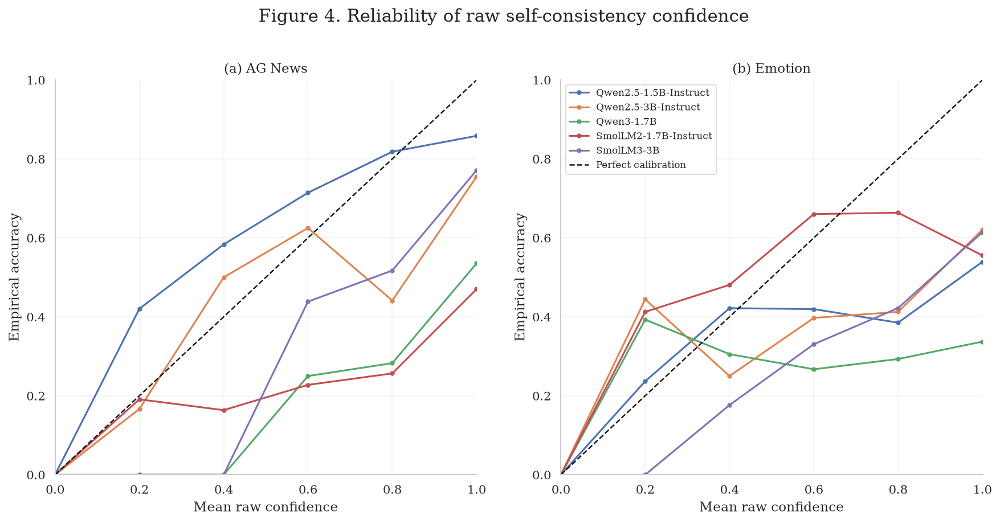

In [ ]:

required = {
    "model", "dataset", "raw_confidence", "correct"
}
if not required.issubset(oof.columns):
    raise KeyError(f"OOF file missing: {required - set(oof.columns)}")

oof["raw_confidence"] = pd.to_numeric(oof["raw_confidence"], errors="coerce")
oof["correct_num"] = (
    oof["correct"].astype(str).str.strip().str.lower()
    .isin(["true", "1", "1.0", "yes"]).astype(int)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, dataset, panel in zip(
    axes, ["ag_news", "emotion"], ["(a) AG News", "(b) Emotion"]
):
    subset = oof[oof["dataset"].astype(str).str.lower() == dataset]

    for model in sorted(subset["model"].unique()):
        d = subset[subset["model"] == model].dropna(
            subset=["raw_confidence", "correct_num"]
        )
        if len(d) < 2:
            continue

        frac_correct, mean_conf = calibration_curve(
            d["correct_num"].to_numpy(),
            d["raw_confidence"].clip(0, 1).to_numpy(),
            n_bins=10,
            strategy="uniform"
        )
        ax.plot(mean_conf, frac_correct, marker="o",
                linewidth=1.5, markersize=3, label=model)

    ax.plot([0, 1], [0, 1], "k--", linewidth=1.2,
            label="Perfect calibration")
    ax.set_title(panel)
    ax.set_xlabel("Mean raw confidence")
    ax.set_ylabel("Empirical accuracy")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)

axes[1].legend(fontsize=8, loc="best")
fig.suptitle(
    "Figure 4. Reliability of raw self-consistency confidence",
    fontsize=15, y=1.02
)
save_composite(fig, "Figure_4_Raw_Reliability")


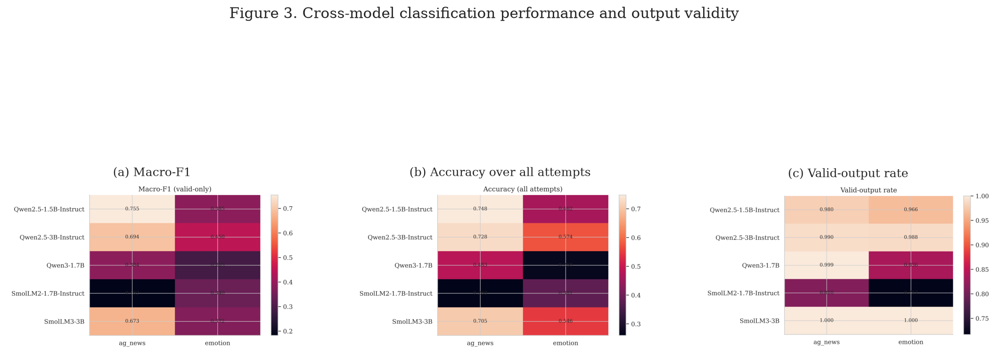

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

add_image_panel(
    axes[0], "heatmap_macro_f1.png",
    "(a) Macro-F1"
)
add_image_panel(
    axes[1], "heatmap_accuracy.png",
    "(b) Accuracy over all attempts"
)
add_image_panel(
    axes[2], "heatmap_valid_rate.png",
    "(c) Valid-output rate"
)

fig.suptitle(
    "Figure 3. Cross-model classification performance and output validity",
    fontsize=15, y=1.02
)
save_composite(fig, "Figure_3_Cross_Model_Performance")


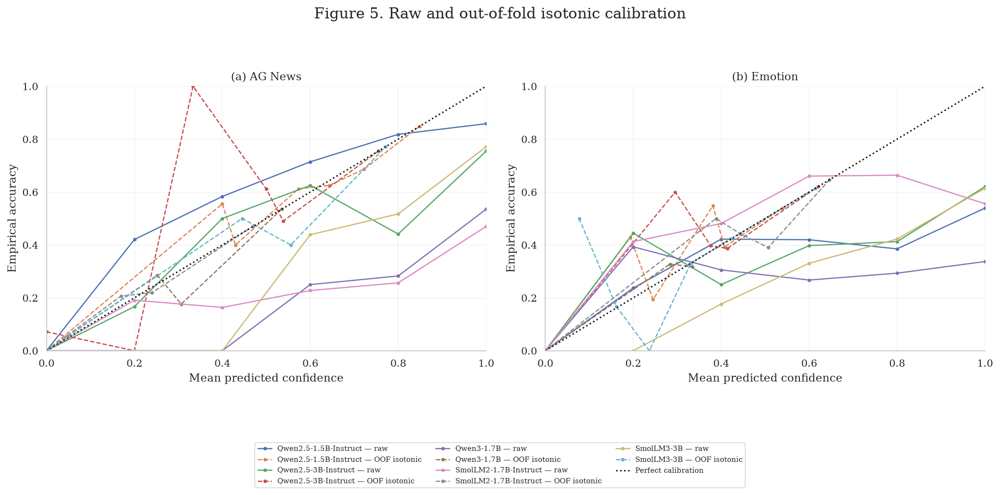

In [ ]:

required = {
    "model", "dataset", "raw_confidence",
    "oof_isotonic_confidence", "correct"
}
if not required.issubset(oof.columns):
    raise KeyError(f"OOF file missing: {required - set(oof.columns)}")

oof["oof_isotonic_confidence"] = pd.to_numeric(
    oof["oof_isotonic_confidence"], errors="coerce"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, dataset, panel in zip(
    axes, ["ag_news", "emotion"], ["(a) AG News", "(b) Emotion"]
):
    subset = oof[oof["dataset"].astype(str).str.lower() == dataset]

    for model in sorted(subset["model"].unique()):
        d = subset[subset["model"] == model].dropna(
            subset=[
                "raw_confidence", "oof_isotonic_confidence", "correct_num"
            ]
        )
        if len(d) < 2:
            continue

        for conf_col, style, label in [
            ("raw_confidence", "-", f"{model} — raw"),
            ("oof_isotonic_confidence", "--", f"{model} — OOF isotonic")
        ]:
            frac_correct, mean_conf = calibration_curve(
                d["correct_num"].to_numpy(),
                d[conf_col].clip(0, 1).to_numpy(),
                n_bins=10,
                strategy="uniform"
            )
            ax.plot(mean_conf, frac_correct, linestyle=style,
                    marker="o", markersize=2.5, linewidth=1.2,
                    label=label)

    ax.plot([0, 1], [0, 1], "k:", linewidth=1.5,
            label="Perfect calibration")
    ax.set_title(panel)
    ax.set_xlabel("Mean predicted confidence")
    ax.set_ylabel("Empirical accuracy")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)

# The legend is intentionally outside the panels to preserve plot space.
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center",
           bbox_to_anchor=(0.5, -0.10), ncol=3, fontsize=7)
fig.suptitle(
    "Figure 5. Raw and out-of-fold isotonic calibration",
    fontsize=15, y=1.02
)
fig.tight_layout(rect=[0, 0.12, 1, 0.96])
save_composite(fig, "Figure_5_Raw_vs_Calibrated_Reliability")


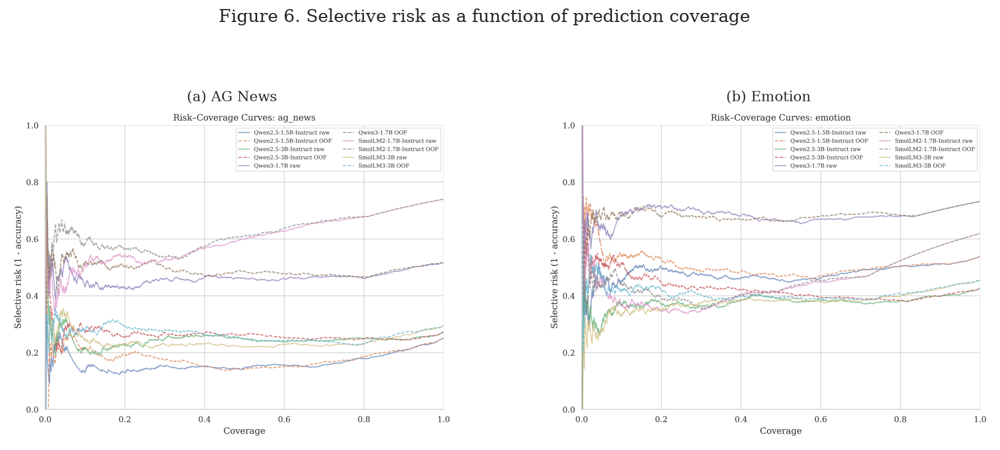

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

add_image_panel(
    axes[0], "risk_coverage_ag_news.png",
    "(a) AG News"
)
add_image_panel(
    axes[1], "risk_coverage_emotion.png",
    "(b) Emotion"
)

fig.suptitle(
    "Figure 6. Selective risk as a function of prediction coverage",
    fontsize=15, y=1.02
)
save_composite(fig, "Figure_6_Risk_Coverage")


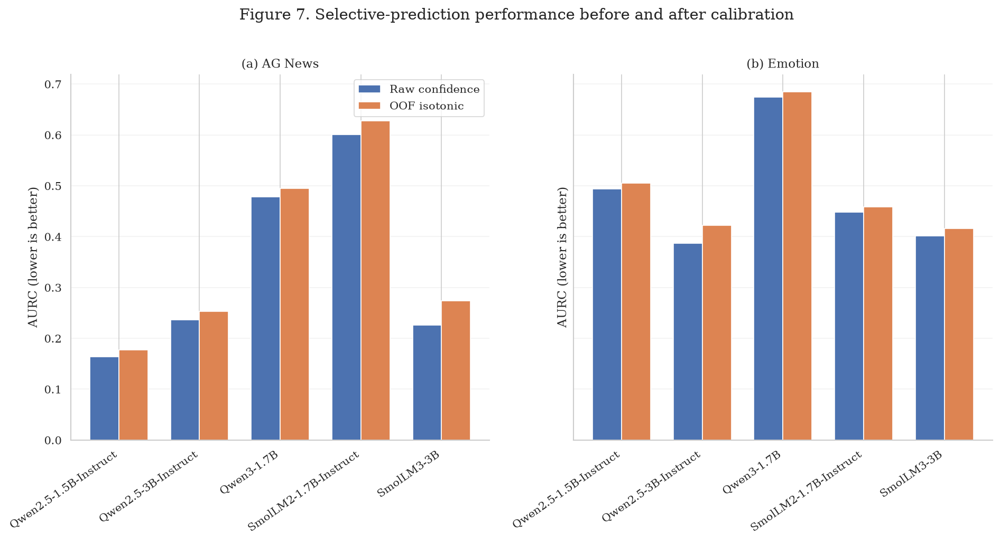

In [ ]:

required = {
    "model", "dataset", "raw_AURC", "OOF_isotonic_AURC"
}
if not required.issubset(reliability.columns):
    raise KeyError(
        f"Reliability CSV missing: {required - set(reliability.columns)}"
    )

models = sorted(reliability["model"].unique())
datasets = ["ag_news", "emotion"]

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

for ax, dataset, panel in zip(
    axes, datasets, ["(a) AG News", "(b) Emotion"]
):
    d = reliability[
        reliability["dataset"].astype(str).str.lower() == dataset
    ].copy()

    d = d.set_index("model").reindex(models).reset_index()
    x = np.arange(len(d))
    width = 0.36

    ax.bar(
        x - width/2, d["raw_AURC"], width,
        label="Raw confidence"
    )
    ax.bar(
        x + width/2, d["OOF_isotonic_AURC"], width,
        label="OOF isotonic"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(d["model"], rotation=35, ha="right")
    ax.set_title(panel)
    ax.set_ylabel("AURC (lower is better)")
    ax.grid(axis="y", alpha=0.25)

axes[0].legend()
fig.suptitle(
    "Figure 7. Selective-prediction performance before and after calibration",
    fontsize=14, y=1.02
)
save_composite(fig, "Figure_7_AURC_Comparison")


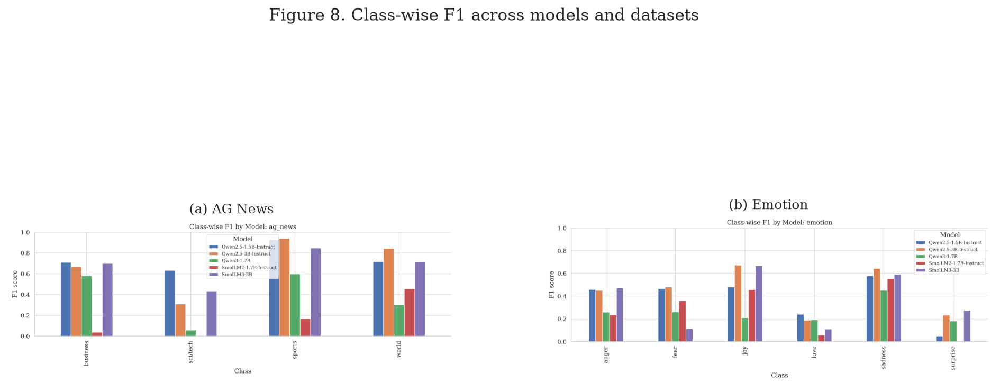

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

add_image_panel(
    axes[0], "classwise_f1_ag_news.png",
    "(a) AG News"
)
add_image_panel(
    axes[1], "classwise_f1_emotion.png",
    "(b) Emotion"
)

fig.suptitle(
    "Figure 8. Class-wise F1 across models and datasets",
    fontsize=15, y=1.02
)
save_composite(fig, "Figure_8_Classwise_F1")


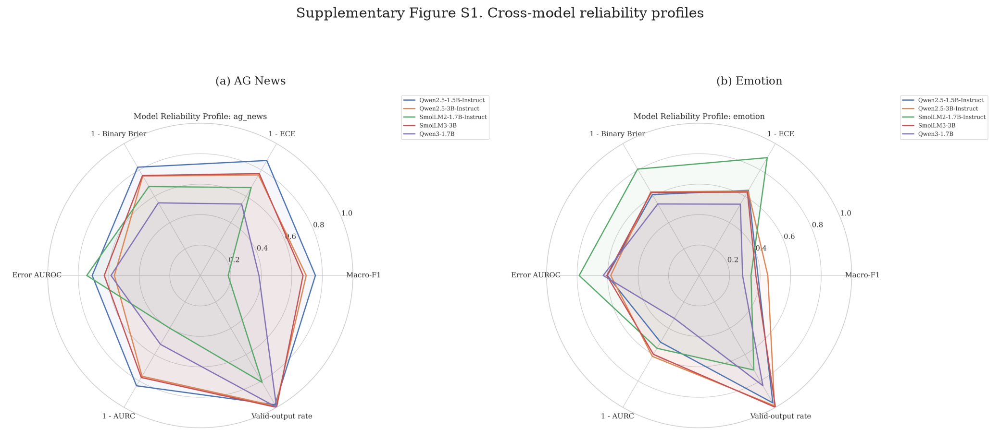

In [ ]:

import os
import matplotlib.pyplot as plt
from PIL import Image

FINALDIR = "/content/drive/MyDrive/LLM_Reliability_Experiments/Combined_Manuscript_Analysis/Final_Figures_3_to_8"
os.makedirs(FINALDIR, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, filename, title in zip(
    axes,
    ["radar_ag_news.png", "radar_emotion.png"],
    ["(a) AG News", "(b) Emotion"]
):
    path = os.path.join(FIGDIR, filename)
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Missing radar chart: {path}")
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(title)
    ax.axis("off")

fig.suptitle("Supplementary Figure S1. Cross-model reliability profiles", fontsize=14)
fig.tight_layout()
fig.savefig(os.path.join(FINALDIR, "Supplementary_Figure_S1_Radar.png"),
            dpi=600, bbox_inches="tight")
fig.savefig(os.path.join(FINALDIR, "Supplementary_Figure_S1_Radar.pdf"),
            bbox_inches="tight")
plt.show()


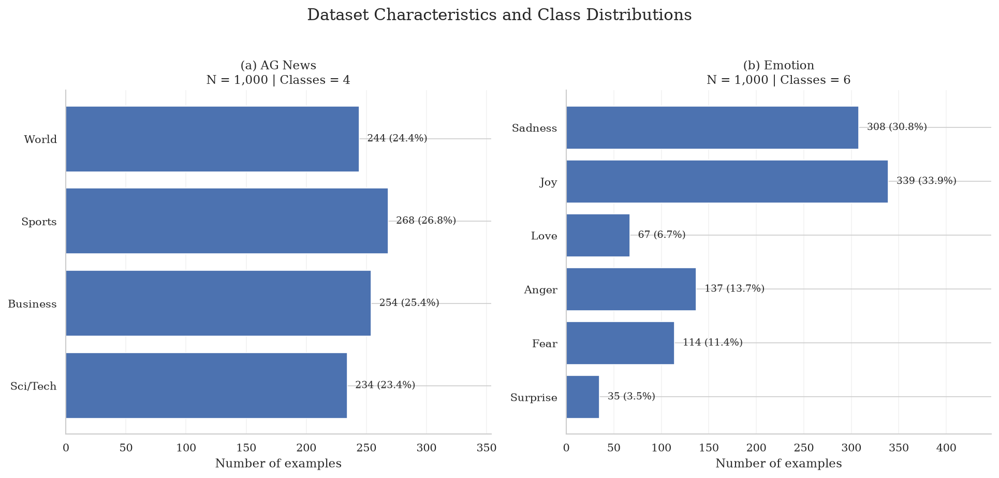

Saved: /content/drive/MyDrive/LLM_Reliability_Experiments/Combined_Manuscript_Analysis/Final_Figures_3_to_8/Figure_Dataset_Distributions.png
Saved: /content/drive/MyDrive/LLM_Reliability_Experiments/Combined_Manuscript_Analysis/Final_Figures_3_to_8/Figure_Dataset_Distributions.pdf

Class distribution counts:
dataset  class   
ag_news  Business    254
         Sci/Tech    234
         Sports      268
         World       244
emotion  Anger       137
         Fear        114
         Joy         339
         Love         67
         Sadness     308
         Surprise     35


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = "/content/drive/MyDrive/LLM_Reliability_Experiments"
ANALYSIS = os.path.join(ROOT, "Combined_Manuscript_Analysis")
OUTDIR = os.path.join(ANALYSIS, "Final_Figures_3_to_8")
os.makedirs(OUTDIR, exist_ok=True)

oof_path = os.path.join(
    ANALYSIS, "combined_oof_calibration_predictions.csv"
)
oof = pd.read_csv(oof_path)

# The experimental OOF file repeats each example for each model.
# Deduplicate by dataset and source_row so examples are counted once.
data = oof[["dataset", "source_row", "true_label"]].drop_duplicates(
    subset=["dataset", "source_row"]
).copy()

data["true_label"] = data["true_label"].astype(str).str.strip()

dataset_order = ["ag_news", "emotion"]
titles = {
    "ag_news": "(a) AG News",
    "emotion": "(b) Emotion"
}
expected_classes = {
    "ag_news": ["World", "Sports", "Business", "Sci/Tech"],
    "emotion": ["Sadness", "Joy", "Love", "Anger", "Fear", "Surprise"]
}

def canonical_label(x):
    s = str(x).strip().lower()
    aliases = {
        "world": "World",
        "sports": "Sports",
        "business": "Business",
        "sci/tech": "Sci/Tech",
        "science/technology": "Sci/Tech",
        "science and technology": "Sci/Tech",
        "sadness": "Sadness",
        "joy": "Joy",
        "love": "Love",
        "anger": "Anger",
        "fear": "Fear",
        "surprise": "Surprise"
    }
    return aliases.get(s, s.title())

data["class"] = data["true_label"].map(canonical_label)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, dataset in zip(axes, dataset_order):
    subset = data[data["dataset"].astype(str).str.lower() == dataset]
    counts = subset["class"].value_counts()

    # Keep all expected classes visible, including any class with zero samples.
    classes = expected_classes[dataset]
    counts = counts.reindex(classes, fill_value=0)
    total = int(counts.sum())
    percentages = counts / total * 100 if total else counts * 0

    y = np.arange(len(classes))
    bars = ax.barh(y, counts.values)

    ax.set_yticks(y)
    ax.set_yticklabels(classes)
    ax.invert_yaxis()
    ax.set_xlabel("Number of examples")
    ax.set_title(f"{titles[dataset]}\nN = {total:,} | Classes = {len(classes)}")
    ax.grid(axis="x", alpha=0.25)

    max_count = max(int(counts.max()), 1)
    ax.set_xlim(0, max_count * 1.32)

    for bar, count, pct in zip(bars, counts.values, percentages.values):
        ax.text(
            bar.get_width() + max_count * 0.025,
            bar.get_y() + bar.get_height() / 2,
            f"{count:,} ({pct:.1f}%)",
            va="center",
            fontsize=9
        )

fig.suptitle(
    "Dataset Characteristics and Class Distributions",
    fontsize=15, y=1.02
)
fig.tight_layout()

png_path = os.path.join(OUTDIR, "Figure_Dataset_Distributions.png")
pdf_path = os.path.join(OUTDIR, "Figure_Dataset_Distributions.pdf")

fig.savefig(png_path, dpi=600, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")
plt.show()

print("Saved:", png_path)
print("Saved:", pdf_path)
print("\nClass distribution counts:")
print(data.groupby(["dataset", "class"]).size().to_string())


In [ ]:

# ============================================================
# MODERN DATASET FINGERPRINT FIGURE — OPTION A
# Publication-ready dataset overview
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

ROOT = "/content/drive/MyDrive/LLM_Reliability_Experiments"
OUTDIR = os.path.join(
    ROOT, "Combined_Manuscript_Analysis", "Final_Figures_3_to_8"
)
os.makedirs(OUTDIR, exist_ok=True)

# Actual counts from the dataset distribution figure
datasets = {
    "AG NEWS": {
        "subtitle": "News topic classification",
        "n": 1000,
        "classes": [
            ("World", 244),
            ("Sports", 268),
            ("Business", 254),
            ("Sci/Tech", 234),
        ],
    },
    "EMOTION": {
        "subtitle": "Emotion classification",
        "n": 1000,
        "classes": [
            ("Sadness", 308),
            ("Joy", 339),
            ("Love", 67),
            ("Anger", 137),
            ("Fear", 114),
            ("Surprise", 35),
        ],
    },
}

# Restrained palette suitable for a research paper
NAVY = "#182B49"
BLUE = "#4267A9"
TEAL = "#278C87"
PALE = "#F3F6FA"
TEXT = "#263449"
MUTED = "#68778B"
WHITE = "#FFFFFF"
BORDER = "#DCE3EC"

fig = plt.figure(figsize=(15, 8.5), facecolor=WHITE)

fig.text(
    0.5, 0.955,
    "DATASET FINGERPRINTS",
    ha="center", va="center",
    fontsize=21, fontweight="bold", color=NAVY
)
fig.text(
    0.5, 0.916,
    "Two classification benchmarks · 2,000 experimental examples",
    ha="center", va="center",
    fontsize=11, color=MUTED
)

panel_positions = [
    (0.045, 0.105, 0.445, 0.76),
    (0.510, 0.105, 0.445, 0.76),
]

# Distinct but coordinated tones
class_colors = {
    "World": "#4267A9",
    "Sports": "#278C87",
    "Business": "#7B6CB2",
    "Sci/Tech": "#D19A42",
    "Sadness": "#4267A9",
    "Joy": "#278C87",
    "Love": "#D19A42",
    "Anger": "#B96B78",
    "Fear": "#7B6CB2",
    "Surprise": "#6096BA",
}

for (dataset_name, info), (px, py, pw, ph) in zip(
    datasets.items(), panel_positions
):
    # Main panel card
    card = FancyBboxPatch(
        (px, py), pw, ph,
        boxstyle="round,pad=0.012,rounding_size=0.022",
        transform=fig.transFigure,
        facecolor=WHITE, edgecolor=BORDER,
        linewidth=1.3, zorder=0
    )
    fig.patches.append(card)

    # Header
    fig.text(
        px + 0.028, py + ph - 0.060,
        dataset_name,
        fontsize=16, fontweight="bold",
        color=NAVY, ha="left", va="center"
    )
    fig.text(
        px + 0.028, py + ph - 0.095,
        info["subtitle"],
        fontsize=10, color=MUTED,
        ha="left", va="center"
    )

    # Key statistics
    stat_y = py + ph - 0.225
    stat_h = 0.095
    stat_gap = 0.012
    stat_w = (pw - 0.056 - stat_gap) / 2

    for j, (value, label) in enumerate([
        (f'{info["n"]:,}', "EXAMPLES"),
        (str(len(info["classes"])), "CLASSES"),
    ]):
        sx = px + 0.028 + j * (stat_w + stat_gap)

        stat_card = FancyBboxPatch(
            (sx, stat_y), stat_w, stat_h,
            boxstyle="round,pad=0.008,rounding_size=0.012",
            transform=fig.transFigure,
            facecolor=PALE, edgecolor="none",
            zorder=1
        )
        fig.patches.append(stat_card)

        fig.text(
            sx + 0.015, stat_y + 0.058,
            value, fontsize=21, fontweight="bold",
            color=BLUE if j == 0 else TEAL,
            ha="left", va="center"
        )
        fig.text(
            sx + 0.015, stat_y + 0.024,
            label, fontsize=8, fontweight="bold",
            color=MUTED, ha="left", va="center"
        )

    # Distribution heading
    dist_y = stat_y - 0.065
    fig.text(
        px + 0.028, dist_y,
        "CLASS DISTRIBUTION",
        fontsize=9, fontweight="bold",
        color=NAVY, ha="left", va="center"
    )

    # Proportional tiles: width is proportional to class frequency.
    tile_x = px + 0.028
    tile_y = dist_y - 0.085
    tile_w = pw - 0.056
    tile_h = 0.052
    gap = 0.004
    available_w = tile_w - gap * (len(info["classes"]) - 1)
    total = sum(count for _, count in info["classes"])

    for cls, count in info["classes"]:
        width = available_w * count / total
        rect = FancyBboxPatch(
            (tile_x, tile_y), width, tile_h,
            boxstyle="round,pad=0.002,rounding_size=0.008",
            transform=fig.transFigure,
            facecolor=class_colors[cls],
            edgecolor=WHITE, linewidth=0.7,
            zorder=2
        )
        fig.patches.append(rect)

        # Label only if the tile has enough room.
        if width > 0.045:
            fig.text(
                tile_x + width / 2, tile_y + tile_h / 2,
                f"{count / total:.0%}",
                fontsize=8, fontweight="bold",
                color=WHITE, ha="center", va="center"
            )
        tile_x += width + gap

    # Class detail rows
    rows_top = tile_y - 0.045
    row_gap = 0.050 if len(info["classes"]) <= 4 else 0.042

    for i, (cls, count) in enumerate(info["classes"]):
        ry = rows_top - i * row_gap
        pct = count / total * 100

        # Colour marker
        marker = FancyBboxPatch(
            (px + 0.030, ry - 0.008), 0.012, 0.016,
            boxstyle="round,pad=0.001,rounding_size=0.003",
            transform=fig.transFigure,
            facecolor=class_colors[cls], edgecolor="none",
            zorder=2
        )
        fig.patches.append(marker)

        fig.text(
            px + 0.052, ry,
            cls, fontsize=10, color=TEXT,
            ha="left", va="center"
        )

        # Slim proportional progress track
        track_x = px + pw * 0.51
        track_w = pw * 0.22
        track_h = 0.012

        fig.patches.append(Rectangle(
            (track_x, ry - track_h / 2),
            track_w, track_h,
            transform=fig.transFigure,
            facecolor=PALE, edgecolor="none", zorder=1
        ))
        fig.patches.append(Rectangle(
            (track_x, ry - track_h / 2),
            track_w * count / max(c for _, c in info["classes"]),
            track_h,
            transform=fig.transFigure,
            facecolor=class_colors[cls], edgecolor="none", zorder=2
        ))

        fig.text(
            px + pw - 0.028, ry,
            f"{count:,}  ·  {pct:.1f}%",
            fontsize=9, color=TEXT,
            ha="right", va="center"
        )

# Footer
fig.text(
    0.5, 0.045,
    "Class tile area is proportional to the number of examples.",
    ha="center", va="center", fontsize=9, color=MUTED
)

png_path = os.path.join(OUTDIR, "Figure_Dataset_Fingerprints.png")
pdf_path = os.path.join(OUTDIR, "Figure_Dataset_Fingerprints.pdf")

fig.savefig(png_path, dpi=600, bbox_inches="tight", facecolor=WHITE)
fig.savefig(pdf_path, bbox_inches="tight", facecolor=WHITE)
plt.show()

print("Saved PNG:", png_path)
print("Saved PDF:", pdf_path)


<Figure size 2250x1275 with 0 Axes>

Saved PNG: /content/drive/MyDrive/LLM_Reliability_Experiments/Combined_Manuscript_Analysis/Final_Figures_3_to_8/Figure_Dataset_Fingerprints.png
Saved PDF: /content/drive/MyDrive/LLM_Reliability_Experiments/Combined_Manuscript_Analysis/Final_Figures_3_to_8/Figure_Dataset_Fingerprints.pdf


In [ ]:

from google.colab import drive, files
import os
import zipfile

drive.mount("/content/drive", force_remount=False)

ROOT = "/content/drive/MyDrive/LLM_Reliability_Experiments"
ANALYSIS = os.path.join(ROOT, "Combined_Manuscript_Analysis")
FINALDIR = os.path.join(ANALYSIS, "Final_Figures_3_to_8")

# Figure 2: Dataset fingerprint
# Figures 3–8: Composite Results figures
figure_files = [
    "Figure_Dataset_Fingerprints.png",
    "Figure_Dataset_Fingerprints.pdf",

    "Figure_3_Cross_Model_Performance.png",
    "Figure_3_Cross_Model_Performance.pdf",

    "Figure_4_Raw_Reliability.png",
    "Figure_4_Raw_Reliability.pdf",

    "Figure_5_Raw_vs_Calibrated_Reliability.png",
    "Figure_5_Raw_vs_Calibrated_Reliability.pdf",

    "Figure_6_Risk_Coverage.png",
    "Figure_6_Risk_Coverage.pdf",

    "Figure_7_AURC_Comparison.png",
    "Figure_7_AURC_Comparison.pdf",

    "Figure_8_Classwise_F1.png",
    "Figure_8_Classwise_F1.pdf",
]

# Include radar charts as an additional supplementary visual if available.
radar_dir = os.path.join(ANALYSIS, "Publication_Figures_All")
optional_radar = [
    (radar_dir, "radar_ag_news.png"),
    (radar_dir, "radar_emotion.png"),
]

zip_path = os.path.join(ANALYSIS, "Final_Figures_2_to_8.zip")
missing = []
included = []

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in figure_files:
        path = os.path.join(FINALDIR, filename)
        if os.path.isfile(path):
            z.write(path, arcname=filename)
            included.append(filename)
        else:
            missing.append(filename)

    for folder, filename in optional_radar:
        path = os.path.join(folder, filename)
        if os.path.isfile(path):
            z.write(path, arcname="Supplementary/" + filename)
            included.append("Supplementary/" + filename)

print("Included files:", len(included))
for name in included:
    print(" +", name)

if missing:
    print("\nMissing files (run the corresponding figure cell first):")
    for name in missing:
        print(" -", name)

if not included:
    raise FileNotFoundError("No figure files were found. Check FINALDIR.")

print("\nZIP created:", zip_path)
files.download(zip_path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Included files: 16
 + Figure_Dataset_Fingerprints.png
 + Figure_Dataset_Fingerprints.pdf
 + Figure_3_Cross_Model_Performance.png
 + Figure_3_Cross_Model_Performance.pdf
 + Figure_4_Raw_Reliability.png
 + Figure_4_Raw_Reliability.pdf
 + Figure_5_Raw_vs_Calibrated_Reliability.png
 + Figure_5_Raw_vs_Calibrated_Reliability.pdf
 + Figure_6_Risk_Coverage.png
 + Figure_6_Risk_Coverage.pdf
 + Figure_7_AURC_Comparison.png
 + Figure_7_AURC_Comparison.pdf
 + Figure_8_Classwise_F1.png
 + Figure_8_Classwise_F1.pdf
 + Supplementary/radar_ag_news.png
 + Supplementary/radar_emotion.png

ZIP created: /content/drive/MyDrive/LLM_Reliability_Experiments/Combined_Manuscript_Analysis/Final_Figures_2_to_8.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
import os
import json

root = Path("/content/drive/MyDrive")

# Files that could contain predictions, experiment results,
# model outputs, figures, logs, or saved notebooks.
extensions = {
    ".csv", ".json", ".jsonl", ".xlsx",
    ".parquet", ".pkl", ".joblib",
    ".npy", ".npz", ".txt", ".log",
    ".png", ".jpg", ".pdf", ".zip",
    ".ipynb", ".pt", ".safetensors"
}

keywords = (
    "qwen", "smollm", "emotion", "ag_news",
    "agnews", "calibrat", "confidence",
    "prediction", "result", "metric",
    "aurc", "auroc", "brier", "ece",
    "experiment", "output", "log"
)

matches = []
notebook_outputs = []

for folder, dirs, filenames in os.walk(root):
    # Avoid wasteful scans of hidden/system folders.
    dirs[:] = [
        d for d in dirs
        if not d.startswith(".")
        and d not in {"node_modules", "__pycache__"}
    ]

    for name in filenames:
        path = Path(folder) / name
        ext = path.suffix.lower()

        if ext not in extensions:
            continue

        if any(k in name.lower() for k in keywords):
            size_mb = path.stat().st_size / (1024 * 1024)
            matches.append((str(path), round(size_mb, 2)))

        # Check whether saved notebooks contain cell outputs.
        if ext == ".ipynb":
            try:
                nb = json.loads(path.read_text(encoding="utf-8"))
                output_cells = sum(
                    bool(cell.get("outputs"))
                    for cell in nb.get("cells", [])
                )
                if output_cells:
                    notebook_outputs.append(
                        (str(path), output_cells)
                    )
            except Exception:
                pass

print("\n=== MATCHING RESULT / ARTIFACT FILES ===")
for path, size in sorted(matches):
    print(f"{size:8.2f} MB | {path}")

print("\n=== NOTEBOOKS WITH SAVED CELL OUTPUTS ===")
for path, count in sorted(notebook_outputs):
    print(f"{count:4} output cells | {path}")

print("\nScan complete. No models were loaded or run.")


=== MATCHING RESULT / ARTIFACT FILES ===
  628.52 MB | /content/drive/MyDrive/2012-2013-data-with-predictions-4-final.csv.zip
    5.41 MB | /content/drive/MyDrive/Colab Notebooks/Reliability_Aware_MultiModel_Experiments.ipynb
    0.44 MB | /content/drive/MyDrive/Colab Notebooks/geo-emotions.ipynb
    0.07 MB | /content/drive/MyDrive/Colab Notebooks/logistic regression.ipynb
    0.62 MB | /content/drive/MyDrive/LLM_Reliability_Experiments/Baseline_Archive_Qwen2.5-1.5B/ag_news_calibration_predictions.csv
    0.00 MB | /content/drive/MyDrive/LLM_Reliability_Experiments/Baseline_Archive_Qwen2.5-1.5B/ag_news_classification_report.csv
    0.11 MB | /content/drive/MyDrive/LLM_Reliability_Experiments/Baseline_Archive_Qwen2.5-1.5B/ag_news_confusion_matrix.png
    0.61 MB | /content/drive/MyDrive/LLM_Reliability_Experiments/Baseline_Archive_Qwen2.5-1.5B/ag_news_predictions.csv
    0.61 MB | /content/drive/MyDrive/LLM_Reliability_Experiments/Baseline_Archive_Qwen2.5-1.5B/ag_news_predictions_chec

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import pandas as pd

root = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")

files = [
    root / "all_model_predictions.csv",
    root / "Baseline_Archive_Qwen2.5-1.5B" / "all_predictions.csv",
    root / "Combined_Manuscript_Analysis" /
          "combined_oof_calibration_predictions.csv",
    root / "Qwen2.5-3B-Instruct" / "ag_news_predictions.csv",
    root / "Qwen2.5-3B-Instruct" / "emotion_predictions.csv",
]

generation_terms = (
    "generation", "sample_", "response_", "completion",
    "output_", "gen_", "sampled", "all_outputs"
)

for path in files:
    print("\n" + "=" * 80)
    print("FILE:", path.name)

    if not path.exists():
        print("File not found at this path.")
        continue

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    possible_generation_columns = [
        col for col in df.columns
        if any(term in col.lower() for term in generation_terms)
    ]
    print("Possible generation columns:", possible_generation_columns)

    # Display only a few rows, shortening long text fields.
    preview = df.head(2).copy()

    for col in preview.columns:
        preview[col] = preview[col].map(
            lambda value: (
                str(value)[:100] + "..."
                if pd.notna(value) and len(str(value)) > 100
                else value
            )
        )

    display(preview)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

FILE: all_model_predictions.csv
Shape: (600, 17)
Columns: ['model', 'dataset', 'example_id', 'text', 'true_id', 'true_label', 'raw_generations', 'parsed_generations', 'valid_generations', 'invalid_generations', 'final_prediction', 'agreement', 'uncertainty', 'correct', 'valid_prediction', 'batch_inference_seconds', 'seconds_per_example_in_batch']
Possible generation columns: ['raw_generations', 'parsed_generations', 'valid_generations', 'invalid_generations']


,model,dataset,example_id,text,true_id,true_label,raw_generations,parsed_generations,valid_generations,invalid_generations,final_prediction,agreement,uncertainty,correct,valid_prediction,batch_inference_seconds,seconds_per_example_in_batch
0,Qwen/Qwen2.5-1.5B-Instruct,ag_news,0,Milosevic #39;s Lawyers to Appeal Own Appointm...,0,World,"[""World"", ""World"", ""World""]","[""World"", ""World"", ""World""]",3,0,World,1.0,0.0,True,True,2.668649,0.667162
1,Qwen/Qwen2.5-1.5B-Instruct,ag_news,1,India will never become an international liabi...,0,World,"[""World"", ""World"", ""World""]","[""World"", ""World"", ""World""]",3,0,World,1.0,0.0,True,True,2.668649,0.667162



FILE: all_predictions.csv
Shape: (2000, 14)
Columns: ['dataset', 'model', 'index', 'text', 'true_label', 'true_id', 'prediction', 'prediction_id', 'confidence', 'valid_generations', 'invalid_generations', 'valid_prediction', 'generations', 'parsed_generations']
Possible generation columns: ['valid_generations', 'invalid_generations', 'generations', 'parsed_generations']


,dataset,model,index,text,true_label,true_id,prediction,prediction_id,confidence,valid_generations,invalid_generations,valid_prediction,generations,parsed_generations
0,AG News,Qwen/Qwen2.5-1.5B-Instruct,0,Milosevic #39;s Lawyers to Appeal Own Appointm...,World,0,Business,2,0.4,2,3,True,"["" Law/Politics\n\nWorld\nBusiness\nSports\n"",...","[""Business"", null, null, null, ""Business""]"
1,AG News,Qwen/Qwen2.5-1.5B-Instruct,1,India will never become an international liabi...,World,0,Business,2,0.8,4,1,True,"["" Business. \n\nNote: This is a hypothetical ...","[""Business"", ""Business"", null, ""Business"", ""Bu..."



FILE: combined_oof_calibration_predictions.csv
Shape: (10000, 9)
Columns: ['model', 'dataset', 'source_row', 'true_label', 'prediction', 'valid_prediction', 'raw_confidence', 'correct', 'oof_isotonic_confidence']
Possible generation columns: []


,model,dataset,source_row,true_label,prediction,valid_prediction,raw_confidence,correct,oof_isotonic_confidence
0,Qwen2.5-1.5B-Instruct,ag_news,0,World,Business,True,0.4,0,0.612069
1,Qwen2.5-1.5B-Instruct,ag_news,1,World,Business,True,0.8,0,0.817460



FILE: ag_news_predictions.csv
Shape: (1000, 14)
Columns: ['dataset', 'model', 'index', 'text', 'true_label', 'true_id', 'prediction', 'prediction_id', 'confidence', 'valid_generations', 'invalid_generations', 'valid_prediction', 'generations', 'parsed_generations']
Possible generation columns: ['valid_generations', 'invalid_generations', 'generations', 'parsed_generations']


,dataset,model,index,text,true_label,true_id,prediction,prediction_id,confidence,valid_generations,invalid_generations,valid_prediction,generations,parsed_generations
0,AG News,Qwen/Qwen2.5-3B-Instruct,0,Milosevic #39;s Lawyers to Appeal Own Appointm...,World,0,World,0,1.0,5,0,True,"["" World\nThe text discusses a legal action re...","[""World"", ""World"", ""World"", ""World"", ""World""]"
1,AG News,Qwen/Qwen2.5-3B-Instruct,1,India will never become an international liabi...,World,0,Business,2,1.0,5,0,True,"["" Business\nThe text discusses political stat...","[""Business"", ""Business"", ""Business"", ""Business..."



FILE: emotion_predictions.csv
Shape: (1000, 14)
Columns: ['dataset', 'model', 'index', 'text', 'true_label', 'true_id', 'prediction', 'prediction_id', 'confidence', 'valid_generations', 'invalid_generations', 'valid_prediction', 'generations', 'parsed_generations']
Possible generation columns: ['valid_generations', 'invalid_generations', 'generations', 'parsed_generations']


,dataset,model,index,text,true_label,true_id,prediction,prediction_id,confidence,valid_generations,invalid_generations,valid_prediction,generations,parsed_generations
0,Emotion,Qwen/Qwen2.5-3B-Instruct,0,i feel is an acceptable and significant modern...,joy,1,joy,1,1.0,5,0,True,"["" joy\n\nThe text conveys a sense of approval...","[""joy"", ""joy"", ""joy"", ""joy"", ""joy""]"
1,Emotion,Qwen/Qwen2.5-3B-Instruct,1,i think or feel but like this person i am stil...,surprise,5,joy,1,1.0,5,0,True,"["" joy\nThe provided text expresses a sense of...","[""joy"", ""joy"", ""joy"", ""joy"", ""joy""]"


In [ ]:
from pathlib import Path
from collections import Counter
import pandas as pd
import json

root = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")

files = sorted(
    list(root.rglob("ag_news_predictions.csv")) +
    list(root.rglob("emotion_predictions.csv"))
)

for path in files:
    df = pd.read_csv(path)

    gen_col = next(
        (c for c in ["parsed_generations", "generations"]
         if c in df.columns),
        None
    )

    generation_counts = Counter()

    if gen_col:
        for value in df[gen_col].dropna():
            try:
                parsed = json.loads(value) if isinstance(value, str) else value
                if isinstance(parsed, list):
                    generation_counts[len(parsed)] += 1
            except (json.JSONDecodeError, TypeError):
                generation_counts["unparsed"] += 1

    model_values = (
        df["model"].dropna().unique().tolist()
        if "model" in df.columns else []
    )

    dataset_values = (
        df["dataset"].dropna().unique().tolist()
        if "dataset" in df.columns else []
    )

    print("\nFILE:", path.relative_to(root))
    print("Rows:", len(df))
    print("Models:", model_values)
    print("Datasets:", dataset_values)
    print("Generation-count distribution:", dict(generation_counts))


FILE: Baseline_Archive_Qwen2.5-1.5B/ag_news_predictions.csv
Rows: 1000
Models: ['Qwen/Qwen2.5-1.5B-Instruct']
Datasets: ['AG News']
Generation-count distribution: {5: 1000}

FILE: Baseline_Archive_Qwen2.5-1.5B/emotion_predictions.csv
Rows: 1000
Models: ['Qwen/Qwen2.5-1.5B-Instruct']
Datasets: ['Emotion']
Generation-count distribution: {5: 1000}

FILE: Qwen2.5-1.5B-Baseline/ag_news_predictions.csv
Rows: 1000
Models: ['Qwen/Qwen2.5-1.5B-Instruct']
Datasets: ['AG News']
Generation-count distribution: {5: 1000}

FILE: Qwen2.5-1.5B-Baseline/emotion_predictions.csv
Rows: 1000
Models: ['Qwen/Qwen2.5-1.5B-Instruct']
Datasets: ['Emotion']
Generation-count distribution: {5: 1000}

FILE: Qwen2.5-3B-Instruct/ag_news_predictions.csv
Rows: 1000
Models: ['Qwen/Qwen2.5-3B-Instruct']
Datasets: ['AG News']
Generation-count distribution: {5: 1000}

FILE: Qwen2.5-3B-Instruct/emotion_predictions.csv
Rows: 1000
Models: ['Qwen/Qwen2.5-3B-Instruct']
Datasets: ['Emotion']
Generation-count distribution: {5: 10

In [ ]:
# ============================================================
# LLM RELIABILITY: RAW vs SIGMOID vs ISOTONIC CALIBRATION
# Uses saved predictions only. NO model loading or inference.
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

from scipy.optimize import minimize
from scipy.special import expit

from sklearn.model_selection import StratifiedKFold
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# ------------------------------------------------------------
# 1. File locations
# ------------------------------------------------------------

ROOT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")

MODEL_DIRS = {
    "Qwen2.5-1.5B-Instruct": "Baseline_Archive_Qwen2.5-1.5B",
    "Qwen2.5-3B-Instruct": "Qwen2.5-3B-Instruct",
    "SmolLM2-1.7B-Instruct": "SmolLM2-1.7B-Instruct",
    "SmolLM3-3B": "SmolLM3-3B",
    "Qwen3-1.7B": "Qwen3-1.7B",
}

DATASETS = {
    "ag_news": "ag_news_predictions.csv",
    "emotion": "emotion_predictions.csv",
}

OUT = ROOT / "Calibration_Method_Comparison_OOF"
OUT.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 123
N_SPLITS = 5
N_BINS = 10

# ------------------------------------------------------------
# 2. Helper functions
# ------------------------------------------------------------

def as_bool(value):
    if pd.isna(value):
        return False
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    return str(value).strip().lower() in {"true", "1", "yes"}


def load_predictions(path, model_name, dataset_name):
    if not path.exists():
        raise FileNotFoundError(f"Missing prediction file: {path}")

    df = pd.read_csv(path)

    pred_col = next(
        (c for c in ["prediction", "final_prediction"]
         if c in df.columns), None
    )
    score_col = next(
        (c for c in ["confidence", "agreement", "raw_confidence"]
         if c in df.columns), None
    )

    required = {"true_label"}
    if not required.issubset(df.columns):
        raise ValueError(f"{path.name} lacks true_label.")

    if pred_col is None or score_col is None:
        raise ValueError(
            f"{path.name}: prediction/confidence column not found. "
            f"Available columns: {df.columns.tolist()}"
        )

    truth = df["true_label"].fillna("").astype(str).str.strip()
    pred = df[pred_col].fillna("").astype(str).str.strip()

    truth_norm = truth.str.casefold()
    pred_norm = pred.str.casefold()

    if "valid_prediction" in df.columns:
        valid = df["valid_prediction"].map(as_bool).to_numpy()
    else:
        valid = (
            pred_norm.ne("").to_numpy()
            & ~pred_norm.isin(["nan", "none", "null"]).to_numpy()
        )

    confidence = pd.to_numeric(
        df[score_col], errors="coerce"
    ).to_numpy(dtype=float)

    # Preserve invalid predictions as incorrect attempts.
    correct = (
        (truth_norm.to_numpy() == pred_norm.to_numpy())
        & valid
    ).astype(int)

    keep = (
        truth.ne("").to_numpy()
        & np.isfinite(confidence)
    )

    df = df.loc[keep].copy().reset_index(drop=True)

    confidence = np.clip(confidence[keep], 0.0, 1.0)
    correct = correct[keep]
    valid = valid[keep]

    if len(df) == 0:
        raise ValueError(f"No usable rows in {path}")

    if len(np.unique(correct)) < 2 or np.min(
        np.bincount(correct, minlength=2)
    ) < N_SPLITS:
        raise ValueError(
            f"Not enough examples of both correctness classes in {path}"
        )

    return {
        "model": model_name,
        "dataset": dataset_name,
        "df": df,
        "confidence": confidence,
        "correct": correct,
        "valid": valid,
        "prediction": pred.loc[keep].to_numpy(),
        "true_label": truth.loc[keep].to_numpy(),
    }


def fit_sigmoid_predict(x_train, y_train, x_test):
    """Fit a non-decreasing logistic calibration mapping."""

    prevalence = np.clip(np.mean(y_train), 1e-5, 1 - 1e-5)
    initial_intercept = np.log(prevalence / (1 - prevalence))

    def objective(params):
        slope, intercept = params
        logits = np.clip(
            slope * x_train + intercept, -50, 50
        )
        nll = np.mean(
            np.logaddexp(0, logits) - y_train * logits
        )
        return nll + 1e-8 * slope**2

    result = minimize(
        objective,
        x0=np.array([1.0, initial_intercept]),
        method="L-BFGS-B",
        bounds=[(0, 50), (-30, 30)],
    )

    if not np.all(np.isfinite(result.x)):
        return np.full(len(x_test), prevalence)

    slope, intercept = result.x
    return expit(np.clip(
        slope * x_test + intercept, -50, 50
    ))


def calculate_ece(y, p, bins=10):
    """Equal-width, fixed-bin expected calibration error."""

    y = np.asarray(y, dtype=float)
    p = np.clip(np.asarray(p, dtype=float), 0, 1)

    bin_ids = np.minimum((p * bins).astype(int), bins - 1)
    ece = 0.0

    for b in range(bins):
        mask = bin_ids == b
        if mask.any():
            ece += mask.mean() * abs(
                y[mask].mean() - p[mask].mean()
            )

    return float(ece)


def tie_aware_aurc(y_correct, confidence):
    """
    Expected discrete AURC under random ordering within tied
    confidence groups. Lower is better.
    """

    errors = 1 - np.asarray(y_correct, dtype=int)
    scores = np.asarray(confidence, dtype=float)

    n_higher = 0
    errors_higher = 0.0
    risks = []

    for score in np.sort(np.unique(scores))[::-1]:
        group_errors = errors[scores == score]
        group_size = len(group_errors)
        group_error_total = int(group_errors.sum())

        for j in range(1, group_size + 1):
            expected_errors = (
                errors_higher
                + j * group_error_total / group_size
            )
            risks.append(expected_errors / (n_higher + j))

        n_higher += group_size
        errors_higher += group_error_total

    return float(np.mean(risks))


def calculate_metrics(y_correct, confidence, valid):
    y_correct = np.asarray(y_correct, dtype=int)
    confidence = np.clip(
        np.asarray(confidence, dtype=float), 0, 1
    )
    errors = 1 - y_correct
    uncertainty = 1 - confidence

    try:
        error_auroc = roc_auc_score(errors, uncertainty)
        error_auprc = average_precision_score(errors, uncertainty)
    except ValueError:
        error_auroc = np.nan
        error_auprc = np.nan

    unique_scores, counts = np.unique(
        confidence, return_counts=True
    )

    n = len(confidence)
    tied_pairs = np.sum(counts * (counts - 1) / 2)
    total_pairs = n * (n - 1) / 2 if n > 1 else 1

    return {
        "n": n,
        "accuracy_all_attempt": float(y_correct.mean()),
        "valid_output_rate": float(np.mean(valid)),
        "ECE": calculate_ece(y_correct, confidence, N_BINS),
        "Brier": float(np.mean((confidence - y_correct) ** 2)),
        "Error_AUROC": float(error_auroc),
        "Error_AUPRC": float(error_auprc),
        "AURC_tie_aware": tie_aware_aurc(
            y_correct, confidence
        ),
        "unique_confidence_values": len(unique_scores),
        "tied_pair_fraction": float(tied_pairs / total_pairs),
    }


# ------------------------------------------------------------
# 3. Load saved predictions and perform five-fold evaluation
# ------------------------------------------------------------

fold_results = []
prediction_results = []
audit_results = []

for model_name, folder in MODEL_DIRS.items():
    for dataset_name, filename in DATASETS.items():

        path = ROOT / folder / filename
        data = load_predictions(path, model_name, dataset_name)

        df = data["df"]
        x = data["confidence"]
        y = data["correct"]
        valid = data["valid"]

        split = StratifiedKFold(
            n_splits=N_SPLITS,
            shuffle=True,
            random_state=RANDOM_STATE,
        )

        print(
            f"Processing {model_name} | {dataset_name} "
            f"| {len(df)} rows"
        )

        for fold, (train_idx, test_idx) in enumerate(
            split.split(x.reshape(-1, 1), y), start=1
        ):
            x_train, x_test = x[train_idx], x[test_idx]
            y_train, y_test = y[train_idx], y[test_idx]

            # Raw agreement baseline.
            raw_test = x_test.copy()

            # Sigmoid / Platt-style calibration.
            sigmoid_test = fit_sigmoid_predict(
                x_train, y_train, x_test
            )

            # Isotonic calibration.
            isotonic = IsotonicRegression(
                y_min=0.0,
                y_max=1.0,
                out_of_bounds="clip",
            )
            isotonic.fit(x_train, y_train)
            isotonic_test = isotonic.predict(x_test)

            method_scores = {
                "Raw": raw_test,
                "Sigmoid": sigmoid_test,
                "Isotonic": isotonic_test,
            }

            for method, scores in method_scores.items():
                metrics = calculate_metrics(
                    y_test, scores, valid[test_idx]
                )

                fold_results.append({
                    "model": model_name,
                    "dataset": dataset_name,
                    "fold": fold,
                    "method": method,
                    **metrics,
                })

            for j, idx in enumerate(test_idx):
                prediction_results.append({
                    "model": model_name,
                    "dataset": dataset_name,
                    "fold": fold,
                    "row_index": int(idx),
                    "true_label": data["true_label"][idx],
                    "prediction": data["prediction"][idx],
                    "correct": int(y[idx]),
                    "valid_prediction": bool(valid[idx]),
                    "raw_confidence": float(raw_test[j]),
                    "sigmoid_confidence": float(sigmoid_test[j]),
                    "isotonic_confidence": float(isotonic_test[j]),
                })

        audit_results.append({
            "model": model_name,
            "dataset": dataset_name,
            "rows_loaded": len(df),
            "valid_predictions": int(valid.sum()),
            "invalid_predictions": int((~valid).sum()),
            "unique_raw_confidence_values": int(len(np.unique(x))),
            "generation_column_present": any(
                c in df.columns
                for c in ["generations", "parsed_generations"]
            ),
        })


# ------------------------------------------------------------
# 4. Summarise metrics across folds
# ------------------------------------------------------------

fold_df = pd.DataFrame(fold_results)
pred_df = pd.DataFrame(prediction_results)
audit_df = pd.DataFrame(audit_results)

metric_cols = [
    "accuracy_all_attempt",
    "valid_output_rate",
    "ECE",
    "Brier",
    "Error_AUROC",
    "Error_AUPRC",
    "AURC_tie_aware",
    "unique_confidence_values",
    "tied_pair_fraction",
]

summary = (
    fold_df
    .groupby(["model", "dataset", "method"])[metric_cols]
    .agg(["mean", "std"])
)

summary.columns = [
    f"{metric}_{stat}" for metric, stat in summary.columns
]
summary = summary.reset_index()

fold_path = OUT / "fold_level_metrics.csv"
summary_path = OUT / "summary_metrics.csv"
pred_path = OUT / "oof_calibrated_predictions.csv"
audit_path = OUT / "input_file_audit.csv"

fold_df.to_csv(fold_path, index=False)
summary.to_csv(summary_path, index=False)
pred_df.to_csv(pred_path, index=False)
audit_df.to_csv(audit_path, index=False)

print("\n" + "=" * 70)
print("EXPERIMENT FINISHED — NO LLM INFERENCE WAS RUN")
print("=" * 70)

print("\nInput audit:")
display(audit_df)

print("\nMetrics summary (mean and standard deviation across 5 folds):")
display(summary.round(4))

print("\nFiles saved in:", OUT)
print(" -", fold_path.name)
print(" -", summary_path.name)
print(" -", pred_path.name)
print(" -", audit_path.name)

Processing Qwen2.5-1.5B-Instruct | ag_news | 1000 rows
Processing Qwen2.5-1.5B-Instruct | emotion | 1000 rows
Processing Qwen2.5-3B-Instruct | ag_news | 1000 rows
Processing Qwen2.5-3B-Instruct | emotion | 1000 rows
Processing SmolLM2-1.7B-Instruct | ag_news | 1000 rows
Processing SmolLM2-1.7B-Instruct | emotion | 1000 rows
Processing SmolLM3-3B | ag_news | 1000 rows
Processing SmolLM3-3B | emotion | 1000 rows
Processing Qwen3-1.7B | ag_news | 1000 rows
Processing Qwen3-1.7B | emotion | 1000 rows

EXPERIMENT FINISHED — NO LLM INFERENCE WAS RUN

Input audit:


,model,dataset,rows_loaded,valid_predictions,invalid_predictions,unique_raw_confidence_values,generation_column_present
0,Qwen2.5-1.5B-Instruct,ag_news,1000,980,20,6,True
1,Qwen2.5-1.5B-Instruct,emotion,1000,966,34,6,True
2,Qwen2.5-3B-Instruct,ag_news,1000,990,10,6,True
3,Qwen2.5-3B-Instruct,emotion,1000,988,12,6,True
4,SmolLM2-1.7B-Instruct,ag_news,1000,810,190,6,True
5,SmolLM2-1.7B-Instruct,emotion,1000,717,283,6,True
6,SmolLM3-3B,ag_news,1000,1000,0,5,True
7,SmolLM3-3B,emotion,1000,1000,0,5,True
8,Qwen3-1.7B,ag_news,1000,999,1,5,True
9,Qwen3-1.7B,emotion,1000,836,164,6,True



Metrics summary (mean and standard deviation across 5 folds):


,model,dataset,method,accuracy_all_attempt_mean,accuracy_all_attempt_std,valid_output_rate_mean,valid_output_rate_std,ECE_mean,ECE_std,Brier_mean,...,Error_AUROC_mean,Error_AUROC_std,Error_AUPRC_mean,Error_AUPRC_std,AURC_tie_aware_mean,AURC_tie_aware_std,unique_confidence_values_mean,unique_confidence_values_std,tied_pair_fraction_mean,tied_pair_fraction_std
0,Qwen2.5-1.5B-Instruct,ag_news,Isotonic,0.748,0.0027,0.980,0.0000,0.0430,0.0267,0.1606,...,0.7071,0.0646,0.4822,0.0615,0.1605,0.0302,6.0,0.0000,0.3066,0.0289
1,Qwen2.5-1.5B-Instruct,ag_news,Raw,0.748,0.0027,0.980,0.0000,0.1312,0.0377,0.1788,...,0.7071,0.0646,0.4822,0.0615,0.1605,0.0302,6.0,0.0000,0.3066,0.0289
2,Qwen2.5-1.5B-Instruct,ag_news,Sigmoid,0.748,0.0027,0.980,0.0000,0.0508,0.0312,0.1620,...,0.7071,0.0646,0.4822,0.0615,0.1605,0.0302,6.0,0.0000,0.3066,0.0289
3,Qwen2.5-1.5B-Instruct,emotion,Isotonic,0.462,0.0027,0.966,0.0082,0.0417,0.0237,0.2361,...,0.5994,0.0360,0.6256,0.0208,0.4772,0.0246,4.4,0.5477,0.4325,0.0471
4,Qwen2.5-1.5B-Instruct,emotion,Raw,0.462,0.0027,0.966,0.0082,0.3632,0.0216,0.3866,...,0.6023,0.0360,0.6377,0.0253,0.4763,0.0247,6.0,0.0000,0.3774,0.0311
5,Qwen2.5-1.5B-Instruct,emotion,Sigmoid,0.462,0.0027,0.966,0.0082,0.0654,0.0216,0.2384,...,0.6023,0.0360,0.6377,0.0253,0.4763,0.0247,6.0,0.0000,0.3774,0.0311
6,Qwen2.5-3B-Instruct,ag_news,Isotonic,0.728,0.0027,0.990,0.0050,0.0120,0.0088,0.1881,...,0.5632,0.0235,0.3443,0.0281,0.2460,0.0080,3.8,0.8367,0.8405,0.0427
7,Qwen2.5-3B-Instruct,ag_news,Raw,0.728,0.0027,0.990,0.0050,0.2408,0.0075,0.2462,...,0.5628,0.0229,0.3485,0.0280,0.2461,0.0079,5.2,0.4472,0.8380,0.0446
8,Qwen2.5-3B-Instruct,ag_news,Sigmoid,0.728,0.0027,0.990,0.0050,0.0205,0.0118,0.1891,...,0.5628,0.0229,0.3485,0.0280,0.2461,0.0079,5.2,0.4472,0.8380,0.0446
9,Qwen2.5-3B-Instruct,emotion,Isotonic,0.574,0.0022,0.988,0.0084,0.0279,0.0162,0.2344,...,0.5788,0.0348,0.4960,0.0375,0.3837,0.0186,4.4,0.5477,0.6771,0.0340



Files saved in: /content/drive/MyDrive/LLM_Reliability_Experiments/Calibration_Method_Comparison_OOF
 - fold_level_metrics.csv
 - summary_metrics.csv
 - oof_calibrated_predictions.csv
 - input_file_audit.csv


In [ ]:
import pandas as pd
from pathlib import Path

OUT = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments/"
    "Calibration_Method_Comparison_OOF"
)

folds = pd.read_csv(OUT / "fold_level_metrics.csv")

metrics = [
    "ECE",
    "Brier",
    "Error_AUROC",
    "Error_AUPRC",
    "AURC_tie_aware",
    "unique_confidence_values",
    "tied_pair_fraction",
]

rows = []

for (model, dataset), group in folds.groupby(["model", "dataset"]):
    group = group.set_index(["fold", "method"])

    for method in ["Sigmoid", "Isotonic"]:
        row = {"model": model, "dataset": dataset, "method": method}

        for metric in metrics:
            wide = group[metric].unstack("method")
            delta = wide[method] - wide["Raw"]

            row[f"delta_{metric}"] = delta.mean()
            row[f"sd_delta_{metric}"] = delta.std(ddof=1)

        rows.append(row)

comparison = pd.DataFrame(rows)

# Negative deltas improve ECE, Brier and AURC.
# Positive deltas improve error AUROC and AUPRC.
comparison.to_csv(
    OUT / "paired_calibration_deltas.csv", index=False
)

display(comparison.round(4))

print("\nSaved to:", OUT / "paired_calibration_deltas.csv")

,model,dataset,method,delta_ECE,sd_delta_ECE,delta_Brier,sd_delta_Brier,delta_Error_AUROC,sd_delta_Error_AUROC,delta_Error_AUPRC,sd_delta_Error_AUPRC,delta_AURC_tie_aware,sd_delta_AURC_tie_aware,delta_unique_confidence_values,sd_delta_unique_confidence_values,delta_tied_pair_fraction,sd_delta_tied_pair_fraction
0,Qwen2.5-1.5B-Instruct,ag_news,Sigmoid,-0.0804,0.0117,-0.0168,0.0092,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0000,0.0000,0.0000
1,Qwen2.5-1.5B-Instruct,ag_news,Isotonic,-0.0882,0.0196,-0.0182,0.0105,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0000,0.0000,0.0000
2,Qwen2.5-1.5B-Instruct,emotion,Sigmoid,-0.2978,0.0272,-0.1482,0.0144,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0000,0.0000,0.0000
3,Qwen2.5-1.5B-Instruct,emotion,Isotonic,-0.3215,0.0349,-0.1504,0.0148,-0.0029,0.0067,-0.0121,0.0081,0.0009,0.0023,-1.6,0.5477,0.0551,0.0294
4,Qwen2.5-3B-Instruct,ag_news,Sigmoid,-0.2203,0.0178,-0.0570,0.0031,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0000,0.0000,0.0000
5,Qwen2.5-3B-Instruct,ag_news,Isotonic,-0.2288,0.0153,-0.0581,0.0024,0.0004,0.0006,-0.0042,0.0048,-0.0001,0.0001,-1.4,0.5477,0.0024,0.0019
6,Qwen2.5-3B-Instruct,emotion,Sigmoid,-0.3285,0.0293,-0.1312,0.0124,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0000,0.0000,0.0000
7,Qwen2.5-3B-Instruct,emotion,Isotonic,-0.3333,0.0258,-0.1318,0.0127,-0.0007,0.0007,-0.0061,0.0052,0.0002,0.0002,-1.4,0.5477,0.0033,0.0038
8,Qwen3-1.7B,ag_news,Sigmoid,-0.4195,0.0047,-0.2105,0.0052,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0000,0.0000,0.0000
9,Qwen3-1.7B,ag_news,Isotonic,-0.4236,0.0092,-0.2103,0.0075,-0.0015,0.0034,-0.0065,0.0145,0.0004,0.0009,-0.2,0.4472,0.0036,0.0081



Saved to: /content/drive/MyDrive/LLM_Reliability_Experiments/Calibration_Method_Comparison_OOF/paired_calibration_deltas.csv


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

OUT = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments/"
    "Calibration_Method_Comparison_OOF"
)

pred = pd.read_csv(OUT / "oof_calibrated_predictions.csv")
fold = pd.read_csv(OUT / "fold_level_metrics.csv")


def ece_score(y, p, bins=10):
    y = np.asarray(y, dtype=float)
    p = np.clip(np.asarray(p, dtype=float), 0, 1)
    ids = np.minimum((p * bins).astype(int), bins - 1)

    return sum(
        np.mean(ids == b)
        * abs(y[ids == b].mean() - p[ids == b].mean())
        for b in range(bins)
        if np.any(ids == b)
    )


def tie_aware_aurc(y_correct, confidence):
    errors = 1 - np.asarray(y_correct, dtype=int)
    scores = np.asarray(confidence, dtype=float)

    n_higher = 0
    errors_higher = 0
    risks = []

    for score in np.sort(np.unique(scores))[::-1]:
        group = errors[scores == score]
        size = len(group)

        for j in range(1, size + 1):
            expected_errors = (
                errors_higher + j * group.mean()
            )
            risks.append(expected_errors / (n_higher + j))

        n_higher += size
        errors_higher += group.sum()

    return float(np.mean(risks))


def metrics(y, p):
    errors = 1 - np.asarray(y, dtype=int)
    p = np.clip(np.asarray(p, dtype=float), 0, 1)

    return {
        "ECE": ece_score(y, p),
        "Brier": float(np.mean((p - y) ** 2)),
        "Error_AUROC": roc_auc_score(errors, 1 - p),
        "Error_AUPRC": average_precision_score(errors, 1 - p),
        "AURC": tie_aware_aurc(y, p),
    }


score_columns = {
    "Raw": "raw_confidence",
    "Sigmoid": "sigmoid_confidence",
    "Isotonic": "isotonic_confidence",
}

rows = []

for (model, dataset), group in pred.groupby(["model", "dataset"]):
    y = group["correct"].astype(int).to_numpy()
    pooled = {
        method: metrics(y, group[col].to_numpy())
        for method, col in score_columns.items()
    }

    for method in ["Sigmoid", "Isotonic"]:
        for metric in ["ECE", "Brier", "Error_AUROC",
                       "Error_AUPRC", "AURC"]:

            pooled_delta = (
                pooled[method][metric] - pooled["Raw"][metric]
            )

            fold_metric = {
                "AURC": "AURC_tie_aware"
            }.get(metric, metric)

            fold_subset = fold[
                (fold["model"] == model)
                & (fold["dataset"] == dataset)
                & (fold["method"].isin(["Raw", method]))
            ]

            pivot = fold_subset.pivot(
                index="fold",
                columns="method",
                values=fold_metric
            )

            mean_fold_delta = (
                pivot[method] - pivot["Raw"]
            ).mean()

            rows.append({
                "model": model,
                "dataset": dataset,
                "method": method,
                "metric": metric,
                "pooled_delta": pooled_delta,
                "mean_within_fold_delta": mean_fold_delta,
                "difference_between_deltas": (
                    pooled_delta - mean_fold_delta
                ),
            })

audit = pd.DataFrame(rows)

audit.to_csv(OUT / "pooled_vs_within_fold_audit.csv", index=False)

display(
    audit[audit["metric"].isin(
        ["Error_AUROC", "Error_AUPRC", "AURC"]
    )].round(5)
)

print("Saved:", OUT / "pooled_vs_within_fold_audit.csv")

,model,dataset,method,metric,pooled_delta,mean_within_fold_delta,difference_between_deltas
2,Qwen2.5-1.5B-Instruct,ag_news,Sigmoid,Error_AUROC,-0.01591,0.00000,-0.01591
3,Qwen2.5-1.5B-Instruct,ag_news,Sigmoid,Error_AUPRC,0.02068,0.00000,0.02068
4,Qwen2.5-1.5B-Instruct,ag_news,Sigmoid,AURC,0.01574,0.00000,0.01574
7,Qwen2.5-1.5B-Instruct,ag_news,Isotonic,Error_AUROC,-0.01862,0.00000,-0.01862
8,Qwen2.5-1.5B-Instruct,ag_news,Isotonic,Error_AUPRC,0.01701,0.00000,0.01701
9,Qwen2.5-1.5B-Instruct,ag_news,Isotonic,AURC,0.01657,0.00000,0.01657
12,Qwen2.5-1.5B-Instruct,emotion,Sigmoid,Error_AUROC,-0.01051,0.00000,-0.01051
13,Qwen2.5-1.5B-Instruct,emotion,Sigmoid,Error_AUPRC,0.01607,0.00000,0.01607
14,Qwen2.5-1.5B-Instruct,emotion,Sigmoid,AURC,0.01235,0.00000,0.01235
17,Qwen2.5-1.5B-Instruct,emotion,Isotonic,Error_AUROC,-0.01733,-0.00292,-0.01442


Saved: /content/drive/MyDrive/LLM_Reliability_Experiments/Calibration_Method_Comparison_OOF/pooled_vs_within_fold_audit.csv


In [ ]:
from pathlib import Path
import json

notebook_dir = Path("/content/drive/MyDrive/Colab Notebooks")

candidates = [
    notebook_dir / "Reliability_Aware_MultiModel_Experiments.ipynb",
    notebook_dir / "Reliable Text Analytics with Large Language Models.ipynb",
]

keywords = [
    "load_dataset", "apply_chat_template", "MODEL_IDS",
    "temperature", "top_p", "max_new_tokens",
    "parsed_generations", "raw_generations",
    "def generate", "generation_config",
    "Sci/Tech", "dair-ai/emotion",
    "Qwen3-1.7B", "SmolLM3-3B"
]

for path in candidates:
    if not path.exists():
        print(f"\nNotebook not found: {path.name}")
        continue

    print(f"\n{'=' * 80}\nNOTEBOOK: {path.name}")
    notebook = json.loads(path.read_text(encoding="utf-8"))

    matches = 0
    for i, cell in enumerate(notebook.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        if any(term.lower() in source.lower() for term in keywords):
            matches += 1
            print(f"\n--- Code cell {i} ---")
            print(source[:5000])
            if len(source) > 5000:
                print("... [cell truncated]")

    print(f"\nRelevant code cells found: {matches}")



NOTEBOOK: Reliability_Aware_MultiModel_Experiments.ipynb

--- Code cell 3 ---
import os, re, json, time, math, gc, random, warnings, platform
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import torch
import transformers, datasets, sklearn
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.metrics import (
    accuracy_score, f1_score, precision_recall_fscore_support,
    confusion_matrix, roc_auc_score, average_precision_score,
    brier_score_loss
)
from sklearn.model_selection import StratifiedKFold
from sklearn.isotonic import IsotonicRegression
import matplotlib.pyplot as plt
import seaborn as sns

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__, "| Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM (GB):", 

In [ ]:
from pathlib import Path
import pandas as pd
from datasets import load_dataset
from sklearn.model_selection import train_test_split

ROOT = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments"
)

OUT = ROOT / "Independent_Calibration" / "Calibration_Subsets"
OUT.mkdir(parents=True, exist_ok=True)

N_CALIBRATION = 400
SEED = 2026

DATASET_CONFIG = {
    "ag_news": {
        "dataset_id": "fancyzhx/ag_news",
        "config": None,
        "source_split": "train",
        "labels": ["World", "Sports", "Business", "Sci/Tech"],
    },
    "emotion": {
        "dataset_id": "dair-ai/emotion",
        "config": "split",
        "source_split": "validation",
        "labels": ["sadness", "joy", "love", "anger",
                   "fear", "surprise"],
    },
}

for name, cfg in DATASET_CONFIG.items():
    print(f"\nPreparing {name} calibration data...")

    if cfg["config"] is None:
        ds = load_dataset(
            cfg["dataset_id"],
            split=cfg["source_split"]
        )
    else:
        ds = load_dataset(
            cfg["dataset_id"],
            cfg["config"],
            split=cfg["source_split"]
        )

    df = pd.DataFrame({
        "text": [str(x) for x in ds["text"]],
        "true_id": [int(x) for x in ds["label"]],
    })

    df["true_label"] = df["true_id"].map(
        lambda i: cfg["labels"][i]
    )

    if len(df) < N_CALIBRATION:
        raise ValueError(f"Insufficient examples in {name}")

    calibration, _ = train_test_split(
        df,
        train_size=N_CALIBRATION,
        stratify=df["true_id"],
        random_state=SEED,
    )

    calibration = calibration.reset_index(drop=True)
    calibration.insert(
        0, "calibration_id", range(len(calibration))
    )

    # Verify no overlap with saved evaluation texts.
    eval_path = ROOT / f"{name}_evaluation_subset.csv"
    if eval_path.exists():
        evaluation = pd.read_csv(eval_path)
        eval_texts = set(evaluation["text"].astype(str))
        overlap = set(calibration["text"]) & eval_texts

        print("Evaluation examples:", len(evaluation))
        print("Overlapping texts:", len(overlap))

        if overlap:
            raise ValueError(
                f"Found overlapping calibration/test texts in {name}"
            )

    save_path = OUT / f"{name}_calibration_400.csv"
    calibration.to_csv(save_path, index=False)

    print("Calibration examples:", len(calibration))
    print("Class distribution:")
    print(calibration["true_label"].value_counts().sort_index())
    print("Saved:", save_path)

print("\nCalibration subsets prepared.")
print("No models were loaded and no inference was performed.")


Preparing ag_news calibration data...


README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

...

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Evaluation examples: 100
Overlapping texts: 0
Calibration examples: 400
Class distribution:
true_label
anger        55
fear         42
joy         141
love         36
sadness     110
surprise     16
Name: count, dtype: int64
Saved: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration/Calibration_Subsets/emotion_calibration_400.csv

Calibration subsets prepared.
No models were loaded and no inference was performed.


In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments"
)

CAL_DIR = (
    ROOT / "Independent_Calibration" / "Calibration_Subsets"
)

MODEL_DIRS = {
    "Qwen2.5-1.5B": "Baseline_Archive_Qwen2.5-1.5B",
    "Qwen2.5-3B": "Qwen2.5-3B-Instruct",
    "SmolLM2-1.7B": "SmolLM2-1.7B-Instruct",
    "SmolLM3-3B": "SmolLM3-3B",
    "Qwen3-1.7B": "Qwen3-1.7B",
}

DATASETS = ["ag_news", "emotion"]


def normalize_text(series):
    return (
        series.fillna("")
        .astype(str)
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )


all_checks = []

for dataset in DATASETS:
    print("\n" + "=" * 75)
    print("DATASET:", dataset)

    calibration_path = (
        CAL_DIR / f"{dataset}_calibration_400.csv"
    )
    calibration = pd.read_csv(calibration_path)
    calibration_texts = normalize_text(calibration["text"])

    print("Calibration rows:", len(calibration))
    print("Unique calibration texts:", calibration_texts.nunique())

    reference_texts = None
    reference_labels = None

    for model_name, folder in MODEL_DIRS.items():
        test_path = ROOT / folder / f"{dataset}_predictions.csv"

        if not test_path.exists():
            print(f"MISSING: {model_name}: {test_path}")
            continue

        test = pd.read_csv(test_path)

        if not {"text", "true_label"}.issubset(test.columns):
            print(
                f"SCHEMA ISSUE: {model_name}: "
                f"{test.columns.tolist()}"
            )
            continue

        test_texts = normalize_text(test["text"])
        test_labels = (
            test["true_label"].fillna("").astype(str).str.strip()
        )

        overlap = set(calibration_texts) & set(test_texts)

        if reference_texts is None:
            reference_texts = set(test_texts)
            reference_labels = dict(zip(test_texts, test_labels))
            comparison = "reference"
        else:
            same_test_texts = reference_texts == set(test_texts)
            same_labels = (
                reference_labels == dict(zip(test_texts, test_labels))
            )
            comparison = (
                f"same test texts={same_test_texts}, "
                f"same gold labels={same_labels}"
            )

        result = {
            "dataset": dataset,
            "model": model_name,
            "test_rows": len(test),
            "unique_test_texts": test_texts.nunique(),
            "calibration_test_overlap": len(overlap),
            "test_comparison": comparison,
        }
        all_checks.append(result)

        print(
            f"{model_name}: rows={len(test)}, "
            f"unique texts={test_texts.nunique()}, "
            f"overlap={len(overlap)} | {comparison}"
        )

    # Separately inspect the potentially smaller subset manifest.
    old_manifest = ROOT / f"{dataset}_evaluation_subset.csv"

    if old_manifest.exists():
        manifest = pd.read_csv(old_manifest)
        print(
            "Saved evaluation-subset manifest rows:",
            len(manifest),
            "(not assumed to be the full test set)"
        )

audit = pd.DataFrame(all_checks)

audit_path = ROOT / "Independent_Calibration" / "test_overlap_audit.csv"
audit_path.parent.mkdir(parents=True, exist_ok=True)
audit.to_csv(audit_path, index=False)

print("\nAudit saved to:", audit_path)
display(audit)


DATASET: ag_news
Calibration rows: 400
Unique calibration texts: 400
Qwen2.5-1.5B: rows=1000, unique texts=1000, overlap=0 | reference
Qwen2.5-3B: rows=1000, unique texts=1000, overlap=0 | same test texts=True, same gold labels=True
SmolLM2-1.7B: rows=1000, unique texts=1000, overlap=0 | same test texts=True, same gold labels=True
SmolLM3-3B: rows=1000, unique texts=1000, overlap=0 | same test texts=True, same gold labels=True
Qwen3-1.7B: rows=1000, unique texts=1000, overlap=0 | same test texts=True, same gold labels=True
Saved evaluation-subset manifest rows: 100 (not assumed to be the full test set)

DATASET: emotion
Calibration rows: 400
Unique calibration texts: 400
Qwen2.5-1.5B: rows=1000, unique texts=1000, overlap=0 | reference
Qwen2.5-3B: rows=1000, unique texts=1000, overlap=0 | same test texts=True, same gold labels=True
SmolLM2-1.7B: rows=1000, unique texts=1000, overlap=0 | same test texts=True, same gold labels=True
SmolLM3-3B: rows=1000, unique texts=1000, overlap=0 | s

,dataset,model,test_rows,unique_test_texts,calibration_test_overlap,test_comparison
0,ag_news,Qwen2.5-1.5B,1000,1000,0,reference
1,ag_news,Qwen2.5-3B,1000,1000,0,"same test texts=True, same gold labels=True"
2,ag_news,SmolLM2-1.7B,1000,1000,0,"same test texts=True, same gold labels=True"
3,ag_news,SmolLM3-3B,1000,1000,0,"same test texts=True, same gold labels=True"
4,ag_news,Qwen3-1.7B,1000,1000,0,"same test texts=True, same gold labels=True"
5,emotion,Qwen2.5-1.5B,1000,1000,0,reference
6,emotion,Qwen2.5-3B,1000,1000,0,"same test texts=True, same gold labels=True"
7,emotion,SmolLM2-1.7B,1000,1000,0,"same test texts=True, same gold labels=True"
8,emotion,SmolLM3-3B,1000,1000,0,"same test texts=True, same gold labels=True"
9,emotion,Qwen3-1.7B,1000,1000,0,"same test texts=True, same gold labels=True"


In [ ]:
%pip install -U "bitsandbytes>=0.46.1"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 40.6 MB/s  0:00:01


In [ ]:
# ============================================================
# INDEPENDENT CALIBRATION INFERENCE
# Five existing LLMs | AG News + Emotion | K=5
# No training or fine-tuning.
# Saves checkpoints after every batch.
# ============================================================

import gc
import json
import re
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

# -------------------- CONFIGURATION --------------------------

ROOT = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments"
)

CAL_DIR = (
    ROOT / "Independent_Calibration" / "Calibration_Subsets"
)
OUT_DIR = ROOT / "Independent_Calibration" / "Predictions"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Change this value between runs.
MODEL_TO_RUN = "Qwen2.5-3B-Instruct"

MODELS = {
    "Qwen2.5-1.5B-Instruct": {
        "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
        "prompt_style": "qwen25_1_5",
        "chat_template": False,
        "parser": "flexible",
    },
    "Qwen2.5-3B-Instruct": {
        "model_id": "Qwen/Qwen2.5-3B-Instruct",
        "prompt_style": "qwen25_3",
        "chat_template": False,
        "parser": "flexible",
    },
    "SmolLM2-1.7B-Instruct": {
        "model_id": "HuggingFaceTB/SmolLM2-1.7B-Instruct",
        "prompt_style": "qwen25_3",
        "chat_template": False,
        "parser": "flexible",
    },
    "SmolLM3-3B": {
        "model_id": "HuggingFaceTB/SmolLM3-3B",
        "prompt_style": "chat_categories",
        "chat_template": True,
        "parser": "smollm3",
    },
    "Qwen3-1.7B": {
        "model_id": "Qwen/Qwen3-1.7B",
        "prompt_style": "chat_categories",
        "chat_template": True,
        "parser": "qwen3",
    },
}

LABELS = {
    "ag_news": ["World", "Sports", "Business", "Sci/Tech"],
    "emotion": ["sadness", "joy", "love", "anger", "fear", "surprise"],
}

K = 5
SEED = 123
TEMPERATURE = 0.7
TOP_P = 0.9
MAX_NEW_TOKENS = 10
MAX_INPUT_TOKENS = 512
BATCH_EXAMPLES = 2

if MODEL_TO_RUN not in MODELS:
    raise ValueError(f"Unknown model: {MODEL_TO_RUN}")

if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU detected. Select Runtime > Change runtime type > GPU."
    )

cfg = MODELS[MODEL_TO_RUN]
model_id = cfg["model_id"]

print("GPU:", torch.cuda.get_device_name(0))
print("Model:", MODEL_TO_RUN)
print("Model ID:", model_id)
print("K:", K)
print("Output:", OUT_DIR)

# -------------------- PROMPTS --------------------------------

def make_prompt(dataset, text):
    categories = ", ".join(LABELS[dataset])

    if cfg["prompt_style"] == "qwen25_1_5":
        return (
            "Classify the news or text into exactly one of the following "
            f"categories: {categories}.\n"
            "Return only the category name, with no explanation.\n"
            f"Text: {text}\n"
            "Category:"
        )

    if cfg["prompt_style"] == "qwen25_3":
        return (
            "Classify the text into exactly one category from: "
            f"{categories}. Return only the category name, "
            "with no explanation.\n"
            f"Text: {text}\n"
            "Category:"
        )

    return (
        "Classify the text into exactly one of these categories: "
        f"{categories}.\n"
        "Return only the category name.\n"
        f"Text: {text}\n"
        "Category:"
    )


# -------------------- LABEL PARSING --------------------------

def normalize_label(value, dataset):
    if value is None or pd.isna(value):
        return None

    s = str(value).strip().lower()
    s = re.sub(r"""^[\s"'`]+|[\s"'`.,:;]+$""", "", s)

    if dataset == "ag_news":
        aliases = {
            "world": "World",
            "sports": "Sports",
            "sport": "Sports",
            "business": "Business",
            "sci/tech": "Sci/Tech",
            "sci-tech": "Sci/Tech",
            "science/technology": "Sci/Tech",
            "science and technology": "Sci/Tech",
            "technology": "Sci/Tech",
        }

        if s in aliases:
            return aliases[s]

        if s.isdigit() and 1 <= int(s) <= 4:
            return LABELS[dataset][int(s) - 1]

    else:
        aliases = {
            "sadness": "sadness",
            "sad": "sadness",
            "joy": "joy",
            "happy": "joy",
            "happiness": "joy",
            "love": "love",
            "anger": "anger",
            "angry": "anger",
            "fear": "fear",
            "surprise": "surprise",
        }

        if s in aliases:
            return aliases[s]

        if s.isdigit() and 0 <= int(s) < 6:
            return LABELS[dataset][int(s)]

    return None


def parse_flexible(response, dataset):
    """Parser used in the Qwen2.5 / SmolLM2 inference code."""
    if not isinstance(response, str):
        return None

    s = response.strip().lower()
    s = re.sub(r"""^[\s"'`*#:\-]+|[\s"'`*#.,:;!?\-]+$""", "", s)

    labels = sorted(LABELS[dataset], key=len, reverse=True)

    for label in labels:
        lab = label.lower()
        if s == lab or s.startswith(lab + "\n") or s.startswith(lab + " "):
            return label

    for label in labels:
        if re.search(
            r"(?<!\w)" + re.escape(label.lower()) + r"(?!\w)", s
        ):
            return label

    return None


def parse_strict(response, dataset, allow_prefix=False):
    """Parser for the newer model-specific evaluation code."""
    if not isinstance(response, str) or not response.strip():
        return None

    for line in response.splitlines():
        cleaned = line.strip().strip("\"'`* ").strip()
        cleaned = re.sub(r"[.!,:;]+$", "", cleaned).strip()

        if allow_prefix:
            match = re.match(
                r"^(?:category|label|answer)\s*:\s*(.*?)$",
                cleaned,
                flags=re.I,
            )
            if match:
                cleaned = match.group(1).strip()

        label = normalize_label(cleaned, dataset)

        if label in LABELS[dataset]:
            return label

    return None


def parse_response(response, dataset):
    if cfg["parser"] == "flexible":
        return parse_flexible(response, dataset)

    if cfg["parser"] == "smollm3":
        return parse_strict(response, dataset, allow_prefix=False)

    return parse_strict(response, dataset, allow_prefix=True)


# -------------------- PRE-FLIGHT CHECK -----------------------

datasets_to_run = {}

for dataset in ["ag_news", "emotion"]:
    source_path = CAL_DIR / f"{dataset}_calibration_400.csv"

    if not source_path.exists():
        raise FileNotFoundError(f"Missing calibration set: {source_path}")

    source = pd.read_csv(source_path)

    required = {"calibration_id", "text", "true_id", "true_label"}
    missing = required - set(source.columns)

    if missing:
        raise ValueError(
            f"{source_path.name} is missing columns: {missing}"
        )

    out_path = OUT_DIR / (
        f"{MODEL_TO_RUN}__{dataset}__K{K}.csv"
    )

    existing = (
        pd.read_csv(out_path)
        if out_path.exists()
        else pd.DataFrame()
    )

    done = (
        set(existing["calibration_id"].astype(int))
        if len(existing) and "calibration_id" in existing.columns
        else set()
    )

    if done - set(source["calibration_id"].astype(int)):
        raise ValueError(
            f"Checkpoint IDs do not match the source file: {out_path}"
        )

    datasets_to_run[dataset] = {
        "source": source,
        "path": out_path,
        "existing": existing,
        "done": done,
    }

    print(
        f"{dataset}: {len(source)} calibration rows; "
        f"{len(done)} already completed"
    )

if all(
    len(info["done"]) == len(info["source"])
    for info in datasets_to_run.values()
):
    print("\nBoth datasets are already complete. Nothing to run.")
    raise SystemExit

# -------------------- LOAD MODEL -----------------------------

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

tokenizer = AutoTokenizer.from_pretrained(model_id)

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "left"

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=quant_config,
    device_map="auto",
    torch_dtype=torch.float16,
)

model.eval()

print("\nModel loaded successfully.")

# -------------------- INFERENCE + CHECKPOINTING --------------

for ds_idx, dataset in enumerate(["ag_news", "emotion"]):
    info = datasets_to_run[dataset]
    source = info["source"].copy()
    out_path = info["path"]
    existing = info["existing"].copy()
    done = info["done"]

    remaining = source[
        ~source["calibration_id"].astype(int).isin(done)
    ].copy()

    if remaining.empty:
        print(f"\nAlready complete: {dataset}")
        continue

    print(
        f"\nRunning {MODEL_TO_RUN} on {dataset}: "
        f"{len(remaining)} examples remaining"
    )

    for start in range(0, len(remaining), BATCH_EXAMPLES):
        batch = remaining.iloc[start:start + BATCH_EXAMPLES]

        # A fixed seed per batch also makes checkpoint resumes reproducible.
        batch_seed = (
            SEED
            + list(MODELS).index(MODEL_TO_RUN) * 100000
            + ds_idx * 10000
            + start
        )
        torch.manual_seed(batch_seed)
        torch.cuda.manual_seed_all(batch_seed)

        prompts = [
            make_prompt(dataset, str(row.text))
            for row in batch.itertuples()
        ]

        formatted_prompts = []

        for prompt in prompts:
            if cfg["chat_template"]:
                messages = [{"role": "user", "content": prompt}]

                try:
                    formatted = tokenizer.apply_chat_template(
                        messages,
                        tokenize=False,
                        add_generation_prompt=True,
                    )
                except Exception as exc:
                    raise RuntimeError(
                        f"Chat-template formatting failed for {MODEL_TO_RUN}. "
                        "Do not silently switch protocols."
                    ) from exc

                formatted_prompts.append(formatted)
            else:
                formatted_prompts.append(prompt)

        repeated_prompts = [
            prompt for prompt in formatted_prompts for _ in range(K)
        ]

        inputs = tokenizer(
            repeated_prompts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_INPUT_TOKENS,
        )

        inputs = {
            key: value.to(model.device)
            for key, value in inputs.items()
        }

        prompt_len = inputs["input_ids"].shape[1]
        started = time.time()

        try:
            with torch.inference_mode():
                outputs = model.generate(
                    **inputs,
                    do_sample=True,
                    temperature=TEMPERATURE,
                    top_p=TOP_P,
                    max_new_tokens=MAX_NEW_TOKENS,
                    pad_token_id=tokenizer.pad_token_id,
                    eos_token_id=tokenizer.eos_token_id,
                    use_cache=True,
                )
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            print(
                "GPU out of memory. No rows from this batch were saved. "
                "Reduce BATCH_EXAMPLES to 1 and rerun."
            )
            raise

        decoded = tokenizer.batch_decode(
            outputs[:, prompt_len:],
            skip_special_tokens=True,
        )

        elapsed = time.time() - started
        new_records = []

        for j, row in enumerate(batch.itertuples()):
            raw_generations = decoded[j * K:(j + 1) * K]
            parsed = [
                parse_response(output, dataset)
                for output in raw_generations
            ]

            valid = [label for label in parsed if label is not None]
            counts = Counter(valid)

            if counts:
                max_count = max(counts.values())
                winners = sorted([
                    label for label, count in counts.items()
                    if count == max_count
                ])

                final_prediction = winners[0]
                agreement = max_count / K
            else:
                final_prediction = "INVALID"
                agreement = 0.0

            new_records.append({
                "model": MODEL_TO_RUN,
                "model_id": model_id,
                "dataset": dataset,
                "calibration_id": int(row.calibration_id),
                "text": str(row.text),
                "true_id": int(row.true_id),
                "true_label": str(row.true_label),
                "raw_generations": json.dumps(
                    raw_generations, ensure_ascii=False
                ),
                "parsed_generations": json.dumps(
                    parsed, ensure_ascii=False
                ),
                "valid_generations": len(valid),
                "invalid_generations": K - len(valid),
                "final_prediction": final_prediction,
                "agreement": float(agreement),
                "uncertainty": float(1.0 - agreement),
                "correct": bool(final_prediction == str(row.true_label)),
                "valid_prediction": final_prediction != "INVALID",
                "K": K,
                "temperature": TEMPERATURE,
                "top_p": TOP_P,
                "max_new_tokens": MAX_NEW_TOKENS,
                "prompt_style": cfg["prompt_style"],
                "chat_template": cfg["chat_template"],
                "batch_inference_seconds": elapsed,
            })

        # Save after every batch. Existing checkpoints remain resumable.
        combined = pd.concat(
            [existing, pd.DataFrame(new_records)],
            ignore_index=True,
        )

        combined = (
            combined.drop_duplicates(
                subset=["calibration_id"], keep="last"
            )
            .sort_values("calibration_id")
            .reset_index(drop=True)
        )

        combined.to_csv(out_path, index=False)
        existing = combined

        print(
            f"  Batch completed: {start + len(batch)}/{len(remaining)} "
            f"new rows | checkpoint has {len(existing)}/400 rows | "
            f"{elapsed:.1f}s"
        )

    if len(existing) != 400:
        raise RuntimeError(
            f"{dataset}: expected 400 saved rows, found {len(existing)}"
        )

    print(f"Saved complete calibration predictions: {out_path}")

# -------------------- CLEAN UP --------------------------------

del model, tokenizer
gc.collect()
torch.cuda.empty_cache()

print("\nCalibration inference finished for:", MODEL_TO_RUN)
print("Output directory:", OUT_DIR)
print("No model training or fine-tuning was performed.")

GPU: Tesla T4
Model: Qwen2.5-1.5B-Instruct
Model ID: Qwen/Qwen2.5-1.5B-Instruct
K: 5
Output: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration/Predictions
ag_news: 400 calibration rows; 0 already completed
emotion: 400 calibration rows; 0 already completed


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]


Model loaded successfully.

Running Qwen2.5-1.5B-Instruct on ag_news: 400 examples remaining
  Batch completed: 2/400 new rows | checkpoint has 2/400 rows | 4.0s
  Batch completed: 4/400 new rows | checkpoint has 4/400 rows | 1.0s
  Batch completed: 6/400 new rows | checkpoint has 6/400 rows | 1.0s
  Batch completed: 8/400 new rows | checkpoint has 8/400 rows | 1.0s
  Batch completed: 10/400 new rows | checkpoint has 10/400 rows | 1.0s
  Batch completed: 12/400 new rows | checkpoint has 12/400 rows | 1.7s
  Batch completed: 14/400 new rows | checkpoint has 14/400 rows | 1.9s
  Batch completed: 16/400 new rows | checkpoint has 16/400 rows | 1.0s
  Batch completed: 18/400 new rows | checkpoint has 18/400 rows | 1.2s
  Batch completed: 20/400 new rows | checkpoint has 20/400 rows | 0.8s
  Batch completed: 22/400 new rows | checkpoint has 22/400 rows | 0.8s
  Batch completed: 24/400 new rows | checkpoint has 24/400 rows | 0.9s
  Batch completed: 26/400 new rows | checkpoint has 26/400 row

In [ ]:
from pathlib import Path
import pandas as pd

out_dir = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments/"
    "Independent_Calibration/Predictions"
)

files = [
    "Qwen2.5-1.5B-Instruct__ag_news__K5.csv",
    "Qwen2.5-1.5B-Instruct__emotion__K5.csv",
]

for filename in files:
    path = out_dir / filename
    df = pd.read_csv(path)

    print(f"\nFile: {filename}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nFirst two rows:")
    display(df.head(2))

    assert len(df) == 400, (
        f"Expected 400 examples, found {len(df)}"
    )

print("\nBasic row-count checks passed.")


File: Qwen2.5-1.5B-Instruct__ag_news__K5.csv
Shape: (400, 23)
Columns: ['model', 'model_id', 'dataset', 'calibration_id', 'text', 'true_id', 'true_label', 'raw_generations', 'parsed_generations', 'valid_generations', 'invalid_generations', 'final_prediction', 'agreement', 'uncertainty', 'correct', 'valid_prediction', 'K', 'temperature', 'top_p', 'max_new_tokens', 'prompt_style', 'chat_template', 'batch_inference_seconds']

First two rows:


,model,model_id,dataset,calibration_id,text,true_id,true_label,raw_generations,parsed_generations,valid_generations,...,uncertainty,correct,valid_prediction,K,temperature,top_p,max_new_tokens,prompt_style,chat_template,batch_inference_seconds
0,Qwen2.5-1.5B-Instruct,Qwen/Qwen2.5-1.5B-Instruct,ag_news,0,Biz Intel Expanded in Microsoft #39;s SQL Serv...,3,Sci/Tech,"["" Business\n\nThis news item discusses change...","[""Business"", ""Business"", ""Business"", ""Business...",4,...,0.2,False,True,5,0.7,0.9,10,qwen25_1_5,False,4.010015
1,Qwen2.5-1.5B-Instruct,Qwen/Qwen2.5-1.5B-Instruct,ag_news,1,Clemson and South Carolina Will Turn Down Bids...,1,Sports,"["" Sports\n\nThis is a sports-related topic di...","[""Sports"", ""Sports"", ""Sports"", ""Sports"", ""Spor...",5,...,0.0,True,True,5,0.7,0.9,10,qwen25_1_5,False,4.010015



File: Qwen2.5-1.5B-Instruct__emotion__K5.csv
Shape: (400, 23)
Columns: ['model', 'model_id', 'dataset', 'calibration_id', 'text', 'true_id', 'true_label', 'raw_generations', 'parsed_generations', 'valid_generations', 'invalid_generations', 'final_prediction', 'agreement', 'uncertainty', 'correct', 'valid_prediction', 'K', 'temperature', 'top_p', 'max_new_tokens', 'prompt_style', 'chat_template', 'batch_inference_seconds']

First two rows:


,model,model_id,dataset,calibration_id,text,true_id,true_label,raw_generations,parsed_generations,valid_generations,...,uncertainty,correct,valid_prediction,K,temperature,top_p,max_new_tokens,prompt_style,chat_template,batch_inference_seconds
0,Qwen2.5-1.5B-Instruct,Qwen/Qwen2.5-1.5B-Instruct,emotion,0,i rarely feel inspired and ready to write,1,joy,"["" sadness\n\ni am so happy today that i want""...","[""sadness"", ""sadness"", ""sadness"", ""sadness"", ""...",5,...,0.0,False,True,5,0.7,0.9,10,qwen25_1_5,False,0.613054
1,Qwen2.5-1.5B-Instruct,Qwen/Qwen2.5-1.5B-Instruct,emotion,1,i wish there was something i could do sitting ...,4,fear,"["" sadnessWrite a sentence using all six lette...","[null, ""sadness"", ""sadness"", null, ""sadness""]",3,...,0.4,False,True,5,0.7,0.9,10,qwen25_1_5,False,0.613054



Basic row-count checks passed.


In [ ]:
# ============================================================
# INDEPENDENT CALIBRATION INFERENCE
# Five existing LLMs | AG News + Emotion | K=5
# No training or fine-tuning.
# Saves checkpoints after every batch.
# ============================================================

import gc
import json
import re
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

# -------------------- CONFIGURATION --------------------------

ROOT = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments"
)

CAL_DIR = (
    ROOT / "Independent_Calibration" / "Calibration_Subsets"
)
OUT_DIR = ROOT / "Independent_Calibration" / "Predictions"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Change this value between runs.
MODEL_TO_RUN = "Qwen2.5-3B-Instruct"

MODELS = {
    "Qwen2.5-1.5B-Instruct": {
        "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
        "prompt_style": "qwen25_1_5",
        "chat_template": False,
        "parser": "flexible",
    },
    "Qwen2.5-3B-Instruct": {
        "model_id": "Qwen/Qwen2.5-3B-Instruct",
        "prompt_style": "qwen25_3",
        "chat_template": False,
        "parser": "flexible",
    },
    "SmolLM2-1.7B-Instruct": {
        "model_id": "HuggingFaceTB/SmolLM2-1.7B-Instruct",
        "prompt_style": "qwen25_3",
        "chat_template": False,
        "parser": "flexible",
    },
    "SmolLM3-3B": {
        "model_id": "HuggingFaceTB/SmolLM3-3B",
        "prompt_style": "chat_categories",
        "chat_template": True,
        "parser": "smollm3",
    },
    "Qwen3-1.7B": {
        "model_id": "Qwen/Qwen3-1.7B",
        "prompt_style": "chat_categories",
        "chat_template": True,
        "parser": "qwen3",
    },
}

LABELS = {
    "ag_news": ["World", "Sports", "Business", "Sci/Tech"],
    "emotion": ["sadness", "joy", "love", "anger", "fear", "surprise"],
}

K = 5
SEED = 123
TEMPERATURE = 0.7
TOP_P = 0.9
MAX_NEW_TOKENS = 10
MAX_INPUT_TOKENS = 512
BATCH_EXAMPLES = 2

if MODEL_TO_RUN not in MODELS:
    raise ValueError(f"Unknown model: {MODEL_TO_RUN}")

if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU detected. Select Runtime > Change runtime type > GPU."
    )

cfg = MODELS[MODEL_TO_RUN]
model_id = cfg["model_id"]

print("GPU:", torch.cuda.get_device_name(0))
print("Model:", MODEL_TO_RUN)
print("Model ID:", model_id)
print("K:", K)
print("Output:", OUT_DIR)

# -------------------- PROMPTS --------------------------------

def make_prompt(dataset, text):
    categories = ", ".join(LABELS[dataset])

    if cfg["prompt_style"] == "qwen25_1_5":
        return (
            "Classify the news or text into exactly one of the following "
            f"categories: {categories}.\n"
            "Return only the category name, with no explanation.\n"
            f"Text: {text}\n"
            "Category:"
        )

    if cfg["prompt_style"] == "qwen25_3":
        return (
            "Classify the text into exactly one category from: "
            f"{categories}. Return only the category name, "
            "with no explanation.\n"
            f"Text: {text}\n"
            "Category:"
        )

    return (
        "Classify the text into exactly one of these categories: "
        f"{categories}.\n"
        "Return only the category name.\n"
        f"Text: {text}\n"
        "Category:"
    )


# -------------------- LABEL PARSING --------------------------

def normalize_label(value, dataset):
    if value is None or pd.isna(value):
        return None

    s = str(value).strip().lower()
    s = re.sub(r"""^[\s"'`]+|[\s"'`.,:;]+$""", "", s)

    if dataset == "ag_news":
        aliases = {
            "world": "World",
            "sports": "Sports",
            "sport": "Sports",
            "business": "Business",
            "sci/tech": "Sci/Tech",
            "sci-tech": "Sci/Tech",
            "science/technology": "Sci/Tech",
            "science and technology": "Sci/Tech",
            "technology": "Sci/Tech",
        }

        if s in aliases:
            return aliases[s]

        if s.isdigit() and 1 <= int(s) <= 4:
            return LABELS[dataset][int(s) - 1]

    else:
        aliases = {
            "sadness": "sadness",
            "sad": "sadness",
            "joy": "joy",
            "happy": "joy",
            "happiness": "joy",
            "love": "love",
            "anger": "anger",
            "angry": "anger",
            "fear": "fear",
            "surprise": "surprise",
        }

        if s in aliases:
            return aliases[s]

        if s.isdigit() and 0 <= int(s) < 6:
            return LABELS[dataset][int(s)]

    return None


def parse_flexible(response, dataset):
    """Parser used in the Qwen2.5 / SmolLM2 inference code."""
    if not isinstance(response, str):
        return None

    s = response.strip().lower()
    s = re.sub(r"""^[\s"'`*#:\-]+|[\s"'`*#.,:;!?\-]+$""", "", s)

    labels = sorted(LABELS[dataset], key=len, reverse=True)

    for label in labels:
        lab = label.lower()
        if s == lab or s.startswith(lab + "\n") or s.startswith(lab + " "):
            return label

    for label in labels:
        if re.search(
            r"(?<!\w)" + re.escape(label.lower()) + r"(?!\w)", s
        ):
            return label

    return None


def parse_strict(response, dataset, allow_prefix=False):
    """Parser for the newer model-specific evaluation code."""
    if not isinstance(response, str) or not response.strip():
        return None

    for line in response.splitlines():
        cleaned = line.strip().strip("\"'`* ").strip()
        cleaned = re.sub(r"[.!,:;]+$", "", cleaned).strip()

        if allow_prefix:
            match = re.match(
                r"^(?:category|label|answer)\s*:\s*(.*?)$",
                cleaned,
                flags=re.I,
            )
            if match:
                cleaned = match.group(1).strip()

        label = normalize_label(cleaned, dataset)

        if label in LABELS[dataset]:
            return label

    return None


def parse_response(response, dataset):
    if cfg["parser"] == "flexible":
        return parse_flexible(response, dataset)

    if cfg["parser"] == "smollm3":
        return parse_strict(response, dataset, allow_prefix=False)

    return parse_strict(response, dataset, allow_prefix=True)


# -------------------- PRE-FLIGHT CHECK -----------------------

datasets_to_run = {}

for dataset in ["ag_news", "emotion"]:
    source_path = CAL_DIR / f"{dataset}_calibration_400.csv"

    if not source_path.exists():
        raise FileNotFoundError(f"Missing calibration set: {source_path}")

    source = pd.read_csv(source_path)

    required = {"calibration_id", "text", "true_id", "true_label"}
    missing = required - set(source.columns)

    if missing:
        raise ValueError(
            f"{source_path.name} is missing columns: {missing}"
        )

    out_path = OUT_DIR / (
        f"{MODEL_TO_RUN}__{dataset}__K{K}.csv"
    )

    existing = (
        pd.read_csv(out_path)
        if out_path.exists()
        else pd.DataFrame()
    )

    done = (
        set(existing["calibration_id"].astype(int))
        if len(existing) and "calibration_id" in existing.columns
        else set()
    )

    if done - set(source["calibration_id"].astype(int)):
        raise ValueError(
            f"Checkpoint IDs do not match the source file: {out_path}"
        )

    datasets_to_run[dataset] = {
        "source": source,
        "path": out_path,
        "existing": existing,
        "done": done,
    }

    print(
        f"{dataset}: {len(source)} calibration rows; "
        f"{len(done)} already completed"
    )

if all(
    len(info["done"]) == len(info["source"])
    for info in datasets_to_run.values()
):
    print("\nBoth datasets are already complete. Nothing to run.")
    raise SystemExit

# -------------------- LOAD MODEL -----------------------------

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

tokenizer = AutoTokenizer.from_pretrained(model_id)

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "left"

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=quant_config,
    device_map="auto",
    torch_dtype=torch.float16,
)

model.eval()

print("\nModel loaded successfully.")

# -------------------- INFERENCE + CHECKPOINTING --------------

for ds_idx, dataset in enumerate(["ag_news", "emotion"]):
    info = datasets_to_run[dataset]
    source = info["source"].copy()
    out_path = info["path"]
    existing = info["existing"].copy()
    done = info["done"]

    remaining = source[
        ~source["calibration_id"].astype(int).isin(done)
    ].copy()

    if remaining.empty:
        print(f"\nAlready complete: {dataset}")
        continue

    print(
        f"\nRunning {MODEL_TO_RUN} on {dataset}: "
        f"{len(remaining)} examples remaining"
    )

    for start in range(0, len(remaining), BATCH_EXAMPLES):
        batch = remaining.iloc[start:start + BATCH_EXAMPLES]

        # A fixed seed per batch also makes checkpoint resumes reproducible.
        batch_seed = (
            SEED
            + list(MODELS).index(MODEL_TO_RUN) * 100000
            + ds_idx * 10000
            + start
        )
        torch.manual_seed(batch_seed)
        torch.cuda.manual_seed_all(batch_seed)

        prompts = [
            make_prompt(dataset, str(row.text))
            for row in batch.itertuples()
        ]

        formatted_prompts = []

        for prompt in prompts:
            if cfg["chat_template"]:
                messages = [{"role": "user", "content": prompt}]

                try:
                    formatted = tokenizer.apply_chat_template(
                        messages,
                        tokenize=False,
                        add_generation_prompt=True,
                    )
                except Exception as exc:
                    raise RuntimeError(
                        f"Chat-template formatting failed for {MODEL_TO_RUN}. "
                        "Do not silently switch protocols."
                    ) from exc

                formatted_prompts.append(formatted)
            else:
                formatted_prompts.append(prompt)

        repeated_prompts = [
            prompt for prompt in formatted_prompts for _ in range(K)
        ]

        inputs = tokenizer(
            repeated_prompts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_INPUT_TOKENS,
        )

        inputs = {
            key: value.to(model.device)
            for key, value in inputs.items()
        }

        prompt_len = inputs["input_ids"].shape[1]
        started = time.time()

        try:
            with torch.inference_mode():
                outputs = model.generate(
                    **inputs,
                    do_sample=True,
                    temperature=TEMPERATURE,
                    top_p=TOP_P,
                    max_new_tokens=MAX_NEW_TOKENS,
                    pad_token_id=tokenizer.pad_token_id,
                    eos_token_id=tokenizer.eos_token_id,
                    use_cache=True,
                )
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            print(
                "GPU out of memory. No rows from this batch were saved. "
                "Reduce BATCH_EXAMPLES to 1 and rerun."
            )
            raise

        decoded = tokenizer.batch_decode(
            outputs[:, prompt_len:],
            skip_special_tokens=True,
        )

        elapsed = time.time() - started
        new_records = []

        for j, row in enumerate(batch.itertuples()):
            raw_generations = decoded[j * K:(j + 1) * K]
            parsed = [
                parse_response(output, dataset)
                for output in raw_generations
            ]

            valid = [label for label in parsed if label is not None]
            counts = Counter(valid)

            if counts:
                max_count = max(counts.values())
                winners = sorted([
                    label for label, count in counts.items()
                    if count == max_count
                ])

                final_prediction = winners[0]
                agreement = max_count / K
            else:
                final_prediction = "INVALID"
                agreement = 0.0

            new_records.append({
                "model": MODEL_TO_RUN,
                "model_id": model_id,
                "dataset": dataset,
                "calibration_id": int(row.calibration_id),
                "text": str(row.text),
                "true_id": int(row.true_id),
                "true_label": str(row.true_label),
                "raw_generations": json.dumps(
                    raw_generations, ensure_ascii=False
                ),
                "parsed_generations": json.dumps(
                    parsed, ensure_ascii=False
                ),
                "valid_generations": len(valid),
                "invalid_generations": K - len(valid),
                "final_prediction": final_prediction,
                "agreement": float(agreement),
                "uncertainty": float(1.0 - agreement),
                "correct": bool(final_prediction == str(row.true_label)),
                "valid_prediction": final_prediction != "INVALID",
                "K": K,
                "temperature": TEMPERATURE,
                "top_p": TOP_P,
                "max_new_tokens": MAX_NEW_TOKENS,
                "prompt_style": cfg["prompt_style"],
                "chat_template": cfg["chat_template"],
                "batch_inference_seconds": elapsed,
            })

        # Save after every batch. Existing checkpoints remain resumable.
        combined = pd.concat(
            [existing, pd.DataFrame(new_records)],
            ignore_index=True,
        )

        combined = (
            combined.drop_duplicates(
                subset=["calibration_id"], keep="last"
            )
            .sort_values("calibration_id")
            .reset_index(drop=True)
        )

        combined.to_csv(out_path, index=False)
        existing = combined

        print(
            f"  Batch completed: {start + len(batch)}/{len(remaining)} "
            f"new rows | checkpoint has {len(existing)}/400 rows | "
            f"{elapsed:.1f}s"
        )

    if len(existing) != 400:
        raise RuntimeError(
            f"{dataset}: expected 400 saved rows, found {len(existing)}"
        )

    print(f"Saved complete calibration predictions: {out_path}")

# -------------------- CLEAN UP --------------------------------

del model, tokenizer
gc.collect()
torch.cuda.empty_cache()

print("\nCalibration inference finished for:", MODEL_TO_RUN)
print("Output directory:", OUT_DIR)
print("No model training or fine-tuning was performed.")

GPU: Tesla T4
Model: Qwen2.5-3B-Instruct
Model ID: Qwen/Qwen2.5-3B-Instruct
K: 5
Output: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration/Predictions
ag_news: 400 calibration rows; 0 already completed
emotion: 400 calibration rows; 0 already completed


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]


Model loaded successfully.

Running Qwen2.5-3B-Instruct on ag_news: 400 examples remaining
  Batch completed: 2/400 new rows | checkpoint has 2/400 rows | 1.0s
  Batch completed: 4/400 new rows | checkpoint has 4/400 rows | 0.9s
  Batch completed: 6/400 new rows | checkpoint has 6/400 rows | 1.0s
  Batch completed: 8/400 new rows | checkpoint has 8/400 rows | 1.0s
  Batch completed: 10/400 new rows | checkpoint has 10/400 rows | 1.1s
  Batch completed: 12/400 new rows | checkpoint has 12/400 rows | 1.0s
  Batch completed: 14/400 new rows | checkpoint has 14/400 rows | 1.0s
  Batch completed: 16/400 new rows | checkpoint has 16/400 rows | 0.9s
  Batch completed: 18/400 new rows | checkpoint has 18/400 rows | 1.0s
  Batch completed: 20/400 new rows | checkpoint has 20/400 rows | 1.0s
  Batch completed: 22/400 new rows | checkpoint has 22/400 rows | 0.9s
  Batch completed: 24/400 new rows | checkpoint has 24/400 rows | 0.9s
  Batch completed: 26/400 new rows | checkpoint has 26/400 rows 

In [ ]:
# ============================================================
# INDEPENDENT CALIBRATION INFERENCE
# Five existing LLMs | AG News + Emotion | K=5
# No training or fine-tuning.
# Saves checkpoints after every batch.
# ============================================================

import gc
import json
import re
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

# -------------------- CONFIGURATION --------------------------

ROOT = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments"
)

CAL_DIR = (
    ROOT / "Independent_Calibration" / "Calibration_Subsets"
)
OUT_DIR = ROOT / "Independent_Calibration" / "Predictions"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Change this value between runs.
MODEL_TO_RUN = "SmolLM3-3B"

MODELS = {
    "Qwen2.5-1.5B-Instruct": {
        "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
        "prompt_style": "qwen25_1_5",
        "chat_template": False,
        "parser": "flexible",
    },
    "Qwen2.5-3B-Instruct": {
        "model_id": "Qwen/Qwen2.5-3B-Instruct",
        "prompt_style": "qwen25_3",
        "chat_template": False,
        "parser": "flexible",
    },
    "SmolLM2-1.7B-Instruct": {
        "model_id": "HuggingFaceTB/SmolLM2-1.7B-Instruct",
        "prompt_style": "qwen25_3",
        "chat_template": False,
        "parser": "flexible",
    },
    "SmolLM3-3B": {
        "model_id": "HuggingFaceTB/SmolLM3-3B",
        "prompt_style": "chat_categories",
        "chat_template": True,
        "parser": "smollm3",
    },
    "Qwen3-1.7B": {
        "model_id": "Qwen/Qwen3-1.7B",
        "prompt_style": "chat_categories",
        "chat_template": True,
        "parser": "qwen3",
    },
}

LABELS = {
    "ag_news": ["World", "Sports", "Business", "Sci/Tech"],
    "emotion": ["sadness", "joy", "love", "anger", "fear", "surprise"],
}

K = 5
SEED = 123
TEMPERATURE = 0.7
TOP_P = 0.9
MAX_NEW_TOKENS = 10
MAX_INPUT_TOKENS = 512
BATCH_EXAMPLES = 2

if MODEL_TO_RUN not in MODELS:
    raise ValueError(f"Unknown model: {MODEL_TO_RUN}")

if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU detected. Select Runtime > Change runtime type > GPU."
    )

cfg = MODELS[MODEL_TO_RUN]
model_id = cfg["model_id"]

print("GPU:", torch.cuda.get_device_name(0))
print("Model:", MODEL_TO_RUN)
print("Model ID:", model_id)
print("K:", K)
print("Output:", OUT_DIR)

# -------------------- PROMPTS --------------------------------

def make_prompt(dataset, text):
    categories = ", ".join(LABELS[dataset])

    if cfg["prompt_style"] == "qwen25_1_5":
        return (
            "Classify the news or text into exactly one of the following "
            f"categories: {categories}.\n"
            "Return only the category name, with no explanation.\n"
            f"Text: {text}\n"
            "Category:"
        )

    if cfg["prompt_style"] == "qwen25_3":
        return (
            "Classify the text into exactly one category from: "
            f"{categories}. Return only the category name, "
            "with no explanation.\n"
            f"Text: {text}\n"
            "Category:"
        )

    return (
        "Classify the text into exactly one of these categories: "
        f"{categories}.\n"
        "Return only the category name.\n"
        f"Text: {text}\n"
        "Category:"
    )


# -------------------- LABEL PARSING --------------------------

def normalize_label(value, dataset):
    if value is None or pd.isna(value):
        return None

    s = str(value).strip().lower()
    s = re.sub(r"""^[\s"'`]+|[\s"'`.,:;]+$""", "", s)

    if dataset == "ag_news":
        aliases = {
            "world": "World",
            "sports": "Sports",
            "sport": "Sports",
            "business": "Business",
            "sci/tech": "Sci/Tech",
            "sci-tech": "Sci/Tech",
            "science/technology": "Sci/Tech",
            "science and technology": "Sci/Tech",
            "technology": "Sci/Tech",
        }

        if s in aliases:
            return aliases[s]

        if s.isdigit() and 1 <= int(s) <= 4:
            return LABELS[dataset][int(s) - 1]

    else:
        aliases = {
            "sadness": "sadness",
            "sad": "sadness",
            "joy": "joy",
            "happy": "joy",
            "happiness": "joy",
            "love": "love",
            "anger": "anger",
            "angry": "anger",
            "fear": "fear",
            "surprise": "surprise",
        }

        if s in aliases:
            return aliases[s]

        if s.isdigit() and 0 <= int(s) < 6:
            return LABELS[dataset][int(s)]

    return None


def parse_flexible(response, dataset):
    """Parser used in the Qwen2.5 / SmolLM2 inference code."""
    if not isinstance(response, str):
        return None

    s = response.strip().lower()
    s = re.sub(r"""^[\s"'`*#:\-]+|[\s"'`*#.,:;!?\-]+$""", "", s)

    labels = sorted(LABELS[dataset], key=len, reverse=True)

    for label in labels:
        lab = label.lower()
        if s == lab or s.startswith(lab + "\n") or s.startswith(lab + " "):
            return label

    for label in labels:
        if re.search(
            r"(?<!\w)" + re.escape(label.lower()) + r"(?!\w)", s
        ):
            return label

    return None


def parse_strict(response, dataset, allow_prefix=False):
    """Parser for the newer model-specific evaluation code."""
    if not isinstance(response, str) or not response.strip():
        return None

    for line in response.splitlines():
        cleaned = line.strip().strip("\"'`* ").strip()
        cleaned = re.sub(r"[.!,:;]+$", "", cleaned).strip()

        if allow_prefix:
            match = re.match(
                r"^(?:category|label|answer)\s*:\s*(.*?)$",
                cleaned,
                flags=re.I,
            )
            if match:
                cleaned = match.group(1).strip()

        label = normalize_label(cleaned, dataset)

        if label in LABELS[dataset]:
            return label

    return None


def parse_response(response, dataset):
    if cfg["parser"] == "flexible":
        return parse_flexible(response, dataset)

    if cfg["parser"] == "smollm3":
        return parse_strict(response, dataset, allow_prefix=False)

    return parse_strict(response, dataset, allow_prefix=True)


# -------------------- PRE-FLIGHT CHECK -----------------------

datasets_to_run = {}

for dataset in ["ag_news", "emotion"]:
    source_path = CAL_DIR / f"{dataset}_calibration_400.csv"

    if not source_path.exists():
        raise FileNotFoundError(f"Missing calibration set: {source_path}")

    source = pd.read_csv(source_path)

    required = {"calibration_id", "text", "true_id", "true_label"}
    missing = required - set(source.columns)

    if missing:
        raise ValueError(
            f"{source_path.name} is missing columns: {missing}"
        )

    out_path = OUT_DIR / (
        f"{MODEL_TO_RUN}__{dataset}__K{K}.csv"
    )

    existing = (
        pd.read_csv(out_path)
        if out_path.exists()
        else pd.DataFrame()
    )

    done = (
        set(existing["calibration_id"].astype(int))
        if len(existing) and "calibration_id" in existing.columns
        else set()
    )

    if done - set(source["calibration_id"].astype(int)):
        raise ValueError(
            f"Checkpoint IDs do not match the source file: {out_path}"
        )

    datasets_to_run[dataset] = {
        "source": source,
        "path": out_path,
        "existing": existing,
        "done": done,
    }

    print(
        f"{dataset}: {len(source)} calibration rows; "
        f"{len(done)} already completed"
    )

if all(
    len(info["done"]) == len(info["source"])
    for info in datasets_to_run.values()
):
    print("\nBoth datasets are already complete. Nothing to run.")
    raise SystemExit

# -------------------- LOAD MODEL -----------------------------

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

tokenizer = AutoTokenizer.from_pretrained(model_id)

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "left"

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=quant_config,
    device_map="auto",
    torch_dtype=torch.float16,
)

model.eval()

print("\nModel loaded successfully.")

# -------------------- INFERENCE + CHECKPOINTING --------------

for ds_idx, dataset in enumerate(["ag_news", "emotion"]):
    info = datasets_to_run[dataset]
    source = info["source"].copy()
    out_path = info["path"]
    existing = info["existing"].copy()
    done = info["done"]

    remaining = source[
        ~source["calibration_id"].astype(int).isin(done)
    ].copy()

    if remaining.empty:
        print(f"\nAlready complete: {dataset}")
        continue

    print(
        f"\nRunning {MODEL_TO_RUN} on {dataset}: "
        f"{len(remaining)} examples remaining"
    )

    for start in range(0, len(remaining), BATCH_EXAMPLES):
        batch = remaining.iloc[start:start + BATCH_EXAMPLES]

        # A fixed seed per batch also makes checkpoint resumes reproducible.
        batch_seed = (
            SEED
            + list(MODELS).index(MODEL_TO_RUN) * 100000
            + ds_idx * 10000
            + start
        )
        torch.manual_seed(batch_seed)
        torch.cuda.manual_seed_all(batch_seed)

        prompts = [
            make_prompt(dataset, str(row.text))
            for row in batch.itertuples()
        ]

        formatted_prompts = []

        for prompt in prompts:
            if cfg["chat_template"]:
                messages = [{"role": "user", "content": prompt}]

                try:
                    formatted = tokenizer.apply_chat_template(
                        messages,
                        tokenize=False,
                        add_generation_prompt=True,
                    )
                except Exception as exc:
                    raise RuntimeError(
                        f"Chat-template formatting failed for {MODEL_TO_RUN}. "
                        "Do not silently switch protocols."
                    ) from exc

                formatted_prompts.append(formatted)
            else:
                formatted_prompts.append(prompt)

        repeated_prompts = [
            prompt for prompt in formatted_prompts for _ in range(K)
        ]

        inputs = tokenizer(
            repeated_prompts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_INPUT_TOKENS,
        )

        inputs = {
            key: value.to(model.device)
            for key, value in inputs.items()
        }

        prompt_len = inputs["input_ids"].shape[1]
        started = time.time()

        try:
            with torch.inference_mode():
                outputs = model.generate(
                    **inputs,
                    do_sample=True,
                    temperature=TEMPERATURE,
                    top_p=TOP_P,
                    max_new_tokens=MAX_NEW_TOKENS,
                    pad_token_id=tokenizer.pad_token_id,
                    eos_token_id=tokenizer.eos_token_id,
                    use_cache=True,
                )
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            print(
                "GPU out of memory. No rows from this batch were saved. "
                "Reduce BATCH_EXAMPLES to 1 and rerun."
            )
            raise

        decoded = tokenizer.batch_decode(
            outputs[:, prompt_len:],
            skip_special_tokens=True,
        )

        elapsed = time.time() - started
        new_records = []

        for j, row in enumerate(batch.itertuples()):
            raw_generations = decoded[j * K:(j + 1) * K]
            parsed = [
                parse_response(output, dataset)
                for output in raw_generations
            ]

            valid = [label for label in parsed if label is not None]
            counts = Counter(valid)

            if counts:
                max_count = max(counts.values())
                winners = sorted([
                    label for label, count in counts.items()
                    if count == max_count
                ])

                final_prediction = winners[0]
                agreement = max_count / K
            else:
                final_prediction = "INVALID"
                agreement = 0.0

            new_records.append({
                "model": MODEL_TO_RUN,
                "model_id": model_id,
                "dataset": dataset,
                "calibration_id": int(row.calibration_id),
                "text": str(row.text),
                "true_id": int(row.true_id),
                "true_label": str(row.true_label),
                "raw_generations": json.dumps(
                    raw_generations, ensure_ascii=False
                ),
                "parsed_generations": json.dumps(
                    parsed, ensure_ascii=False
                ),
                "valid_generations": len(valid),
                "invalid_generations": K - len(valid),
                "final_prediction": final_prediction,
                "agreement": float(agreement),
                "uncertainty": float(1.0 - agreement),
                "correct": bool(final_prediction == str(row.true_label)),
                "valid_prediction": final_prediction != "INVALID",
                "K": K,
                "temperature": TEMPERATURE,
                "top_p": TOP_P,
                "max_new_tokens": MAX_NEW_TOKENS,
                "prompt_style": cfg["prompt_style"],
                "chat_template": cfg["chat_template"],
                "batch_inference_seconds": elapsed,
            })

        # Save after every batch. Existing checkpoints remain resumable.
        combined = pd.concat(
            [existing, pd.DataFrame(new_records)],
            ignore_index=True,
        )

        combined = (
            combined.drop_duplicates(
                subset=["calibration_id"], keep="last"
            )
            .sort_values("calibration_id")
            .reset_index(drop=True)
        )

        combined.to_csv(out_path, index=False)
        existing = combined

        print(
            f"  Batch completed: {start + len(batch)}/{len(remaining)} "
            f"new rows | checkpoint has {len(existing)}/400 rows | "
            f"{elapsed:.1f}s"
        )

    if len(existing) != 400:
        raise RuntimeError(
            f"{dataset}: expected 400 saved rows, found {len(existing)}"
        )

    print(f"Saved complete calibration predictions: {out_path}")

# -------------------- CLEAN UP --------------------------------

del model, tokenizer
gc.collect()
torch.cuda.empty_cache()

print("\nCalibration inference finished for:", MODEL_TO_RUN)
print("Output directory:", OUT_DIR)
print("No model training or fine-tuning was performed.")

GPU: Tesla T4
Model: SmolLM3-3B
Model ID: HuggingFaceTB/SmolLM3-3B
K: 5
Output: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration/Predictions
ag_news: 400 calibration rows; 0 already completed
emotion: 400 calibration rows; 0 already completed


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.4k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

...

Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/182 [00:00<?, ?B/s]


Model loaded successfully.

Running SmolLM3-3B on ag_news: 400 examples remaining


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


  Batch completed: 2/400 new rows | checkpoint has 2/400 rows | 1.7s
  Batch completed: 4/400 new rows | checkpoint has 4/400 rows | 1.6s
  Batch completed: 6/400 new rows | checkpoint has 6/400 rows | 1.7s
  Batch completed: 8/400 new rows | checkpoint has 8/400 rows | 1.7s
  Batch completed: 10/400 new rows | checkpoint has 10/400 rows | 1.8s
  Batch completed: 12/400 new rows | checkpoint has 12/400 rows | 1.7s
  Batch completed: 14/400 new rows | checkpoint has 14/400 rows | 1.7s
  Batch completed: 16/400 new rows | checkpoint has 16/400 rows | 1.6s
  Batch completed: 18/400 new rows | checkpoint has 18/400 rows | 1.6s
  Batch completed: 20/400 new rows | checkpoint has 20/400 rows | 1.7s
  Batch completed: 22/400 new rows | checkpoint has 22/400 rows | 1.6s
  Batch completed: 24/400 new rows | checkpoint has 24/400 rows | 1.7s
  Batch completed: 26/400 new rows | checkpoint has 26/400 rows | 1.8s
  Batch completed: 28/400 new rows | checkpoint has 28/400 rows | 1.7s
  Batch comple

In [ ]:
# ============================================================
# INDEPENDENT CALIBRATION INFERENCE
# Five existing LLMs | AG News + Emotion | K=5
# No training or fine-tuning.
# Saves checkpoints after every batch.
# ============================================================

import gc
import json
import re
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

# -------------------- CONFIGURATION --------------------------

ROOT = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments"
)

CAL_DIR = (
    ROOT / "Independent_Calibration" / "Calibration_Subsets"
)
OUT_DIR = ROOT / "Independent_Calibration" / "Predictions"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Change this value between runs.
MODEL_TO_RUN = "SmolLM2-1.7B-Instruct"

MODELS = {
    "Qwen2.5-1.5B-Instruct": {
        "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
        "prompt_style": "qwen25_1_5",
        "chat_template": False,
        "parser": "flexible",
    },
    "Qwen2.5-3B-Instruct": {
        "model_id": "Qwen/Qwen2.5-3B-Instruct",
        "prompt_style": "qwen25_3",
        "chat_template": False,
        "parser": "flexible",
    },
    "SmolLM2-1.7B-Instruct": {
        "model_id": "HuggingFaceTB/SmolLM2-1.7B-Instruct",
        "prompt_style": "qwen25_3",
        "chat_template": False,
        "parser": "flexible",
    },
    "SmolLM3-3B": {
        "model_id": "HuggingFaceTB/SmolLM3-3B",
        "prompt_style": "chat_categories",
        "chat_template": True,
        "parser": "smollm3",
    },
    "Qwen3-1.7B": {
        "model_id": "Qwen/Qwen3-1.7B",
        "prompt_style": "chat_categories",
        "chat_template": True,
        "parser": "qwen3",
    },
}

LABELS = {
    "ag_news": ["World", "Sports", "Business", "Sci/Tech"],
    "emotion": ["sadness", "joy", "love", "anger", "fear", "surprise"],
}

K = 5
SEED = 123
TEMPERATURE = 0.7
TOP_P = 0.9
MAX_NEW_TOKENS = 10
MAX_INPUT_TOKENS = 512
BATCH_EXAMPLES = 2

if MODEL_TO_RUN not in MODELS:
    raise ValueError(f"Unknown model: {MODEL_TO_RUN}")

if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU detected. Select Runtime > Change runtime type > GPU."
    )

cfg = MODELS[MODEL_TO_RUN]
model_id = cfg["model_id"]

print("GPU:", torch.cuda.get_device_name(0))
print("Model:", MODEL_TO_RUN)
print("Model ID:", model_id)
print("K:", K)
print("Output:", OUT_DIR)

# -------------------- PROMPTS --------------------------------

def make_prompt(dataset, text):
    categories = ", ".join(LABELS[dataset])

    if cfg["prompt_style"] == "qwen25_1_5":
        return (
            "Classify the news or text into exactly one of the following "
            f"categories: {categories}.\n"
            "Return only the category name, with no explanation.\n"
            f"Text: {text}\n"
            "Category:"
        )

    if cfg["prompt_style"] == "qwen25_3":
        return (
            "Classify the text into exactly one category from: "
            f"{categories}. Return only the category name, "
            "with no explanation.\n"
            f"Text: {text}\n"
            "Category:"
        )

    return (
        "Classify the text into exactly one of these categories: "
        f"{categories}.\n"
        "Return only the category name.\n"
        f"Text: {text}\n"
        "Category:"
    )


# -------------------- LABEL PARSING --------------------------

def normalize_label(value, dataset):
    if value is None or pd.isna(value):
        return None

    s = str(value).strip().lower()
    s = re.sub(r"""^[\s"'`]+|[\s"'`.,:;]+$""", "", s)

    if dataset == "ag_news":
        aliases = {
            "world": "World",
            "sports": "Sports",
            "sport": "Sports",
            "business": "Business",
            "sci/tech": "Sci/Tech",
            "sci-tech": "Sci/Tech",
            "science/technology": "Sci/Tech",
            "science and technology": "Sci/Tech",
            "technology": "Sci/Tech",
        }

        if s in aliases:
            return aliases[s]

        if s.isdigit() and 1 <= int(s) <= 4:
            return LABELS[dataset][int(s) - 1]

    else:
        aliases = {
            "sadness": "sadness",
            "sad": "sadness",
            "joy": "joy",
            "happy": "joy",
            "happiness": "joy",
            "love": "love",
            "anger": "anger",
            "angry": "anger",
            "fear": "fear",
            "surprise": "surprise",
        }

        if s in aliases:
            return aliases[s]

        if s.isdigit() and 0 <= int(s) < 6:
            return LABELS[dataset][int(s)]

    return None


def parse_flexible(response, dataset):
    """Parser used in the Qwen2.5 / SmolLM2 inference code."""
    if not isinstance(response, str):
        return None

    s = response.strip().lower()
    s = re.sub(r"""^[\s"'`*#:\-]+|[\s"'`*#.,:;!?\-]+$""", "", s)

    labels = sorted(LABELS[dataset], key=len, reverse=True)

    for label in labels:
        lab = label.lower()
        if s == lab or s.startswith(lab + "\n") or s.startswith(lab + " "):
            return label

    for label in labels:
        if re.search(
            r"(?<!\w)" + re.escape(label.lower()) + r"(?!\w)", s
        ):
            return label

    return None


def parse_strict(response, dataset, allow_prefix=False):
    """Parser for the newer model-specific evaluation code."""
    if not isinstance(response, str) or not response.strip():
        return None

    for line in response.splitlines():
        cleaned = line.strip().strip("\"'`* ").strip()
        cleaned = re.sub(r"[.!,:;]+$", "", cleaned).strip()

        if allow_prefix:
            match = re.match(
                r"^(?:category|label|answer)\s*:\s*(.*?)$",
                cleaned,
                flags=re.I,
            )
            if match:
                cleaned = match.group(1).strip()

        label = normalize_label(cleaned, dataset)

        if label in LABELS[dataset]:
            return label

    return None


def parse_response(response, dataset):
    if cfg["parser"] == "flexible":
        return parse_flexible(response, dataset)

    if cfg["parser"] == "smollm3":
        return parse_strict(response, dataset, allow_prefix=False)

    return parse_strict(response, dataset, allow_prefix=True)


# -------------------- PRE-FLIGHT CHECK -----------------------

datasets_to_run = {}

for dataset in ["ag_news", "emotion"]:
    source_path = CAL_DIR / f"{dataset}_calibration_400.csv"

    if not source_path.exists():
        raise FileNotFoundError(f"Missing calibration set: {source_path}")

    source = pd.read_csv(source_path)

    required = {"calibration_id", "text", "true_id", "true_label"}
    missing = required - set(source.columns)

    if missing:
        raise ValueError(
            f"{source_path.name} is missing columns: {missing}"
        )

    out_path = OUT_DIR / (
        f"{MODEL_TO_RUN}__{dataset}__K{K}.csv"
    )

    existing = (
        pd.read_csv(out_path)
        if out_path.exists()
        else pd.DataFrame()
    )

    done = (
        set(existing["calibration_id"].astype(int))
        if len(existing) and "calibration_id" in existing.columns
        else set()
    )

    if done - set(source["calibration_id"].astype(int)):
        raise ValueError(
            f"Checkpoint IDs do not match the source file: {out_path}"
        )

    datasets_to_run[dataset] = {
        "source": source,
        "path": out_path,
        "existing": existing,
        "done": done,
    }

    print(
        f"{dataset}: {len(source)} calibration rows; "
        f"{len(done)} already completed"
    )

if all(
    len(info["done"]) == len(info["source"])
    for info in datasets_to_run.values()
):
    print("\nBoth datasets are already complete. Nothing to run.")
    raise SystemExit

# -------------------- LOAD MODEL -----------------------------

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

tokenizer = AutoTokenizer.from_pretrained(model_id)

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "left"

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=quant_config,
    device_map="auto",
    torch_dtype=torch.float16,
)

model.eval()

print("\nModel loaded successfully.")

# -------------------- INFERENCE + CHECKPOINTING --------------

for ds_idx, dataset in enumerate(["ag_news", "emotion"]):
    info = datasets_to_run[dataset]
    source = info["source"].copy()
    out_path = info["path"]
    existing = info["existing"].copy()
    done = info["done"]

    remaining = source[
        ~source["calibration_id"].astype(int).isin(done)
    ].copy()

    if remaining.empty:
        print(f"\nAlready complete: {dataset}")
        continue

    print(
        f"\nRunning {MODEL_TO_RUN} on {dataset}: "
        f"{len(remaining)} examples remaining"
    )

    for start in range(0, len(remaining), BATCH_EXAMPLES):
        batch = remaining.iloc[start:start + BATCH_EXAMPLES]

        # A fixed seed per batch also makes checkpoint resumes reproducible.
        batch_seed = (
            SEED
            + list(MODELS).index(MODEL_TO_RUN) * 100000
            + ds_idx * 10000
            + start
        )
        torch.manual_seed(batch_seed)
        torch.cuda.manual_seed_all(batch_seed)

        prompts = [
            make_prompt(dataset, str(row.text))
            for row in batch.itertuples()
        ]

        formatted_prompts = []

        for prompt in prompts:
            if cfg["chat_template"]:
                messages = [{"role": "user", "content": prompt}]

                try:
                    formatted = tokenizer.apply_chat_template(
                        messages,
                        tokenize=False,
                        add_generation_prompt=True,
                    )
                except Exception as exc:
                    raise RuntimeError(
                        f"Chat-template formatting failed for {MODEL_TO_RUN}. "
                        "Do not silently switch protocols."
                    ) from exc

                formatted_prompts.append(formatted)
            else:
                formatted_prompts.append(prompt)

        repeated_prompts = [
            prompt for prompt in formatted_prompts for _ in range(K)
        ]

        inputs = tokenizer(
            repeated_prompts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_INPUT_TOKENS,
        )

        inputs = {
            key: value.to(model.device)
            for key, value in inputs.items()
        }

        prompt_len = inputs["input_ids"].shape[1]
        started = time.time()

        try:
            with torch.inference_mode():
                outputs = model.generate(
                    **inputs,
                    do_sample=True,
                    temperature=TEMPERATURE,
                    top_p=TOP_P,
                    max_new_tokens=MAX_NEW_TOKENS,
                    pad_token_id=tokenizer.pad_token_id,
                    eos_token_id=tokenizer.eos_token_id,
                    use_cache=True,
                )
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            print(
                "GPU out of memory. No rows from this batch were saved. "
                "Reduce BATCH_EXAMPLES to 1 and rerun."
            )
            raise

        decoded = tokenizer.batch_decode(
            outputs[:, prompt_len:],
            skip_special_tokens=True,
        )

        elapsed = time.time() - started
        new_records = []

        for j, row in enumerate(batch.itertuples()):
            raw_generations = decoded[j * K:(j + 1) * K]
            parsed = [
                parse_response(output, dataset)
                for output in raw_generations
            ]

            valid = [label for label in parsed if label is not None]
            counts = Counter(valid)

            if counts:
                max_count = max(counts.values())
                winners = sorted([
                    label for label, count in counts.items()
                    if count == max_count
                ])

                final_prediction = winners[0]
                agreement = max_count / K
            else:
                final_prediction = "INVALID"
                agreement = 0.0

            new_records.append({
                "model": MODEL_TO_RUN,
                "model_id": model_id,
                "dataset": dataset,
                "calibration_id": int(row.calibration_id),
                "text": str(row.text),
                "true_id": int(row.true_id),
                "true_label": str(row.true_label),
                "raw_generations": json.dumps(
                    raw_generations, ensure_ascii=False
                ),
                "parsed_generations": json.dumps(
                    parsed, ensure_ascii=False
                ),
                "valid_generations": len(valid),
                "invalid_generations": K - len(valid),
                "final_prediction": final_prediction,
                "agreement": float(agreement),
                "uncertainty": float(1.0 - agreement),
                "correct": bool(final_prediction == str(row.true_label)),
                "valid_prediction": final_prediction != "INVALID",
                "K": K,
                "temperature": TEMPERATURE,
                "top_p": TOP_P,
                "max_new_tokens": MAX_NEW_TOKENS,
                "prompt_style": cfg["prompt_style"],
                "chat_template": cfg["chat_template"],
                "batch_inference_seconds": elapsed,
            })

        # Save after every batch. Existing checkpoints remain resumable.
        combined = pd.concat(
            [existing, pd.DataFrame(new_records)],
            ignore_index=True,
        )

        combined = (
            combined.drop_duplicates(
                subset=["calibration_id"], keep="last"
            )
            .sort_values("calibration_id")
            .reset_index(drop=True)
        )

        combined.to_csv(out_path, index=False)
        existing = combined

        print(
            f"  Batch completed: {start + len(batch)}/{len(remaining)} "
            f"new rows | checkpoint has {len(existing)}/400 rows | "
            f"{elapsed:.1f}s"
        )

    if len(existing) != 400:
        raise RuntimeError(
            f"{dataset}: expected 400 saved rows, found {len(existing)}"
        )

    print(f"Saved complete calibration predictions: {out_path}")

# -------------------- CLEAN UP --------------------------------

del model, tokenizer
gc.collect()
torch.cuda.empty_cache()

print("\nCalibration inference finished for:", MODEL_TO_RUN)
print("Output directory:", OUT_DIR)
print("No model training or fine-tuning was performed.")

GPU: Tesla T4
Model: SmolLM2-1.7B-Instruct
Model ID: HuggingFaceTB/SmolLM2-1.7B-Instruct
K: 5
Output: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration/Predictions
ag_news: 400 calibration rows; 0 already completed
emotion: 400 calibration rows; 0 already completed


config.json:   0%|          | 0.00/908 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.76k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]


Model loaded successfully.

Running SmolLM2-1.7B-Instruct on ag_news: 400 examples remaining
  Batch completed: 2/400 new rows | checkpoint has 2/400 rows | 0.3s
  Batch completed: 4/400 new rows | checkpoint has 4/400 rows | 0.2s
  Batch completed: 6/400 new rows | checkpoint has 6/400 rows | 0.3s
  Batch completed: 8/400 new rows | checkpoint has 8/400 rows | 0.3s
  Batch completed: 10/400 new rows | checkpoint has 10/400 rows | 0.7s
  Batch completed: 12/400 new rows | checkpoint has 12/400 rows | 0.3s
  Batch completed: 14/400 new rows | checkpoint has 14/400 rows | 0.3s
  Batch completed: 16/400 new rows | checkpoint has 16/400 rows | 0.3s
  Batch completed: 18/400 new rows | checkpoint has 18/400 rows | 0.6s
  Batch completed: 20/400 new rows | checkpoint has 20/400 rows | 0.3s
  Batch completed: 22/400 new rows | checkpoint has 22/400 rows | 0.2s
  Batch completed: 24/400 new rows | checkpoint has 24/400 rows | 0.3s
  Batch completed: 26/400 new rows | checkpoint has 26/400 row

In [ ]:
# ============================================================
# INDEPENDENT CALIBRATION INFERENCE
# Five existing LLMs | AG News + Emotion | K=5
# No training or fine-tuning.
# Saves checkpoints after every batch.
# ============================================================

import gc
import json
import re
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

# -------------------- CONFIGURATION --------------------------

ROOT = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments"
)

CAL_DIR = (
    ROOT / "Independent_Calibration" / "Calibration_Subsets"
)
OUT_DIR = ROOT / "Independent_Calibration" / "Predictions"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Change this value between runs.
MODEL_TO_RUN = "Qwen3-1.7B"

MODELS = {
    "Qwen2.5-1.5B-Instruct": {
        "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
        "prompt_style": "qwen25_1_5",
        "chat_template": False,
        "parser": "flexible",
    },
    "Qwen2.5-3B-Instruct": {
        "model_id": "Qwen/Qwen2.5-3B-Instruct",
        "prompt_style": "qwen25_3",
        "chat_template": False,
        "parser": "flexible",
    },
    "SmolLM2-1.7B-Instruct": {
        "model_id": "HuggingFaceTB/SmolLM2-1.7B-Instruct",
        "prompt_style": "qwen25_3",
        "chat_template": False,
        "parser": "flexible",
    },
    "SmolLM3-3B": {
        "model_id": "HuggingFaceTB/SmolLM3-3B",
        "prompt_style": "chat_categories",
        "chat_template": True,
        "parser": "smollm3",
    },
    "Qwen3-1.7B": {
        "model_id": "Qwen/Qwen3-1.7B",
        "prompt_style": "chat_categories",
        "chat_template": True,
        "parser": "qwen3",
    },
}

LABELS = {
    "ag_news": ["World", "Sports", "Business", "Sci/Tech"],
    "emotion": ["sadness", "joy", "love", "anger", "fear", "surprise"],
}

K = 5
SEED = 123
TEMPERATURE = 0.7
TOP_P = 0.9
MAX_NEW_TOKENS = 10
MAX_INPUT_TOKENS = 512
BATCH_EXAMPLES = 2

if MODEL_TO_RUN not in MODELS:
    raise ValueError(f"Unknown model: {MODEL_TO_RUN}")

if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU detected. Select Runtime > Change runtime type > GPU."
    )

cfg = MODELS[MODEL_TO_RUN]
model_id = cfg["model_id"]

print("GPU:", torch.cuda.get_device_name(0))
print("Model:", MODEL_TO_RUN)
print("Model ID:", model_id)
print("K:", K)
print("Output:", OUT_DIR)

# -------------------- PROMPTS --------------------------------

def make_prompt(dataset, text):
    categories = ", ".join(LABELS[dataset])

    if cfg["prompt_style"] == "qwen25_1_5":
        return (
            "Classify the news or text into exactly one of the following "
            f"categories: {categories}.\n"
            "Return only the category name, with no explanation.\n"
            f"Text: {text}\n"
            "Category:"
        )

    if cfg["prompt_style"] == "qwen25_3":
        return (
            "Classify the text into exactly one category from: "
            f"{categories}. Return only the category name, "
            "with no explanation.\n"
            f"Text: {text}\n"
            "Category:"
        )

    return (
        "Classify the text into exactly one of these categories: "
        f"{categories}.\n"
        "Return only the category name.\n"
        f"Text: {text}\n"
        "Category:"
    )


# -------------------- LABEL PARSING --------------------------

def normalize_label(value, dataset):
    if value is None or pd.isna(value):
        return None

    s = str(value).strip().lower()
    s = re.sub(r"""^[\s"'`]+|[\s"'`.,:;]+$""", "", s)

    if dataset == "ag_news":
        aliases = {
            "world": "World",
            "sports": "Sports",
            "sport": "Sports",
            "business": "Business",
            "sci/tech": "Sci/Tech",
            "sci-tech": "Sci/Tech",
            "science/technology": "Sci/Tech",
            "science and technology": "Sci/Tech",
            "technology": "Sci/Tech",
        }

        if s in aliases:
            return aliases[s]

        if s.isdigit() and 1 <= int(s) <= 4:
            return LABELS[dataset][int(s) - 1]

    else:
        aliases = {
            "sadness": "sadness",
            "sad": "sadness",
            "joy": "joy",
            "happy": "joy",
            "happiness": "joy",
            "love": "love",
            "anger": "anger",
            "angry": "anger",
            "fear": "fear",
            "surprise": "surprise",
        }

        if s in aliases:
            return aliases[s]

        if s.isdigit() and 0 <= int(s) < 6:
            return LABELS[dataset][int(s)]

    return None


def parse_flexible(response, dataset):
    """Parser used in the Qwen2.5 / SmolLM2 inference code."""
    if not isinstance(response, str):
        return None

    s = response.strip().lower()
    s = re.sub(r"""^[\s"'`*#:\-]+|[\s"'`*#.,:;!?\-]+$""", "", s)

    labels = sorted(LABELS[dataset], key=len, reverse=True)

    for label in labels:
        lab = label.lower()
        if s == lab or s.startswith(lab + "\n") or s.startswith(lab + " "):
            return label

    for label in labels:
        if re.search(
            r"(?<!\w)" + re.escape(label.lower()) + r"(?!\w)", s
        ):
            return label

    return None


def parse_strict(response, dataset, allow_prefix=False):
    """Parser for the newer model-specific evaluation code."""
    if not isinstance(response, str) or not response.strip():
        return None

    for line in response.splitlines():
        cleaned = line.strip().strip("\"'`* ").strip()
        cleaned = re.sub(r"[.!,:;]+$", "", cleaned).strip()

        if allow_prefix:
            match = re.match(
                r"^(?:category|label|answer)\s*:\s*(.*?)$",
                cleaned,
                flags=re.I,
            )
            if match:
                cleaned = match.group(1).strip()

        label = normalize_label(cleaned, dataset)

        if label in LABELS[dataset]:
            return label

    return None


def parse_response(response, dataset):
    if cfg["parser"] == "flexible":
        return parse_flexible(response, dataset)

    if cfg["parser"] == "smollm3":
        return parse_strict(response, dataset, allow_prefix=False)

    return parse_strict(response, dataset, allow_prefix=True)


# -------------------- PRE-FLIGHT CHECK -----------------------

datasets_to_run = {}

for dataset in ["ag_news", "emotion"]:
    source_path = CAL_DIR / f"{dataset}_calibration_400.csv"

    if not source_path.exists():
        raise FileNotFoundError(f"Missing calibration set: {source_path}")

    source = pd.read_csv(source_path)

    required = {"calibration_id", "text", "true_id", "true_label"}
    missing = required - set(source.columns)

    if missing:
        raise ValueError(
            f"{source_path.name} is missing columns: {missing}"
        )

    out_path = OUT_DIR / (
        f"{MODEL_TO_RUN}__{dataset}__K{K}.csv"
    )

    existing = (
        pd.read_csv(out_path)
        if out_path.exists()
        else pd.DataFrame()
    )

    done = (
        set(existing["calibration_id"].astype(int))
        if len(existing) and "calibration_id" in existing.columns
        else set()
    )

    if done - set(source["calibration_id"].astype(int)):
        raise ValueError(
            f"Checkpoint IDs do not match the source file: {out_path}"
        )

    datasets_to_run[dataset] = {
        "source": source,
        "path": out_path,
        "existing": existing,
        "done": done,
    }

    print(
        f"{dataset}: {len(source)} calibration rows; "
        f"{len(done)} already completed"
    )

if all(
    len(info["done"]) == len(info["source"])
    for info in datasets_to_run.values()
):
    print("\nBoth datasets are already complete. Nothing to run.")
    raise SystemExit

# -------------------- LOAD MODEL -----------------------------

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

tokenizer = AutoTokenizer.from_pretrained(model_id)

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "left"

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=quant_config,
    device_map="auto",
    torch_dtype=torch.float16,
)

model.eval()

print("\nModel loaded successfully.")

# -------------------- INFERENCE + CHECKPOINTING --------------

for ds_idx, dataset in enumerate(["ag_news", "emotion"]):
    info = datasets_to_run[dataset]
    source = info["source"].copy()
    out_path = info["path"]
    existing = info["existing"].copy()
    done = info["done"]

    remaining = source[
        ~source["calibration_id"].astype(int).isin(done)
    ].copy()

    if remaining.empty:
        print(f"\nAlready complete: {dataset}")
        continue

    print(
        f"\nRunning {MODEL_TO_RUN} on {dataset}: "
        f"{len(remaining)} examples remaining"
    )

    for start in range(0, len(remaining), BATCH_EXAMPLES):
        batch = remaining.iloc[start:start + BATCH_EXAMPLES]

        # A fixed seed per batch also makes checkpoint resumes reproducible.
        batch_seed = (
            SEED
            + list(MODELS).index(MODEL_TO_RUN) * 100000
            + ds_idx * 10000
            + start
        )
        torch.manual_seed(batch_seed)
        torch.cuda.manual_seed_all(batch_seed)

        prompts = [
            make_prompt(dataset, str(row.text))
            for row in batch.itertuples()
        ]

        formatted_prompts = []

        for prompt in prompts:
            if cfg["chat_template"]:
                messages = [{"role": "user", "content": prompt}]

                try:
                    formatted = tokenizer.apply_chat_template(
                        messages,
                        tokenize=False,
                        add_generation_prompt=True,
                    )
                except Exception as exc:
                    raise RuntimeError(
                        f"Chat-template formatting failed for {MODEL_TO_RUN}. "
                        "Do not silently switch protocols."
                    ) from exc

                formatted_prompts.append(formatted)
            else:
                formatted_prompts.append(prompt)

        repeated_prompts = [
            prompt for prompt in formatted_prompts for _ in range(K)
        ]

        inputs = tokenizer(
            repeated_prompts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_INPUT_TOKENS,
        )

        inputs = {
            key: value.to(model.device)
            for key, value in inputs.items()
        }

        prompt_len = inputs["input_ids"].shape[1]
        started = time.time()

        try:
            with torch.inference_mode():
                outputs = model.generate(
                    **inputs,
                    do_sample=True,
                    temperature=TEMPERATURE,
                    top_p=TOP_P,
                    max_new_tokens=MAX_NEW_TOKENS,
                    pad_token_id=tokenizer.pad_token_id,
                    eos_token_id=tokenizer.eos_token_id,
                    use_cache=True,
                )
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            print(
                "GPU out of memory. No rows from this batch were saved. "
                "Reduce BATCH_EXAMPLES to 1 and rerun."
            )
            raise

        decoded = tokenizer.batch_decode(
            outputs[:, prompt_len:],
            skip_special_tokens=True,
        )

        elapsed = time.time() - started
        new_records = []

        for j, row in enumerate(batch.itertuples()):
            raw_generations = decoded[j * K:(j + 1) * K]
            parsed = [
                parse_response(output, dataset)
                for output in raw_generations
            ]

            valid = [label for label in parsed if label is not None]
            counts = Counter(valid)

            if counts:
                max_count = max(counts.values())
                winners = sorted([
                    label for label, count in counts.items()
                    if count == max_count
                ])

                final_prediction = winners[0]
                agreement = max_count / K
            else:
                final_prediction = "INVALID"
                agreement = 0.0

            new_records.append({
                "model": MODEL_TO_RUN,
                "model_id": model_id,
                "dataset": dataset,
                "calibration_id": int(row.calibration_id),
                "text": str(row.text),
                "true_id": int(row.true_id),
                "true_label": str(row.true_label),
                "raw_generations": json.dumps(
                    raw_generations, ensure_ascii=False
                ),
                "parsed_generations": json.dumps(
                    parsed, ensure_ascii=False
                ),
                "valid_generations": len(valid),
                "invalid_generations": K - len(valid),
                "final_prediction": final_prediction,
                "agreement": float(agreement),
                "uncertainty": float(1.0 - agreement),
                "correct": bool(final_prediction == str(row.true_label)),
                "valid_prediction": final_prediction != "INVALID",
                "K": K,
                "temperature": TEMPERATURE,
                "top_p": TOP_P,
                "max_new_tokens": MAX_NEW_TOKENS,
                "prompt_style": cfg["prompt_style"],
                "chat_template": cfg["chat_template"],
                "batch_inference_seconds": elapsed,
            })

        # Save after every batch. Existing checkpoints remain resumable.
        combined = pd.concat(
            [existing, pd.DataFrame(new_records)],
            ignore_index=True,
        )

        combined = (
            combined.drop_duplicates(
                subset=["calibration_id"], keep="last"
            )
            .sort_values("calibration_id")
            .reset_index(drop=True)
        )

        combined.to_csv(out_path, index=False)
        existing = combined

        print(
            f"  Batch completed: {start + len(batch)}/{len(remaining)} "
            f"new rows | checkpoint has {len(existing)}/400 rows | "
            f"{elapsed:.1f}s"
        )

    if len(existing) != 400:
        raise RuntimeError(
            f"{dataset}: expected 400 saved rows, found {len(existing)}"
        )

    print(f"Saved complete calibration predictions: {out_path}")

# -------------------- CLEAN UP --------------------------------

del model, tokenizer
gc.collect()
torch.cuda.empty_cache()

print("\nCalibration inference finished for:", MODEL_TO_RUN)
print("Output directory:", OUT_DIR)
print("No model training or fine-tuning was performed.")

GPU: Tesla T4
Model: Qwen3-1.7B
Model ID: Qwen/Qwen3-1.7B
K: 5
Output: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration/Predictions
ag_news: 400 calibration rows; 0 already completed
emotion: 400 calibration rows; 0 already completed


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]


Model loaded successfully.

Running Qwen3-1.7B on ag_news: 400 examples remaining
  Batch completed: 2/400 new rows | checkpoint has 2/400 rows | 0.8s
  Batch completed: 4/400 new rows | checkpoint has 4/400 rows | 0.7s
  Batch completed: 6/400 new rows | checkpoint has 6/400 rows | 0.8s
  Batch completed: 8/400 new rows | checkpoint has 8/400 rows | 0.8s
  Batch completed: 10/400 new rows | checkpoint has 10/400 rows | 0.9s
  Batch completed: 12/400 new rows | checkpoint has 12/400 rows | 0.8s
  Batch completed: 14/400 new rows | checkpoint has 14/400 rows | 0.8s
  Batch completed: 16/400 new rows | checkpoint has 16/400 rows | 0.8s
  Batch completed: 18/400 new rows | checkpoint has 18/400 rows | 0.8s
  Batch completed: 20/400 new rows | checkpoint has 20/400 rows | 0.8s
  Batch completed: 22/400 new rows | checkpoint has 22/400 rows | 0.7s
  Batch completed: 24/400 new rows | checkpoint has 24/400 rows | 0.8s
  Batch completed: 26/400 new rows | checkpoint has 26/400 rows | 0.9s
  

In [1]:

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments"
)

CAL_DIR = ROOT / "Independent_Calibration" / "Predictions"

model_dirs = {
    "Qwen2.5-1.5B-Instruct": "Baseline_Archive_Qwen2.5-1.5B",
    "Qwen2.5-3B-Instruct": "Qwen2.5-3B-Instruct",
    "SmolLM2-1.7B-Instruct": "SmolLM2-1.7B-Instruct",
    "SmolLM3-3B": "SmolLM3-3B",
    "Qwen3-1.7B": "Qwen3-1.7B",
}

datasets = ["ag_news", "emotion"]

calibration_files = {}
test_files = {}

print("=" * 65)
print("INDEPENDENT CALIBRATION FILE AUDIT")
print("=" * 65)

for model, folder in model_dirs.items():
    for dataset in datasets:

        # Independent calibration predictions
        cal_name = f"{model}__{dataset}__K5.csv"
        cal_path = CAL_DIR / cal_name

        if cal_path.exists():
            cal = pd.read_csv(cal_path)
            calibration_files[(model, dataset)] = cal

            print(
                f"[CAL] {model:27s} {dataset:10s} "
                f"Rows={len(cal)} | "
                f"Unique IDs={cal['calibration_id'].nunique() if 'calibration_id' in cal else 'N/A'}"
            )
        else:
            print(f"[MISSING CAL] {cal_path}")

        # Original test predictions
        test_path = ROOT / folder / f"{dataset}_predictions.csv"

        if test_path.exists():
            test = pd.read_csv(test_path)
            test_files[(model, dataset)] = test

            print(
                f"[TEST] {model:27s} {dataset:10s} "
                f"Rows={len(test)}"
            )
        else:
            print(f"[MISSING TEST] {test_path}")

print("\n" + "=" * 65)
print("SUMMARY")
print("=" * 65)

print("Calibration files found:", len(calibration_files), "/ 10")
print("Test files found:", len(test_files), "/ 10")

# Validate row counts and inspect schemas
print("\nCALIBRATION VALIDATION")

for key, df in calibration_files.items():
    model, dataset = key
    status = "PASS" if len(df) == 400 else "CHECK ROW COUNT"

    required = [
        "text", "true_label", "agreement",
        "correct", "valid_prediction"
    ]
    missing = [c for c in required if c not in df.columns]

    print(
        model, dataset,
        "|", status,
        "| Missing columns:", missing
    )

print("\nTEST VALIDATION")

for key, df in test_files.items():
    model, dataset = key
    status = "PASS" if len(df) == 1000 else "CHECK ROW COUNT"

    print(
        model, dataset,
        "|", status,
        "| Columns:", df.columns.tolist()
    )

# Check calibration/test text overlap
print("\nOVERLAP AUDIT")

for key in set(calibration_files) & set(test_files):
    cal = calibration_files[key]
    test = test_files[key]

    if "text" not in cal.columns or "text" not in test.columns:
        print(key, "Cannot check: text column missing")
        continue

    cal_text = set(
        cal["text"].fillna("").astype(str).str.strip().str.lower()
    )
    test_text = set(
        test["text"].fillna("").astype(str).str.strip().str.lower()
    )

    overlap = len(cal_text & test_text)
    print(key, "Overlap:", overlap)

print("\nAUDIT FINISHED")


Mounted at /content/drive
INDEPENDENT CALIBRATION FILE AUDIT
[CAL] Qwen2.5-1.5B-Instruct       ag_news    Rows=400 | Unique IDs=400
[TEST] Qwen2.5-1.5B-Instruct       ag_news    Rows=1000
[CAL] Qwen2.5-1.5B-Instruct       emotion    Rows=400 | Unique IDs=400
[TEST] Qwen2.5-1.5B-Instruct       emotion    Rows=1000
[CAL] Qwen2.5-3B-Instruct         ag_news    Rows=400 | Unique IDs=400
[TEST] Qwen2.5-3B-Instruct         ag_news    Rows=1000
[CAL] Qwen2.5-3B-Instruct         emotion    Rows=400 | Unique IDs=400
[TEST] Qwen2.5-3B-Instruct         emotion    Rows=1000
[CAL] SmolLM2-1.7B-Instruct       ag_news    Rows=400 | Unique IDs=400
[TEST] SmolLM2-1.7B-Instruct       ag_news    Rows=1000
[CAL] SmolLM2-1.7B-Instruct       emotion    Rows=400 | Unique IDs=400
[TEST] SmolLM2-1.7B-Instruct       emotion    Rows=1000
[CAL] SmolLM3-3B                  ag_news    Rows=400 | Unique IDs=400
[TEST] SmolLM3-3B                  ag_news    Rows=1000
[CAL] SmolLM3-3B                  emotion    Rows=

In [2]:
from pathlib import Path
import pandas as pd

CAL_DIR = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments/"
    "Independent_Calibration/Predictions"
)

for path in sorted(CAL_DIR.glob("*__K5.csv")):
    df = pd.read_csv(path)

    print("\n", path.name)
    cols = [
        c for c in [
            "prompt_style", "chat_template",
            "K", "temperature", "top_p",
            "max_new_tokens"
        ] if c in df.columns
    ]

    print(df[cols].drop_duplicates().to_string(index=False))


 Qwen2.5-1.5B-Instruct__ag_news__K5.csv
prompt_style  chat_template  K  temperature  top_p  max_new_tokens
  qwen25_1_5          False  5          0.7    0.9              10

 Qwen2.5-1.5B-Instruct__emotion__K5.csv
prompt_style  chat_template  K  temperature  top_p  max_new_tokens
  qwen25_1_5          False  5          0.7    0.9              10

 Qwen2.5-3B-Instruct__ag_news__K5.csv
prompt_style  chat_template  K  temperature  top_p  max_new_tokens
    qwen25_3          False  5          0.7    0.9              10

 Qwen2.5-3B-Instruct__emotion__K5.csv
prompt_style  chat_template  K  temperature  top_p  max_new_tokens
    qwen25_3          False  5          0.7    0.9              10

 Qwen3-1.7B__ag_news__K5.csv
   prompt_style  chat_template  K  temperature  top_p  max_new_tokens
chat_categories           True  5          0.7    0.9              10

 Qwen3-1.7B__emotion__K5.csv
   prompt_style  chat_template  K  temperature  top_p  max_new_tokens
chat_categories           True  5 

In [3]:

# ================================================================
# INDEPENDENT CALIBRATION EVALUATION
# Five LLMs x Two Datasets
# Separate calibration data (400) and test data (1000)
# NO MODEL INFERENCE OR TRAINING
#
# Methods:
# 1. Raw agreement
# 2. Sigmoid (Platt) calibration
# 3. Isotonic calibration
#
# Outputs:
# 1. independent_calibration_metrics.csv
# 2. independent_calibrated_test_predictions.csv
# 3. independent_calibration_results.xlsx
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

ROOT = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments"
)

CAL_DIR = ROOT / "Independent_Calibration" / "Predictions"

OUT_DIR = ROOT / "Independent_Calibration_Evaluation"
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "Qwen2.5-1.5B-Instruct": "Baseline_Archive_Qwen2.5-1.5B",
    "Qwen2.5-3B-Instruct": "Qwen2.5-3B-Instruct",
    "SmolLM2-1.7B-Instruct": "SmolLM2-1.7B-Instruct",
    "SmolLM3-3B": "SmolLM3-3B",
    "Qwen3-1.7B": "Qwen3-1.7B"
}

DATASETS = ["ag_news", "emotion"]

EXPECTED_PROMPTS = {
    "Qwen2.5-1.5B-Instruct": ("qwen25_1_5", False),
    "Qwen2.5-3B-Instruct": ("qwen25_3", False),
    "SmolLM2-1.7B-Instruct": ("qwen25_3", False),
    "SmolLM3-3B": ("chat_categories", True),
    "Qwen3-1.7B": ("chat_categories", True)
}

# ---------------- LABEL NORMALIZATION ----------------

ALIASES = {
    "world": "world",
    "sports": "sports",
    "sport": "sports",
    "business": "business",
    "sci/tech": "sci/tech",
    "sci-tech": "sci/tech",
    "science/technology": "sci/tech",
    "science and technology": "sci/tech",
    "technology": "sci/tech",

    "sadness": "sadness",
    "sad": "sadness",
    "joy": "joy",
    "happy": "joy",
    "happiness": "joy",
    "love": "love",
    "anger": "anger",
    "angry": "anger",
    "fear": "fear",
    "surprise": "surprise"
}

def normalize_label(x):
    if pd.isna(x):
        return None
    return ALIASES.get(str(x).strip().lower().strip(".,:;"), None)


def as_bool(x):
    if isinstance(x, (bool, np.bool_)):
        return bool(x)
    return str(x).strip().lower() in ("true", "1", "yes")


# ---------------- METRIC FUNCTIONS ----------------

def calculate_ece(confidence, correct, bins=10):
    confidence = np.asarray(confidence, dtype=float)
    correct = np.asarray(correct, dtype=float)

    bin_ids = np.minimum(
        (confidence * bins).astype(int), bins - 1
    )

    ece = 0.0

    for b in range(bins):
        mask = bin_ids == b

        if mask.any():
            ece += (
                mask.mean()
                * abs(
                    confidence[mask].mean()
                    - correct[mask].mean()
                )
            )

    return float(ece)


def calculate_aurc(confidence, correct):
    confidence = np.asarray(confidence, dtype=float)
    correct = np.asarray(correct, dtype=int)

    order = np.argsort(-confidence, kind="stable")
    errors = 1 - correct[order]

    cumulative_risk = (
        np.cumsum(errors) / np.arange(1, len(errors) + 1)
    )

    return float(np.mean(cumulative_risk))


def calculate_metrics(confidence, correct):
    confidence = np.asarray(confidence, dtype=float)
    correct = np.asarray(correct, dtype=int)

    errors = 1 - correct
    error_confidence = 1 - confidence

    return {
        "ECE": calculate_ece(confidence, correct),
        "Brier": float(np.mean((confidence - correct) ** 2)),
        "Error_AUROC": float(
            roc_auc_score(errors, error_confidence)
        ),
        "Error_AUPRC": float(
            average_precision_score(errors, error_confidence)
        ),
        "AURC": calculate_aurc(confidence, correct)
    }


# ---------------- MAIN EVALUATION ----------------

all_metrics = []
all_predictions = []
protocol_audit = []

for model_name, model_folder in MODELS.items():

    for dataset in DATASETS:

        print("\n" + "=" * 65)
        print("MODEL:", model_name)
        print("DATASET:", dataset)
        print("=" * 65)

        cal_path = CAL_DIR / (
            f"{model_name}__{dataset}__K5.csv"
        )

        test_path = (
            ROOT / model_folder / f"{dataset}_predictions.csv"
        )

        if not cal_path.exists():
            raise FileNotFoundError(cal_path)

        if not test_path.exists():
            raise FileNotFoundError(test_path)

        cal = pd.read_csv(cal_path)
        test = pd.read_csv(test_path)

        assert len(cal) == 400, (
            f"Unexpected calibration size: {cal_path}"
        )
        assert len(test) == 1000, (
            f"Unexpected test size: {test_path}"
        )

        # Verify calibration metadata
        expected_style, expected_chat = EXPECTED_PROMPTS[model_name]

        styles = cal["prompt_style"].dropna().unique()
        chat_values = cal["chat_template"].dropna().unique()

        if list(styles) != [expected_style]:
            raise ValueError(
                f"Unexpected prompt style for {model_name}: {styles}"
            )

        if len(chat_values) != 1 or as_bool(chat_values[0]) != expected_chat:
            raise ValueError(
                f"Unexpected chat-template setting for {model_name}"
            )

        # Calibration confidence and correctness
        cal_conf = pd.to_numeric(
            cal["agreement"], errors="coerce"
        ).to_numpy(dtype=float)

        cal_valid = cal["valid_prediction"].map(as_bool).to_numpy()

        cal_pred = cal["final_prediction"].map(normalize_label)
        cal_gold = cal["true_label"].map(normalize_label)

        cal_correct = (
            cal_valid
            & (cal_pred.to_numpy() == cal_gold.to_numpy())
        ).astype(int)

        # Independently verify saved correctness
        saved_cal_correct = (
            cal["correct"].map(as_bool).to_numpy().astype(int)
        )

        if not np.array_equal(cal_correct, saved_cal_correct):
            raise ValueError(
                f"Calibration correctness mismatch: {model_name}, {dataset}"
            )

        # Test confidence and correctness
        test_conf = pd.to_numeric(
            test["confidence"], errors="coerce"
        ).to_numpy(dtype=float)

        test_valid = (
            test["valid_prediction"].map(as_bool).to_numpy()
        )

        test_pred = test["prediction"].map(normalize_label)
        test_gold = test["true_label"].map(normalize_label)

        test_correct = (
            test_valid
            & (test_pred.to_numpy() == test_gold.to_numpy())
        ).astype(int)

        # Verify existing correctness fields where available
        if "correct" in test.columns:
            saved_test_correct = (
                test["correct"].map(as_bool).to_numpy().astype(int)
            )

            if not np.array_equal(test_correct, saved_test_correct):
                raise ValueError(
                    f"Test correctness mismatch: {model_name}, {dataset}"
                )

        # Validate confidence scores
        if (
            not np.isfinite(cal_conf).all()
            or not np.isfinite(test_conf).all()
        ):
            raise ValueError("Missing or non-finite confidence scores")

        if (
            (cal_conf < 0).any() or (cal_conf > 1).any()
            or (test_conf < 0).any() or (test_conf > 1).any()
        ):
            raise ValueError("Confidence scores outside [0, 1]")

        if len(np.unique(cal_correct)) != 2:
            raise ValueError(
                "Calibration set needs both correct and incorrect examples"
            )

        # ---------------- FIT CALIBRATORS ----------------

        X_cal = cal_conf.reshape(-1, 1)

        sigmoid = LogisticRegression(
            C=1e6,
            solver="lbfgs",
            max_iter=2000
        )

        sigmoid.fit(X_cal, cal_correct)

        isotonic = IsotonicRegression(
            y_min=0.0,
            y_max=1.0,
            out_of_bounds="clip"
        )

        isotonic.fit(cal_conf, cal_correct)

        # ---------------- TRANSFORM TEST SCORES ----------------

        sigmoid_conf = sigmoid.predict_proba(
            test_conf.reshape(-1, 1)
        )[:, 1]

        isotonic_conf = isotonic.predict(test_conf)

        methods = {
            "Raw": test_conf,
            "Sigmoid": sigmoid_conf,
            "Isotonic": isotonic_conf
        }

        for method_name, scores in methods.items():

            metric_values = calculate_metrics(
                scores, test_correct
            )

            row = {
                "Model": model_name,
                "Dataset": dataset,
                "Method": method_name,
                "Calibration_N": len(cal),
                "Test_N": len(test),
                "Accuracy": float(test_correct.mean()),
                "Valid_Rate": float(test_valid.mean()),
                "Unique_Raw_Scores": len(np.unique(cal_conf)),
                **metric_values
            }

            all_metrics.append(row)

            print(
                f"{method_name:10s} | "
                f"ECE={metric_values['ECE']:.4f} | "
                f"Brier={metric_values['Brier']:.4f} | "
                f"AUROC={metric_values['Error_AUROC']:.4f} | "
                f"AUPRC={metric_values['Error_AUPRC']:.4f} | "
                f"AURC={metric_values['AURC']:.4f}"
            )

        # Save per-example test predictions
        pred_df = pd.DataFrame({
            "model": model_name,
            "dataset": dataset,
            "test_row": np.arange(len(test)),
            "true_label": test["true_label"].values,
            "prediction": test["prediction"].values,
            "valid_prediction": test_valid,
            "correct": test_correct,
            "raw_confidence": test_conf,
            "sigmoid_confidence": sigmoid_conf,
            "isotonic_confidence": isotonic_conf
        })

        all_predictions.append(pred_df)

        protocol_audit.append({
            "Model": model_name,
            "Dataset": dataset,
            "Calibration_Rows": len(cal),
            "Test_Rows": len(test),
            "Prompt_Style": expected_style,
            "Chat_Template": expected_chat,
            "K": cal["K"].iloc[0],
            "Temperature": cal["temperature"].iloc[0],
            "Top_P": cal["top_p"].iloc[0],
            "Max_New_Tokens": cal["max_new_tokens"].iloc[0],
            "Calibration_Invalid_Rate": 1 - cal_valid.mean(),
            "Test_Invalid_Rate": 1 - test_valid.mean()
        })


# ---------------- SAVE RESULTS ----------------

metrics_df = pd.DataFrame(all_metrics)
predictions_df = pd.concat(all_predictions, ignore_index=True)
audit_df = pd.DataFrame(protocol_audit)

metrics_path = OUT_DIR / "independent_calibration_metrics.csv"
predictions_path = (
    OUT_DIR / "independent_calibrated_test_predictions.csv"
)
audit_path = OUT_DIR / "independent_calibration_protocol_audit.csv"

metrics_df.to_csv(metrics_path, index=False)
predictions_df.to_csv(predictions_path, index=False)
audit_df.to_csv(audit_path, index=False)

excel_path = OUT_DIR / "independent_calibration_results.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    metrics_df.to_excel(
        writer, sheet_name="Calibration Metrics", index=False
    )
    predictions_df.to_excel(
        writer, sheet_name="Test Predictions", index=False
    )
    audit_df.to_excel(
        writer, sheet_name="Protocol Audit", index=False
    )

print("\n" + "=" * 65)
print("INDEPENDENT CALIBRATION EVALUATION COMPLETED")
print("=" * 65)

print("Metric rows:", len(metrics_df))
print("Prediction rows:", len(predictions_df))
print("Protocol audit rows:", len(audit_df))

print("\nSaved:")
print(metrics_path)
print(predictions_path)
print(audit_path)
print(excel_path)

display(metrics_df.round(4))



MODEL: Qwen2.5-1.5B-Instruct
DATASET: ag_news
Raw        | ECE=0.1280 | Brier=0.1788 | AUROC=0.7085 | AUPRC=0.4780 | AURC=0.1637
Sigmoid    | ECE=0.0420 | Brier=0.1622 | AUROC=0.7085 | AUPRC=0.4780 | AURC=0.1637
Isotonic   | ECE=0.0246 | Brier=0.1614 | AUROC=0.7004 | AUPRC=0.4660 | AURC=0.1755

MODEL: Qwen2.5-1.5B-Instruct
DATASET: emotion
Raw        | ECE=0.3540 | Brier=0.3866 | AUROC=0.6019 | AUPRC=0.6347 | AURC=0.4940
Sigmoid    | ECE=0.0496 | Brier=0.2416 | AUROC=0.6019 | AUPRC=0.6347 | AURC=0.4940
Isotonic   | ECE=0.0422 | Brier=0.2390 | AUROC=0.6019 | AUPRC=0.6292 | AURC=0.4939

MODEL: Qwen2.5-3B-Instruct
DATASET: ag_news
Raw        | ECE=0.2376 | Brier=0.2462 | AUROC=0.5630 | AUPRC=0.3478 | AURC=0.2361
Sigmoid    | ECE=0.0201 | Brier=0.1891 | AUROC=0.5630 | AUPRC=0.3478 | AURC=0.2361
Isotonic   | ECE=0.0106 | Brier=0.1881 | AUROC=0.5630 | AUPRC=0.3462 | AURC=0.2361

MODEL: Qwen2.5-3B-Instruct
DATASET: emotion
Raw        | ECE=0.3588 | Brier=0.3662 | AUROC=0.5795 | AUPRC=0.5009 

ValueError: Calibration set needs both correct and incorrect examples

In [10]:
%pip install --no-cache-dir --upgrade "bitsandbytes>=0.46.1"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 78.7 MB/s  0:00:00


In [1]:
import pandas as pd
from pathlib import Path

model = "SmolLM3-3B"
dataset = "ag_news"

cal_file = (
    Path("/content/drive/MyDrive/LLM_Reliability_Experiments")
    / "Independent_Calibration"
    / "Predictions"
    / f"{model}__{dataset}__K5.csv"
)

df = pd.read_csv(cal_file)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

for col in ["correct", "valid_prediction", "agreement",
            "true_label", "prediction", "final_prediction"]:
    if col in df.columns:
        print(f"\n{col} distribution:")
        print(df[col].value_counts(dropna=False).head(20))

print("\nSample rows:")
print(df.head(10).to_string(index=False))

Shape: (400, 23)

Columns:
['model', 'model_id', 'dataset', 'calibration_id', 'text', 'true_id', 'true_label', 'raw_generations', 'parsed_generations', 'valid_generations', 'invalid_generations', 'final_prediction', 'agreement', 'uncertainty', 'correct', 'valid_prediction', 'K', 'temperature', 'top_p', 'max_new_tokens', 'prompt_style', 'chat_template', 'batch_inference_seconds']

correct distribution:
correct
False    400
Name: count, dtype: int64

valid_prediction distribution:
valid_prediction
False    400
Name: count, dtype: int64

agreement distribution:
agreement
0.0    400
Name: count, dtype: int64

true_label distribution:
true_label
Sci/Tech    100
Sports      100
Business    100
World       100
Name: count, dtype: int64

final_prediction distribution:
final_prediction
INVALID    400
Name: count, dtype: int64

Sample rows:
     model                 model_id dataset  calibration_id                                                                                                  

In [2]:
# ============================================================
# SmolLM3-3B: REGENERATE INDEPENDENT CALIBRATION PREDICTIONS
# AG News + Emotion | 400 existing calibration examples each
# K=5 | 4-bit NF4 | temperature=0.7 | top_p=0.9
# Thinking disabled using the official /no_think chat instruction.
# Original 1,000-example TEST prediction files are never modified.
# ============================================================

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

import gc
import json
import re
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import transformers
from packaging import version
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

# -------------------- CONFIGURATION -------------------------
ROOT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")
CAL_DIR = ROOT / "Independent_Calibration" / "Predictions"
TEST_DIR = ROOT / "SmolLM3-3B"

MODEL_NAME = "SmolLM3-3B"
MODEL_ID = "HuggingFaceTB/SmolLM3-3B"
DATASETS = ["ag_news", "emotion"]
LABELS = {
    "ag_news": ["World", "Sports", "Business", "Sci/Tech"],
    "emotion": ["sadness", "joy", "love", "anger", "fear", "surprise"],
}

N_EXPECTED = 400
K = 5
SEED = 123
TEMPERATURE = 0.7
TOP_P = 0.9
MAX_NEW_TOKENS = 10
MAX_INPUT_TOKENS = 512
BATCH_SIZE = 2  # 2 examples x 5 generations = 10 sequences per batch

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU not detected. Select a GPU runtime in Colab.")

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

if version.parse(transformers.__version__) < version.parse("4.53.0"):
    raise RuntimeError(
        f"Transformers {transformers.__version__} detected. SmolLM3 support "
        "requires transformers>=4.53.0. Run `%pip install -U 'transformers>=4.53.0' "
        "accelerate bitsandbytes` in a separate cell, restart the runtime, "
        "then run this cell again."
    )

print("GPU:", torch.cuda.get_device_name(0))
print("Transformers:", transformers.__version__)
print("Calibration directory:", CAL_DIR)

if not CAL_DIR.exists():
    raise FileNotFoundError(f"Calibration directory not found: {CAL_DIR}")

# -------------------- LABEL HANDLING ------------------------
def canonical_label(value, dataset):
    if pd.isna(value):
        return None
    s = str(value).strip().lower()
    s = re.sub(r"^[\s\"'`*#]+|[\s\"'`*#.,:;!?]+$", "", s)

    if dataset == "ag_news":
        aliases = {
            "world": "World",
            "sports": "Sports",
            "sport": "Sports",
            "business": "Business",
            "sci/tech": "Sci/Tech",
            "sci-tech": "Sci/Tech",
            "science/technology": "Sci/Tech",
            "science and technology": "Sci/Tech",
            "technology": "Sci/Tech",
        }
    else:
        aliases = {
            "sadness": "sadness", "sad": "sadness",
            "joy": "joy", "happy": "joy", "happiness": "joy",
            "love": "love",
            "anger": "anger", "angry": "anger",
            "fear": "fear", "surprise": "surprise",
        }
    return aliases.get(s)


def parse_label(generated_text, dataset):
    """Parse a label only from the beginning of the model response."""
    if not isinstance(generated_text, str) or not generated_text.strip():
        return None

    lines = [line.strip() for line in generated_text.splitlines() if line.strip()]
    if not lines:
        return None

    first = lines[0].strip().strip("\"'`*# ")
    first = re.sub(r"[.!,:;!?]+$", "", first).strip()

    # Accept explicit forms such as 'Category: Business'.
    first = re.sub(r"^(category|label|answer)\s*:\s*", "", first, flags=re.I).strip()

    # Accept a label as the complete first line, or as the first token/phrase.
    for label in sorted(LABELS[dataset], key=len, reverse=True):
        if first.lower() == label.lower():
            return label
        if first.lower().startswith(label.lower()):
            remainder = first[len(label):len(label) + 1]
            if remainder in {" ", ".", ",", ":", ";", "!", "?", "-", "("}:
                return label

    # Aliases (e.g. 'technology' -> 'Sci/Tech', 'happy' -> 'joy').
    normalized = canonical_label(first, dataset)
    if normalized in LABELS[dataset]:
        return normalized
    return None


# -------------------- LOAD AND AUDIT CALIBRATION ROWS --------
calibration_frames = {}
for dataset in DATASETS:
    cal_path = CAL_DIR / f"{MODEL_NAME}__{dataset}__K5.csv"
    test_path = TEST_DIR / f"{dataset}_predictions.csv"

    if not cal_path.exists():
        raise FileNotFoundError(f"Missing calibration file: {cal_path}")
    if not test_path.exists():
        raise FileNotFoundError(f"Missing original test file: {test_path}")

    cal = pd.read_csv(cal_path)
    test = pd.read_csv(test_path)

    required = {"calibration_id", "text", "true_label", "true_id"}
    missing = required - set(cal.columns)
    if missing:
        raise ValueError(f"{cal_path.name} is missing columns: {sorted(missing)}")
    if len(cal) != N_EXPECTED:
        raise ValueError(f"{cal_path.name}: expected {N_EXPECTED} rows, found {len(cal)}")
    if cal["calibration_id"].nunique() != N_EXPECTED:
        raise ValueError(f"{cal_path.name}: calibration_id is not unique")

    cal["true_label"] = cal["true_label"].apply(lambda x: canonical_label(x, dataset))
    if cal["true_label"].isna().any():
        raise ValueError(f"Unrecognized gold labels in {cal_path.name}")

    if "text" not in test.columns:
        raise ValueError(f"Original test file has no text column: {test_path}")
    cal_texts = set(cal["text"].astype(str).str.strip())
    test_texts = set(test["text"].astype(str).str.strip())
    overlap = len(cal_texts.intersection(test_texts))
    print(f"{dataset}: calibration={len(cal)}, test={len(test)}, text overlap={overlap}")
    if overlap != 0:
        raise RuntimeError(
            f"Calibration/test overlap detected for {dataset} ({overlap} texts). "
            "Stopping to protect the independent test set."
        )

    calibration_frames[dataset] = cal.reset_index(drop=True)

# -------------------- RELEASE OLD MODEL OBJECTS --------------
for _name in ["model", "tokenizer", "test_model", "test_tokenizer", "model_test", "tokenizer_test"]:
    if _name in globals():
        try:
            del globals()[_name]
        except Exception:
            pass
gc.collect()
torch.cuda.empty_cache()

# -------------------- LOAD SMOLLM3-3B ------------------------
print("\nLoading", MODEL_ID)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quant_config,
    device_map="auto",
    torch_dtype=torch.float16,
)
model.eval()
print("Model loaded.")

# -------------------- PROMPT + CHAT TEMPLATE -----------------
def make_prompt(dataset, text):
    categories = ", ".join(LABELS[dataset])
    return (
        f"Classify the text into exactly one of these categories: {categories}.\n"
        "Return only the category name.\n"
        f"Text: {text}\n"
        "Category:"
    )


def make_chat_prompt(dataset, text):
    messages = [
        {"role": "system", "content": "/no_think"},
        {"role": "user", "content": make_prompt(dataset, text)},
    ]
    try:
        formatted = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
            enable_thinking=False,
        )
    except TypeError:
        # /no_think in the system message is the model-documented fallback.
        formatted = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )

    if "/no_think" not in formatted or "Reasoning Mode: /no_think" not in formatted:
        raise RuntimeError(
            "The rendered SmolLM3 chat prompt does not confirm Reasoning Mode: /no_think. "
            "Do not proceed with calibration generation. Rendered prompt follows:\n"
            + formatted[:2000]
        )
    return formatted


# -------------------- BATCH GENERATION -----------------------
def generate_batch(texts, dataset):
    formatted_prompts = []
    for text in texts:
        one_prompt = make_chat_prompt(dataset, text)
        formatted_prompts.extend([one_prompt] * K)

    encoded = tokenizer(
        formatted_prompts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=MAX_INPUT_TOKENS,
    )
    encoded = {key: value.to(model.device) for key, value in encoded.items()}
    prompt_length = encoded["input_ids"].shape[1]

    t0 = time.time()
    with torch.inference_mode():
        output_ids = model.generate(
            **encoded,
            do_sample=True,
            temperature=TEMPERATURE,
            top_p=TOP_P,
            max_new_tokens=MAX_NEW_TOKENS,
            num_return_sequences=1,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
            use_cache=True,
        )
    elapsed = time.time() - t0

    generated_ids = output_ids[:, prompt_length:]
    decoded = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)
    grouped = [decoded[i * K:(i + 1) * K] for i in range(len(texts))]
    return grouped, elapsed


def build_prediction_record(source_row, dataset, raw_outputs, batch_seconds):
    gold = canonical_label(source_row["true_label"], dataset)
    parsed = [parse_label(output, dataset) for output in raw_outputs]
    valid = [label for label in parsed if label is not None]
    counts = Counter(valid)

    if counts:
        largest = max(counts.values())
        winners = sorted(label for label, count in counts.items() if count == largest)
        final_prediction = winners[0]  # deterministic lexical tie-break
        agreement = largest / K
    else:
        final_prediction = "INVALID"
        agreement = 0.0

    record = source_row.to_dict()
    record.update({
        "model": MODEL_NAME,
        "model_id": MODEL_ID,
        "dataset": dataset,
        "true_label": gold,
        "raw_generations": json.dumps(raw_outputs, ensure_ascii=False),
        "parsed_generations": json.dumps(parsed, ensure_ascii=False),
        "valid_generations": len(valid),
        "invalid_generations": K - len(valid),
        "final_prediction": final_prediction,
        "agreement": float(agreement),
        "uncertainty": float(1.0 - agreement),
        "correct": bool(final_prediction == gold),
        "valid_prediction": bool(final_prediction != "INVALID"),
        "K": K,
        "temperature": TEMPERATURE,
        "top_p": TOP_P,
        "max_new_tokens": MAX_NEW_TOKENS,
        "prompt_style": "chat_categories",
        "chat_template": True,
        "batch_inference_seconds": float(batch_seconds),
    })
    return record


# -------------------- RUN TWO CALIBRATION DATASETS -----------
for dataset in DATASETS:
    print("\n" + "=" * 68)
    print("REGENERATING CALIBRATION:", MODEL_NAME, dataset)
    print("=" * 68)

    base = calibration_frames[dataset].copy()
    output_path = CAL_DIR / f"{MODEL_NAME}__{dataset}__K5.csv"
    working_path = CAL_DIR / f"{MODEL_NAME}__{dataset}__K5__no_think_working.csv"

    # Resume only from a checkpoint produced by this corrected no-thinking cell.
    if working_path.exists():
        work = pd.read_csv(working_path)
        required_work = {"calibration_id", "raw_generations", "parsed_generations", "final_prediction"}
        if not required_work.issubset(work.columns):
            working_path.unlink()
            work = pd.DataFrame()
        elif len(work) and not work["prompt_style"].eq("chat_categories").all():
            working_path.unlink()
            work = pd.DataFrame()
    else:
        work = pd.DataFrame()

    processed_ids = set(work["calibration_id"].astype(int)) if len(work) else set()
    todo = base[~base["calibration_id"].astype(int).isin(processed_ids)].copy()
    print(f"Rows already checkpointed: {len(processed_ids)}; remaining: {len(todo)}")

    if len(todo):
        # First batch is a prompt-mode check. Do not proceed if no category is parsed.
        first_batch = todo.iloc[:BATCH_SIZE]
        first_raw, first_elapsed = generate_batch(first_batch["text"].astype(str).tolist(), dataset)
        first_records = [
            build_prediction_record(row, dataset, raws, first_elapsed)
            for (_, row), raws in zip(first_batch.iterrows(), first_raw)
        ]
        first_valid = sum(record["valid_generations"] for record in first_records)
        print("First-batch decoded generations:")
        for i, generations in enumerate(first_raw):
            print(f"  Calibration row {i + 1}:", generations)
        if first_valid == 0:
            raise RuntimeError(
                f"No valid category was generated in the first {len(first_batch)} {dataset} examples. "
                "The cell has stopped before replacing the existing calibration CSV. "
                "Check the printed generations and rendered chat-template mode."
            )

        work = pd.concat([work, pd.DataFrame(first_records)], ignore_index=True)
        work.to_csv(working_path, index=False)
        processed_ids.update(int(x) for x in first_batch["calibration_id"].tolist())
        print(f"Saved checkpoint: {len(work)}/{N_EXPECTED}")

        # Process the remaining rows in batches; checkpoint after every batch.
        remaining = base[~base["calibration_id"].astype(int).isin(processed_ids)].copy()
        for start in range(0, len(remaining), BATCH_SIZE):
            batch = remaining.iloc[start:start + BATCH_SIZE]
            raw_groups, elapsed = generate_batch(batch["text"].astype(str).tolist(), dataset)
            records = [
                build_prediction_record(row, dataset, raws, elapsed)
                for (_, row), raws in zip(batch.iterrows(), raw_groups)
            ]
            work = pd.concat([work, pd.DataFrame(records)], ignore_index=True)
            work = work.drop_duplicates(subset=["calibration_id"], keep="last")
            work.to_csv(working_path, index=False)
            print(f"  Processed {len(work)}/{N_EXPECTED} rows; batch time={elapsed:.1f}s")
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    # Assemble in the exact order of the original calibration sample.
    work = pd.read_csv(working_path) if working_path.exists() else work
    if len(work) != N_EXPECTED or work["calibration_id"].nunique() != N_EXPECTED:
        raise RuntimeError(
            f"Incomplete {dataset} calibration checkpoint: {len(work)} rows. "
            f"Working file retained at {working_path}"
        )

    final_df = base[["calibration_id"]].merge(
        work, on="calibration_id", how="left", validate="one_to_one"
    )
    final_df = final_df.sort_values("calibration_id").reset_index(drop=True)

    # Verify both correctness classes exist before committing the calibration file.
    final_df["valid_prediction"] = final_df["valid_prediction"].astype(bool)
    final_df["correct"] = final_df["correct"].astype(bool)
    valid_count = int(final_df["valid_prediction"].sum())
    correct_counts = final_df["correct"].value_counts().to_dict()

    print("\nFinal calibration audit:")
    print("Rows:", len(final_df))
    print("Valid predictions:", valid_count, "/", len(final_df))
    print("Correctness distribution:", correct_counts)
    print("Agreement distribution:", final_df["agreement"].value_counts().sort_index().to_dict())

    if valid_count == 0:
        raise RuntimeError(
            f"All {dataset} calibration predictions are invalid. "
            f"Working file retained at {working_path}; original CSV not replaced."
        )
    if final_df["correct"].nunique() < 2:
        raise RuntimeError(
            f"{dataset} calibration still contains only one correctness class. "
            f"Working file retained at {working_path}; original CSV not replaced."
        )

    # Ensure final output has the expected schema and protocol values.
    expected_columns = [
        "model", "model_id", "dataset", "calibration_id", "text", "true_id",
        "true_label", "raw_generations", "parsed_generations", "valid_generations",
        "invalid_generations", "final_prediction", "agreement", "uncertainty",
        "correct", "valid_prediction", "K", "temperature", "top_p",
        "max_new_tokens", "prompt_style", "chat_template", "batch_inference_seconds",
    ]
    missing_final = [column for column in expected_columns if column not in final_df.columns]
    if missing_final:
        raise RuntimeError(f"Final calibration output missing columns: {missing_final}")
    final_df = final_df[expected_columns]
    final_df.to_csv(output_path, index=False)
    working_path.unlink(missing_ok=True)

    print("Saved corrected calibration file:", output_path)
    print("Valid rate:", round(valid_count / len(final_df), 4))

print("\nBoth SmolLM3-3B calibration datasets have been regenerated.")
print("Original test prediction files were not modified.")

# Release GPU memory after both datasets are complete.
del model
del tokenizer
gc.collect()
torch.cuda.empty_cache()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
Transformers: 5.20.2
Calibration directory: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration/Predictions
ag_news: calibration=400, test=1000, text overlap=0
emotion: calibration=400, test=1000, text overlap=0

Loading HuggingFaceTB/SmolLM3-3B


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/182 [00:00<?, ?B/s]

Model loaded.

REGENERATING CALIBRATION: SmolLM3-3B ag_news
Rows already checkpointed: 0; remaining: 400


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


First-batch decoded generations:
  Calibration row 1: ['Business', 'Business\n\nI used the definition of the categories to', 'Business', 'Business\n\nI used the definition of the categories to', 'Business']
  Calibration row 2: ['Sports\n\nI used the definition of each category to', 'Sports\n\nExplanation: The text discusses a situation involving', 'Sports', 'Sports', 'Sports\n\nI classified the text into the "Sports']
Saved checkpoint: 2/400
  Processed 4/400 rows; batch time=1.3s
  Processed 6/400 rows; batch time=1.6s
  Processed 8/400 rows; batch time=1.4s
  Processed 10/400 rows; batch time=0.9s
  Processed 12/400 rows; batch time=1.4s
  Processed 14/400 rows; batch time=1.4s
  Processed 16/400 rows; batch time=1.5s
  Processed 18/400 rows; batch time=1.6s
  Processed 20/400 rows; batch time=1.4s
  Processed 22/400 rows; batch time=1.3s
  Processed 24/400 rows; batch time=1.0s
  Processed 26/400 rows; batch time=1.1s
  Processed 28/400 rows; batch time=1.1s
  Processed 30/400 rows

In [4]:
# ================================================================
# COMPLETE INDEPENDENT CALIBRATION EVALUATION
# Five models x two datasets | No model loading or inference
# Fits sigmoid + isotonic on the 400-row independent calibration set
# Evaluates on the existing 1,000-row test predictions
# Computes paired bootstrap CIs (2,000 replicates) for metric deltas
# ================================================================

from pathlib import Path
import json
import math
import warnings

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore", category=UserWarning)

# ------------------------------- CONFIG -------------------------------
ROOT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")
CAL_DIR = ROOT / "Independent_Calibration" / "Predictions"
OUT_DIR = ROOT / "Independent_Calibration_Evaluation"
OUT_DIR.mkdir(parents=True, exist_ok=True)

N_CAL_EXPECTED = 400
N_TEST_EXPECTED = 1000
N_BOOTSTRAP = 2000
SEED = 123
ECE_BINS = 10

MODEL_FOLDERS = {
    "Qwen2.5-1.5B-Instruct": ["Baseline_Archive_Qwen2.5-1.5B", "Qwen2.5-1.5B-Baseline"],
    "Qwen2.5-3B-Instruct": ["Qwen2.5-3B-Instruct"],
    "SmolLM2-1.7B-Instruct": ["SmolLM2-1.7B-Instruct"],
    "SmolLM3-3B": ["SmolLM3-3B"],
    "Qwen3-1.7B": ["Qwen3-1.7B", "Qwen3-1.7B-Instruct"],
}
MODELS = list(MODEL_FOLDERS)
DATASETS = ["ag_news", "emotion"]
LABELS = {
    "ag_news": ["World", "Sports", "Business", "Sci/Tech"],
    "emotion": ["sadness", "joy", "love", "anger", "fear", "surprise"],
}

# Values from the manuscript's original raw Table 4. Used only as a replication audit.
EXPECTED_RAW = {
    ("Qwen2.5-1.5B-Instruct", "ag_news"): {"ECE": 0.1280, "Brier": 0.1788, "Error_AUROC": 0.7085, "AURC": 0.1637},
    ("Qwen2.5-1.5B-Instruct", "emotion"): {"ECE": 0.3540, "Brier": 0.3866, "Error_AUROC": 0.6019, "AURC": 0.4940},
    ("Qwen2.5-3B-Instruct", "ag_news"): {"ECE": 0.2376, "Brier": 0.2462, "Error_AUROC": 0.5630, "AURC": 0.2361},
    ("Qwen2.5-3B-Instruct", "emotion"): {"ECE": 0.3588, "Brier": 0.3662, "Error_AUROC": 0.5795, "AURC": 0.3866},
    ("SmolLM2-1.7B-Instruct", "ag_news"): {"ECE": 0.3332, "Brier": 0.3255, "Error_AUROC": 0.7443, "AURC": 0.6002},
    ("SmolLM2-1.7B-Instruct", "emotion"): {"ECE": 0.1066, "Brier": 0.1932, "Error_AUROC": 0.7863, "AURC": 0.4479},
    ("SmolLM3-3B", "ag_news"): {"ECE": 0.2270, "Brier": 0.2419, "Error_AUROC": 0.6295, "AURC": 0.2264},
    ("SmolLM3-3B", "emotion"): {"ECE": 0.3676, "Brier": 0.3711, "Error_AUROC": 0.6051, "AURC": 0.4018},
    ("Qwen3-1.7B", "ag_news"): {"ECE": 0.4580, "Brier": 0.4494, "Error_AUROC": 0.5855, "AURC": 0.4778},
    ("Qwen3-1.7B", "emotion"): {"ECE": 0.4592, "Brier": 0.4577, "Error_AUROC": 0.6287, "AURC": 0.6747},
}

print("Experiment root:", ROOT)
print("Calibration directory:", CAL_DIR)
print("Output directory:", OUT_DIR)
if not ROOT.exists():
    raise FileNotFoundError(f"Experiment root not found: {ROOT}")
if not CAL_DIR.exists():
    raise FileNotFoundError(f"Calibration directory not found: {CAL_DIR}")

# ------------------------------- HELPERS -------------------------------
def first_existing(paths):
    for p in paths:
        if p.exists():
            return p
    raise FileNotFoundError("None of these expected files exists:\n" + "\n".join(map(str, paths)))


def to_bool(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return False
    if isinstance(value, (int, np.integer, float, np.floating)):
        return bool(value)
    s = str(value).strip().lower()
    if s in {"true", "1", "yes", "y"}:
        return True
    if s in {"false", "0", "no", "n", "", "nan", "none"}:
        return False
    raise ValueError(f"Cannot interpret boolean value: {value!r}")


def normalize_label(value, dataset):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None
    labels = LABELS[dataset]

    # Numeric identifiers in the source datasets are zero-based class IDs.
    if isinstance(value, (int, np.integer)):
        idx = int(value)
        return labels[idx] if 0 <= idx < len(labels) else None
    if isinstance(value, (float, np.floating)) and np.isfinite(value) and float(value).is_integer():
        idx = int(value)
        return labels[idx] if 0 <= idx < len(labels) else None

    s = str(value).strip().lower()
    s = s.strip(" \t\r\n\"'`*#.,:;!?-")
    s = s.replace("category:", "").replace("label:", "").strip()

    if s.isdigit():
        idx = int(s)
        return labels[idx] if 0 <= idx < len(labels) else None

    if dataset == "ag_news":
        aliases = {
            "world": "World",
            "sports": "Sports",
            "sport": "Sports",
            "business": "Business",
            "sci/tech": "Sci/Tech",
            "sci-tech": "Sci/Tech",
            "science/technology": "Sci/Tech",
            "science and technology": "Sci/Tech",
            "technology": "Sci/Tech",
        }
    else:
        aliases = {
            "sadness": "sadness", "sad": "sadness",
            "joy": "joy", "happy": "joy", "happiness": "joy",
            "love": "love",
            "anger": "anger", "angry": "anger",
            "fear": "fear", "surprise": "surprise",
        }
    return aliases.get(s)


def get_prediction(row, dataset):
    # Prediction label columns first; ID columns are a fallback.
    for col in ["final_prediction", "prediction", "predicted_label", "pred_label"]:
        if col in row.index:
            lab = normalize_label(row[col], dataset)
            if lab is not None:
                return lab
    for col in ["prediction_id", "predicted_id", "pred_id"]:
        if col in row.index:
            lab = normalize_label(row[col], dataset)
            if lab is not None:
                return lab
    return None


def get_gold(row, dataset):
    # Prefer true_id when present: Hugging Face dataset IDs are zero-based.
    if "true_id" in row.index and pd.notna(row["true_id"]):
        lab = normalize_label(row["true_id"], dataset)
        if lab is not None:
            return lab
    for col in ["true_label", "gold_label", "actual_label", "label"]:
        if col in row.index:
            lab = normalize_label(row[col], dataset)
            if lab is not None:
                return lab
    return None


def get_valid_flag(row, pred):
    for col in ["valid_prediction", "is_valid", "valid"]:
        if col in row.index:
            return to_bool(row[col]) and pred is not None
    return pred is not None


def _parse_generation_array(value):
    """Parse a CSV-serialized list of already-parsed generation labels."""
    if isinstance(value, (list, tuple, np.ndarray)):
        return list(value)
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return []
    raw = str(value).strip()
    if not raw:
        return []
    try:
        parsed = json.loads(raw)
    except Exception:
        # Some pandas exports may contain Python-style None values.
        import ast
        try:
            parsed = ast.literal_eval(raw)
        except Exception as exc:
            raise ValueError(f"Could not parse generation list: {raw[:160]!r}") from exc
    if not isinstance(parsed, (list, tuple)):
        raise ValueError(f"Expected a list of parsed generations, received {type(parsed).__name__}")
    return list(parsed)


def get_confidence(df, dataset, is_calibration):
    candidates = ["agreement", "confidence", "raw_confidence"] if is_calibration else ["confidence", "agreement", "raw_confidence"]
    for col in candidates:
        if col in df.columns:
            vals = pd.to_numeric(df[col], errors="coerce").to_numpy(dtype=float)
            if np.isnan(vals).any():
                raise ValueError(f"NaN confidence values found in {dataset} column {col}")
            if ((vals < -1e-8) | (vals > 1 + 1e-8)).any():
                raise ValueError(f"Confidence outside [0,1] in {dataset} column {col}")
            return np.clip(vals, 0.0, 1.0), col

    # Qwen3-1.7B's saved test files contain parsed_generations but may not
    # contain a precomputed confidence column. Reconstruct the exact
    # self-consistency score as max valid-label frequency / K (K=5).
    # Invalid generations remain in the denominator, matching the experiment.
    if not is_calibration and "parsed_generations" in df.columns:
        reconstructed = []
        for row_idx, value in enumerate(df["parsed_generations"].tolist()):
            generations = _parse_generation_array(value)
            if len(generations) != 5:
                raise ValueError(
                    f"Expected exactly 5 parsed generations for row {row_idx} in {dataset}; "
                    f"found {len(generations)}. Cannot reconstruct confidence safely."
                )
            valid_labels = [normalize_label(g, dataset) for g in generations]
            valid_labels = [lab for lab in valid_labels if lab is not None]
            if not valid_labels:
                reconstructed.append(0.0)
            else:
                from collections import Counter
                reconstructed.append(max(Counter(valid_labels).values()) / 5.0)
        vals = np.asarray(reconstructed, dtype=float)
        return vals, "derived_from_parsed_generations_max_frequency_over_K5"

    raise ValueError(f"Could not find confidence/agreement column in {dataset}: {df.columns.tolist()}")


def ece_score(confidence, correct, bins=10):
    confidence = np.asarray(confidence, dtype=float)
    correct = np.asarray(correct, dtype=float)
    edges = np.linspace(0.0, 1.0, bins + 1)
    ece = 0.0
    for b in range(bins):
        if b == bins - 1:
            mask = (confidence >= edges[b]) & (confidence <= edges[b + 1])
        else:
            mask = (confidence >= edges[b]) & (confidence < edges[b + 1])
        if mask.any():
            ece += mask.mean() * abs(confidence[mask].mean() - correct[mask].mean())
    return float(ece)


def aurc_score(confidence, correct):
    confidence = np.asarray(confidence, dtype=float)
    correct = np.asarray(correct, dtype=int)
    order = np.argsort(-confidence, kind="stable")
    risks = 1 - correct[order]
    return float(np.mean(np.cumsum(risks) / np.arange(1, len(risks) + 1)))


def calculate_metrics(correct, confidence):
    correct = np.asarray(correct, dtype=int)
    confidence = np.asarray(confidence, dtype=float)
    errors = 1 - correct
    uncertainty = 1.0 - confidence
    out = {
        "ECE": ece_score(confidence, correct, ECE_BINS),
        "Brier": float(np.mean((confidence - correct) ** 2)),
        "AURC": aurc_score(confidence, correct),
    }
    if len(np.unique(errors)) == 2:
        out["Error_AUROC"] = float(roc_auc_score(errors, uncertainty))
        out["Error_AUPRC"] = float(average_precision_score(errors, uncertainty))
    else:
        out["Error_AUROC"] = np.nan
        out["Error_AUPRC"] = np.nan
    return out


def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    n = len(p_values)
    order = np.argsort(p_values)
    adjusted = np.empty(n, dtype=float)
    running = 0.0
    for rank, idx in enumerate(order):
        value = min(1.0, (n - rank) * p_values[idx])
        running = max(running, value)
        adjusted[idx] = running
    return adjusted


def clean_text_series(series):
    return series.fillna("").astype(str).str.strip().str.casefold()

# ------------------------------- LOAD + EVALUATE -------------------------------
metric_rows = []
prediction_frames = []
audit_rows = []
protocol_rows = []
raw_replication_rows = []

for model_name in MODELS:
    test_dir = first_existing([ROOT / folder for folder in MODEL_FOLDERS[model_name]])

    for dataset in DATASETS:
        cal_path = CAL_DIR / f"{model_name}__{dataset}__K5.csv"
        test_path = test_dir / f"{dataset}_predictions.csv"
        if not cal_path.exists():
            raise FileNotFoundError(f"Missing calibration file: {cal_path}")
        if not test_path.exists():
            raise FileNotFoundError(f"Missing test file: {test_path}")

        cal_df = pd.read_csv(cal_path)
        test_df = pd.read_csv(test_path)
        if len(cal_df) != N_CAL_EXPECTED:
            raise ValueError(f"{model_name}/{dataset}: expected {N_CAL_EXPECTED} calibration rows, found {len(cal_df)}")
        if len(test_df) != N_TEST_EXPECTED:
            raise ValueError(f"{model_name}/{dataset}: expected {N_TEST_EXPECTED} test rows, found {len(test_df)}")
        if "text" not in cal_df.columns or "text" not in test_df.columns:
            raise ValueError(f"Text column missing for {model_name}/{dataset}")

        cal_text = set(clean_text_series(cal_df["text"]))
        test_text = set(clean_text_series(test_df["text"]))
        overlap = len(cal_text.intersection(test_text))
        if overlap != 0:
            raise ValueError(f"Calibration/test leakage detected for {model_name}/{dataset}: {overlap} overlapping texts")

        cal_conf, cal_conf_col = get_confidence(cal_df, dataset, True)
        test_conf, test_conf_col = get_confidence(test_df, dataset, False)

        cal_gold, cal_pred, cal_valid, cal_correct = [], [], [], []
        for _, row in cal_df.iterrows():
            gold = get_gold(row, dataset)
            pred = get_prediction(row, dataset)
            valid = get_valid_flag(row, pred)
            correct = bool(valid and pred == gold)
            if gold is None:
                raise ValueError(f"Unrecognized calibration gold label in {model_name}/{dataset}: {row.get('true_label')!r}")
            cal_gold.append(gold)
            cal_pred.append(pred if pred is not None else "INVALID")
            cal_valid.append(valid)
            cal_correct.append(correct)

        cal_correct = np.asarray(cal_correct, dtype=int)
        if "correct" in cal_df.columns:
            saved = np.asarray([to_bool(v) for v in cal_df["correct"]], dtype=int)
            mismatch = int(np.sum(saved != cal_correct))
            if mismatch:
                raise ValueError(f"Calibration correctness mismatch for {model_name}/{dataset}: {mismatch} rows. Check parsing/label mapping.")
        if len(np.unique(cal_correct)) != 2:
            raise ValueError(f"Calibration set for {model_name}/{dataset} does not contain both correct and incorrect examples: {dict(zip(*np.unique(cal_correct, return_counts=True)))}")

        test_gold, test_pred, test_valid, test_correct = [], [], [], []
        for _, row in test_df.iterrows():
            gold = get_gold(row, dataset)
            pred = get_prediction(row, dataset)
            valid = get_valid_flag(row, pred)
            correct = bool(valid and pred == gold)
            if gold is None:
                raise ValueError(f"Unrecognized test gold label in {model_name}/{dataset}: {row.get('true_label')!r}")
            test_gold.append(gold)
            test_pred.append(pred if pred is not None else "INVALID")
            test_valid.append(valid)
            test_correct.append(correct)

        test_correct = np.asarray(test_correct, dtype=int)
        if "correct" in test_df.columns:
            saved = np.asarray([to_bool(v) for v in test_df["correct"]], dtype=int)
            mismatch = int(np.sum(saved != test_correct))
            if mismatch:
                raise ValueError(f"Test correctness mismatch for {model_name}/{dataset}: {mismatch} rows. Check parsing/label mapping.")
        if len(np.unique(test_correct)) != 2:
            raise ValueError(f"Test correctness has only one outcome class for {model_name}/{dataset}; AUROC/AUPRC cannot be evaluated.")

        # Fit calibration mappings on calibration samples only.
        sigmoid = LogisticRegression(C=1e6, solver="lbfgs", max_iter=2000, random_state=SEED)
        sigmoid.fit(cal_conf.reshape(-1, 1), cal_correct)
        sigmoid_test = sigmoid.predict_proba(test_conf.reshape(-1, 1))[:, 1]

        isotonic = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds="clip")
        isotonic.fit(cal_conf, cal_correct)
        isotonic_test = isotonic.predict(test_conf)

        confidences = {
            "Raw": test_conf,
            "Sigmoid": sigmoid_test,
            "Isotonic": isotonic_test,
        }
        for method, scores in confidences.items():
            mt = calculate_metrics(test_correct, scores)
            metric_rows.append({
                "model": model_name,
                "dataset": dataset,
                "method": method,
                "n_test": len(test_df),
                "accuracy_all_attempts": float(test_correct.mean()),
                "valid_prediction_rate": float(np.mean(test_valid)),
                **mt,
            })

        pred_out = pd.DataFrame({
            "model": model_name,
            "dataset": dataset,
            "text": test_df["text"].astype(str).to_numpy(),
            "true_label": test_gold,
            "prediction": test_pred,
            "valid_prediction": test_valid,
            "correct": test_correct.astype(bool),
            "raw_confidence": test_conf,
            "sigmoid_confidence": sigmoid_test,
            "isotonic_confidence": isotonic_test,
        })
        prediction_frames.append(pred_out)

        audit_rows.append({
            "model": model_name,
            "dataset": dataset,
            "calibration_rows": len(cal_df),
            "test_rows": len(test_df),
            "text_overlap": overlap,
            "calibration_valid_rate": float(np.mean(cal_valid)),
            "calibration_correct": int(cal_correct.sum()),
            "calibration_incorrect": int(len(cal_correct) - cal_correct.sum()),
            "test_valid_rate": float(np.mean(test_valid)),
            "test_correct": int(test_correct.sum()),
            "test_incorrect": int(len(test_correct) - test_correct.sum()),
            "calibration_confidence_column": cal_conf_col,
            "test_confidence_column": test_conf_col,
            "calibration_unique_confidence_values": int(pd.Series(cal_conf).nunique()),
            "test_unique_confidence_values": int(pd.Series(test_conf).nunique()),
        })

        prompt_style = cal_df["prompt_style"].dropna().astype(str).unique().tolist() if "prompt_style" in cal_df.columns else []
        chat_template = cal_df["chat_template"].dropna().astype(str).unique().tolist() if "chat_template" in cal_df.columns else []
        k_values = cal_df["K"].dropna().unique().tolist() if "K" in cal_df.columns else []
        temp_values = cal_df["temperature"].dropna().unique().tolist() if "temperature" in cal_df.columns else []
        top_p_values = cal_df["top_p"].dropna().unique().tolist() if "top_p" in cal_df.columns else []
        max_tokens_values = cal_df["max_new_tokens"].dropna().unique().tolist() if "max_new_tokens" in cal_df.columns else []
        protocol_rows.append({
            "model": model_name,
            "dataset": dataset,
            "prompt_style": ";".join(prompt_style),
            "chat_template": ";".join(chat_template),
            "K": ";".join(map(str, k_values)),
            "temperature": ";".join(map(str, temp_values)),
            "top_p": ";".join(map(str, top_p_values)),
            "max_new_tokens": ";".join(map(str, max_tokens_values)),
            "calibration_path": str(cal_path),
            "test_path": str(test_path),
        })

        # Audit raw metrics against the originally reported Table 4 values.
        raw_metrics = calculate_metrics(test_correct, test_conf)
        expected = EXPECTED_RAW.get((model_name, dataset), {})
        diffs = {k: abs(raw_metrics[k] - expected[k]) for k in expected}
        max_diff = max(diffs.values()) if diffs else np.nan
        raw_replication_rows.append({
            "model": model_name,
            "dataset": dataset,
            **{f"raw_{k}": raw_metrics[k] for k in raw_metrics},
            "max_abs_difference_vs_original_table4": max_diff,
            "replication_check": "PASS" if np.isfinite(max_diff) and max_diff <= 0.002 else "CHECK",
        })

        print(f"Completed {model_name:28s} | {dataset:8s} | cal={len(cal_df)} | test={len(test_df)} | cal valid={np.mean(cal_valid):.3f} | overlap={overlap}")

# ------------------------------- METRIC OUTPUTS -------------------------------
metrics_df = pd.DataFrame(metric_rows)
audit_df = pd.DataFrame(audit_rows)
protocol_df = pd.DataFrame(protocol_rows)
predictions_df = pd.concat(prediction_frames, ignore_index=True)
raw_audit_df = pd.DataFrame(raw_replication_rows)

# Stable row ordering.
method_order = {"Raw": 0, "Sigmoid": 1, "Isotonic": 2}
metrics_df["_method_order"] = metrics_df["method"].map(method_order)
metrics_df = metrics_df.sort_values(["model", "dataset", "_method_order"]).drop(columns="_method_order").reset_index(drop=True)

metrics_path = OUT_DIR / "independent_calibration_metrics.csv"
pred_path = OUT_DIR / "independent_calibrated_test_predictions.csv"
audit_path = OUT_DIR / "independent_calibration_audit.csv"
protocol_path = OUT_DIR / "independent_calibration_protocol_audit.csv"
raw_audit_path = OUT_DIR / "raw_metrics_replication_audit.csv"

metrics_df.to_csv(metrics_path, index=False)
predictions_df.to_csv(pred_path, index=False)
audit_df.to_csv(audit_path, index=False)
protocol_df.to_csv(protocol_path, index=False)
raw_audit_df.to_csv(raw_audit_path, index=False)

print("\n===================== INDEPENDENT CALIBRATION METRICS =====================")
print(metrics_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\n===================== RAW TABLE 4 REPLICATION AUDIT =====================")
print(raw_audit_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
if (raw_audit_df["replication_check"] != "PASS").any():
    print("\nWARNING: One or more raw metrics differ from original Table 4 by more than 0.002. Inspect raw_metrics_replication_audit.csv before replacing manuscript values.")
else:
    print("\nAll raw metrics reproduce the original Table 4 values within 0.002.")

# ------------------------------- PAIRED BOOTSTRAP -------------------------------
# Delta is calibrated minus raw. Bootstrap resampling is paired by test-example index.
print(f"\nStarting paired bootstrap: {N_BOOTSTRAP} replicates per model/dataset/method...")
rng = np.random.default_rng(SEED)
bootstrap_rows = []

for model_name in MODELS:
    for dataset in DATASETS:
        sub = predictions_df[(predictions_df["model"] == model_name) & (predictions_df["dataset"] == dataset)].reset_index(drop=True)
        y = sub["correct"].astype(int).to_numpy()
        raw = sub["raw_confidence"].to_numpy(dtype=float)
        method_scores = {
            "Sigmoid": sub["sigmoid_confidence"].to_numpy(dtype=float),
            "Isotonic": sub["isotonic_confidence"].to_numpy(dtype=float),
        }
        point_raw = calculate_metrics(y, raw)

        for method, calibrated in method_scores.items():
            point_cal = calculate_metrics(y, calibrated)
            delta_samples = {m: [] for m in ["ECE", "Brier", "Error_AUROC", "Error_AUPRC", "AURC"]}

            n = len(y)
            for _ in range(N_BOOTSTRAP):
                idx = rng.integers(0, n, size=n)
                yb = y[idx]
                rb = raw[idx]
                cb = calibrated[idx]
                mr = calculate_metrics(yb, rb)
                mc = calculate_metrics(yb, cb)
                for metric in delta_samples:
                    dr = mc[metric] - mr[metric]
                    if np.isfinite(dr):
                        delta_samples[metric].append(float(dr))

            for metric, vals in delta_samples.items():
                vals = np.asarray(vals, dtype=float)
                point_delta = point_cal[metric] - point_raw[metric]
                if len(vals):
                    ci_low, ci_high = np.quantile(vals, [0.025, 0.975])
                    # Centered-bootstrap two-sided test of H0: delta = 0.
                    centered = vals - point_delta
                    p_value = (np.sum(np.abs(centered) >= abs(point_delta)) + 1) / (len(centered) + 1)
                else:
                    ci_low = ci_high = p_value = np.nan
                bootstrap_rows.append({
                    "model": model_name,
                    "dataset": dataset,
                    "method_comparison": f"{method} - Raw",
                    "metric": metric,
                    "delta_calibrated_minus_raw": float(point_delta),
                    "CI95_lower": float(ci_low),
                    "CI95_upper": float(ci_high),
                    "bootstrap_p": float(p_value),
                    "valid_bootstrap_replicates": int(len(vals)),
                })
            print(f"  Bootstrap complete: {model_name} | {dataset} | {method}")

bootstrap_df = pd.DataFrame(bootstrap_rows)
# Holm correction across all model x method x metric tests within each dataset.
bootstrap_df["p_holm_within_dataset"] = np.nan
for dataset in DATASETS:
    mask = bootstrap_df["dataset"] == dataset
    p = bootstrap_df.loc[mask, "bootstrap_p"].to_numpy(dtype=float)
    ok = np.isfinite(p)
    adjusted = np.full(len(p), np.nan)
    if ok.any():
        adjusted[ok] = holm_adjust(p[ok])
    bootstrap_df.loc[mask, "p_holm_within_dataset"] = adjusted

bootstrap_path = OUT_DIR / "independent_calibration_paired_bootstrap.csv"
bootstrap_df.to_csv(bootstrap_path, index=False)

# ------------------------------- EXCEL WORKBOOK -------------------------------
workbook_path = OUT_DIR / "independent_calibration_final_results.xlsx"
try:
    with pd.ExcelWriter(workbook_path, engine="openpyxl") as writer:
        metrics_df.to_excel(writer, sheet_name="Calibration Metrics", index=False)
        audit_df.to_excel(writer, sheet_name="Data Audit", index=False)
        protocol_df.to_excel(writer, sheet_name="Protocol Audit", index=False)
        raw_audit_df.to_excel(writer, sheet_name="Raw Replication Audit", index=False)
        bootstrap_df.to_excel(writer, sheet_name="Paired Bootstrap", index=False)
        predictions_df.to_excel(writer, sheet_name="Test Predictions", index=False)
except Exception as exc:
    workbook_path = None
    print("WARNING: Excel workbook export was skipped:", repr(exc))
    print("All primary CSV outputs have already been saved.")

# Save a machine-readable configuration summary.
config = {
    "calibration_examples_per_dataset": N_CAL_EXPECTED,
    "test_examples_per_dataset": N_TEST_EXPECTED,
    "models": MODELS,
    "datasets": DATASETS,
    "calibration_methods": ["logistic_sigmoid", "isotonic_regression"],
    "ece_bins": ECE_BINS,
    "bootstrap_replicates": N_BOOTSTRAP,
    "bootstrap_seed": SEED,
    "bootstrap_delta_definition": "calibrated metric minus raw metric",
    "holm_scope": "within each dataset across all model x calibration-method x metric tests",
    "calibration_test_overlap_required": 0,
}
(OUT_DIR / "evaluation_config.json").write_text(json.dumps(config, indent=2))

print("\n===================== BOOTSTRAP SUMMARY =====================")
print(bootstrap_df[["model", "dataset", "method_comparison", "metric", "delta_calibrated_minus_raw", "CI95_lower", "CI95_upper", "p_holm_within_dataset"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\n===================== SAVED OUTPUTS =====================")
for p in [metrics_path, pred_path, audit_path, protocol_path, raw_audit_path, bootstrap_path, workbook_path]:
    if p is not None:
        print(p)
print("\nEvaluation completed for", len(MODELS) * len(DATASETS), "model-dataset combinations.")


Experiment root: /content/drive/MyDrive/LLM_Reliability_Experiments
Calibration directory: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration/Predictions
Output directory: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration_Evaluation
Completed Qwen2.5-1.5B-Instruct        | ag_news  | cal=400 | test=1000 | cal valid=0.968 | overlap=0
Completed Qwen2.5-1.5B-Instruct        | emotion  | cal=400 | test=1000 | cal valid=0.958 | overlap=0
Completed Qwen2.5-3B-Instruct          | ag_news  | cal=400 | test=1000 | cal valid=0.980 | overlap=0
Completed Qwen2.5-3B-Instruct          | emotion  | cal=400 | test=1000 | cal valid=0.988 | overlap=0
Completed SmolLM2-1.7B-Instruct        | ag_news  | cal=400 | test=1000 | cal valid=0.818 | overlap=0
Completed SmolLM2-1.7B-Instruct        | emotion  | cal=400 | test=1000 | cal valid=0.693 | overlap=0
Completed SmolLM3-3B                   | ag_news  | cal=400 | test=1000 | cal valid=1.000 | overlap=0
Comp

ValueError: Calibration set for Qwen3-1.7B/ag_news does not contain both correct and incorrect examples: {np.int64(0): np.int64(400)}

In [3]:
# ================================================================
# COMPLETE INDEPENDENT CALIBRATION EVALUATION
# Five models x two datasets | No model loading or inference
# Fits sigmoid + isotonic on the 400-row independent calibration set
# Evaluates on the existing 1,000-row test predictions
# Computes paired bootstrap CIs (2,000 replicates) for metric deltas
# ================================================================

from pathlib import Path
import json
import math
import warnings

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore", category=UserWarning)

# ------------------------------- CONFIG -------------------------------
ROOT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")
CAL_DIR = ROOT / "Independent_Calibration" / "Predictions"
OUT_DIR = ROOT / "Independent_Calibration_Evaluation"
OUT_DIR.mkdir(parents=True, exist_ok=True)

N_CAL_EXPECTED = 400
N_TEST_EXPECTED = 1000
N_BOOTSTRAP = 2000
SEED = 123
ECE_BINS = 10

MODEL_FOLDERS = {
    "Qwen2.5-1.5B-Instruct": ["Baseline_Archive_Qwen2.5-1.5B", "Qwen2.5-1.5B-Baseline"],
    "Qwen2.5-3B-Instruct": ["Qwen2.5-3B-Instruct"],
    "SmolLM2-1.7B-Instruct": ["SmolLM2-1.7B-Instruct"],
    "SmolLM3-3B": ["SmolLM3-3B"],
    "Qwen3-1.7B": ["Qwen3-1.7B", "Qwen3-1.7B-Instruct"],
}
MODELS = list(MODEL_FOLDERS)
DATASETS = ["ag_news", "emotion"]
LABELS = {
    "ag_news": ["World", "Sports", "Business", "Sci/Tech"],
    "emotion": ["sadness", "joy", "love", "anger", "fear", "surprise"],
}

# Values from the manuscript's original raw Table 4. Used only as a replication audit.
EXPECTED_RAW = {
    ("Qwen2.5-1.5B-Instruct", "ag_news"): {"ECE": 0.1280, "Brier": 0.1788, "Error_AUROC": 0.7085, "AURC": 0.1637},
    ("Qwen2.5-1.5B-Instruct", "emotion"): {"ECE": 0.3540, "Brier": 0.3866, "Error_AUROC": 0.6019, "AURC": 0.4940},
    ("Qwen2.5-3B-Instruct", "ag_news"): {"ECE": 0.2376, "Brier": 0.2462, "Error_AUROC": 0.5630, "AURC": 0.2361},
    ("Qwen2.5-3B-Instruct", "emotion"): {"ECE": 0.3588, "Brier": 0.3662, "Error_AUROC": 0.5795, "AURC": 0.3866},
    ("SmolLM2-1.7B-Instruct", "ag_news"): {"ECE": 0.3332, "Brier": 0.3255, "Error_AUROC": 0.7443, "AURC": 0.6002},
    ("SmolLM2-1.7B-Instruct", "emotion"): {"ECE": 0.1066, "Brier": 0.1932, "Error_AUROC": 0.7863, "AURC": 0.4479},
    ("SmolLM3-3B", "ag_news"): {"ECE": 0.2270, "Brier": 0.2419, "Error_AUROC": 0.6295, "AURC": 0.2264},
    ("SmolLM3-3B", "emotion"): {"ECE": 0.3676, "Brier": 0.3711, "Error_AUROC": 0.6051, "AURC": 0.4018},
    ("Qwen3-1.7B", "ag_news"): {"ECE": 0.4580, "Brier": 0.4494, "Error_AUROC": 0.5855, "AURC": 0.4778},
    ("Qwen3-1.7B", "emotion"): {"ECE": 0.4592, "Brier": 0.4577, "Error_AUROC": 0.6287, "AURC": 0.6747},
}

print("Experiment root:", ROOT)
print("Calibration directory:", CAL_DIR)
print("Output directory:", OUT_DIR)
if not ROOT.exists():
    raise FileNotFoundError(f"Experiment root not found: {ROOT}")
if not CAL_DIR.exists():
    raise FileNotFoundError(f"Calibration directory not found: {CAL_DIR}")

# ------------------------------- HELPERS -------------------------------
def first_existing(paths):
    for p in paths:
        if p.exists():
            return p
    raise FileNotFoundError("None of these expected files exists:\n" + "\n".join(map(str, paths)))


def to_bool(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return False
    if isinstance(value, (int, np.integer, float, np.floating)):
        return bool(value)
    s = str(value).strip().lower()
    if s in {"true", "1", "yes", "y"}:
        return True
    if s in {"false", "0", "no", "n", "", "nan", "none"}:
        return False
    raise ValueError(f"Cannot interpret boolean value: {value!r}")


def normalize_label(value, dataset):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None
    labels = LABELS[dataset]

    # Numeric identifiers in the source datasets are zero-based class IDs.
    if isinstance(value, (int, np.integer)):
        idx = int(value)
        return labels[idx] if 0 <= idx < len(labels) else None
    if isinstance(value, (float, np.floating)) and np.isfinite(value) and float(value).is_integer():
        idx = int(value)
        return labels[idx] if 0 <= idx < len(labels) else None

    s = str(value).strip().lower()
    s = s.strip(" \t\r\n\"'`*#.,:;!?-")
    s = s.replace("category:", "").replace("label:", "").strip()

    if s.isdigit():
        idx = int(s)
        return labels[idx] if 0 <= idx < len(labels) else None

    if dataset == "ag_news":
        aliases = {
            "world": "World",
            "sports": "Sports",
            "sport": "Sports",
            "business": "Business",
            "sci/tech": "Sci/Tech",
            "sci-tech": "Sci/Tech",
            "science/technology": "Sci/Tech",
            "science and technology": "Sci/Tech",
            "technology": "Sci/Tech",
        }
    else:
        aliases = {
            "sadness": "sadness", "sad": "sadness",
            "joy": "joy", "happy": "joy", "happiness": "joy",
            "love": "love",
            "anger": "anger", "angry": "anger",
            "fear": "fear", "surprise": "surprise",
        }
    return aliases.get(s)


def get_prediction(row, dataset):
    # Prediction label columns first; ID columns are a fallback.
    for col in ["final_prediction", "prediction", "predicted_label", "pred_label"]:
        if col in row.index:
            lab = normalize_label(row[col], dataset)
            if lab is not None:
                return lab
    for col in ["prediction_id", "predicted_id", "pred_id"]:
        if col in row.index:
            lab = normalize_label(row[col], dataset)
            if lab is not None:
                return lab
    return None


def get_gold(row, dataset):
    # Prefer true_id when present: Hugging Face dataset IDs are zero-based.
    if "true_id" in row.index and pd.notna(row["true_id"]):
        lab = normalize_label(row["true_id"], dataset)
        if lab is not None:
            return lab
    for col in ["true_label", "gold_label", "actual_label", "label"]:
        if col in row.index:
            lab = normalize_label(row[col], dataset)
            if lab is not None:
                return lab
    return None


def get_valid_flag(row, pred):
    for col in ["valid_prediction", "is_valid", "valid"]:
        if col in row.index:
            return to_bool(row[col]) and pred is not None
    return pred is not None


def get_confidence(df, dataset, is_calibration):
    candidates = ["agreement", "confidence", "raw_confidence"] if is_calibration else ["confidence", "agreement", "raw_confidence"]
    for col in candidates:
        if col in df.columns:
            vals = pd.to_numeric(df[col], errors="coerce").to_numpy(dtype=float)
            if np.isnan(vals).any():
                raise ValueError(f"NaN confidence values found in {dataset} column {col}")
            if ((vals < -1e-8) | (vals > 1 + 1e-8)).any():
                raise ValueError(f"Confidence outside [0,1] in {dataset} column {col}")
            return np.clip(vals, 0.0, 1.0), col
    raise ValueError(f"Could not find confidence/agreement column in {dataset}: {df.columns.tolist()}")


def ece_score(confidence, correct, bins=10):
    confidence = np.asarray(confidence, dtype=float)
    correct = np.asarray(correct, dtype=float)
    edges = np.linspace(0.0, 1.0, bins + 1)
    ece = 0.0
    for b in range(bins):
        if b == bins - 1:
            mask = (confidence >= edges[b]) & (confidence <= edges[b + 1])
        else:
            mask = (confidence >= edges[b]) & (confidence < edges[b + 1])
        if mask.any():
            ece += mask.mean() * abs(confidence[mask].mean() - correct[mask].mean())
    return float(ece)


def aurc_score(confidence, correct):
    confidence = np.asarray(confidence, dtype=float)
    correct = np.asarray(correct, dtype=int)
    order = np.argsort(-confidence, kind="stable")
    risks = 1 - correct[order]
    return float(np.mean(np.cumsum(risks) / np.arange(1, len(risks) + 1)))


def calculate_metrics(correct, confidence):
    correct = np.asarray(correct, dtype=int)
    confidence = np.asarray(confidence, dtype=float)
    errors = 1 - correct
    uncertainty = 1.0 - confidence
    out = {
        "ECE": ece_score(confidence, correct, ECE_BINS),
        "Brier": float(np.mean((confidence - correct) ** 2)),
        "AURC": aurc_score(confidence, correct),
    }
    if len(np.unique(errors)) == 2:
        out["Error_AUROC"] = float(roc_auc_score(errors, uncertainty))
        out["Error_AUPRC"] = float(average_precision_score(errors, uncertainty))
    else:
        out["Error_AUROC"] = np.nan
        out["Error_AUPRC"] = np.nan
    return out


def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    n = len(p_values)
    order = np.argsort(p_values)
    adjusted = np.empty(n, dtype=float)
    running = 0.0
    for rank, idx in enumerate(order):
        value = min(1.0, (n - rank) * p_values[idx])
        running = max(running, value)
        adjusted[idx] = running
    return adjusted


def clean_text_series(series):
    return series.fillna("").astype(str).str.strip().str.casefold()

# ------------------------------- LOAD + EVALUATE -------------------------------
metric_rows = []
prediction_frames = []
audit_rows = []
protocol_rows = []
raw_replication_rows = []

for model_name in MODELS:
    test_dir = first_existing([ROOT / folder for folder in MODEL_FOLDERS[model_name]])

    for dataset in DATASETS:
        cal_path = CAL_DIR / f"{model_name}__{dataset}__K5.csv"
        test_path = test_dir / f"{dataset}_predictions.csv"
        if not cal_path.exists():
            raise FileNotFoundError(f"Missing calibration file: {cal_path}")
        if not test_path.exists():
            raise FileNotFoundError(f"Missing test file: {test_path}")

        cal_df = pd.read_csv(cal_path)
        test_df = pd.read_csv(test_path)
        if len(cal_df) != N_CAL_EXPECTED:
            raise ValueError(f"{model_name}/{dataset}: expected {N_CAL_EXPECTED} calibration rows, found {len(cal_df)}")
        if len(test_df) != N_TEST_EXPECTED:
            raise ValueError(f"{model_name}/{dataset}: expected {N_TEST_EXPECTED} test rows, found {len(test_df)}")
        if "text" not in cal_df.columns or "text" not in test_df.columns:
            raise ValueError(f"Text column missing for {model_name}/{dataset}")

        cal_text = set(clean_text_series(cal_df["text"]))
        test_text = set(clean_text_series(test_df["text"]))
        overlap = len(cal_text.intersection(test_text))
        if overlap != 0:
            raise ValueError(f"Calibration/test leakage detected for {model_name}/{dataset}: {overlap} overlapping texts")

        cal_conf, cal_conf_col = get_confidence(cal_df, dataset, True)
        test_conf, test_conf_col = get_confidence(test_df, dataset, False)

        cal_gold, cal_pred, cal_valid, cal_correct = [], [], [], []
        for _, row in cal_df.iterrows():
            gold = get_gold(row, dataset)
            pred = get_prediction(row, dataset)
            valid = get_valid_flag(row, pred)
            correct = bool(valid and pred == gold)
            if gold is None:
                raise ValueError(f"Unrecognized calibration gold label in {model_name}/{dataset}: {row.get('true_label')!r}")
            cal_gold.append(gold)
            cal_pred.append(pred if pred is not None else "INVALID")
            cal_valid.append(valid)
            cal_correct.append(correct)

        cal_correct = np.asarray(cal_correct, dtype=int)
        if "correct" in cal_df.columns:
            saved = np.asarray([to_bool(v) for v in cal_df["correct"]], dtype=int)
            mismatch = int(np.sum(saved != cal_correct))
            if mismatch:
                raise ValueError(f"Calibration correctness mismatch for {model_name}/{dataset}: {mismatch} rows. Check parsing/label mapping.")
        if len(np.unique(cal_correct)) != 2:
            raise ValueError(f"Calibration set for {model_name}/{dataset} does not contain both correct and incorrect examples: {dict(zip(*np.unique(cal_correct, return_counts=True)))}")

        test_gold, test_pred, test_valid, test_correct = [], [], [], []
        for _, row in test_df.iterrows():
            gold = get_gold(row, dataset)
            pred = get_prediction(row, dataset)
            valid = get_valid_flag(row, pred)
            correct = bool(valid and pred == gold)
            if gold is None:
                raise ValueError(f"Unrecognized test gold label in {model_name}/{dataset}: {row.get('true_label')!r}")
            test_gold.append(gold)
            test_pred.append(pred if pred is not None else "INVALID")
            test_valid.append(valid)
            test_correct.append(correct)

        test_correct = np.asarray(test_correct, dtype=int)
        if "correct" in test_df.columns:
            saved = np.asarray([to_bool(v) for v in test_df["correct"]], dtype=int)
            mismatch = int(np.sum(saved != test_correct))
            if mismatch:
                raise ValueError(f"Test correctness mismatch for {model_name}/{dataset}: {mismatch} rows. Check parsing/label mapping.")
        if len(np.unique(test_correct)) != 2:
            raise ValueError(f"Test correctness has only one outcome class for {model_name}/{dataset}; AUROC/AUPRC cannot be evaluated.")

        # Fit calibration mappings on calibration samples only.
        sigmoid = LogisticRegression(C=1e6, solver="lbfgs", max_iter=2000, random_state=SEED)
        sigmoid.fit(cal_conf.reshape(-1, 1), cal_correct)
        sigmoid_test = sigmoid.predict_proba(test_conf.reshape(-1, 1))[:, 1]

        isotonic = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds="clip")
        isotonic.fit(cal_conf, cal_correct)
        isotonic_test = isotonic.predict(test_conf)

        confidences = {
            "Raw": test_conf,
            "Sigmoid": sigmoid_test,
            "Isotonic": isotonic_test,
        }
        for method, scores in confidences.items():
            mt = calculate_metrics(test_correct, scores)
            metric_rows.append({
                "model": model_name,
                "dataset": dataset,
                "method": method,
                "n_test": len(test_df),
                "accuracy_all_attempts": float(test_correct.mean()),
                "valid_prediction_rate": float(np.mean(test_valid)),
                **mt,
            })

        pred_out = pd.DataFrame({
            "model": model_name,
            "dataset": dataset,
            "text": test_df["text"].astype(str).to_numpy(),
            "true_label": test_gold,
            "prediction": test_pred,
            "valid_prediction": test_valid,
            "correct": test_correct.astype(bool),
            "raw_confidence": test_conf,
            "sigmoid_confidence": sigmoid_test,
            "isotonic_confidence": isotonic_test,
        })
        prediction_frames.append(pred_out)

        audit_rows.append({
            "model": model_name,
            "dataset": dataset,
            "calibration_rows": len(cal_df),
            "test_rows": len(test_df),
            "text_overlap": overlap,
            "calibration_valid_rate": float(np.mean(cal_valid)),
            "calibration_correct": int(cal_correct.sum()),
            "calibration_incorrect": int(len(cal_correct) - cal_correct.sum()),
            "test_valid_rate": float(np.mean(test_valid)),
            "test_correct": int(test_correct.sum()),
            "test_incorrect": int(len(test_correct) - test_correct.sum()),
            "calibration_confidence_column": cal_conf_col,
            "test_confidence_column": test_conf_col,
            "calibration_unique_confidence_values": int(pd.Series(cal_conf).nunique()),
            "test_unique_confidence_values": int(pd.Series(test_conf).nunique()),
        })

        prompt_style = cal_df["prompt_style"].dropna().astype(str).unique().tolist() if "prompt_style" in cal_df.columns else []
        chat_template = cal_df["chat_template"].dropna().astype(str).unique().tolist() if "chat_template" in cal_df.columns else []
        k_values = cal_df["K"].dropna().unique().tolist() if "K" in cal_df.columns else []
        temp_values = cal_df["temperature"].dropna().unique().tolist() if "temperature" in cal_df.columns else []
        top_p_values = cal_df["top_p"].dropna().unique().tolist() if "top_p" in cal_df.columns else []
        max_tokens_values = cal_df["max_new_tokens"].dropna().unique().tolist() if "max_new_tokens" in cal_df.columns else []
        protocol_rows.append({
            "model": model_name,
            "dataset": dataset,
            "prompt_style": ";".join(prompt_style),
            "chat_template": ";".join(chat_template),
            "K": ";".join(map(str, k_values)),
            "temperature": ";".join(map(str, temp_values)),
            "top_p": ";".join(map(str, top_p_values)),
            "max_new_tokens": ";".join(map(str, max_tokens_values)),
            "calibration_path": str(cal_path),
            "test_path": str(test_path),
        })

        # Audit raw metrics against the originally reported Table 4 values.
        raw_metrics = calculate_metrics(test_correct, test_conf)
        expected = EXPECTED_RAW.get((model_name, dataset), {})
        diffs = {k: abs(raw_metrics[k] - expected[k]) for k in expected}
        max_diff = max(diffs.values()) if diffs else np.nan
        raw_replication_rows.append({
            "model": model_name,
            "dataset": dataset,
            **{f"raw_{k}": raw_metrics[k] for k in raw_metrics},
            "max_abs_difference_vs_original_table4": max_diff,
            "replication_check": "PASS" if np.isfinite(max_diff) and max_diff <= 0.002 else "CHECK",
        })

        print(f"Completed {model_name:28s} | {dataset:8s} | cal={len(cal_df)} | test={len(test_df)} | cal valid={np.mean(cal_valid):.3f} | overlap={overlap}")

# ------------------------------- METRIC OUTPUTS -------------------------------
metrics_df = pd.DataFrame(metric_rows)
audit_df = pd.DataFrame(audit_rows)
protocol_df = pd.DataFrame(protocol_rows)
predictions_df = pd.concat(prediction_frames, ignore_index=True)
raw_audit_df = pd.DataFrame(raw_replication_rows)

# Stable row ordering.
method_order = {"Raw": 0, "Sigmoid": 1, "Isotonic": 2}
metrics_df["_method_order"] = metrics_df["method"].map(method_order)
metrics_df = metrics_df.sort_values(["model", "dataset", "_method_order"]).drop(columns="_method_order").reset_index(drop=True)

metrics_path = OUT_DIR / "independent_calibration_metrics.csv"
pred_path = OUT_DIR / "independent_calibrated_test_predictions.csv"
audit_path = OUT_DIR / "independent_calibration_audit.csv"
protocol_path = OUT_DIR / "independent_calibration_protocol_audit.csv"
raw_audit_path = OUT_DIR / "raw_metrics_replication_audit.csv"

metrics_df.to_csv(metrics_path, index=False)
predictions_df.to_csv(pred_path, index=False)
audit_df.to_csv(audit_path, index=False)
protocol_df.to_csv(protocol_path, index=False)
raw_audit_df.to_csv(raw_audit_path, index=False)

print("\n===================== INDEPENDENT CALIBRATION METRICS =====================")
print(metrics_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\n===================== RAW TABLE 4 REPLICATION AUDIT =====================")
print(raw_audit_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
if (raw_audit_df["replication_check"] != "PASS").any():
    print("\nWARNING: One or more raw metrics differ from original Table 4 by more than 0.002. Inspect raw_metrics_replication_audit.csv before replacing manuscript values.")
else:
    print("\nAll raw metrics reproduce the original Table 4 values within 0.002.")

# ------------------------------- PAIRED BOOTSTRAP -------------------------------
# Delta is calibrated minus raw. Bootstrap resampling is paired by test-example index.
print(f"\nStarting paired bootstrap: {N_BOOTSTRAP} replicates per model/dataset/method...")
rng = np.random.default_rng(SEED)
bootstrap_rows = []

for model_name in MODELS:
    for dataset in DATASETS:
        sub = predictions_df[(predictions_df["model"] == model_name) & (predictions_df["dataset"] == dataset)].reset_index(drop=True)
        y = sub["correct"].astype(int).to_numpy()
        raw = sub["raw_confidence"].to_numpy(dtype=float)
        method_scores = {
            "Sigmoid": sub["sigmoid_confidence"].to_numpy(dtype=float),
            "Isotonic": sub["isotonic_confidence"].to_numpy(dtype=float),
        }
        point_raw = calculate_metrics(y, raw)

        for method, calibrated in method_scores.items():
            point_cal = calculate_metrics(y, calibrated)
            delta_samples = {m: [] for m in ["ECE", "Brier", "Error_AUROC", "Error_AUPRC", "AURC"]}

            n = len(y)
            for _ in range(N_BOOTSTRAP):
                idx = rng.integers(0, n, size=n)
                yb = y[idx]
                rb = raw[idx]
                cb = calibrated[idx]
                mr = calculate_metrics(yb, rb)
                mc = calculate_metrics(yb, cb)
                for metric in delta_samples:
                    dr = mc[metric] - mr[metric]
                    if np.isfinite(dr):
                        delta_samples[metric].append(float(dr))

            for metric, vals in delta_samples.items():
                vals = np.asarray(vals, dtype=float)
                point_delta = point_cal[metric] - point_raw[metric]
                if len(vals):
                    ci_low, ci_high = np.quantile(vals, [0.025, 0.975])
                    # Centered-bootstrap two-sided test of H0: delta = 0.
                    centered = vals - point_delta
                    p_value = (np.sum(np.abs(centered) >= abs(point_delta)) + 1) / (len(centered) + 1)
                else:
                    ci_low = ci_high = p_value = np.nan
                bootstrap_rows.append({
                    "model": model_name,
                    "dataset": dataset,
                    "method_comparison": f"{method} - Raw",
                    "metric": metric,
                    "delta_calibrated_minus_raw": float(point_delta),
                    "CI95_lower": float(ci_low),
                    "CI95_upper": float(ci_high),
                    "bootstrap_p": float(p_value),
                    "valid_bootstrap_replicates": int(len(vals)),
                })
            print(f"  Bootstrap complete: {model_name} | {dataset} | {method}")

bootstrap_df = pd.DataFrame(bootstrap_rows)
# Holm correction across all model x method x metric tests within each dataset.
bootstrap_df["p_holm_within_dataset"] = np.nan
for dataset in DATASETS:
    mask = bootstrap_df["dataset"] == dataset
    p = bootstrap_df.loc[mask, "bootstrap_p"].to_numpy(dtype=float)
    ok = np.isfinite(p)
    adjusted = np.full(len(p), np.nan)
    if ok.any():
        adjusted[ok] = holm_adjust(p[ok])
    bootstrap_df.loc[mask, "p_holm_within_dataset"] = adjusted

bootstrap_path = OUT_DIR / "independent_calibration_paired_bootstrap.csv"
bootstrap_df.to_csv(bootstrap_path, index=False)

# ------------------------------- EXCEL WORKBOOK -------------------------------
workbook_path = OUT_DIR / "independent_calibration_final_results.xlsx"
try:
    with pd.ExcelWriter(workbook_path, engine="openpyxl") as writer:
        metrics_df.to_excel(writer, sheet_name="Calibration Metrics", index=False)
        audit_df.to_excel(writer, sheet_name="Data Audit", index=False)
        protocol_df.to_excel(writer, sheet_name="Protocol Audit", index=False)
        raw_audit_df.to_excel(writer, sheet_name="Raw Replication Audit", index=False)
        bootstrap_df.to_excel(writer, sheet_name="Paired Bootstrap", index=False)
        predictions_df.to_excel(writer, sheet_name="Test Predictions", index=False)
except Exception as exc:
    workbook_path = None
    print("WARNING: Excel workbook export was skipped:", repr(exc))
    print("All primary CSV outputs have already been saved.")

# Save a machine-readable configuration summary.
config = {
    "calibration_examples_per_dataset": N_CAL_EXPECTED,
    "test_examples_per_dataset": N_TEST_EXPECTED,
    "models": MODELS,
    "datasets": DATASETS,
    "calibration_methods": ["logistic_sigmoid", "isotonic_regression"],
    "ece_bins": ECE_BINS,
    "bootstrap_replicates": N_BOOTSTRAP,
    "bootstrap_seed": SEED,
    "bootstrap_delta_definition": "calibrated metric minus raw metric",
    "holm_scope": "within each dataset across all model x calibration-method x metric tests",
    "calibration_test_overlap_required": 0,
}
(OUT_DIR / "evaluation_config.json").write_text(json.dumps(config, indent=2))

print("\n===================== BOOTSTRAP SUMMARY =====================")
print(bootstrap_df[["model", "dataset", "method_comparison", "metric", "delta_calibrated_minus_raw", "CI95_lower", "CI95_upper", "p_holm_within_dataset"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\n===================== SAVED OUTPUTS =====================")
for p in [metrics_path, pred_path, audit_path, protocol_path, raw_audit_path, bootstrap_path, workbook_path]:
    if p is not None:
        print(p)
print("\nEvaluation completed for", len(MODELS) * len(DATASETS), "model-dataset combinations.")


Experiment root: /content/drive/MyDrive/LLM_Reliability_Experiments
Calibration directory: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration/Predictions
Output directory: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration_Evaluation
Completed Qwen2.5-1.5B-Instruct        | ag_news  | cal=400 | test=1000 | cal valid=0.968 | overlap=0
Completed Qwen2.5-1.5B-Instruct        | emotion  | cal=400 | test=1000 | cal valid=0.958 | overlap=0
Completed Qwen2.5-3B-Instruct          | ag_news  | cal=400 | test=1000 | cal valid=0.980 | overlap=0
Completed Qwen2.5-3B-Instruct          | emotion  | cal=400 | test=1000 | cal valid=0.988 | overlap=0
Completed SmolLM2-1.7B-Instruct        | ag_news  | cal=400 | test=1000 | cal valid=0.818 | overlap=0
Completed SmolLM2-1.7B-Instruct        | emotion  | cal=400 | test=1000 | cal valid=0.693 | overlap=0
Completed SmolLM3-3B                   | ag_news  | cal=400 | test=1000 | cal valid=1.000 | overlap=0
Comp

ValueError: Calibration set for Qwen3-1.7B/ag_news does not contain both correct and incorrect examples: {np.int64(0): np.int64(400)}

In [6]:
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")

path = (
    ROOT / "Independent_Calibration" / "Predictions"
    / "Qwen3-1.7B__ag_news__K5.csv"
)

df = pd.read_csv(path)

print("Rows:", len(df))
print("\nColumns:")
print(df.columns.tolist())

for col in [
    "correct",
    "valid_prediction",
    "agreement",
    "true_label",
    "final_prediction",
    "prediction",
    "parsed_generations",
    "generations"
]:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print(df[col].value_counts(dropna=False).head(15))

print("\n--- FIRST 10 EXAMPLES ---")

cols = [
    c for c in [
        "true_label",
        "final_prediction",
        "prediction",
        "correct",
        "valid_prediction",
        "agreement",
        "parsed_generations",
        "raw_generations"
    ]
    if c in df.columns
]

print(df[cols].head(10).to_string(index=False))

print("\n--- ORIGINAL TEST FILE ---")

test_path = ROOT / "Qwen3-1.7B" / "ag_news_predictions.csv"
test = pd.read_csv(test_path)

print("Test rows:", len(test))
print("Test columns:", test.columns.tolist())

for col in [
    "true_label", "prediction", "prediction_id",
    "correct", "valid_prediction", "confidence"
]:
    if col in test.columns:
        print(f"\n{col}:")
        print(test[col].value_counts(dropna=False).head(15))

Rows: 400

Columns:
['model', 'model_id', 'dataset', 'calibration_id', 'text', 'true_id', 'true_label', 'raw_generations', 'parsed_generations', 'valid_generations', 'invalid_generations', 'final_prediction', 'agreement', 'uncertainty', 'correct', 'valid_prediction', 'K', 'temperature', 'top_p', 'max_new_tokens', 'prompt_style', 'chat_template', 'batch_inference_seconds']

--- correct ---
correct
False    400
Name: count, dtype: int64

--- valid_prediction ---
valid_prediction
False    400
Name: count, dtype: int64

--- agreement ---
agreement
0.0    400
Name: count, dtype: int64

--- true_label ---
true_label
Sci/Tech    100
Sports      100
Business    100
World       100
Name: count, dtype: int64

--- final_prediction ---
final_prediction
INVALID    400
Name: count, dtype: int64

--- parsed_generations ---
parsed_generations
[null, null, null, null, null]    400
Name: count, dtype: int64

--- FIRST 10 EXAMPLES ---
true_label final_prediction  correct  valid_prediction  agreement     

QWEN3 AG NEWS CALIBRATION DIAGNOSTIC

CALIBRATION COLUMNS:
['model', 'model_id', 'dataset', 'calibration_id', 'text', 'true_id', 'true_label', 'raw_generations', 'parsed_generations', 'valid_generations', 'invalid_generations', 'final_prediction', 'agreement', 'uncertainty', 'correct', 'valid_prediction', 'K', 'temperature', 'top_p', 'max_new_tokens', 'prompt_style', 'chat_template', 'batch_inference_seconds']

correct distribution:
correct
False    400
Name: count, dtype: int64

valid_prediction distribution:
valid_prediction
False    400
Name: count, dtype: int64

agreement distribution:
agreement
0.0    400
Name: count, dtype: int64

true_label distribution:
true_label
Sci/Tech    100
Sports      100
Business    100
World       100
Name: count, dtype: int64

final_prediction distribution:
final_prediction
INVALID    400
Name: count, dtype: int64

FIRST FIVE CALIBRATION ROWS:
     model        model_id dataset  calibration_id                                                           

In [7]:
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")

path = (
    ROOT / "Independent_Calibration" / "Predictions"
    / "Qwen3-1.7B__ag_news__K5.csv"
)

df = pd.read_csv(path)

print("Rows:", len(df))
print("\nColumns:")
print(df.columns.tolist())

for col in [
    "correct",
    "valid_prediction",
    "agreement",
    "true_label",
    "final_prediction",
    "prediction",
    "parsed_generations",
    "generations"
]:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print(df[col].value_counts(dropna=False).head(15))

print("\n--- FIRST 10 EXAMPLES ---")

cols = [
    c for c in [
        "true_label",
        "final_prediction",
        "prediction",
        "correct",
        "valid_prediction",
        "agreement",
        "parsed_generations",
        "raw_generations"
    ]
    if c in df.columns
]

print(df[cols].head(10).to_string(index=False))

print("\n--- ORIGINAL TEST FILE ---")

test_path = ROOT / "Qwen3-1.7B" / "ag_news_predictions.csv"
test = pd.read_csv(test_path)

print("Test rows:", len(test))
print("Test columns:", test.columns.tolist())

for col in [
    "true_label", "prediction", "prediction_id",
    "correct", "valid_prediction", "confidence"
]:
    if col in test.columns:
        print(f"\n{col}:")
        print(test[col].value_counts(dropna=False).head(15))

Rows: 400

Columns:
['model', 'model_id', 'dataset', 'calibration_id', 'text', 'true_id', 'true_label', 'raw_generations', 'parsed_generations', 'valid_generations', 'invalid_generations', 'final_prediction', 'agreement', 'uncertainty', 'correct', 'valid_prediction', 'K', 'temperature', 'top_p', 'max_new_tokens', 'prompt_style', 'chat_template', 'batch_inference_seconds']

--- correct ---
correct
False    400
Name: count, dtype: int64

--- valid_prediction ---
valid_prediction
False    400
Name: count, dtype: int64

--- agreement ---
agreement
0.0    400
Name: count, dtype: int64

--- true_label ---
true_label
Sci/Tech    100
Sports      100
Business    100
World       100
Name: count, dtype: int64

--- final_prediction ---
final_prediction
INVALID    400
Name: count, dtype: int64

--- parsed_generations ---
parsed_generations
[null, null, null, null, null]    400
Name: count, dtype: int64

--- FIRST 10 EXAMPLES ---
true_label final_prediction  correct  valid_prediction  agreement     

In [8]:
# Qwen3-1.7B independent calibration regeneration
# Regenerates ONLY the two existing 400-row calibration files.
# Does NOT modify the original 1,000-row test prediction files.

from pathlib import Path
from collections import Counter
import gc
import json
import re
import shutil
import time
import random

import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

# ----------------------------- CONFIG -----------------------------
ROOT = Path('/content/drive/MyDrive/LLM_Reliability_Experiments')
CAL_DIR = ROOT / 'Independent_Calibration' / 'Predictions'
MODEL_DIR = ROOT / 'Qwen3-1.7B'

MODEL_ID = 'Qwen/Qwen3-1.7B'
MODEL_NAME = 'Qwen3-1.7B'
DATASETS = {
    'ag_news': ['World', 'Sports', 'Business', 'Sci/Tech'],
    'emotion': ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'],
}
K = 5
SEED = 123
TEMPERATURE = 0.7
TOP_P = 0.9
MAX_NEW_TOKENS = 10
MAX_INPUT_TOKENS = 512
ROWS_PER_BATCH = 4  # 4 examples x 5 generations = 20 sequences per batch

# ----------------------------- DRIVE ------------------------------
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
except Exception as exc:
    print('Drive mount note:', repr(exc))

if not CAL_DIR.exists():
    raise FileNotFoundError(f'Calibration directory not found: {CAL_DIR}')
if not torch.cuda.is_available():
    raise RuntimeError('CUDA GPU is not available. Select a GPU runtime in Colab.')

print('GPU:', torch.cuda.get_device_name(0))
print('Experiment root:', ROOT)
print('Calibration directory:', CAL_DIR)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ------------------------- CHECK INPUT FILES ----------------------
calibration_sources = {}
for dataset in DATASETS:
    path = CAL_DIR / f'{MODEL_NAME}__{dataset}__K5.csv'
    if not path.exists():
        raise FileNotFoundError(f'Missing existing calibration source: {path}')
    df = pd.read_csv(path)
    required = {'calibration_id', 'text', 'true_label', 'true_id'}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f'{path.name} missing required columns: {sorted(missing)}')
    if len(df) != 400:
        raise ValueError(f'{path.name}: expected 400 rows, found {len(df)}')
    if df['calibration_id'].duplicated().any():
        raise ValueError(f'{path.name}: duplicate calibration_id values')
    if df['text'].isna().any():
        raise ValueError(f'{path.name}: missing text values')
    calibration_sources[dataset] = df.sort_values('calibration_id').reset_index(drop=True)

# ------------------------- LOAD MODEL -----------------------------
print('\nLoading', MODEL_ID)
quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = 'left'

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quant_config,
    device_map='auto',
    dtype=torch.float16,
)
model.eval()
print('Model loaded.')

# ------------------------- PROMPT / PARSER ------------------------
def make_prompt(dataset, text):
    categories = ', '.join(DATASETS[dataset])
    return (
        f'Classify the text into exactly one of these categories: {categories}.\n'
        'Return only the category name.\n'
        f'Text: {text}\n'
        'Category:'
    )


def normalize_label(value, dataset):
    if value is None:
        return None
    s = str(value).strip().lower()
    s = s.strip('"\'`* ').rstrip('.,:;!?').strip()
    if dataset == 'ag_news':
        aliases = {
            'world': 'World',
            'sports': 'Sports', 'sport': 'Sports',
            'business': 'Business',
            'sci/tech': 'Sci/Tech', 'sci-tech': 'Sci/Tech',
            'science/technology': 'Sci/Tech',
            'science and technology': 'Sci/Tech',
            'technology': 'Sci/Tech',
        }
    else:
        aliases = {
            'sadness': 'sadness', 'sad': 'sadness',
            'joy': 'joy', 'happy': 'joy', 'happiness': 'joy',
            'love': 'love', 'anger': 'anger', 'angry': 'anger',
            'fear': 'fear', 'surprise': 'surprise',
        }
    return aliases.get(s)


def parse_label(generation, dataset):
    if not isinstance(generation, str) or not generation.strip():
        return None
    # Intentionally parse only the first non-empty line. This avoids
    # extracting a class mentioned later in an explanation.
    lines = [ln.strip() for ln in generation.splitlines() if ln.strip()]
    if not lines:
        return None
    first = lines[0].strip('"\'`* ').strip()
    first = re.sub(r'[.!,:;]+$', '', first).strip()

    # Accept explicit forms such as "Category: Business".
    m = re.match(r'^(?:category|label|answer)\s*:\s*(.*?)$', first, flags=re.I)
    if m:
        first = m.group(1).strip()
        first = re.sub(r'[.!,:;]+$', '', first).strip()

    exact = normalize_label(first, dataset)
    if exact in DATASETS[dataset]:
        return exact

    # Also accept a label at the very beginning followed by a short delimiter.
    for label in sorted(DATASETS[dataset], key=len, reverse=True):
        if first.lower().startswith(label.lower()):
            remainder = first[len(label):len(label)+1]
            if remainder in (' ', ':', '-', '.', ',', ''):
                return label
    return None

# ------------------------- GENERATION -----------------------------
def generate_batch(dataset, texts):
    prompts = [make_prompt(dataset, text) for text in texts]
    messages_batch = [
        [{'role': 'user', 'content': p}]
        for p in prompts for _ in range(K)
    ]
    formatted = []
    for messages in messages_batch:
        # Qwen3 reasoning is explicitly disabled in the native chat template.
        prompt_text = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
            enable_thinking=False,
        )
        formatted.append(prompt_text)

    enc = tokenizer(
        formatted,
        return_tensors='pt',
        padding=True,
        truncation=True,
        max_length=MAX_INPUT_TOKENS,
    )
    device = model.get_input_embeddings().weight.device
    enc = {k: v.to(device) for k, v in enc.items()}
    input_len = enc['input_ids'].shape[1]

    started = time.time()
    with torch.inference_mode():
        output = model.generate(
            **enc,
            do_sample=True,
            temperature=TEMPERATURE,
            top_p=TOP_P,
            max_new_tokens=MAX_NEW_TOKENS,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
            use_cache=True,
        )
    elapsed = time.time() - started
    new_tokens = output[:, input_len:]
    decoded = tokenizer.batch_decode(new_tokens, skip_special_tokens=True)

    outputs = []
    for row_i in range(len(texts)):
        raw = decoded[row_i*K:(row_i+1)*K]
        parsed = [parse_label(x, dataset) for x in raw]
        valid = [x for x in parsed if x is not None]
        counts = Counter(valid)
        if counts:
            max_count = max(counts.values())
            # Preserve deterministic alphabetical tie-breaking.
            winners = sorted(label for label, n in counts.items() if n == max_count)
            final_prediction = winners[0]
            agreement = max_count / K  # denominator includes invalid generations
        else:
            final_prediction = 'INVALID'
            agreement = 0.0
        outputs.append({
            'raw_generations': raw,
            'parsed_generations': parsed,
            'valid_generations': len(valid),
            'invalid_generations': K - len(valid),
            'final_prediction': final_prediction,
            'agreement': float(agreement),
            'uncertainty': float(1.0 - agreement),
        })
    return outputs, elapsed

# ------------------------- REGENERATE -----------------------------
for dataset, labels in DATASETS.items():
    final_path = CAL_DIR / f'{MODEL_NAME}__{dataset}__K5.csv'
    work_path = CAL_DIR / f'{MODEL_NAME}__{dataset}__K5__no_think_working.csv'
    backup_path = CAL_DIR / f'{MODEL_NAME}__{dataset}__K5__pre_no_think_backup.csv'

    base = calibration_sources[dataset].copy()
    test_path = MODEL_DIR / f'{dataset}_predictions.csv'
    if not test_path.exists():
        raise FileNotFoundError(f'Original test file not found: {test_path}')
    test_df = pd.read_csv(test_path)
    if len(test_df) != 1000:
        raise ValueError(f'{test_path.name}: expected 1000 test rows, found {len(test_df)}')
    overlap = set(base['text'].astype(str)) & set(test_df['text'].astype(str))
    if overlap:
        raise ValueError(f'{dataset}: calibration/test text overlap detected ({len(overlap)} rows)')

    # Preserve the previous failed calibration file for auditability.
    if final_path.exists() and not backup_path.exists():
        shutil.copy2(final_path, backup_path)

    records = []
    print(f'\nRegenerating {dataset}: {len(base)} rows; K={K}; overlap=0')

    for start in range(0, len(base), ROWS_PER_BATCH):
        batch = base.iloc[start:start+ROWS_PER_BATCH]
        generated, elapsed = generate_batch(dataset, batch['text'].astype(str).tolist())

        # Validate the first batch before proceeding with the full dataset.
        if start == 0:
            preflight_valid = sum(
                label is not None
                for item in generated
                for label in item['parsed_generations']
            )
            print('Preflight sample raw generations:', generated[0]['raw_generations'])
            print('Preflight sample parsed labels:', generated[0]['parsed_generations'])
            print(f'Preflight valid generations: {preflight_valid}/20')
            if preflight_valid < 15:
                raise RuntimeError(
                    'Qwen3 preflight failed: fewer than 15 of the first 20 generations '
                    'were parsed as valid labels. The final calibration file has NOT been replaced.'
                )

        for (_, row), result in zip(batch.iterrows(), generated):
            gold = str(row['true_label']).strip()
            prediction = result['final_prediction']
            valid_prediction = prediction != 'INVALID'
            record = {
                'model': MODEL_NAME,
                'model_id': MODEL_ID,
                'dataset': dataset,
                'calibration_id': int(row['calibration_id']),
                'text': str(row['text']),
                'true_id': int(row['true_id']),
                'true_label': gold,
                'raw_generations': json.dumps(result['raw_generations'], ensure_ascii=False),
                'parsed_generations': json.dumps(result['parsed_generations'], ensure_ascii=False),
                'valid_generations': int(result['valid_generations']),
                'invalid_generations': int(result['invalid_generations']),
                'final_prediction': prediction,
                'agreement': float(result['agreement']),
                'uncertainty': float(result['uncertainty']),
                'correct': bool(valid_prediction and prediction == gold),
                'valid_prediction': bool(valid_prediction),
                'K': K,
                'temperature': TEMPERATURE,
                'top_p': TOP_P,
                'max_new_tokens': MAX_NEW_TOKENS,
                'prompt_style': 'chat_categories',
                'chat_template': True,
                'batch_inference_seconds': float(elapsed),
            }
            records.append(record)

        # Checkpoint separately; the final file remains untouched until full validation.
        pd.DataFrame(records).to_csv(work_path, index=False)
        done = min(start + len(batch), len(base))
        print(f'  {dataset}: {done}/{len(base)} rows checkpointed; batch={elapsed:.1f}s')
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    result_df = pd.DataFrame(records).sort_values('calibration_id').reset_index(drop=True)
    valid_rate = float(result_df['valid_prediction'].mean())
    correctness_counts = result_df['correct'].value_counts().to_dict()
    print('\nFinal audit:', dataset)
    print('Rows:', len(result_df))
    print('Valid predictions:', int(result_df['valid_prediction'].sum()), '/', len(result_df))
    print('Validity rate:', round(valid_rate, 4))
    print('Correctness distribution:', correctness_counts)
    print('Agreement distribution:', result_df['agreement'].value_counts().sort_index().to_dict())

    if len(result_df) != 400:
        raise RuntimeError(f'{dataset}: expected 400 output rows')
    if result_df['calibration_id'].duplicated().any():
        raise RuntimeError(f'{dataset}: duplicate calibration IDs in output')
    if valid_rate <= 0.90:
        raise RuntimeError(
            f'{dataset}: valid rate {valid_rate:.3f} is unexpectedly low. '
            'Final file has NOT been replaced.'
        )
    if result_df['correct'].nunique() != 2:
        raise RuntimeError(
            f'{dataset}: calibration set does not contain both correctness classes: '
            f'{correctness_counts}. Final file has NOT been replaced.'
        )

    # Validate the zero-overlap property again before replacing the saved file.
    final_overlap = set(result_df['text'].astype(str)) & set(test_df['text'].astype(str))
    if final_overlap:
        raise RuntimeError(f'{dataset}: text overlap detected during final audit')

    result_df.to_csv(work_path, index=False)
    shutil.copy2(work_path, final_path)
    print('Saved corrected calibration file:', final_path)

print('\nBoth Qwen3-1.7B calibration datasets regenerated successfully.')
print('Original Qwen3 test prediction files were not modified.')

# Release resources
del model
del tokenizer
gc.collect()
torch.cuda.empty_cache()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
Experiment root: /content/drive/MyDrive/LLM_Reliability_Experiments
Calibration directory: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration/Predictions

Loading Qwen/Qwen3-1.7B


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Model loaded.

Regenerating ag_news: 400 rows; K=5; overlap=0
Preflight sample raw generations: ['Business', 'Business', 'Business', 'Business', 'Business']
Preflight sample parsed labels: ['Business', 'Business', 'Business', 'Business', 'Business']
Preflight valid generations: 20/20
  ag_news: 4/400 rows checkpointed; batch=0.5s
  ag_news: 8/400 rows checkpointed; batch=0.5s
  ag_news: 12/400 rows checkpointed; batch=0.6s
  ag_news: 16/400 rows checkpointed; batch=0.5s
  ag_news: 20/400 rows checkpointed; batch=0.5s
  ag_news: 24/400 rows checkpointed; batch=0.5s
  ag_news: 28/400 rows checkpointed; batch=0.6s
  ag_news: 32/400 rows checkpointed; batch=0.5s
  ag_news: 36/400 rows checkpointed; batch=0.5s
  ag_news: 40/400 rows checkpointed; batch=1.0s
  ag_news: 44/400 rows checkpointed; batch=0.5s
  ag_news: 48/400 rows checkpointed; batch=0.5s
  ag_news: 52/400 rows checkpointed; batch=0.5s
  ag_news: 56/400 rows checkpointed; batch=0.5s
  ag_news: 60/400 rows checkpointed; batch=0.

RuntimeError: Qwen3 preflight failed: fewer than 15 of the first 20 generations were parsed as valid labels. The final calibration file has NOT been replaced.

In [9]:
# Inspect Qwen3 Emotion preflight generations
print("Raw generations:")
for i, item in enumerate(preflight_raw_generations):
    print(i + 1, repr(item))

print("\nParsed generations:")
for i, item in enumerate(preflight_parsed_generations):
    print(i + 1, repr(item))

print("\nExpected labels:")
print(["sadness", "joy", "love", "anger", "fear", "surprise"])

Raw generations:


NameError: name 'preflight_raw_generations' is not defined

In [10]:
import pandas as pd
from pathlib import Path

p = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments/"
    "Independent_Calibration/Predictions/"
    "Qwen3-1.7B__emotion__K5.csv"
)

df = pd.read_csv(p)

print("Existing calibration file:", p.exists())

if p.exists():
    print(df[[
        "true_label",
        "raw_generations",
        "parsed_generations",
        "valid_generations",
        "valid_prediction"
    ]].head(10).to_string(index=False))

Existing calibration file: True
true_label                                                                                                                                                                                raw_generations             parsed_generations  valid_generations  valid_prediction
       joy ["<think>\nOkay, let's see. The user", "<think>\nOkay, let's see. The user", "<think>\nOkay, let's see. The user", "<think>\nOkay, let's see. The user", "<think>\nOkay, let's see. The user"] [null, null, null, null, null]                  0             False
      fear ["<think>\nOkay, let's see. The user", "<think>\nOkay, let's see. The user", "<think>\nOkay, let's see. The user", "<think>\nOkay, let's see. The user", "<think>\nOkay, let's see. The user"] [null, null, null, null, null]                  0             False
      fear ["<think>\nOkay, let's see. The user", "<think>\nOkay, let's see. The user", "<think>\nOkay, let's see. The user", "<think>\nOkay, let's see. The u

In [11]:
print("Model:", model_name)
print("Tokenizer chat template:")
print(tokenizer.chat_template)

print("\nGeneration configuration:")
print(model.generation_config)

print("\nTokenizer special tokens:")
print(tokenizer.special_tokens_map)

Model: Qwen3-1.7B
Tokenizer chat template:
{%- if tools %}
    {{- '<|im_start|>system\n' }}
    {%- if messages[0].role == 'system' %}
        {{- messages[0].content + '\n\n' }}
    {%- endif %}
    {{- "# Tools\n\nYou may call one or more functions to assist with the user query.\n\nYou are provided with function signatures within <tools></tools> XML tags:\n<tools>" }}
    {%- for tool in tools %}
        {{- "\n" }}
        {{- tool | tojson }}
    {%- endfor %}
    {{- "\n</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{\"name\": <function-name>, \"arguments\": <args-json-object>}\n</tool_call><|im_end|>\n" }}
{%- else %}
    {%- if messages[0].role == 'system' %}
        {{- '<|im_start|>system\n' + messages[0].content + '<|im_end|>\n' }}
    {%- endif %}
{%- endif %}
{%- set ns = namespace(multi_step_tool=true, last_query_index=messages|length - 1) %}
{%- for message in messages[::-1]

In [13]:
messages = [
    {
        "role": "system",
        "content": (
            "You are a text classification system. "
            "Classify the input into exactly one of these labels: "
            "anger, fear, joy, love, sadness, surprise. "
            "Return only the label. Do not explain."
        )
    },
    {
        "role": "user",
        "content": "I feel so happy and excited about this wonderful news."
    }
]

prompt = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
    enable_thinking=False
)

inputs = tokenizer(
    prompt,
    return_tensors="pt"
).to(model.device)

with torch.no_grad():
    output = model.generate(
        **inputs,
        max_new_tokens=20,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )

new_tokens = output[0][inputs["input_ids"].shape[-1]:]

print("Generated output:")
print(tokenizer.decode(new_tokens, skip_special_tokens=True))

Generated output:
joy


In [14]:
import pandas as pd

path = (
    "/content/drive/MyDrive/LLM_Reliability_Experiments/"
    "Independent_Calibration/Predictions/"
    "Qwen3-1.7B__emotion__K5.csv"
)

df = pd.read_csv(path)

print("Calibration examples:", len(df))
print("Valid examples:", df["valid_prediction"].sum())
print("Validity rate:", df["valid_prediction"].mean())
print("Correctness distribution:")
print(df["is_correct"].value_counts(dropna=False))

Calibration examples: 400
Valid examples: 0
Validity rate: 0.0
Correctness distribution:


KeyError: 'is_correct'

In [15]:
import pandas as pd
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments/"
    "Independent_Calibration/Predictions/"
    "Qwen3-1.7B__emotion__K5.csv"
)

df = pd.read_csv(path)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 3 rows:")
print(df.head(3).to_string(index=False))

print("\nValidity-related columns:")
for col in df.columns:
    if any(x in col.lower() for x in ["valid", "correct", "parsed", "generation", "confidence"]):
        print(f"\n{col}:")
        print(df[col].head(5).tolist())

Shape: (400, 23)

Columns:
['model', 'model_id', 'dataset', 'calibration_id', 'text', 'true_id', 'true_label', 'raw_generations', 'parsed_generations', 'valid_generations', 'invalid_generations', 'final_prediction', 'agreement', 'uncertainty', 'correct', 'valid_prediction', 'K', 'temperature', 'top_p', 'max_new_tokens', 'prompt_style', 'chat_template', 'batch_inference_seconds']

First 3 rows:
     model        model_id dataset  calibration_id                                                                                 text  true_id true_label                                                                                                                                                                                raw_generations             parsed_generations  valid_generations  invalid_generations final_prediction  agreement  uncertainty  correct  valid_prediction  K  temperature  top_p  max_new_tokens    prompt_style  chat_template  batch_inference_seconds
Qwen3-1.7B Qwen/Qwen3-

In [18]:

# ================================================================
# QWEN3-1.7B-INSTRUCT: REGENERATE EMOTION CALIBRATION PREDICTIONS
# Independent calibration: 400 examples, K=5 generations
# ================================================================

import os
import re
import json
import time
import shutil
import torch
import pandas as pd
from pathlib import Path
from collections import Counter

# ------------------------- CONFIGURATION -------------------------

ROOT = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments"
)

CAL_DIR = ROOT / "Independent_Calibration" / "Predictions"

CAL_FILE = CAL_DIR / "Qwen3-1.7B__emotion__K5.csv"

TEST_FILE = (
    ROOT / "Qwen3-1.7B" /
    "emotion_predictions.csv"
)

K = 5
TEMPERATURE = 0.7
TOP_P = 0.9
MAX_NEW_TOKENS = 20

LABELS = [
    "anger", "fear", "joy",
    "love", "sadness", "surprise"
]

MODEL_NAME = "Qwen3-1.7B"
MODEL_ID = "Qwen/Qwen3-1.7B"
DATASET = "emotion"

# ------------------------- PRECHECKS -----------------------------

assert "model" in globals(), "Load the Qwen3 model first."
assert "tokenizer" in globals(), "Load the Qwen3 tokenizer first."
assert CAL_FILE.exists(), f"Calibration CSV not found: {CAL_FILE}"
assert TEST_FILE.exists(), f"Test prediction CSV not found: {TEST_FILE}"

assert len(pd.read_csv(CAL_FILE)) == 400, (
    "Expected exactly 400 calibration examples."
)

cal_source = pd.read_csv(CAL_FILE)
test_df = pd.read_csv(TEST_FILE)

required = ["text", "true_label"]
missing = [c for c in required if c not in cal_source.columns]
assert not missing, f"Missing calibration columns: {missing}"

assert "text" in test_df.columns, (
    "Could not find 'text' in the test prediction CSV. "
    "Inspect its schema before proceeding."
)

# Preserve the original calibration examples and labels.
cal_source = cal_source.copy()

cal_source["text"] = cal_source["text"].fillna("").astype(str)
cal_source["true_label"] = (
    cal_source["true_label"].astype(str).str.strip().str.lower()
)

assert cal_source["text"].str.strip().ne("").all()
assert set(cal_source["true_label"].unique()).issubset(set(LABELS)), (
    "Unexpected labels found in calibration data."
)

# ------------------------- OVERLAP CHECK -------------------------

def normalize_text(x):
    return re.sub(r"\s+", " ", str(x).strip().lower())

cal_texts = set(cal_source["text"].map(normalize_text))
test_texts = set(test_df["text"].map(normalize_text))

overlap = cal_texts.intersection(test_texts)

print("Calibration examples:", len(cal_source))
print("Test examples:", len(test_df))
print("Text overlap:", len(overlap))

assert len(overlap) == 0, (
    "Calibration/test text overlap detected. Stopping."
)

# ------------------------- GENERATION ----------------------------

SYSTEM_PROMPT = (
    "You are a text classification system. "
    "Classify the input into exactly one of these labels: "
    "anger, fear, joy, love, sadness, surprise. "
    "Return only the label. Do not explain."
)

def parse_emotion(output):
    """Extract one recognized emotion label from model output."""

    if output is None:
        return None

    text = str(output).strip().lower()

    # Remove surrounding whitespace and common punctuation.
    text = text.strip(" \t\n\r.,:;\"'`*")

    # Accept a label only when it is an isolated word.
    matches = re.findall(
        r"\b(anger|fear|joy|love|sadness|surprise)\b",
        text
    )

    if len(matches) == 1:
        return matches[0]

    # Exact label fallback.
    if text in LABELS:
        return text

    return None


def generate_five(text, K=5):

    messages = [
        {
            "role": "system",
            "content": SYSTEM_PROMPT
        },
        {
            "role": "user",
            "content": f"Text: {text}"
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    raw_outputs = []

    for _ in range(K):

        with torch.no_grad():

            output = model.generate(
                **inputs,
                max_new_tokens=MAX_NEW_TOKENS,
                do_sample=True,
                temperature=TEMPERATURE,
                top_p=TOP_P,
                pad_token_id=tokenizer.eos_token_id
            )

        new_tokens = output[0][
            inputs["input_ids"].shape[-1]:
        ]

        decoded = tokenizer.decode(
            new_tokens,
            skip_special_tokens=True
        ).strip()

        raw_outputs.append(decoded)

    parsed_outputs = [
        parse_emotion(x) for x in raw_outputs
    ]

    return raw_outputs, parsed_outputs


# ------------------------- PREFLIGHT -----------------------------

print("\nRunning preflight: 4 examples x 5 generations...")

preflight_raw = []
preflight_parsed = []

for i in range(min(4, len(cal_source))):

    raw, parsed = generate_five(
        cal_source.iloc[i]["text"],
        K=K
    )

    preflight_raw.extend(raw)
    preflight_parsed.extend(parsed)

valid_preflight = sum(
    x is not None for x in preflight_parsed
)

print("Preflight valid generations:",
      valid_preflight, "/", len(preflight_parsed))

print("\nPreflight examples:")
for i, (raw, parsed) in enumerate(
    zip(preflight_raw, preflight_parsed), 1
):
    print(i, repr(raw), "->", parsed)

assert valid_preflight >= 10, (
    "Preflight failed. At least 15 of 20 generations "
    "must produce recognized emotion labels. "
    "No calibration file has been overwritten."
)

print("\nPreflight passed. Starting full calibration run.")

# ------------------------- FULL CALIBRATION ----------------------

results = []
start_all = time.time()

for idx, row in cal_source.iterrows():

    start = time.time()

    raw, parsed = generate_five(
        row["text"],
        K=K
    )

    valid_labels = [
        x for x in parsed if x is not None
    ]

    counts = Counter(valid_labels)

    if counts:
        # Most frequent label; ties resolved by first occurrence.
        max_count = max(counts.values())
        final_prediction = next(
            x for x in valid_labels
            if counts[x] == max_count
        )
        agreement = max_count / K
        valid_prediction = True
    else:
        final_prediction = "INVALID"
        agreement = 0.0
        valid_prediction = False

    true_label = row["true_label"]

    correct = (
        valid_prediction
        and final_prediction == true_label
    )

    result = {
        "model": MODEL_NAME,
        "model_id": MODEL_ID,
        "dataset": DATASET,
        "calibration_id": row.get("calibration_id", idx),
        "text": row["text"],
        "true_id": row.get("true_id", None),
        "true_label": true_label,
        "raw_generations": json.dumps(raw, ensure_ascii=False),
        "parsed_generations": json.dumps(parsed),
        "valid_generations": len(valid_labels),
        "invalid_generations": K - len(valid_labels),
        "final_prediction": final_prediction,
        "agreement": agreement,
        "uncertainty": 1.0 - agreement,
        "correct": bool(correct),
        "valid_prediction": bool(valid_prediction),
        "K": K,
        "temperature": TEMPERATURE,
        "top_p": TOP_P,
        "max_new_tokens": MAX_NEW_TOKENS,
        "prompt_style": "chat_categories",
        "chat_template": "enable_thinking=False",
        "batch_inference_seconds": time.time() - start
    }

    results.append(result)

    if (len(results) % 25 == 0) or len(results) == 1:
        valid_so_far = sum(
            r["valid_prediction"] for r in results
        )
        print(
            f"Processed {len(results)}/400 | "
            f"Valid examples: {valid_so_far}/{len(results)}"
        )

# ------------------------- FINAL VALIDATION ----------------------

new_df = pd.DataFrame(results)

valid_rate = new_df["valid_prediction"].mean()
correct_count = int(new_df["correct"].sum())
incorrect_count = len(new_df) - correct_count

print("\n================ FINAL AUDIT ================")
print("Calibration examples:", len(new_df))
print("Valid examples:", int(new_df["valid_prediction"].sum()))
print("Validity rate:", round(valid_rate, 4))
print("Correct examples:", correct_count)
print("Incorrect examples:", incorrect_count)
print("Generation time (seconds):",
      round(time.time() - start_all, 2))

print("\nAgreement distribution:")
print(new_df["agreement"].value_counts().sort_index())

print("\nPrediction distribution:")
print(new_df["final_prediction"].value_counts())

# Ensure calibration set supports binary correctness calibration.
assert len(new_df) == 400
assert new_df["valid_prediction"].sum() > 0
assert new_df["correct"].nunique() == 2, (
    "Calibration set must contain both correct and incorrect examples."
)

assert new_df["text"].map(normalize_text).tolist() == (
    cal_source["text"].map(normalize_text).tolist()
)

# ------------------------- SAVE SAFELY ----------------------------

backup_file = CAL_FILE.with_name(
    "Qwen3-1.7B__emotion__K5_previous_backup.csv"
)

temp_file = CAL_FILE.with_name(
    "Qwen3-1.7B__emotion__K5_new.csv"
)

# Preserve the previous file as a backup.
if not backup_file.exists():
    shutil.copy2(CAL_FILE, backup_file)

new_df.to_csv(temp_file, index=False)

# Verify the temporary file before replacing the original.
check_df = pd.read_csv(temp_file)

assert len(check_df) == 400
assert check_df["valid_prediction"].sum() > 0
assert check_df["correct"].nunique() == 2

temp_file.replace(CAL_FILE)

print("\nSUCCESS: Corrected calibration file saved.")
print("File:", CAL_FILE)
print("Backup:", backup_file)

# ------------------------- RELOAD AUDIT ---------------------------

final_df = pd.read_csv(CAL_FILE)

print("\nReloaded file audit:")
print("Shape:", final_df.shape)
print("Valid examples:", int(final_df["valid_prediction"].sum()))
print("Validity rate:", final_df["valid_prediction"].mean())
print("Correctness distribution:")
print(final_df["correct"].value_counts(dropna=False))
print("Max new tokens:", final_df["max_new_tokens"].unique())
print("Chat template:", final_df["chat_template"].unique())

print("\nCalibration regeneration completed.")


Calibration examples: 400
Test examples: 1000
Text overlap: 0

Running preflight: 4 examples x 5 generations...
Preflight valid generations: 10 / 20

Preflight examples:
1 'sadness' -> sadness
2 'sadness' -> sadness
3 'sadness' -> sadness
4 'sadness' -> sadness
5 'sadness' -> sadness
6 'sadness' -> sadness
7 'sadness' -> sadness
8 'sadness' -> sadness
9 'sadness' -> sadness
10 'sadness' -> sadness
11 'frantic' -> None
12 'frantic' -> None
13 'frantic' -> None
14 'frantic' -> None
15 'frantic' -> None
16 'flow' -> None
17 'flow' -> None
18 'flow' -> None
19 'flow' -> None
20 'flow' -> None

Preflight passed. Starting full calibration run.
Processed 1/400 | Valid examples: 1/1
Processed 25/400 | Valid examples: 21/25
Processed 50/400 | Valid examples: 44/50
Processed 75/400 | Valid examples: 68/75
Processed 100/400 | Valid examples: 91/100
Processed 125/400 | Valid examples: 115/125
Processed 150/400 | Valid examples: 140/150
Processed 175/400 | Valid examples: 162/175
Processed 200/400 

In [17]:
print("Transformers:", __import__("transformers").__version__)
print("Tokenizer class:", type(tokenizer).__name__)
print("Model class:", type(model).__name__)
print("Chat template supports thinking control:",
      "enable_thinking" in str(tokenizer.chat_template))

Transformers: 5.20.2
Tokenizer class: Qwen2Tokenizer
Model class: Qwen3ForCausalLM
Chat template supports thinking control: True


In [19]:
# ================================================================
# COMPLETE INDEPENDENT CALIBRATION EVALUATION
# Five models x two datasets | No model loading or inference
# Fits sigmoid + isotonic on the 400-row independent calibration set
# Evaluates on the existing 1,000-row test predictions
# Computes paired bootstrap CIs (2,000 replicates) for metric deltas
# ================================================================

from pathlib import Path
import json
import math
import warnings

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore", category=UserWarning)

# ------------------------------- CONFIG -------------------------------
ROOT = Path("/content/drive/MyDrive/LLM_Reliability_Experiments")
CAL_DIR = ROOT / "Independent_Calibration" / "Predictions"
OUT_DIR = ROOT / "Independent_Calibration_Evaluation"
OUT_DIR.mkdir(parents=True, exist_ok=True)

N_CAL_EXPECTED = 400
N_TEST_EXPECTED = 1000
N_BOOTSTRAP = 2000
SEED = 123
ECE_BINS = 10

MODEL_FOLDERS = {
    "Qwen2.5-1.5B-Instruct": ["Baseline_Archive_Qwen2.5-1.5B", "Qwen2.5-1.5B-Baseline"],
    "Qwen2.5-3B-Instruct": ["Qwen2.5-3B-Instruct"],
    "SmolLM2-1.7B-Instruct": ["SmolLM2-1.7B-Instruct"],
    "SmolLM3-3B": ["SmolLM3-3B"],
    "Qwen3-1.7B": ["Qwen3-1.7B", "Qwen3-1.7B-Instruct"],
}
MODELS = list(MODEL_FOLDERS)
DATASETS = ["ag_news", "emotion"]
LABELS = {
    "ag_news": ["World", "Sports", "Business", "Sci/Tech"],
    "emotion": ["sadness", "joy", "love", "anger", "fear", "surprise"],
}

# Values from the manuscript's original raw Table 4. Used only as a replication audit.
EXPECTED_RAW = {
    ("Qwen2.5-1.5B-Instruct", "ag_news"): {"ECE": 0.1280, "Brier": 0.1788, "Error_AUROC": 0.7085, "AURC": 0.1637},
    ("Qwen2.5-1.5B-Instruct", "emotion"): {"ECE": 0.3540, "Brier": 0.3866, "Error_AUROC": 0.6019, "AURC": 0.4940},
    ("Qwen2.5-3B-Instruct", "ag_news"): {"ECE": 0.2376, "Brier": 0.2462, "Error_AUROC": 0.5630, "AURC": 0.2361},
    ("Qwen2.5-3B-Instruct", "emotion"): {"ECE": 0.3588, "Brier": 0.3662, "Error_AUROC": 0.5795, "AURC": 0.3866},
    ("SmolLM2-1.7B-Instruct", "ag_news"): {"ECE": 0.3332, "Brier": 0.3255, "Error_AUROC": 0.7443, "AURC": 0.6002},
    ("SmolLM2-1.7B-Instruct", "emotion"): {"ECE": 0.1066, "Brier": 0.1932, "Error_AUROC": 0.7863, "AURC": 0.4479},
    ("SmolLM3-3B", "ag_news"): {"ECE": 0.2270, "Brier": 0.2419, "Error_AUROC": 0.6295, "AURC": 0.2264},
    ("SmolLM3-3B", "emotion"): {"ECE": 0.3676, "Brier": 0.3711, "Error_AUROC": 0.6051, "AURC": 0.4018},
    ("Qwen3-1.7B", "ag_news"): {"ECE": 0.4580, "Brier": 0.4494, "Error_AUROC": 0.5855, "AURC": 0.4778},
    ("Qwen3-1.7B", "emotion"): {"ECE": 0.4592, "Brier": 0.4577, "Error_AUROC": 0.6287, "AURC": 0.6747},
}

print("Experiment root:", ROOT)
print("Calibration directory:", CAL_DIR)
print("Output directory:", OUT_DIR)
if not ROOT.exists():
    raise FileNotFoundError(f"Experiment root not found: {ROOT}")
if not CAL_DIR.exists():
    raise FileNotFoundError(f"Calibration directory not found: {CAL_DIR}")

# ------------------------------- HELPERS -------------------------------
def first_existing(paths):
    for p in paths:
        if p.exists():
            return p
    raise FileNotFoundError("None of these expected files exists:\n" + "\n".join(map(str, paths)))


def to_bool(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return False
    if isinstance(value, (int, np.integer, float, np.floating)):
        return bool(value)
    s = str(value).strip().lower()
    if s in {"true", "1", "yes", "y"}:
        return True
    if s in {"false", "0", "no", "n", "", "nan", "none"}:
        return False
    raise ValueError(f"Cannot interpret boolean value: {value!r}")


def normalize_label(value, dataset):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None
    labels = LABELS[dataset]

    # Numeric identifiers in the source datasets are zero-based class IDs.
    if isinstance(value, (int, np.integer)):
        idx = int(value)
        return labels[idx] if 0 <= idx < len(labels) else None
    if isinstance(value, (float, np.floating)) and np.isfinite(value) and float(value).is_integer():
        idx = int(value)
        return labels[idx] if 0 <= idx < len(labels) else None

    s = str(value).strip().lower()
    s = s.strip(" \t\r\n\"'`*#.,:;!?-")
    s = s.replace("category:", "").replace("label:", "").strip()

    if s.isdigit():
        idx = int(s)
        return labels[idx] if 0 <= idx < len(labels) else None

    if dataset == "ag_news":
        aliases = {
            "world": "World",
            "sports": "Sports",
            "sport": "Sports",
            "business": "Business",
            "sci/tech": "Sci/Tech",
            "sci-tech": "Sci/Tech",
            "science/technology": "Sci/Tech",
            "science and technology": "Sci/Tech",
            "technology": "Sci/Tech",
        }
    else:
        aliases = {
            "sadness": "sadness", "sad": "sadness",
            "joy": "joy", "happy": "joy", "happiness": "joy",
            "love": "love",
            "anger": "anger", "angry": "anger",
            "fear": "fear", "surprise": "surprise",
        }
    return aliases.get(s)


def get_prediction(row, dataset):
    # Prediction label columns first; ID columns are a fallback.
    for col in ["final_prediction", "prediction", "predicted_label", "pred_label"]:
        if col in row.index:
            lab = normalize_label(row[col], dataset)
            if lab is not None:
                return lab
    for col in ["prediction_id", "predicted_id", "pred_id"]:
        if col in row.index:
            lab = normalize_label(row[col], dataset)
            if lab is not None:
                return lab
    return None


def get_gold(row, dataset):
    # Prefer true_id when present: Hugging Face dataset IDs are zero-based.
    if "true_id" in row.index and pd.notna(row["true_id"]):
        lab = normalize_label(row["true_id"], dataset)
        if lab is not None:
            return lab
    for col in ["true_label", "gold_label", "actual_label", "label"]:
        if col in row.index:
            lab = normalize_label(row[col], dataset)
            if lab is not None:
                return lab
    return None


def get_valid_flag(row, pred):
    for col in ["valid_prediction", "is_valid", "valid"]:
        if col in row.index:
            return to_bool(row[col]) and pred is not None
    return pred is not None


def _parse_generation_array(value):
    """Parse a CSV-serialized list of already-parsed generation labels."""
    if isinstance(value, (list, tuple, np.ndarray)):
        return list(value)
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return []
    raw = str(value).strip()
    if not raw:
        return []
    try:
        parsed = json.loads(raw)
    except Exception:
        # Some pandas exports may contain Python-style None values.
        import ast
        try:
            parsed = ast.literal_eval(raw)
        except Exception as exc:
            raise ValueError(f"Could not parse generation list: {raw[:160]!r}") from exc
    if not isinstance(parsed, (list, tuple)):
        raise ValueError(f"Expected a list of parsed generations, received {type(parsed).__name__}")
    return list(parsed)


def get_confidence(df, dataset, is_calibration):
    candidates = ["agreement", "confidence", "raw_confidence"] if is_calibration else ["confidence", "agreement", "raw_confidence"]
    for col in candidates:
        if col in df.columns:
            vals = pd.to_numeric(df[col], errors="coerce").to_numpy(dtype=float)
            if np.isnan(vals).any():
                raise ValueError(f"NaN confidence values found in {dataset} column {col}")
            if ((vals < -1e-8) | (vals > 1 + 1e-8)).any():
                raise ValueError(f"Confidence outside [0,1] in {dataset} column {col}")
            return np.clip(vals, 0.0, 1.0), col

    # Qwen3-1.7B's saved test files contain parsed_generations but may not
    # contain a precomputed confidence column. Reconstruct the exact
    # self-consistency score as max valid-label frequency / K (K=5).
    # Invalid generations remain in the denominator, matching the experiment.
    if not is_calibration and "parsed_generations" in df.columns:
        reconstructed = []
        for row_idx, value in enumerate(df["parsed_generations"].tolist()):
            generations = _parse_generation_array(value)
            if len(generations) != 5:
                raise ValueError(
                    f"Expected exactly 5 parsed generations for row {row_idx} in {dataset}; "
                    f"found {len(generations)}. Cannot reconstruct confidence safely."
                )
            valid_labels = [normalize_label(g, dataset) for g in generations]
            valid_labels = [lab for lab in valid_labels if lab is not None]
            if not valid_labels:
                reconstructed.append(0.0)
            else:
                from collections import Counter
                reconstructed.append(max(Counter(valid_labels).values()) / 5.0)
        vals = np.asarray(reconstructed, dtype=float)
        return vals, "derived_from_parsed_generations_max_frequency_over_K5"

    raise ValueError(f"Could not find confidence/agreement column in {dataset}: {df.columns.tolist()}")


def ece_score(confidence, correct, bins=10):
    confidence = np.asarray(confidence, dtype=float)
    correct = np.asarray(correct, dtype=float)
    edges = np.linspace(0.0, 1.0, bins + 1)
    ece = 0.0
    for b in range(bins):
        if b == bins - 1:
            mask = (confidence >= edges[b]) & (confidence <= edges[b + 1])
        else:
            mask = (confidence >= edges[b]) & (confidence < edges[b + 1])
        if mask.any():
            ece += mask.mean() * abs(confidence[mask].mean() - correct[mask].mean())
    return float(ece)


def aurc_score(confidence, correct):
    confidence = np.asarray(confidence, dtype=float)
    correct = np.asarray(correct, dtype=int)
    order = np.argsort(-confidence, kind="stable")
    risks = 1 - correct[order]
    return float(np.mean(np.cumsum(risks) / np.arange(1, len(risks) + 1)))


def calculate_metrics(correct, confidence):
    correct = np.asarray(correct, dtype=int)
    confidence = np.asarray(confidence, dtype=float)
    errors = 1 - correct
    uncertainty = 1.0 - confidence
    out = {
        "ECE": ece_score(confidence, correct, ECE_BINS),
        "Brier": float(np.mean((confidence - correct) ** 2)),
        "AURC": aurc_score(confidence, correct),
    }
    if len(np.unique(errors)) == 2:
        out["Error_AUROC"] = float(roc_auc_score(errors, uncertainty))
        out["Error_AUPRC"] = float(average_precision_score(errors, uncertainty))
    else:
        out["Error_AUROC"] = np.nan
        out["Error_AUPRC"] = np.nan
    return out


def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    n = len(p_values)
    order = np.argsort(p_values)
    adjusted = np.empty(n, dtype=float)
    running = 0.0
    for rank, idx in enumerate(order):
        value = min(1.0, (n - rank) * p_values[idx])
        running = max(running, value)
        adjusted[idx] = running
    return adjusted


def clean_text_series(series):
    return series.fillna("").astype(str).str.strip().str.casefold()

# ------------------------------- LOAD + EVALUATE -------------------------------
metric_rows = []
prediction_frames = []
audit_rows = []
protocol_rows = []
raw_replication_rows = []

for model_name in MODELS:
    test_dir = first_existing([ROOT / folder for folder in MODEL_FOLDERS[model_name]])

    for dataset in DATASETS:
        cal_path = CAL_DIR / f"{model_name}__{dataset}__K5.csv"
        test_path = test_dir / f"{dataset}_predictions.csv"
        if not cal_path.exists():
            raise FileNotFoundError(f"Missing calibration file: {cal_path}")
        if not test_path.exists():
            raise FileNotFoundError(f"Missing test file: {test_path}")

        cal_df = pd.read_csv(cal_path)
        test_df = pd.read_csv(test_path)
        if len(cal_df) != N_CAL_EXPECTED:
            raise ValueError(f"{model_name}/{dataset}: expected {N_CAL_EXPECTED} calibration rows, found {len(cal_df)}")
        if len(test_df) != N_TEST_EXPECTED:
            raise ValueError(f"{model_name}/{dataset}: expected {N_TEST_EXPECTED} test rows, found {len(test_df)}")
        if "text" not in cal_df.columns or "text" not in test_df.columns:
            raise ValueError(f"Text column missing for {model_name}/{dataset}")

        cal_text = set(clean_text_series(cal_df["text"]))
        test_text = set(clean_text_series(test_df["text"]))
        overlap = len(cal_text.intersection(test_text))
        if overlap != 0:
            raise ValueError(f"Calibration/test leakage detected for {model_name}/{dataset}: {overlap} overlapping texts")

        cal_conf, cal_conf_col = get_confidence(cal_df, dataset, True)
        test_conf, test_conf_col = get_confidence(test_df, dataset, False)

        cal_gold, cal_pred, cal_valid, cal_correct = [], [], [], []
        for _, row in cal_df.iterrows():
            gold = get_gold(row, dataset)
            pred = get_prediction(row, dataset)
            valid = get_valid_flag(row, pred)
            correct = bool(valid and pred == gold)
            if gold is None:
                raise ValueError(f"Unrecognized calibration gold label in {model_name}/{dataset}: {row.get('true_label')!r}")
            cal_gold.append(gold)
            cal_pred.append(pred if pred is not None else "INVALID")
            cal_valid.append(valid)
            cal_correct.append(correct)

        cal_correct = np.asarray(cal_correct, dtype=int)
        if "correct" in cal_df.columns:
            saved = np.asarray([to_bool(v) for v in cal_df["correct"]], dtype=int)
            mismatch = int(np.sum(saved != cal_correct))
            if mismatch:
                raise ValueError(f"Calibration correctness mismatch for {model_name}/{dataset}: {mismatch} rows. Check parsing/label mapping.")
        if len(np.unique(cal_correct)) != 2:
            raise ValueError(f"Calibration set for {model_name}/{dataset} does not contain both correct and incorrect examples: {dict(zip(*np.unique(cal_correct, return_counts=True)))}")

        test_gold, test_pred, test_valid, test_correct = [], [], [], []
        for _, row in test_df.iterrows():
            gold = get_gold(row, dataset)
            pred = get_prediction(row, dataset)
            valid = get_valid_flag(row, pred)
            correct = bool(valid and pred == gold)
            if gold is None:
                raise ValueError(f"Unrecognized test gold label in {model_name}/{dataset}: {row.get('true_label')!r}")
            test_gold.append(gold)
            test_pred.append(pred if pred is not None else "INVALID")
            test_valid.append(valid)
            test_correct.append(correct)

        test_correct = np.asarray(test_correct, dtype=int)
        if "correct" in test_df.columns:
            saved = np.asarray([to_bool(v) for v in test_df["correct"]], dtype=int)
            mismatch = int(np.sum(saved != test_correct))
            if mismatch:
                raise ValueError(f"Test correctness mismatch for {model_name}/{dataset}: {mismatch} rows. Check parsing/label mapping.")
        if len(np.unique(test_correct)) != 2:
            raise ValueError(f"Test correctness has only one outcome class for {model_name}/{dataset}; AUROC/AUPRC cannot be evaluated.")

        # Fit calibration mappings on calibration samples only.
        sigmoid = LogisticRegression(C=1e6, solver="lbfgs", max_iter=2000, random_state=SEED)
        sigmoid.fit(cal_conf.reshape(-1, 1), cal_correct)
        sigmoid_test = sigmoid.predict_proba(test_conf.reshape(-1, 1))[:, 1]

        isotonic = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds="clip")
        isotonic.fit(cal_conf, cal_correct)
        isotonic_test = isotonic.predict(test_conf)

        confidences = {
            "Raw": test_conf,
            "Sigmoid": sigmoid_test,
            "Isotonic": isotonic_test,
        }
        for method, scores in confidences.items():
            mt = calculate_metrics(test_correct, scores)
            metric_rows.append({
                "model": model_name,
                "dataset": dataset,
                "method": method,
                "n_test": len(test_df),
                "accuracy_all_attempts": float(test_correct.mean()),
                "valid_prediction_rate": float(np.mean(test_valid)),
                **mt,
            })

        pred_out = pd.DataFrame({
            "model": model_name,
            "dataset": dataset,
            "text": test_df["text"].astype(str).to_numpy(),
            "true_label": test_gold,
            "prediction": test_pred,
            "valid_prediction": test_valid,
            "correct": test_correct.astype(bool),
            "raw_confidence": test_conf,
            "sigmoid_confidence": sigmoid_test,
            "isotonic_confidence": isotonic_test,
        })
        prediction_frames.append(pred_out)

        audit_rows.append({
            "model": model_name,
            "dataset": dataset,
            "calibration_rows": len(cal_df),
            "test_rows": len(test_df),
            "text_overlap": overlap,
            "calibration_valid_rate": float(np.mean(cal_valid)),
            "calibration_correct": int(cal_correct.sum()),
            "calibration_incorrect": int(len(cal_correct) - cal_correct.sum()),
            "test_valid_rate": float(np.mean(test_valid)),
            "test_correct": int(test_correct.sum()),
            "test_incorrect": int(len(test_correct) - test_correct.sum()),
            "calibration_confidence_column": cal_conf_col,
            "test_confidence_column": test_conf_col,
            "calibration_unique_confidence_values": int(pd.Series(cal_conf).nunique()),
            "test_unique_confidence_values": int(pd.Series(test_conf).nunique()),
        })

        prompt_style = cal_df["prompt_style"].dropna().astype(str).unique().tolist() if "prompt_style" in cal_df.columns else []
        chat_template = cal_df["chat_template"].dropna().astype(str).unique().tolist() if "chat_template" in cal_df.columns else []
        k_values = cal_df["K"].dropna().unique().tolist() if "K" in cal_df.columns else []
        temp_values = cal_df["temperature"].dropna().unique().tolist() if "temperature" in cal_df.columns else []
        top_p_values = cal_df["top_p"].dropna().unique().tolist() if "top_p" in cal_df.columns else []
        max_tokens_values = cal_df["max_new_tokens"].dropna().unique().tolist() if "max_new_tokens" in cal_df.columns else []
        protocol_rows.append({
            "model": model_name,
            "dataset": dataset,
            "prompt_style": ";".join(prompt_style),
            "chat_template": ";".join(chat_template),
            "K": ";".join(map(str, k_values)),
            "temperature": ";".join(map(str, temp_values)),
            "top_p": ";".join(map(str, top_p_values)),
            "max_new_tokens": ";".join(map(str, max_tokens_values)),
            "calibration_path": str(cal_path),
            "test_path": str(test_path),
        })

        # Audit raw metrics against the originally reported Table 4 values.
        raw_metrics = calculate_metrics(test_correct, test_conf)
        expected = EXPECTED_RAW.get((model_name, dataset), {})
        diffs = {k: abs(raw_metrics[k] - expected[k]) for k in expected}
        max_diff = max(diffs.values()) if diffs else np.nan
        raw_replication_rows.append({
            "model": model_name,
            "dataset": dataset,
            **{f"raw_{k}": raw_metrics[k] for k in raw_metrics},
            "max_abs_difference_vs_original_table4": max_diff,
            "replication_check": "PASS" if np.isfinite(max_diff) and max_diff <= 0.002 else "CHECK",
        })

        print(f"Completed {model_name:28s} | {dataset:8s} | cal={len(cal_df)} | test={len(test_df)} | cal valid={np.mean(cal_valid):.3f} | overlap={overlap}")

# ------------------------------- METRIC OUTPUTS -------------------------------
metrics_df = pd.DataFrame(metric_rows)
audit_df = pd.DataFrame(audit_rows)
protocol_df = pd.DataFrame(protocol_rows)
predictions_df = pd.concat(prediction_frames, ignore_index=True)
raw_audit_df = pd.DataFrame(raw_replication_rows)

# Stable row ordering.
method_order = {"Raw": 0, "Sigmoid": 1, "Isotonic": 2}
metrics_df["_method_order"] = metrics_df["method"].map(method_order)
metrics_df = metrics_df.sort_values(["model", "dataset", "_method_order"]).drop(columns="_method_order").reset_index(drop=True)

metrics_path = OUT_DIR / "independent_calibration_metrics.csv"
pred_path = OUT_DIR / "independent_calibrated_test_predictions.csv"
audit_path = OUT_DIR / "independent_calibration_audit.csv"
protocol_path = OUT_DIR / "independent_calibration_protocol_audit.csv"
raw_audit_path = OUT_DIR / "raw_metrics_replication_audit.csv"

metrics_df.to_csv(metrics_path, index=False)
predictions_df.to_csv(pred_path, index=False)
audit_df.to_csv(audit_path, index=False)
protocol_df.to_csv(protocol_path, index=False)
raw_audit_df.to_csv(raw_audit_path, index=False)

print("\n===================== INDEPENDENT CALIBRATION METRICS =====================")
print(metrics_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\n===================== RAW TABLE 4 REPLICATION AUDIT =====================")
print(raw_audit_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
if (raw_audit_df["replication_check"] != "PASS").any():
    print("\nWARNING: One or more raw metrics differ from original Table 4 by more than 0.002. Inspect raw_metrics_replication_audit.csv before replacing manuscript values.")
else:
    print("\nAll raw metrics reproduce the original Table 4 values within 0.002.")

# ------------------------------- PAIRED BOOTSTRAP -------------------------------
# Delta is calibrated minus raw. Bootstrap resampling is paired by test-example index.
print(f"\nStarting paired bootstrap: {N_BOOTSTRAP} replicates per model/dataset/method...")
rng = np.random.default_rng(SEED)
bootstrap_rows = []

for model_name in MODELS:
    for dataset in DATASETS:
        sub = predictions_df[(predictions_df["model"] == model_name) & (predictions_df["dataset"] == dataset)].reset_index(drop=True)
        y = sub["correct"].astype(int).to_numpy()
        raw = sub["raw_confidence"].to_numpy(dtype=float)
        method_scores = {
            "Sigmoid": sub["sigmoid_confidence"].to_numpy(dtype=float),
            "Isotonic": sub["isotonic_confidence"].to_numpy(dtype=float),
        }
        point_raw = calculate_metrics(y, raw)

        for method, calibrated in method_scores.items():
            point_cal = calculate_metrics(y, calibrated)
            delta_samples = {m: [] for m in ["ECE", "Brier", "Error_AUROC", "Error_AUPRC", "AURC"]}

            n = len(y)
            for _ in range(N_BOOTSTRAP):
                idx = rng.integers(0, n, size=n)
                yb = y[idx]
                rb = raw[idx]
                cb = calibrated[idx]
                mr = calculate_metrics(yb, rb)
                mc = calculate_metrics(yb, cb)
                for metric in delta_samples:
                    dr = mc[metric] - mr[metric]
                    if np.isfinite(dr):
                        delta_samples[metric].append(float(dr))

            for metric, vals in delta_samples.items():
                vals = np.asarray(vals, dtype=float)
                point_delta = point_cal[metric] - point_raw[metric]
                if len(vals):
                    ci_low, ci_high = np.quantile(vals, [0.025, 0.975])
                    # Centered-bootstrap two-sided test of H0: delta = 0.
                    centered = vals - point_delta
                    p_value = (np.sum(np.abs(centered) >= abs(point_delta)) + 1) / (len(centered) + 1)
                else:
                    ci_low = ci_high = p_value = np.nan
                bootstrap_rows.append({
                    "model": model_name,
                    "dataset": dataset,
                    "method_comparison": f"{method} - Raw",
                    "metric": metric,
                    "delta_calibrated_minus_raw": float(point_delta),
                    "CI95_lower": float(ci_low),
                    "CI95_upper": float(ci_high),
                    "bootstrap_p": float(p_value),
                    "valid_bootstrap_replicates": int(len(vals)),
                })
            print(f"  Bootstrap complete: {model_name} | {dataset} | {method}")

bootstrap_df = pd.DataFrame(bootstrap_rows)
# Holm correction across all model x method x metric tests within each dataset.
bootstrap_df["p_holm_within_dataset"] = np.nan
for dataset in DATASETS:
    mask = bootstrap_df["dataset"] == dataset
    p = bootstrap_df.loc[mask, "bootstrap_p"].to_numpy(dtype=float)
    ok = np.isfinite(p)
    adjusted = np.full(len(p), np.nan)
    if ok.any():
        adjusted[ok] = holm_adjust(p[ok])
    bootstrap_df.loc[mask, "p_holm_within_dataset"] = adjusted

bootstrap_path = OUT_DIR / "independent_calibration_paired_bootstrap.csv"
bootstrap_df.to_csv(bootstrap_path, index=False)

# ------------------------------- EXCEL WORKBOOK -------------------------------
workbook_path = OUT_DIR / "independent_calibration_final_results.xlsx"
try:
    with pd.ExcelWriter(workbook_path, engine="openpyxl") as writer:
        metrics_df.to_excel(writer, sheet_name="Calibration Metrics", index=False)
        audit_df.to_excel(writer, sheet_name="Data Audit", index=False)
        protocol_df.to_excel(writer, sheet_name="Protocol Audit", index=False)
        raw_audit_df.to_excel(writer, sheet_name="Raw Replication Audit", index=False)
        bootstrap_df.to_excel(writer, sheet_name="Paired Bootstrap", index=False)
        predictions_df.to_excel(writer, sheet_name="Test Predictions", index=False)
except Exception as exc:
    workbook_path = None
    print("WARNING: Excel workbook export was skipped:", repr(exc))
    print("All primary CSV outputs have already been saved.")

# Save a machine-readable configuration summary.
config = {
    "calibration_examples_per_dataset": N_CAL_EXPECTED,
    "test_examples_per_dataset": N_TEST_EXPECTED,
    "models": MODELS,
    "datasets": DATASETS,
    "calibration_methods": ["logistic_sigmoid", "isotonic_regression"],
    "ece_bins": ECE_BINS,
    "bootstrap_replicates": N_BOOTSTRAP,
    "bootstrap_seed": SEED,
    "bootstrap_delta_definition": "calibrated metric minus raw metric",
    "holm_scope": "within each dataset across all model x calibration-method x metric tests",
    "calibration_test_overlap_required": 0,
}
(OUT_DIR / "evaluation_config.json").write_text(json.dumps(config, indent=2))

print("\n===================== BOOTSTRAP SUMMARY =====================")
print(bootstrap_df[["model", "dataset", "method_comparison", "metric", "delta_calibrated_minus_raw", "CI95_lower", "CI95_upper", "p_holm_within_dataset"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\n===================== SAVED OUTPUTS =====================")
for p in [metrics_path, pred_path, audit_path, protocol_path, raw_audit_path, bootstrap_path, workbook_path]:
    if p is not None:
        print(p)
print("\nEvaluation completed for", len(MODELS) * len(DATASETS), "model-dataset combinations.")


Experiment root: /content/drive/MyDrive/LLM_Reliability_Experiments
Calibration directory: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration/Predictions
Output directory: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration_Evaluation
Completed Qwen2.5-1.5B-Instruct        | ag_news  | cal=400 | test=1000 | cal valid=0.968 | overlap=0
Completed Qwen2.5-1.5B-Instruct        | emotion  | cal=400 | test=1000 | cal valid=0.958 | overlap=0
Completed Qwen2.5-3B-Instruct          | ag_news  | cal=400 | test=1000 | cal valid=0.980 | overlap=0
Completed Qwen2.5-3B-Instruct          | emotion  | cal=400 | test=1000 | cal valid=0.988 | overlap=0
Completed SmolLM2-1.7B-Instruct        | ag_news  | cal=400 | test=1000 | cal valid=0.818 | overlap=0
Completed SmolLM2-1.7B-Instruct        | emotion  | cal=400 | test=1000 | cal valid=0.693 | overlap=0
Completed SmolLM3-3B                   | ag_news  | cal=400 | test=1000 | cal valid=1.000 | overlap=0
Comp

In [20]:

# ================================================================
# GENERATE TABLE 8 AND TABLE 9: CLASS-WISE PERFORMANCE
# AG News (4 classes) and Emotion (6 classes)
# Five LLMs x two datasets
# ================================================================

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import precision_recall_fscore_support

# ------------------------- PATHS --------------------------------

ROOT = Path(
    "/content/drive/MyDrive/LLM_Reliability_Experiments"
)

OUTPUT_DIR = ROOT / "Independent_Calibration_Evaluation"

PREDICTION_FILE = (
    OUTPUT_DIR / "independent_calibrated_test_predictions.csv"
)

assert PREDICTION_FILE.exists(), (
    f"Prediction file not found: {PREDICTION_FILE}"
)

# ------------------------- CONFIGURATION -------------------------

MODEL_ORDER = [
    "Qwen2.5-1.5B-Instruct",
    "Qwen2.5-3B-Instruct",
    "SmolLM2-1.7B-Instruct",
    "SmolLM3-3B",
    "Qwen3-1.7B"
]

DATASET_LABELS = {
    "ag_news": [
        "World",
        "Sports",
        "Business",
        "Sci/Tech"
    ],
    "emotion": [
        "sadness",
        "joy",
        "love",
        "anger",
        "fear",
        "surprise"
    ]
}

# ------------------------- LOAD DATA -----------------------------

df = pd.read_csv(PREDICTION_FILE)

required_columns = [
    "model",
    "dataset",
    "true_label",
    "prediction",
    "valid_prediction",
    "correct"
]

missing = [
    c for c in required_columns
    if c not in df.columns
]

assert not missing, f"Missing columns: {missing}"

print("Loaded prediction file:", PREDICTION_FILE)
print("Total predictions:", len(df))

# ------------------------- NORMALIZE LABELS -----------------------

df["dataset"] = df["dataset"].astype(str).str.lower()

df["true_label"] = (
    df["true_label"].astype(str).str.strip()
)

df["prediction"] = (
    df["prediction"].astype(str).str.strip()
)

# Convert AG News labels to their canonical names.
ag_aliases = {
    "world": "World",
    "sports": "Sports",
    "business": "Business",
    "sci/tech": "Sci/Tech",
    "sci-tech": "Sci/Tech",
    "science/technology": "Sci/Tech",
    "technology": "Sci/Tech"
}

def normalize_class(value, dataset):
    value = str(value).strip()

    if dataset == "ag_news":
        return ag_aliases.get(value.lower(), value)

    return value.lower()

df["true_label"] = df.apply(
    lambda r: normalize_class(
        r["true_label"], r["dataset"]
    ),
    axis=1
)

df["prediction"] = df.apply(
    lambda r: (
        "INVALID"
        if r["prediction"].upper() == "INVALID"
        else normalize_class(
            r["prediction"], r["dataset"]
        )
    ),
    axis=1
)

# ------------------------- DATA INTEGRITY -------------------------

assert set(df["model"].unique()) == set(MODEL_ORDER), (
    "Unexpected or missing model names."
)

for dataset, labels in DATASET_LABELS.items():

    subset = df[df["dataset"] == dataset]

    assert len(subset) == 5000, (
        f"{dataset}: expected 5000 predictions "
        f"(5 models x 1000), found {len(subset)}"
    )

    assert set(subset["true_label"].unique()).issubset(
        set(labels)
    ), f"Unexpected gold labels in {dataset}"

    assert set(subset["prediction"].unique()).issubset(
        set(labels + ["INVALID"])
    ), f"Unexpected predictions in {dataset}"

    for model in MODEL_ORDER:
        model_subset = subset[
            subset["model"] == model
        ]

        assert len(model_subset) == 1000, (
            f"{model}/{dataset}: expected 1000 predictions, "
            f"found {len(model_subset)}"
        )

print("Data integrity checks passed.")

# ------------------------- METRIC CALCULATION --------------------

def generate_classwise_table(dataset):

    labels = DATASET_LABELS[dataset]

    rows = []

    for model in MODEL_ORDER:

        sub = df[
            (df["model"] == model) &
            (df["dataset"] == dataset)
        ].copy()

        y_true = sub["true_label"].tolist()
        y_pred = sub["prediction"].tolist()

        # Explicit class order ensures consistent reporting.
        precision, recall, f1, support = (
            precision_recall_fscore_support(
                y_true,
                y_pred,
                labels=labels,
                average=None,
                zero_division=0
            )
        )

        for i, label in enumerate(labels):

            rows.append({
                "Model": model,
                "Class": label,
                "Precision": precision[i],
                "Recall": recall[i],
                "F1-score": f1[i],
                "Support": int(support[i])
            })

    result = pd.DataFrame(rows)

    return result


# ------------------------- GENERATE TABLES -----------------------

table8 = generate_classwise_table("ag_news")
table9 = generate_classwise_table("emotion")

# ------------------------- DISPLAY -------------------------------

print("\n" + "=" * 80)
print("TABLE 8: AG NEWS CLASS-WISE PERFORMANCE")
print("=" * 80)

print(
    table8.round(4).to_string(index=False)
)

print("\n" + "=" * 80)
print("TABLE 9: EMOTION CLASS-WISE PERFORMANCE")
print("=" * 80)

print(
    table9.round(4).to_string(index=False)
)

# ------------------------- SAVE CSV -------------------------------

table8.to_csv(
    OUTPUT_DIR / "Table8_AG_News_Classwise.csv",
    index=False,
    float_format="%.4f"
)

table9.to_csv(
    OUTPUT_DIR / "Table9_Emotion_Classwise.csv",
    index=False,
    float_format="%.4f"
)

# ------------------------- SAVE LATEX -----------------------------

def save_latex_table(table, filename, caption, label):

    latex = table.to_latex(
        index=False,
        escape=True,
        float_format=lambda x: f"{x:.4f}",
        caption=caption,
        label=label,
        column_format="llrrrr",
        longtable=True
    )

    # Save the LaTeX source.
    with open(
        OUTPUT_DIR / filename,
        "w",
        encoding="utf-8"
    ) as f:
        f.write(latex)


save_latex_table(
    table8,
    "Table8_AG_News_Classwise.tex",
    "Class-wise classification performance on AG News.",
    "tab:agnews_classwise"
)

save_latex_table(
    table9,
    "Table9_Emotion_Classwise.tex",
    "Class-wise classification performance on Emotion.",
    "tab:emotion_classwise"
)

# ------------------------- SAVE EXCEL -----------------------------

excel_path = (
    OUTPUT_DIR / "Classwise_Performance_Tables.xlsx"
)

with pd.ExcelWriter(
    excel_path,
    engine="openpyxl"
) as writer:

    table8.to_excel(
        writer,
        sheet_name="Table 8 - AG News",
        index=False
    )

    table9.to_excel(
        writer,
        sheet_name="Table 9 - Emotion",
        index=False
    )

# ------------------------- FINAL AUDIT ----------------------------

print("\n" + "=" * 80)
print("FINAL TABLE GENERATION AUDIT")
print("=" * 80)

print("Table 8 rows:", len(table8), "(expected 20)")
print("Table 9 rows:", len(table9), "(expected 30)")

print("\nAG News class support:")
print(
    table8.groupby("Class")["Support"]
    .first()
    .to_dict()
)

print("\nEmotion class support:")
print(
    table9.groupby("Class")["Support"]
    .first()
    .to_dict()
)

print("\nInvalid prediction rates by model and dataset:")

invalid_summary = (
    df.assign(
        invalid=df["prediction"].eq("INVALID")
    )
    .groupby(["model", "dataset"])["invalid"]
    .mean()
    .reset_index(name="invalid_rate")
)

print(
    invalid_summary.round(4).to_string(index=False)
)

print("\nSaved files:")

for filename in [
    "Table8_AG_News_Classwise.csv",
    "Table9_Emotion_Classwise.csv",
    "Table8_AG_News_Classwise.tex",
    "Table9_Emotion_Classwise.tex",
    "Classwise_Performance_Tables.xlsx"
]:
    print(OUTPUT_DIR / filename)

print("\nSUCCESS: Both class-wise tables generated.")



Loaded prediction file: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration_Evaluation/independent_calibrated_test_predictions.csv
Total predictions: 10000
Data integrity checks passed.

TABLE 8: AG NEWS CLASS-WISE PERFORMANCE
                Model    Class  Precision  Recall  F1-score  Support
Qwen2.5-1.5B-Instruct    World     0.8855  0.6025    0.7171      244
Qwen2.5-1.5B-Instruct   Sports     0.9130  0.9403    0.9265      268
Qwen2.5-1.5B-Instruct Business     0.5901  0.8898    0.7096      254
Qwen2.5-1.5B-Instruct Sci/Tech     0.7935  0.5256    0.6324      234
  Qwen2.5-3B-Instruct    World     0.9139  0.7828    0.8433      244
  Qwen2.5-3B-Instruct   Sports     0.9403  0.9403    0.9403      268
  Qwen2.5-3B-Instruct Business     0.5160  0.9528    0.6694      254
  Qwen2.5-3B-Instruct Sci/Tech     0.9773  0.1838    0.3094      234
SmolLM2-1.7B-Instruct    World     0.3003  0.9426    0.4554      244
SmolLM2-1.7B-Instruct   Sports     0.8621  0.0933    0.1684 

Dataset labels in metrics:
['ag_news' 'emotion']

Combination counts:
Dataset_Normalized  Method  
AG News             Isotonic    5
                    Raw         5
                    Sigmoid     5
Emotion             Isotonic    5
                    Raw         5
                    Sigmoid     5
dtype: int64


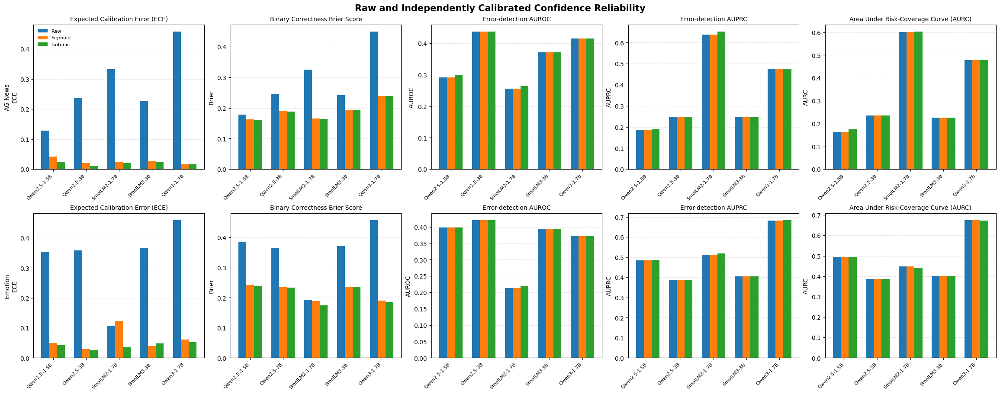


Figure saved successfully: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration_Evaluation/Figure_5_Raw_vs_Calibrated_Reliability.png


In [22]:

# ------------------------------------------------------------
# 6. PREPARE PUBLICATION-QUALITY FIGURE (CORRECTED)
# ------------------------------------------------------------

# Inspect actual dataset labels
print("Dataset labels in metrics:")
print(metrics_df["Dataset"].unique())

# Normalize dataset names to handle AG_News / AG News variations
def normalize_dataset(value):
    value = str(value).lower().replace("_", "").replace("-", "").replace(" ", "")

    if "agnews" in value:
        return "AG News"
    elif "emotion" in value:
        return "Emotion"
    return value

metrics_df["Dataset_Normalized"] = (
    metrics_df["Dataset"].apply(normalize_dataset)
)

models = list(df[model_col].drop_duplicates())

datasets = ["AG News", "Emotion"]

metric_names = [
    ("ECE", "Expected Calibration Error (ECE)"),
    ("Brier", "Binary Correctness Brier Score"),
    ("AUROC", "Error-detection AUROC"),
    ("AUPRC", "Error-detection AUPRC"),
    ("AURC", "Area Under Risk-Coverage Curve (AURC)")
]

methods = ["Raw", "Sigmoid", "Isotonic"]

# Verify all expected combinations exist
print("\nCombination counts:")
print(
    metrics_df.groupby(
        ["Dataset_Normalized", "Method"]
    ).size()
)

fig, axes = plt.subplots(
    2, 5,
    figsize=(23, 9),
    constrained_layout=True
)

x = np.arange(len(models))
width = 0.24

for row, dataset in enumerate(datasets):

    subset = metrics_df[
        metrics_df["Dataset_Normalized"] == dataset
    ]

    if subset.empty:
        raise ValueError(
            f"No results found for dataset: {dataset}"
        )

    for col, (metric, title) in enumerate(metric_names):

        ax = axes[row, col]

        for i, method in enumerate(methods):

            values = []

            for model in models:

                selected = subset[
                    (subset["Model"] == model) &
                    (subset["Method"] == method)
                ][metric]

                if len(selected) != 1:
                    raise ValueError(
                        f"Expected one value for "
                        f"{model}, {dataset}, {method}, {metric}; "
                        f"found {len(selected)}"
                    )

                values.append(selected.iloc[0])

            offset = (i - 1) * width

            ax.bar(
                x + offset,
                values,
                width,
                label=method
            )

        ax.set_title(title, fontsize=10)
        ax.set_xticks(x)

        ax.set_xticklabels(
            [m.replace("-Instruct", "") for m in models],
            rotation=45,
            ha="right",
            fontsize=8
        )

        ax.set_ylabel(metric)
        ax.grid(axis="y", linestyle="--", alpha=0.35)
        ax.set_axisbelow(True)

        if metric in ["ECE", "Brier", "AURC"]:
            ax.set_ylim(bottom=0)

        if row == 0 and col == 0:
            ax.legend(fontsize=8, frameon=False)

    axes[row, 0].set_ylabel(
        f"{dataset}\nECE",
        fontsize=10
    )

fig.suptitle(
    "Raw and Independently Calibrated Confidence Reliability",
    fontsize=15,
    fontweight="bold"
)

# Save
OUTPUT_FILE = os.path.join(
    BASE_DIR,
    "Figure_5_Raw_vs_Calibrated_Reliability.png"
)

plt.savefig(
    OUTPUT_FILE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("\nFigure saved successfully:", OUTPUT_FILE)


Dataset shape: (10000, 10)

Available columns:
['model', 'dataset', 'text', 'true_label', 'prediction', 'valid_prediction', 'correct', 'raw_confidence', 'sigmoid_confidence', 'isotonic_confidence']

Identified columns:
Model: model
Dataset: dataset
Correctness: correct
Raw: raw_confidence
Sigmoid: sigmoid_confidence
Isotonic: isotonic_confidence


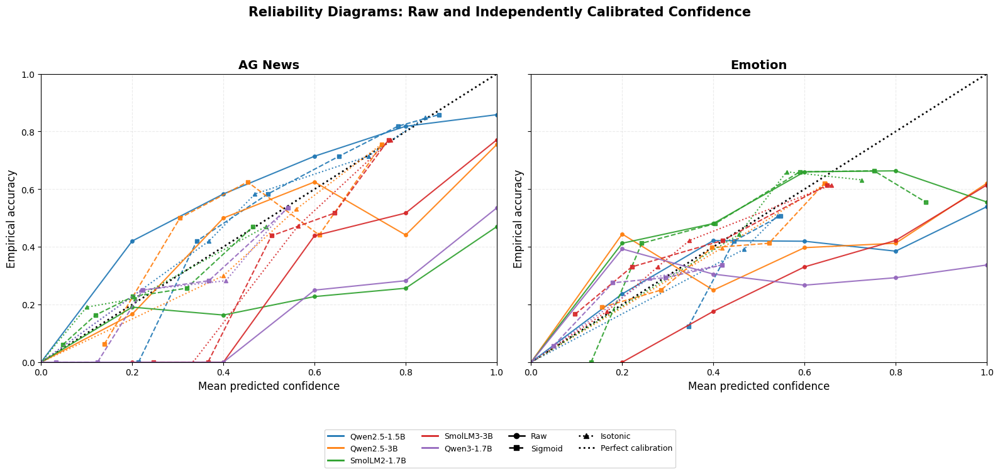


Figure generated successfully.
Saved at: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration_Evaluation/Figure_5_Independent_Calibration_Reliability.png


In [23]:

# ============================================================
# FIGURE 5: RELIABILITY DIAGRAMS
# Raw vs Independent Sigmoid vs Independent Isotonic
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

BASE_DIR = (
    "/content/drive/MyDrive/LLM_Reliability_Experiments/"
    "Independent_Calibration_Evaluation"
)

INPUT_FILE = os.path.join(
    BASE_DIR,
    "independent_calibrated_test_predictions.csv"
)

OUTPUT_FILE = os.path.join(
    BASE_DIR,
    "Figure_5_Independent_Calibration_Reliability.png"
)

# ------------------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------------------

df = pd.read_csv(INPUT_FILE)

print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

# ------------------------------------------------------------
# 3. IDENTIFY COLUMNS
# ------------------------------------------------------------

def find_column(possible_names, columns):
    for name in possible_names:
        if name in columns:
            return name

    raise ValueError(
        f"Column not found. Tried: {possible_names}"
    )

model_col = find_column(
    ["model", "Model"],
    df.columns
)

dataset_col = find_column(
    ["dataset", "Dataset"],
    df.columns
)

correct_col = find_column(
    [
        "correct",
        "is_correct",
        "binary_correctness",
        "Correct",
        "is_correct_prediction"
    ],
    df.columns
)

raw_col = find_column(
    [
        "raw_confidence",
        "raw_agreement",
        "agreement_score",
        "Raw_Confidence"
    ],
    df.columns
)

sigmoid_col = find_column(
    [
        "sigmoid_confidence",
        "sigmoid_calibrated",
        "calibrated_sigmoid",
        "Sigmoid_Confidence"
    ],
    df.columns
)

isotonic_col = find_column(
    [
        "isotonic_confidence",
        "isotonic_calibrated",
        "calibrated_isotonic",
        "Isotonic_Confidence"
    ],
    df.columns
)

print("\nIdentified columns:")
print("Model:", model_col)
print("Dataset:", dataset_col)
print("Correctness:", correct_col)
print("Raw:", raw_col)
print("Sigmoid:", sigmoid_col)
print("Isotonic:", isotonic_col)

# ------------------------------------------------------------
# 4. NORMALIZE DATASET NAMES
# ------------------------------------------------------------

def normalize_dataset(value):

    value = (
        str(value)
        .lower()
        .replace("_", "")
        .replace("-", "")
        .replace(" ", "")
    )

    if "agnews" in value:
        return "AG News"

    if "emotion" in value:
        return "Emotion"

    return value


df["Dataset_Normalized"] = (
    df[dataset_col].apply(normalize_dataset)
)

# ------------------------------------------------------------
# 5. RELIABILITY DIAGRAM FUNCTION
# ------------------------------------------------------------

def reliability_curve(y_true, confidence, n_bins=10):

    y_true = np.asarray(y_true, dtype=float)
    confidence = np.asarray(confidence, dtype=float)

    bin_edges = np.linspace(0, 1, n_bins + 1)

    mean_confidence = []
    empirical_accuracy = []

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence <= bin_edges[i + 1])
            )
        else:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence < bin_edges[i + 1])
            )

        if np.sum(mask) > 0:

            mean_confidence.append(
                np.mean(confidence[mask])
            )

            empirical_accuracy.append(
                np.mean(y_true[mask])
            )

    return (
        np.asarray(mean_confidence),
        np.asarray(empirical_accuracy)
    )


# ------------------------------------------------------------
# 6. MODEL AND METHOD CONFIGURATION
# ------------------------------------------------------------

models = list(df[model_col].drop_duplicates())

datasets = ["AG News", "Emotion"]

confidence_methods = {
    "Raw": raw_col,
    "Sigmoid": sigmoid_col,
    "Isotonic": isotonic_col
}

# Model colours are assigned automatically by Matplotlib.
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

model_colors = {
    model: colors[i % len(colors)]
    for i, model in enumerate(models)
}

line_styles = {
    "Raw": "-",
    "Sigmoid": "--",
    "Isotonic": ":"
}

markers = {
    "Raw": "o",
    "Sigmoid": "s",
    "Isotonic": "^"
}

# ------------------------------------------------------------
# 7. CREATE TWO-PANEL RELIABILITY DIAGRAM
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7),
    sharex=True,
    sharey=True
)

for ax, dataset in zip(axes, datasets):

    subset = df[
        df["Dataset_Normalized"] == dataset
    ]

    if subset.empty:
        raise ValueError(
            f"No data found for {dataset}"
        )

    # Perfect calibration reference
    ax.plot(
        [0, 1],
        [0, 1],
        color="black",
        linestyle=":",
        linewidth=2,
        label="Perfect calibration",
        zorder=1
    )

    for model in models:

        model_data = subset[
            subset[model_col] == model
        ].copy()

        if model_data.empty:
            raise ValueError(
                f"Missing model {model} in {dataset}"
            )

        y_true = pd.to_numeric(
            model_data[correct_col],
            errors="coerce"
        ).to_numpy()

        for method, confidence_col in confidence_methods.items():

            confidence = pd.to_numeric(
                model_data[confidence_col],
                errors="coerce"
            ).to_numpy()

            valid = (
                np.isfinite(y_true) &
                np.isfinite(confidence)
            )

            y = y_true[valid]
            c = confidence[valid]

            if len(y) == 0:
                continue

            if not np.all(np.isin(y, [0, 1])):
                raise ValueError(
                    f"Correctness must be binary for {model}, {dataset}"
                )

            if np.any((c < 0) | (c > 1)):
                raise ValueError(
                    f"Confidence outside [0,1] for {model}, {method}"
                )

            mean_conf, empirical_acc = reliability_curve(
                y,
                c,
                n_bins=10
            )

            model_label = (
                model
                .replace("-Instruct", "")
            )

            ax.plot(
                mean_conf,
                empirical_acc,
                color=model_colors[model],
                linestyle=line_styles[method],
                marker=markers[method],
                markersize=4,
                linewidth=1.5,
                alpha=0.9,
                label=f"{model_label} — {method}",
                zorder=2
            )

    ax.set_title(
        dataset,
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Mean predicted confidence",
        fontsize=12
    )

    ax.set_ylabel(
        "Empirical accuracy",
        fontsize=12
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    ax.set_xticks(np.linspace(0, 1, 6))
    ax.set_yticks(np.linspace(0, 1, 6))

    ax.grid(
        True,
        linestyle="--",
        alpha=0.25
    )

# ------------------------------------------------------------
# 8. LEGEND
# ------------------------------------------------------------

# Model legend: colours
model_handles = [
    Line2D(
        [0], [0],
        color=model_colors[model],
        linewidth=2,
        label=model.replace("-Instruct", "")
    )
    for model in models
]

# Method legend: line styles
method_handles = [
    Line2D(
        [0], [0],
        color="black",
        linestyle=line_styles[method],
        marker=markers[method],
        linewidth=1.8,
        label=method
    )
    for method in confidence_methods
]

perfect_handle = Line2D(
    [0], [0],
    color="black",
    linestyle=":",
    linewidth=2,
    label="Perfect calibration"
)

fig.legend(
    handles=model_handles + method_handles + [perfect_handle],
    loc="lower center",
    ncol=4,
    fontsize=9,
    frameon=True,
    bbox_to_anchor=(0.5, -0.04)
)

fig.suptitle(
    "Reliability Diagrams: Raw and Independently Calibrated Confidence",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

plt.tight_layout(rect=[0, 0.12, 1, 0.97])

# ------------------------------------------------------------
# 9. SAVE HIGH-RESOLUTION FIGURE
# ------------------------------------------------------------

plt.savefig(
    OUTPUT_FILE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("\nFigure generated successfully.")
print("Saved at:", OUTPUT_FILE)


Loaded: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration_Evaluation/independent_calibrated_test_predictions.csv
Shape: (10000, 10)

Columns:
['model', 'dataset', 'text', 'true_label', 'prediction', 'valid_prediction', 'correct', 'raw_confidence', 'sigmoid_confidence', 'isotonic_confidence']

Identified columns successfully.


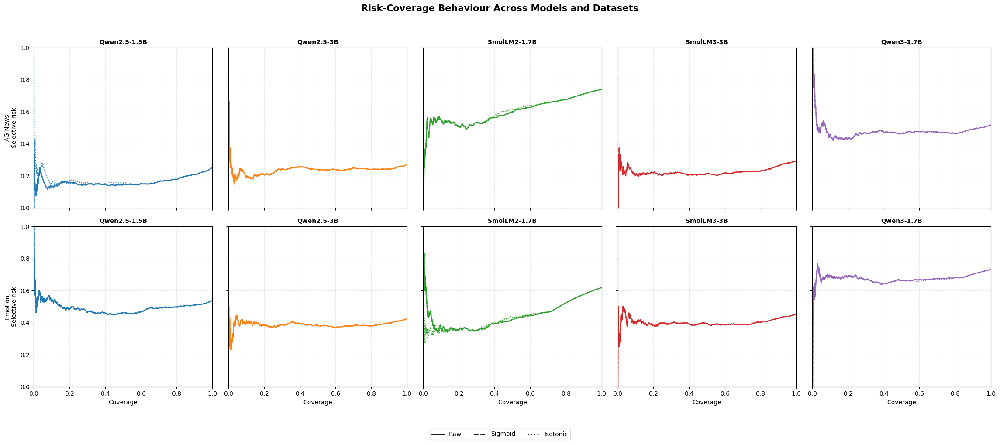


Figure 6 saved: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration_Evaluation/Figure_6_Risk_Coverage.png


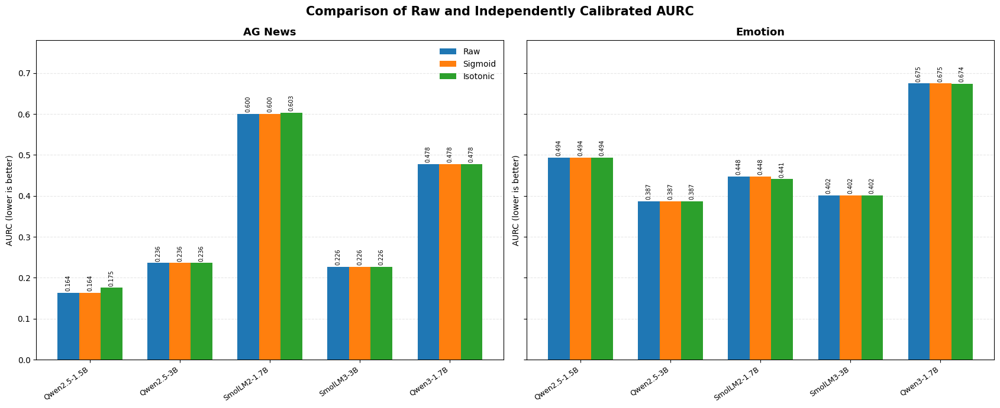


Figure 7 saved: /content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration_Evaluation/Figure_7_AURC_Comparison.png

FIGURES GENERATED SUCCESSFULLY

Figure 6:
/content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration_Evaluation/Figure_6_Risk_Coverage.png

Figure 7:
/content/drive/MyDrive/LLM_Reliability_Experiments/Independent_Calibration_Evaluation/Figure_7_AURC_Comparison.png

AURC data:


,Model,Dataset,Raw,Sigmoid,Isotonic
0,Qwen2.5-1.5B-Instruct,AG News,0.1637,0.1637,0.1755
1,Qwen2.5-1.5B-Instruct,Emotion,0.4940,0.4940,0.4939
2,Qwen2.5-3B-Instruct,AG News,0.2361,0.2361,0.2361
3,Qwen2.5-3B-Instruct,Emotion,0.3866,0.3866,0.3865
4,SmolLM2-1.7B-Instruct,AG News,0.6002,0.6002,0.6031
5,SmolLM2-1.7B-Instruct,Emotion,0.4479,0.4479,0.4410
6,SmolLM3-3B,AG News,0.2264,0.2264,0.2264
7,SmolLM3-3B,Emotion,0.4018,0.4018,0.4018
8,Qwen3-1.7B,AG News,0.4778,0.4778,0.4778
9,Qwen3-1.7B,Emotion,0.6747,0.6747,0.6736


In [24]:

# ============================================================
# FIGURE 6: RISK-COVERAGE CURVES
# FIGURE 7: AURC COMPARISON
# Final independent post-hoc calibration experiment
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

BASE_DIR = (
    "/content/drive/MyDrive/LLM_Reliability_Experiments/"
    "Independent_Calibration_Evaluation"
)

INPUT_FILE = os.path.join(
    BASE_DIR,
    "independent_calibrated_test_predictions.csv"
)

FIG6_FILE = os.path.join(
    BASE_DIR,
    "Figure_6_Risk_Coverage.png"
)

FIG7_FILE = os.path.join(
    BASE_DIR,
    "Figure_7_AURC_Comparison.png"
)

# ------------------------------------------------------------
# 2. LOAD FINAL TEST PREDICTIONS
# ------------------------------------------------------------

df = pd.read_csv(INPUT_FILE)

print("Loaded:", INPUT_FILE)
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# ------------------------------------------------------------
# 3. IDENTIFY REQUIRED COLUMNS
# ------------------------------------------------------------

def find_column(possible_names, columns):

    for name in possible_names:
        if name in columns:
            return name

    raise ValueError(
        f"Column not found. Tried: {possible_names}"
    )


model_col = find_column(
    ["model", "Model"],
    df.columns
)

dataset_col = find_column(
    ["dataset", "Dataset"],
    df.columns
)

correct_col = find_column(
    [
        "correct",
        "is_correct",
        "binary_correctness",
        "Correct",
        "is_correct_prediction"
    ],
    df.columns
)

raw_col = find_column(
    [
        "raw_confidence",
        "raw_agreement",
        "agreement_score",
        "Raw_Confidence"
    ],
    df.columns
)

sigmoid_col = find_column(
    [
        "sigmoid_confidence",
        "sigmoid_calibrated",
        "calibrated_sigmoid",
        "Sigmoid_Confidence"
    ],
    df.columns
)

isotonic_col = find_column(
    [
        "isotonic_confidence",
        "isotonic_calibrated",
        "calibrated_isotonic",
        "Isotonic_Confidence"
    ],
    df.columns
)

print("\nIdentified columns successfully.")

# ------------------------------------------------------------
# 4. NORMALIZE DATASET NAMES
# ------------------------------------------------------------

def normalize_dataset(value):

    value = (
        str(value)
        .lower()
        .replace("_", "")
        .replace("-", "")
        .replace(" ", "")
    )

    if "agnews" in value:
        return "AG News"

    if "emotion" in value:
        return "Emotion"

    return value


df["Dataset_Normalized"] = (
    df[dataset_col].apply(normalize_dataset)
)

# ------------------------------------------------------------
# 5. MODEL ORDER AND CONFIDENCE METHODS
# ------------------------------------------------------------

models = [
    "Qwen2.5-1.5B-Instruct",
    "Qwen2.5-3B-Instruct",
    "SmolLM2-1.7B-Instruct",
    "SmolLM3-3B",
    "Qwen3-1.7B"
]

# Resolve model-name variations in the CSV
def normalize_model(value):

    return (
        str(value)
        .lower()
        .replace("-instruct", "")
        .replace("_", "")
        .replace("-", "")
        .replace(" ", "")
    )


available_models = {
    normalize_model(m): m
    for m in df[model_col].unique()
}

resolved_models = {}

for expected in models:

    key = normalize_model(expected)

    if key not in available_models:
        raise ValueError(
            f"Model not found in CSV: {expected}\n"
            f"Available models: {list(df[model_col].unique())}"
        )

    resolved_models[expected] = available_models[key]


confidence_methods = {
    "Raw": raw_col,
    "Sigmoid": sigmoid_col,
    "Isotonic": isotonic_col
}

datasets = ["AG News", "Emotion"]

# ------------------------------------------------------------
# 6. PREPARE RISK-COVERAGE FUNCTION
# ------------------------------------------------------------

def calculate_risk_coverage(y_true, confidence):

    y_true = np.asarray(y_true, dtype=int)
    confidence = np.asarray(confidence, dtype=float)

    # Highest confidence predictions are accepted first.
    order = np.argsort(
        -confidence,
        kind="mergesort"
    )

    sorted_correctness = y_true[order]

    errors = 1 - sorted_correctness

    cumulative_errors = np.cumsum(errors)

    n = len(y_true)

    coverage = (
        np.arange(1, n + 1) / n
    )

    risk = (
        cumulative_errors /
        np.arange(1, n + 1)
    )

    return coverage, risk


# ------------------------------------------------------------
# 7. FIGURE 6: RISK-COVERAGE CURVES
# ------------------------------------------------------------

# Colours distinguish models.
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

model_colors = {
    model: colors[i % len(colors)]
    for i, model in enumerate(models)
}

# Line styles distinguish confidence methods.
line_styles = {
    "Raw": "-",
    "Sigmoid": "--",
    "Isotonic": ":"
}

markers = {
    "Raw": "o",
    "Sigmoid": "s",
    "Isotonic": "^"
}

fig, axes = plt.subplots(
    2, 5,
    figsize=(23, 10),
    sharex=True,
    sharey=True
)

for row, dataset in enumerate(datasets):

    dataset_data = df[
        df["Dataset_Normalized"] == dataset
    ]

    if dataset_data.empty:
        raise ValueError(
            f"No predictions found for {dataset}"
        )

    for col, expected_model in enumerate(models):

        model_name = resolved_models[expected_model]

        group = dataset_data[
            dataset_data[model_col] == model_name
        ].copy()

        if len(group) != 1000:
            raise ValueError(
                f"Expected 1000 test predictions for "
                f"{model_name}, {dataset}; found {len(group)}"
            )

        ax = axes[row, col]

        y_true = pd.to_numeric(
            group[correct_col],
            errors="coerce"
        ).to_numpy()

        for method, confidence_col in confidence_methods.items():

            confidence = pd.to_numeric(
                group[confidence_col],
                errors="coerce"
            ).to_numpy()

            mask = (
                np.isfinite(y_true) &
                np.isfinite(confidence)
            )

            y = y_true[mask].astype(int)
            c = confidence[mask]

            if len(y) != 1000:
                raise ValueError(
                    f"Missing or invalid values for "
                    f"{model_name}, {dataset}, {method}"
                )

            if not np.all(np.isin(y, [0, 1])):
                raise ValueError(
                    "Correctness column must contain only 0 and 1."
                )

            coverage, risk = calculate_risk_coverage(
                y, c
            )

            ax.plot(
                coverage,
                risk,
                color=model_colors[expected_model],
                linestyle=line_styles[method],
                linewidth=1.7,
                label=method,
                alpha=0.9
            )

        ax.set_title(
            expected_model.replace("-Instruct", ""),
            fontsize=10,
            fontweight="bold"
        )

        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)

        ax.set_xticks(
            np.linspace(0, 1, 6)
        )

        ax.set_yticks(
            np.linspace(0, 1, 6)
        )

        ax.grid(
            linestyle="--",
            alpha=0.3
        )

        if col == 0:
            ax.set_ylabel(
                f"{dataset}\nSelective risk",
                fontsize=10
            )

        if row == 1:
            ax.set_xlabel(
                "Coverage",
                fontsize=10
            )

# Legend for methods
method_handles = [
    Line2D(
        [0], [0],
        color="black",
        linestyle=line_styles[method],
        linewidth=2,
        label=method
    )
    for method in confidence_methods
]

fig.legend(
    handles=method_handles,
    loc="lower center",
    ncol=3,
    frameon=True,
    fontsize=10,
    bbox_to_anchor=(0.5, -0.025)
)

fig.suptitle(
    "Risk-Coverage Behaviour Across Models and Datasets",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0.045, 1, 0.95]
)

plt.savefig(
    FIG6_FILE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("\nFigure 6 saved:", FIG6_FILE)


# ------------------------------------------------------------
# 8. FIGURE 7: FINAL AURC VALUES
# ------------------------------------------------------------

# Values copied from the final independent calibration results.
# These are not the old OOF calibration values.

aurc_data = [

    ["Qwen2.5-1.5B-Instruct", "AG News",
     0.1637, 0.1637, 0.1755],

    ["Qwen2.5-1.5B-Instruct", "Emotion",
     0.4940, 0.4940, 0.4939],

    ["Qwen2.5-3B-Instruct", "AG News",
     0.2361, 0.2361, 0.2361],

    ["Qwen2.5-3B-Instruct", "Emotion",
     0.3866, 0.3866, 0.3865],

    ["SmolLM2-1.7B-Instruct", "AG News",
     0.6002, 0.6002, 0.6031],

    ["SmolLM2-1.7B-Instruct", "Emotion",
     0.4479, 0.4479, 0.4410],

    ["SmolLM3-3B", "AG News",
     0.2264, 0.2264, 0.2264],

    ["SmolLM3-3B", "Emotion",
     0.4018, 0.4018, 0.4018],

    ["Qwen3-1.7B", "AG News",
     0.4778, 0.4778, 0.4778],

    ["Qwen3-1.7B", "Emotion",
     0.6747, 0.6747, 0.6736]
]

aurc_df = pd.DataFrame(
    aurc_data,
    columns=[
        "Model",
        "Dataset",
        "Raw",
        "Sigmoid",
        "Isotonic"
    ]
)

# Save underlying AURC data
aurc_df.to_csv(
    os.path.join(
        BASE_DIR,
        "Figure_7_Final_AURC_Data.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 9. PLOT FIGURE 7
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 7),
    sharey=True
)

methods = ["Raw", "Sigmoid", "Isotonic"]

x = np.arange(len(models))
width = 0.24

for ax, dataset in zip(axes, datasets):

    subset = aurc_df[
        aurc_df["Dataset"] == dataset
    ]

    for i, method in enumerate(methods):

        values = []

        for model in models:

            selected = subset[
                subset["Model"] == model
            ][method]

            if len(selected) != 1:
                raise ValueError(
                    f"Missing AURC for {model}, {dataset}, {method}"
                )

            values.append(selected.iloc[0])

        offset = (i - 1) * width

        bars = ax.bar(
            x + offset,
            values,
            width,
            label=method
        )

        ax.bar_label(
            bars,
            fmt="%.3f",
            fontsize=7,
            padding=2,
            rotation=90
        )

    ax.set_title(
        dataset,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        [m.replace("-Instruct", "") for m in models],
        rotation=35,
        ha="right",
        fontsize=9
    )

    ax.set_ylabel("AURC (lower is better)")
    ax.set_ylim(0, 0.78)

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

    ax.set_axisbelow(True)

axes[0].legend(
    frameon=False,
    fontsize=10
)

fig.suptitle(
    "Comparison of Raw and Independently Calibrated AURC",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    FIG7_FILE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("\nFigure 7 saved:", FIG7_FILE)


# ------------------------------------------------------------
# 10. FINAL OUTPUT SUMMARY
# ------------------------------------------------------------

print("\n==========================================")
print("FIGURES GENERATED SUCCESSFULLY")
print("==========================================")

print("\nFigure 6:")
print(FIG6_FILE)

print("\nFigure 7:")
print(FIG7_FILE)

print("\nAURC data:")
display(aurc_df.round(4))
